# Codigo base

In [25]:
source("utils.r")
source("erpt_lp.R")

# Cargar datos

In [2]:
# Example of how to call the function
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Data%20trimestral%201950%20a%202023%20PRUEBA.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))

# Read the `data` from the Excel file
df_trimestral_crudo <- read_excel(temp_file)

Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Data%20trimestral%201950%20a%202023%20PRUEBA.xlsx]
  Date: 2026-10-30 21:59
  Status: 200
  Content-Type: application/octet-stream
  Size: 56 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//RtmpS4M1sT/file30b7d74a30e.xlsxNULL

In [3]:
# Select specific columns and rows from df_trimestral_crudo
df_Arg <- df_trimestral_crudo |> 
  dplyr::select(año, trimestre, ipc_ajust, E, Ebc, pbird, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA, TOTfmi) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)

# Rename "ipc_ajust" to "ipc"
df_Arg <- renameColumnOfDataframe(df_Arg, "ipc_ajust", "ipc")

# Display first 6 rows
print(head(df_Arg))

# Display first 65 rows
print(head(df_Arg, 65))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA
    año trimestre          ipc            E          Ebc  pbird impp_usa
1  1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2  1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.234

In [4]:
# Copy df_Arg to df_ERPT_Arg1
df_ERPT_Arg1 <- df_Arg

# Display first rows
print(head(df_ERPT_Arg1))

# Apply logarithm to specific columns
df_ERPT_Arg1 <- makeLogColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg1) # nolint: line_length_linter.

# Display transformed dataframe
print(head(df_ERPT_Arg1))
print(tail(df_ERPT_Arg1))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA


   año trimestre       ipc         E       Ebc    pbird impp_usa Psoja_USA
1 1950      1ºTr -26.48263 -27.73416 -27.73416 11.86097 2.394203 0.7701082
2 1950      2ºTr -26.41158 -27.73416 -27.73416 11.84453 2.419022 0.9795785
3 1950      3ºTr -26.36304 -27.55190 -27.55190 11.88220 2.501014 0.9308509
4 1950      4ºTr -26.29440 -27.29227 -27.29227 11.86923 2.585029 0.8851440
5 1951      1ºTr -26.27159 -27.29086 -27.29086 11.89636 2.671094 1.1074619
6 1951      2ºTr -26.11374 -27.28600 -27.28600 11.90844 2.730547 1.1238468
  Pmaíz_USA Ptrigo_USA TOTfmi
1 0.1541507  0.6644047     NA
2 0.2776317  0.7227060     NA
3 0.3646431  0.6763401     NA
4 0.3340884  0.6695373     NA
5 0.4574248  0.7608058     NA
6 0.4865329  0.7466879     NA
     año trimestre       ipc        E      Ebc    pbird impp_usa Psoja_USA
291 2022      3ºTr  9.225483 4.910408 4.935085 13.50334 4.737288  2.708050
292 2022      4ºTr  9.397475 5.090292 5.118549 13.48080 4.718687  2.636674
293 2023      1ºTr  9.573548 5.259031 5.

In [5]:
# Create df_ERPT_Arg as a copy of df_Arg
df_ERPT_Arg <- df_Arg

# Display first rows
print(head(df_ERPT_Arg))

# Apply logarithm transformation
df_ERPT_Arg <- makeLogColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg)

# Display transformed dataframe
print(head(df_ERPT_Arg))

# Apply differencing transformation
df_ERPT_Arg <- makeDiffColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg)

# Display first and last rows
print(head(df_ERPT_Arg))
print(tail(df_ERPT_Arg, 90))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA
   año trimestre       ipc         E       Ebc    pbird impp_usa Psoja_USA
1 1950      1ºTr -26.48263 -27.73416 -27.73416 11.86097 2.394203 0.7701082
2 1950      2ºTr -26.41158 -27.73416 -27.73416 11.84453 2.419022 0

# Recorto el dataframe para 1950 a 1974

In [30]:
df_ERPT_Arg_1950_74 <- df_ERPT_Arg[1:99, ]
rownames(df_ERPT_Arg_1950_74) <- NULL
print(df_ERPT_Arg_1950_74)
tail(df_ERPT_Arg_1950_74)

    año trimestre           ipc             E           Ebc         pbird
1  1950      2ºTr  0.0710476068  0.000000e+00  0.000000e+00 -0.0164445777
2  1950      3ºTr  0.0485426448  1.822569e-01  1.822569e-01  0.0376749288
3  1950      4ºTr  0.0686389229  2.596392e-01  2.596392e-01 -0.0129753136
4  1951      1ºTr  0.0228032118  1.405321e-03  1.405321e-03  0.0271279177
5  1951      2ºTr  0.1578569708  4.855918e-03  4.855918e-03  0.0120849848
6  1951      3ºTr  0.1057701537  6.299697e-03  6.299697e-03 -0.0062139270
7  1951      4ºTr  0.0767790005  1.347034e-02  1.347034e-02 -0.0043864484
8  1952      1ºTr  0.1087066196 -1.618821e-02 -1.618821e-02  0.0024196794
9  1952      2ºTr  0.0994670088 -1.171674e-02 -1.171674e-02 -0.0324056598
10 1952      3ºTr -0.0146396976 -2.180054e-03 -2.180054e-03 -0.0513198674
11 1952      4ºTr  0.0335589046 -1.192593e-05 -1.192593e-05  0.0088992684
12 1953      1ºTr  0.0266918756 -4.770412e-06 -4.770412e-06  0.0265101685
13 1953      2ºTr -0.0389677282  0.000

,año,trimestre,ipc,E,Ebc,pbird,impp_usa,Psoja_USA,Pmaíz_USA,Ptrigo_USA,TOTfmi
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
94,1973,3ºTr,-0.001657274,0,0,0.0139439972,0.03614851,-0.12740517,0.31227751,0.5392441,NA
95,1973,4ºTr,0.053587451,0,0,0.0370107383,0.08612341,-0.26908761,-0.01764752,0.1343976,NA
96,1974,1ºTr,0.009420312,0,0,0.0147827587,0.14855104,0.08630061,0.17512460,0.1778926,NA
97,1974,2ºTr,0.075753666,0,0,0.0081844708,0.13136480,-0.14460606,-0.07765867,-0.3538707,NA
98,1974,3ºTr,0.081590922,0,0,0.0008571713,0.06551261,0.30337495,0.25415173,0.1294581,NA
99,1974,4ºTr,0.133766571,0,0,0.0112117424,0.03400403,0.07614865,0.04689952,0.1314459,NA


# Recorto el dataframe para 1950 a 1975 

In [31]:
df_ERPT_Arg_1950_75 <- df_ERPT_Arg[1:103, ]
rownames(df_ERPT_Arg_1950_75) <- NULL
print(df_ERPT_Arg_1950_75)
tail(df_ERPT_Arg_1950_75)

     año trimestre           ipc             E           Ebc         pbird
1   1950      2ºTr  0.0710476068  0.000000e+00  0.000000e+00 -0.0164445777
2   1950      3ºTr  0.0485426448  1.822569e-01  1.822569e-01  0.0376749288
3   1950      4ºTr  0.0686389229  2.596392e-01  2.596392e-01 -0.0129753136
4   1951      1ºTr  0.0228032118  1.405321e-03  1.405321e-03  0.0271279177
5   1951      2ºTr  0.1578569708  4.855918e-03  4.855918e-03  0.0120849848
6   1951      3ºTr  0.1057701537  6.299697e-03  6.299697e-03 -0.0062139270
7   1951      4ºTr  0.0767790005  1.347034e-02  1.347034e-02 -0.0043864484
8   1952      1ºTr  0.1087066196 -1.618821e-02 -1.618821e-02  0.0024196794
9   1952      2ºTr  0.0994670088 -1.171674e-02 -1.171674e-02 -0.0324056598
10  1952      3ºTr -0.0146396976 -2.180054e-03 -2.180054e-03 -0.0513198674
11  1952      4ºTr  0.0335589046 -1.192593e-05 -1.192593e-05  0.0088992684
12  1953      1ºTr  0.0266918756 -4.770412e-06 -4.770412e-06  0.0265101685
13  1953      2ºTr -0.038

,año,trimestre,ipc,E,Ebc,pbird,impp_usa,Psoja_USA,Pmaíz_USA,Ptrigo_USA,TOTfmi
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
98,1974,3ºTr,0.08159092,0.0000000,0.0000000,0.0008571713,0.0655126054,0.30337495,0.25415173,0.12945807,NA
99,1974,4ºTr,0.13376657,0.0000000,0.0000000,0.0112117424,0.0340040317,0.07614865,0.04689952,0.13144589,NA
100,1975,1ºTr,0.17652291,0.8501509,0.1578655,-0.0043070843,0.0085075416,-0.26727915,-0.15481491,-0.20469952,NA
101,1975,2ºTr,0.25282326,0.5039645,0.5421054,-0.0024821955,0.0102602586,-0.11159908,-0.06982378,-0.14988991,NA
102,1975,3ºTr,0.61078946,0.7741162,1.0090191,-0.0342827927,-0.0352475739,0.05644131,0.04985835,0.11690081,NA
103,1975,4ºTr,0.37973156,0.5559811,0.3338426,0.0094609638,0.0007550019,-0.18354181,-0.14118644,-0.02865012,NA


# Recorto el dataframe para 1950 a 1982

In [32]:
df_ERPT_Arg_1950_82 <- df_ERPT_Arg[1:131, ]
rownames(df_ERPT_Arg_1950_82) <- NULL
print(df_ERPT_Arg_1950_82)
tail(df_ERPT_Arg_1950_82)

     año trimestre           ipc             E           Ebc         pbird
1   1950      2ºTr  0.0710476068  0.000000e+00  0.000000e+00 -0.0164445777
2   1950      3ºTr  0.0485426448  1.822569e-01  1.822569e-01  0.0376749288
3   1950      4ºTr  0.0686389229  2.596392e-01  2.596392e-01 -0.0129753136
4   1951      1ºTr  0.0228032118  1.405321e-03  1.405321e-03  0.0271279177
5   1951      2ºTr  0.1578569708  4.855918e-03  4.855918e-03  0.0120849848
6   1951      3ºTr  0.1057701537  6.299697e-03  6.299697e-03 -0.0062139270
7   1951      4ºTr  0.0767790005  1.347034e-02  1.347034e-02 -0.0043864484
8   1952      1ºTr  0.1087066196 -1.618821e-02 -1.618821e-02  0.0024196794
9   1952      2ºTr  0.0994670088 -1.171674e-02 -1.171674e-02 -0.0324056598
10  1952      3ºTr -0.0146396976 -2.180054e-03 -2.180054e-03 -0.0513198674
11  1952      4ºTr  0.0335589046 -1.192593e-05 -1.192593e-05  0.0088992684
12  1953      1ºTr  0.0266918756 -4.770412e-06 -4.770412e-06  0.0265101685
13  1953      2ºTr -0.038

,año,trimestre,ipc,E,Ebc,pbird,impp_usa,Psoja_USA,Pmaíz_USA,Ptrigo_USA,TOTfmi
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
126,1981,3ºTr,0.2548608,0.3114022,0.54239209,-0.028854664,-0.032591430,-0.095083448,-0.11985773,-0.07345185,-1.365262e-03
127,1981,4ºTr,0.2027679,0.2389421,0.30613258,-0.009826889,-0.009167063,-0.102317215,-0.17580081,0.04752127,-1.468592e-03
128,1982,1ºTr,0.2405847,0.4536499,0.04101902,0.006203761,0.026278308,0.003309435,0.03557147,-0.02392671,-4.090018e-05
129,1982,2ºTr,0.1345506,0.2866512,0.28886341,-0.036314742,-0.019693429,0.021787354,0.03694352,-0.04026161,-2.544929e-04
130,1982,3ºTr,0.3615117,1.0151611,1.01620551,0.034227434,-0.012407604,-0.099629841,-0.10507270,-0.07059479,-1.569294e-03
131,1982,4ºTr,0.3718439,0.1080244,0.11279435,0.014447654,-0.004237722,-0.057578670,-0.08714219,0.04314395,-3.568544e-04


# Recorto el dataframe para 1950 a 1987

In [33]:
df_ERPT_Arg_1950_87 <- df_ERPT_Arg[1:151, ]
rownames(df_ERPT_Arg_1950_87) <- NULL
print(df_ERPT_Arg_1950_87)
tail(df_ERPT_Arg_1950_87)

     año trimestre           ipc             E           Ebc         pbird
1   1950      2ºTr  0.0710476068  0.000000e+00  0.000000e+00 -0.0164445777
2   1950      3ºTr  0.0485426448  1.822569e-01  1.822569e-01  0.0376749288
3   1950      4ºTr  0.0686389229  2.596392e-01  2.596392e-01 -0.0129753136
4   1951      1ºTr  0.0228032118  1.405321e-03  1.405321e-03  0.0271279177
5   1951      2ºTr  0.1578569708  4.855918e-03  4.855918e-03  0.0120849848
6   1951      3ºTr  0.1057701537  6.299697e-03  6.299697e-03 -0.0062139270
7   1951      4ºTr  0.0767790005  1.347034e-02  1.347034e-02 -0.0043864484
8   1952      1ºTr  0.1087066196 -1.618821e-02 -1.618821e-02  0.0024196794
9   1952      2ºTr  0.0994670088 -1.171674e-02 -1.171674e-02 -0.0324056598
10  1952      3ºTr -0.0146396976 -2.180054e-03 -2.180054e-03 -0.0513198674
11  1952      4ºTr  0.0335589046 -1.192593e-05 -1.192593e-05  0.0088992684
12  1953      1ºTr  0.0266918756 -4.770412e-06 -4.770412e-06  0.0265101685
13  1953      2ºTr -0.038

,año,trimestre,ipc,E,Ebc,pbird,impp_usa,Psoja_USA,Pmaíz_USA,Ptrigo_USA,TOTfmi
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
146,1986,3ºTr,0.1890600,0.1355088,0.1454634,0.036998468,-0.001969151,-0.04703676,-0.30253264,-0.26496652,-0.0059407903
147,1986,4ºTr,0.1820531,0.1684465,0.1745668,-0.020225948,0.025514898,-0.07570431,-0.17004205,0.06140401,-0.0003826973
148,1987,1ºTr,0.1901747,0.1997793,0.2119356,-0.001668322,0.014833923,0.01858524,0.00000000,0.06176459,0.0010568186
149,1987,2ºTr,0.1589579,0.1362467,0.1176320,0.028033316,0.030044734,0.09066381,0.10833093,0.00778214,0.0030559458
150,1987,3ºTr,0.2873633,0.2874973,0.3266413,0.017243036,0.037263927,-0.01105702,-0.06577131,-0.07232066,-0.0017880756
151,1987,4ºTr,0.3683027,0.4647369,0.6046422,-0.042391926,-0.001377546,0.04726295,0.06782260,0.10660974,0.0017655403


# Recorto el dataframe para 1950 a 1990

In [34]:
df_ERPT_Arg_1950_90 <- df_ERPT_Arg[1:163, ]
rownames(df_ERPT_Arg_1950_90) <- NULL
print(df_ERPT_Arg_1950_90)
tail(df_ERPT_Arg_1950_90)

     año trimestre           ipc             E           Ebc         pbird
1   1950      2ºTr  0.0710476068  0.000000e+00  0.000000e+00 -0.0164445777
2   1950      3ºTr  0.0485426448  1.822569e-01  1.822569e-01  0.0376749288
3   1950      4ºTr  0.0686389229  2.596392e-01  2.596392e-01 -0.0129753136
4   1951      1ºTr  0.0228032118  1.405321e-03  1.405321e-03  0.0271279177
5   1951      2ºTr  0.1578569708  4.855918e-03  4.855918e-03  0.0120849848
6   1951      3ºTr  0.1057701537  6.299697e-03  6.299697e-03 -0.0062139270
7   1951      4ºTr  0.0767790005  1.347034e-02  1.347034e-02 -0.0043864484
8   1952      1ºTr  0.1087066196 -1.618821e-02 -1.618821e-02  0.0024196794
9   1952      2ºTr  0.0994670088 -1.171674e-02 -1.171674e-02 -0.0324056598
10  1952      3ºTr -0.0146396976 -2.180054e-03 -2.180054e-03 -0.0513198674
11  1952      4ºTr  0.0335589046 -1.192593e-05 -1.192593e-05  0.0088992684
12  1953      1ºTr  0.0266918756 -4.770412e-06 -4.770412e-06  0.0265101685
13  1953      2ºTr -0.038

,año,trimestre,ipc,E,Ebc,pbird,impp_usa,Psoja_USA,Pmaíz_USA,Ptrigo_USA,TOTfmi
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
158,1989,3ºTr,1.8980768,1.54704126,1.33714076,-0.04376994,-0.019260889,-0.1467500910,-0.08582528,-0.056218866,-0.0015439259
159,1989,4ºTr,0.3765053,0.39199173,0.45913048,0.04400763,0.009816374,-0.0988109239,-0.04361156,0.001777778,-0.0007960033
160,1990,1ºTr,1.4680302,1.30137219,1.39110592,-0.06175789,0.015233642,0.0005932958,0.03933501,-0.046350868,-0.0013711700
161,1990,2ºTr,0.7370680,0.40306057,0.20147038,0.01557782,-0.014675606,0.0469243338,0.10307219,-0.075325171,0.0010642309
162,1990,3ºTr,0.3771311,0.11902154,0.12148231,0.04535297,0.028054645,0.0162787765,-0.04076830,-0.241618074,-0.0014971125
163,1990,4ºTr,0.2679743,-0.07043893,-0.05812991,0.02503649,0.051279733,-0.0328269430,-0.12570020,-0.081107557,-0.0017221056


# Regresiones

### impp_usa 1950 a 2023 - Todas endógenas - Selected orders: 2 y 3 

Selected orders (en notebook: "selected_orders.ipynb): 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.95

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.44463181,-1.44463181,-1.4446318
2,impp_usa,E,1,-0.18878711,-1.48167209,1.1040979
3,impp_usa,E,2,0.08647177,-1.37811768,1.5510612
4,impp_usa,E,3,-0.99867545,-1.13563512,-0.8617158
5,impp_usa,E,4,0.46436104,-0.85928765,1.7880097
6,impp_usa,E,5,1.00482315,0.02549889,1.9841474
7,impp_usa,E,6,0.30632378,-0.84210814,1.4547557
8,impp_usa,E,7,1.10889270,0.29032155,1.9274639
9,impp_usa,E,8,1.26177293,0.33569460,2.1878513


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.00000000,0.0000000
65,ipc,E,1,-0.17860004,-0.60066548,0.2434654
66,ipc,E,2,0.26151154,-0.05766479,0.5806879
67,ipc,E,3,0.28027745,-0.27862769,0.8391826
68,ipc,E,4,0.40964574,0.02336528,0.7959262
69,ipc,E,5,-0.08143183,-0.37321449,0.2103508
70,ipc,E,6,0.15411543,-0.18131664,0.4895475
71,ipc,E,7,0.10083104,-0.35556223,0.5572243
72,ipc,E,8,-0.03152793,-0.28813018,0.2250743


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.0000000,0.00000000
92,pbird,E,1,-0.9379307,-1.8670979,-0.00876356
93,pbird,E,2,-0.4366440,-1.3218937,0.44860573
94,pbird,E,3,-0.4048328,-1.3226034,0.51293784
95,pbird,E,4,-0.4480363,-1.3687118,0.47263917
96,pbird,E,5,0.5082326,-0.3522054,1.36867065
97,pbird,E,6,-0.5654828,-1.4797734,0.34880790
98,pbird,E,7,-0.5034145,-1.2983904,0.29156135
99,pbird,E,8,0.1862058,-0.7958519,1.16826348


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.0000000
101,pbird,ipc,1,-0.05606727,-0.4806383,0.3685037
102,pbird,ipc,2,0.01238095,-0.4461893,0.4709512
103,pbird,ipc,3,-0.08370656,-0.6909577,0.5235446
104,pbird,ipc,4,-0.18800703,-0.8135149,0.4375009
105,pbird,ipc,5,0.03602822,-0.5730994,0.6451559
106,pbird,ipc,6,-0.12533451,-0.7718853,0.5212163
107,pbird,ipc,7,-0.35703971,-1.0890301,0.3749507
108,pbird,ipc,8,0.37316886,-0.3988259,1.1451636


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.030476758,-0.03047676,-0.03047676
47,E,pbird,1,-0.019064180,-0.07267103,0.03454267
48,E,pbird,2,0.004093793,-0.03336344,0.04155103
49,E,pbird,3,-0.023821653,-0.06747643,0.01983312
50,E,pbird,4,-0.008105992,-0.03938349,0.02317151
51,E,pbird,5,0.021728807,-0.01362775,0.05708537
52,E,pbird,6,0.002444458,-0.02350010,0.02838902
53,E,pbird,7,-0.005049569,-0.03862187,0.02852273
54,E,pbird,8,0.008621411,-0.01227522,0.02951804


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.277941839,0.27794184,0.27794184
20,impp_usa,pbird,1,0.049837692,-0.05836567,0.15804106
21,impp_usa,pbird,2,0.106522846,-0.03273284,0.24577853
22,impp_usa,pbird,3,0.106068233,-0.01642725,0.22856372
23,impp_usa,pbird,4,-0.092597307,-0.19981842,0.01462381
24,impp_usa,pbird,5,-0.139415641,-0.19537212,-0.08345917
25,impp_usa,pbird,6,-0.053433533,-0.18672726,0.07986019
26,impp_usa,pbird,7,-0.008254196,-0.07891146,0.06240307
27,impp_usa,pbird,8,-0.194756930,-0.34050111,-0.04901275


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.050713758,-0.05071376,-0.050713758
74,ipc,pbird,1,0.025302333,-0.02412642,0.074731083
75,ipc,pbird,2,-0.007907377,-0.03476339,0.018948636
76,ipc,pbird,3,0.019594618,-0.01226358,0.051452819
77,ipc,pbird,4,-0.009133367,-0.03029623,0.012029494
78,ipc,pbird,5,-0.004205636,-0.02726099,0.018849717
79,ipc,pbird,6,-0.006734809,-0.02861254,0.015142923
80,ipc,pbird,7,0.001296820,-0.02801327,0.030606911
81,ipc,pbird,8,-0.012130316,-0.02750981,0.003249182


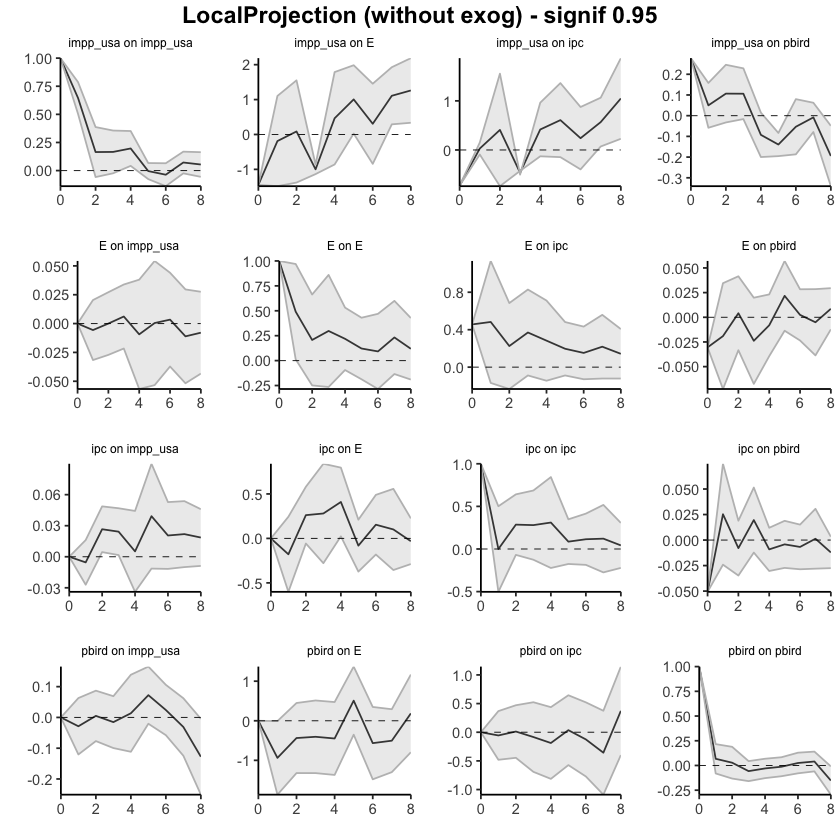

In [6]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.44463181,-1.4446318,-1.4446318
2,impp_usa,E,1,-0.18878711,-0.8484223,0.4708481
3,impp_usa,E,2,0.08647177,-0.6607677,0.8337113
4,impp_usa,E,3,-0.99867545,-1.0685528,-0.9287981
5,impp_usa,E,4,0.46436104,-0.2109699,1.1396920
6,impp_usa,E,5,1.00482315,0.5051679,1.5044784
7,impp_usa,E,6,0.30632378,-0.2796109,0.8922584
8,impp_usa,E,7,1.10889270,0.6912544,1.5265310
9,impp_usa,E,8,1.26177293,0.7892840,1.7342619


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.000000000,0.00000000
65,ipc,E,1,-0.17860004,-0.393939551,0.03673947
66,ipc,E,2,0.26151154,0.098666474,0.42435661
67,ipc,E,3,0.28027745,-0.004878235,0.56543313
68,ipc,E,4,0.40964574,0.212563876,0.60672761
69,ipc,E,5,-0.08143183,-0.230300533,0.06743687
70,ipc,E,6,0.15411543,-0.017023379,0.32525425
71,ipc,E,7,0.10083104,-0.132022669,0.33368475
72,ipc,E,8,-0.03152793,-0.162447447,0.09939158


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.00000000,0.00000000
92,pbird,E,1,-0.9379307,-1.41199559,-0.46386584
93,pbird,E,2,-0.4366440,-0.88830200,0.01501403
94,pbird,E,3,-0.4048328,-0.87308308,0.06341754
95,pbird,E,4,-0.4480363,-0.91776867,0.02169608
96,pbird,E,5,0.5082326,0.06923362,0.94723162
97,pbird,E,6,-0.5654828,-1.03195757,-0.09900793
98,pbird,E,7,-0.5034145,-0.90901450,-0.09781460
99,pbird,E,8,0.1862058,-0.31484405,0.68725563


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.00000000
101,pbird,ipc,1,-0.05606727,-0.27268512,0.16055058
102,pbird,ipc,2,0.01238095,-0.22158347,0.24634537
103,pbird,ipc,3,-0.08370656,-0.39352856,0.22611545
104,pbird,ipc,4,-0.18800703,-0.50714372,0.13112966
105,pbird,ipc,5,0.03602822,-0.27475118,0.34680763
106,pbird,ipc,6,-0.12533451,-0.45520738,0.20453836
107,pbird,ipc,7,-0.35703971,-0.73050419,0.01642477
108,pbird,ipc,8,0.37316886,-0.02070601,0.76704372


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.030476758,-0.030476758,-0.030476758
47,E,pbird,1,-0.019064180,-0.046414615,0.008286255
48,E,pbird,2,0.004093793,-0.015017040,0.023204626
49,E,pbird,3,-0.023821653,-0.046094498,-0.001548808
50,E,pbird,4,-0.008105992,-0.024063900,0.007851915
51,E,pbird,5,0.021728807,0.003689746,0.039767869
52,E,pbird,6,0.002444458,-0.010792563,0.015681478
53,E,pbird,7,-0.005049569,-0.022178295,0.012079157
54,E,pbird,8,0.008621411,-0.002040135,0.019282958


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.277941839,0.277941839,0.27794184
20,impp_usa,pbird,1,0.049837692,-0.005368105,0.10504349
21,impp_usa,pbird,2,0.106522846,0.035474029,0.17757166
22,impp_usa,pbird,3,0.106068233,0.043570535,0.16856593
23,impp_usa,pbird,4,-0.092597307,-0.147301959,-0.03789266
24,impp_usa,pbird,5,-0.139415641,-0.167964863,-0.11086642
25,impp_usa,pbird,6,-0.053433533,-0.121440536,0.01457347
26,impp_usa,pbird,7,-0.008254196,-0.044303822,0.02779543
27,impp_usa,pbird,8,-0.194756930,-0.269116206,-0.12039765


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.050713758,-5.071376e-02,-0.050713758
74,ipc,pbird,1,0.025302333,8.358364e-05,0.050521083
75,ipc,pbird,2,-0.007907377,-2.160942e-02,0.005794670
76,ipc,pbird,3,0.019594618,3.340434e-03,0.035848802
77,ipc,pbird,4,-0.009133367,-1.993074e-02,0.001664011
78,ipc,pbird,5,-0.004205636,-1.596857e-02,0.007557299
79,ipc,pbird,6,-0.006734809,-1.789692e-02,0.004427299
80,ipc,pbird,7,0.001296820,-1.365731e-02,0.016250948
81,ipc,pbird,8,-0.012130316,-1.997700e-02,-0.004283633


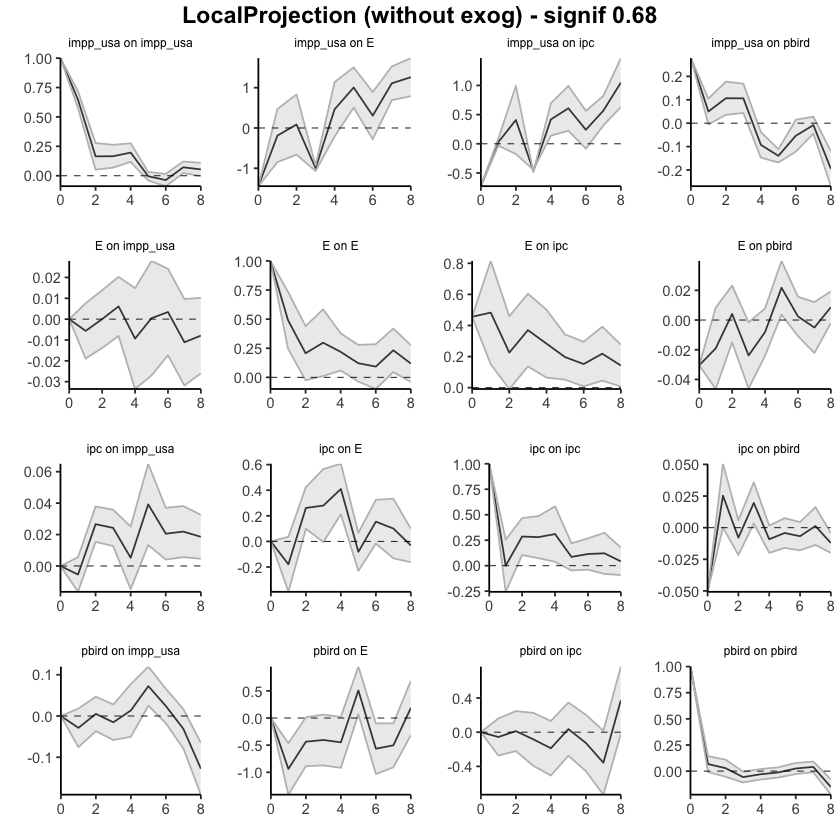

In [7]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.95

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.4446318,-1.444632,-1.4446318
2,impp_usa,E,1,-1.6334189,-2.926304,-0.3405339
3,impp_usa,E,2,-1.5469471,-4.304422,1.2105273
4,impp_usa,E,3,-2.5456226,-5.440057,0.3488115
5,impp_usa,E,4,-2.0812616,-6.299344,2.1368212
6,impp_usa,E,5,-1.0764384,-6.273845,4.1209686
7,impp_usa,E,6,-0.7701146,-7.115954,5.5757243
8,impp_usa,E,7,0.3387781,-6.825632,7.5031882
9,impp_usa,E,8,1.6005510,-6.489937,9.6910394


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000,0.0000000,0.0000000
65,ipc,E,1,-0.1786000,-0.6006655,0.2434654
66,ipc,E,2,0.0829115,-0.6583303,0.8241533
67,ipc,E,3,0.3631889,-0.9369580,1.6633359
68,ipc,E,4,0.7728347,-0.9135927,2.4592621
69,ipc,E,5,0.6914029,-1.2868072,2.6696129
70,ipc,E,6,0.8455183,-1.4681238,3.1591604
71,ipc,E,7,0.9463493,-1.8236860,3.7163847
72,ipc,E,8,0.9148214,-2.1118162,3.9414590


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.000000,0.00000000
92,pbird,E,1,-0.9379307,-1.867098,-0.00876356
93,pbird,E,2,-1.3745747,-3.188992,0.43984217
94,pbird,E,3,-1.7794075,-4.511595,0.95278000
95,pbird,E,4,-2.2274438,-5.880307,1.42541917
96,pbird,E,5,-1.7192111,-6.232512,2.79408983
97,pbird,E,6,-2.2846939,-7.712286,3.14289773
98,pbird,E,7,-2.7881084,-9.010676,3.43445908
99,pbird,E,8,-2.6019026,-9.806528,4.60272257


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.0000000
101,pbird,ipc,1,-0.05606727,-0.4806383,0.3685037
102,pbird,ipc,2,-0.04368632,-0.9268276,0.8394549
103,pbird,ipc,3,-0.12739288,-1.6177853,1.3629995
104,pbird,ipc,4,-0.31539990,-2.4313002,1.8005004
105,pbird,ipc,5,-0.27937168,-3.0043996,2.4456562
106,pbird,ipc,6,-0.40470619,-3.7762850,2.9668726
107,pbird,ipc,7,-0.76174590,-4.8653150,3.3418232
108,pbird,ipc,8,-0.38857704,-5.2641409,4.4869868


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.03047676,-0.03047676,-0.030476758
47,E,pbird,1,-0.04954094,-0.10314779,0.004065915
48,E,pbird,2,-0.04544715,-0.13651123,0.045616941
49,E,pbird,3,-0.06926880,-0.20398766,0.065450064
50,E,pbird,4,-0.07737479,-0.24337115,0.088621571
51,E,pbird,5,-0.05564598,-0.25699891,0.145706939
52,E,pbird,6,-0.05320153,-0.28049901,0.174095956
53,E,pbird,7,-0.05825109,-0.31912088,0.202618690
54,E,pbird,8,-0.04962968,-0.33139610,0.232136732


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.2779418,0.27794184,0.2779418
20,impp_usa,pbird,1,0.3277795,0.21957617,0.4359829
21,impp_usa,pbird,2,0.4343024,0.18684333,0.6817614
22,impp_usa,pbird,3,0.5403706,0.17041608,0.9103251
23,impp_usa,pbird,4,0.4477733,-0.02940235,0.9249490
24,impp_usa,pbird,5,0.3083577,-0.22477446,0.8414898
25,impp_usa,pbird,6,0.2549241,-0.41150172,0.9213500
26,impp_usa,pbird,7,0.2466699,-0.49041318,0.9837531
27,impp_usa,pbird,8,0.0519130,-0.83091430,0.9347403


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.05071376,-0.05071376,-0.05071376
74,ipc,pbird,1,-0.02541142,-0.07484017,0.02401732
75,ipc,pbird,2,-0.03331880,-0.10960356,0.04296596
76,ipc,pbird,3,-0.01372418,-0.12186715,0.09441878
77,ipc,pbird,4,-0.02285755,-0.15216337,0.10644827
78,ipc,pbird,5,-0.02706319,-0.17942436,0.12529799
79,ipc,pbird,6,-0.03379800,-0.20803690,0.14044091
80,ipc,pbird,7,-0.03250118,-0.23605017,0.17104782
81,ipc,pbird,8,-0.04463149,-0.26355999,0.17429701


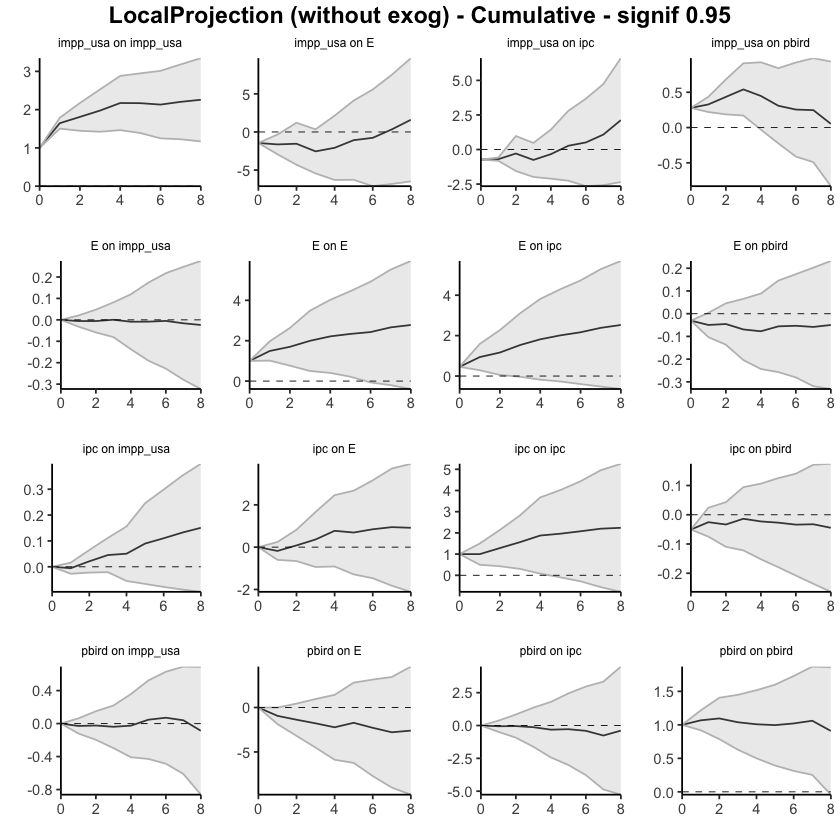

In [10]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
78,ipc,E,1,0.0000000,0.00000000,0.00000000
79,ipc,E,2,-0.1500553,-0.34960529,0.04949469
80,ipc,E,3,0.1297178,-0.24514255,0.50457822
81,ipc,E,4,0.4186360,-0.23791596,1.07518787
82,ipc,E,5,0.8433656,0.01361468,1.67311658
83,ipc,E,6,0.7924682,-0.17340694,1.75834334
84,ipc,E,7,0.9756296,-0.13027018,2.08152946
85,ipc,E,8,1.0797282,-0.23928165,2.39873808
86,ipc,E,9,1.0542884,-0.39155394,2.50013079


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
111,pbird,E,1,0.0000000,0.000000,0.00000000
112,pbird,E,2,-0.7728434,-1.223762,-0.32192469
113,pbird,E,3,-1.1046290,-1.952862,-0.25639591
114,pbird,E,4,-1.5670033,-2.910179,-0.22382722
115,pbird,E,5,-1.8198816,-3.650683,0.01091952
116,pbird,E,6,-1.0743905,-3.323324,1.17454281
117,pbird,E,7,-1.4886230,-4.216175,1.23892937
118,pbird,E,8,-1.7299490,-4.837148,1.37725012
119,pbird,E,9,-1.2938453,-4.903613,2.31592282


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,Psoja_USA,E,1,-0.1946091,-0.1946091,-0.19460906
2,Psoja_USA,E,2,-0.4105930,-0.4507521,-0.37043398
3,Psoja_USA,E,3,-0.5725187,-0.7330353,-0.41200224
4,Psoja_USA,E,4,-0.6185732,-0.8405990,-0.39654750
5,Psoja_USA,E,5,-0.4403093,-0.8528295,-0.02778922
6,Psoja_USA,E,6,-0.3946773,-0.9859500,0.19659532
7,Psoja_USA,E,7,-0.3380029,-1.0684460,0.39244031
8,Psoja_USA,E,8,-0.1341747,-0.9652120,0.69686247
9,Psoja_USA,E,9,0.1029786,-0.8642678,1.07022507


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
23,Psoja_USA,pbird,1,0.017369438,0.017369438,0.01736944
24,Psoja_USA,pbird,2,0.037590437,0.026656603,0.04852427
25,Psoja_USA,pbird,3,0.048195999,0.020275258,0.07611674
26,Psoja_USA,pbird,4,0.070599506,0.028638457,0.11256055
27,Psoja_USA,pbird,5,0.082785310,0.027713262,0.13785736
28,Psoja_USA,pbird,6,0.061734153,-0.005157878,0.12862618
29,Psoja_USA,pbird,7,0.023915541,-0.055709967,0.10354105
30,Psoja_USA,pbird,8,0.012867363,-0.078411076,0.10414580
31,Psoja_USA,pbird,9,0.019780555,-0.085320508,0.12488162


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
34,E,Psoja_USA,1,0.00000000,0.00000000,0.00000000
35,E,Psoja_USA,2,-0.01734392,-0.09821077,0.06352294
36,E,Psoja_USA,3,-0.04941768,-0.19559654,0.09676118
37,E,Psoja_USA,4,-0.10572190,-0.33510537,0.12366158
38,E,Psoja_USA,5,-0.07654555,-0.37965908,0.22656799
39,E,Psoja_USA,6,-0.06577733,-0.43614914,0.30459449
40,E,Psoja_USA,7,-0.06449116,-0.49534002,0.36635771
41,E,Psoja_USA,8,-0.04066806,-0.53781217,0.45647605
42,E,Psoja_USA,9,-0.05647370,-0.62498576,0.51203837


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
67,ipc,Psoja_USA,1,0.000000000,0.00000000,0.00000000
68,ipc,Psoja_USA,2,0.028427811,-0.03800373,0.09485936
69,ipc,Psoja_USA,3,0.055220128,-0.05617240,0.16661265
70,ipc,Psoja_USA,4,0.124700480,-0.04279383,0.29219479
71,ipc,Psoja_USA,5,0.140995688,-0.09780724,0.37979862
72,ipc,Psoja_USA,6,0.005399516,-0.29251875,0.30331778
73,ipc,Psoja_USA,7,-0.089849090,-0.43290156,0.25320338
74,ipc,Psoja_USA,8,-0.114237900,-0.50784705,0.27937125
75,ipc,Psoja_USA,9,-0.110400283,-0.56248613,0.34168556


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,Psoja_USA,1,0.00000000,0.000000000,0.0000000
101,pbird,Psoja_USA,2,0.22445602,0.073897018,0.3750150
102,pbird,Psoja_USA,3,0.34536548,0.006434047,0.6842969
103,pbird,Psoja_USA,4,0.21608476,-0.326527454,0.7586970
104,pbird,Psoja_USA,5,0.26545328,-0.566292640,1.0971992
105,pbird,Psoja_USA,6,0.27503568,-0.734162700,1.2842341
106,pbird,Psoja_USA,7,0.28748012,-0.988250907,1.5632111
107,pbird,Psoja_USA,8,-0.04907899,-1.509880572,1.4117226
108,pbird,Psoja_USA,9,-0.27984580,-2.040117959,1.4804264


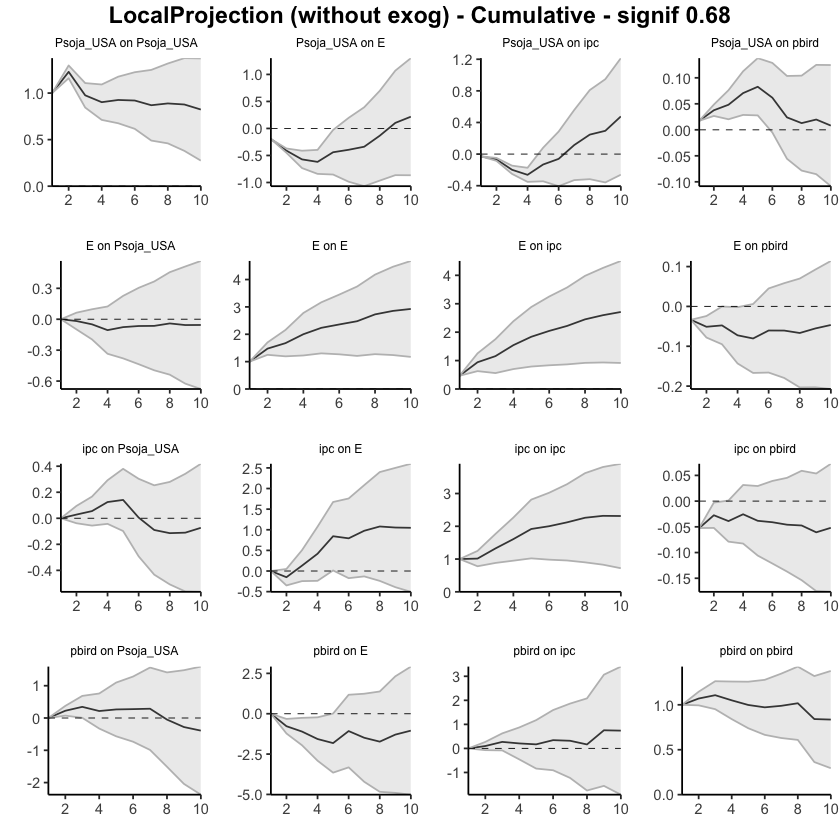

In [ ]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 2 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.9389         0.6296       1.4912
         2              1.1643         0.6855       1.6983
         3              1.5343         0.7688       1.9959
         4              1.8175         0.8207       2.2145
         5              2.0140         0.8621       2.3360
         6              2.1658         0.8919       2.4282
         7              2.3842         0.8961       2.6606
         8              2.5265         0.9091       2.7790
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.4827             0.1734
                  0.2254             0.0559
                  0.3701             0.0832
                  0.2832             0.0520
       

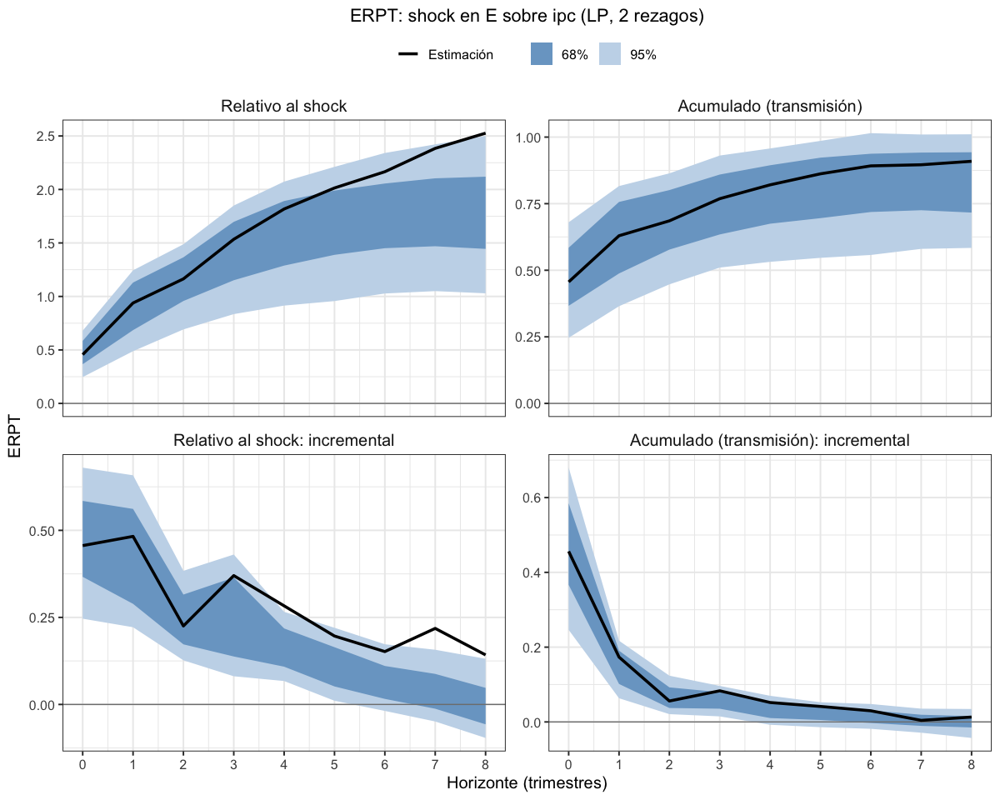

In [26]:
# Todas endógenas, 2 rezagos
lp_erpt <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 2, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa_endog_p2")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.95

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.4402723,-1.44027226,-1.4402723
2,impp_usa,E,1,-0.3970591,-1.69717578,0.9030576
3,impp_usa,E,2,0.3101870,-1.06407373,1.6844477
4,impp_usa,E,3,-0.6933520,-1.21722179,-0.1694823
5,impp_usa,E,4,0.5901875,-0.67437437,1.8547493
6,impp_usa,E,5,1.2288676,0.02102022,2.4367151
7,impp_usa,E,6,0.5320843,-0.68542243,1.7495910
8,impp_usa,E,7,1.3368790,0.33306910,2.3406889
9,impp_usa,E,8,1.4886508,0.46737306,2.5099286


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.000000000,0.0000000
65,ipc,E,1,-0.22916457,-0.674851385,0.2165222
66,ipc,E,2,0.22948587,-0.008617468,0.4675892
67,ipc,E,3,0.38308448,0.022677020,0.7434919
68,ipc,E,4,0.40089262,-0.060025353,0.8618106
69,ipc,E,5,-0.10683286,-0.399951208,0.1862855
70,ipc,E,6,0.17831969,-0.137731054,0.4943704
71,ipc,E,7,0.13152684,-0.258812800,0.5218665
72,ipc,E,8,-0.06171469,-0.301548209,0.1781188


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.0000000,0.00000000
92,pbird,E,1,-0.9423482,-1.8101483,-0.07454807
93,pbird,E,2,-0.4927764,-1.3672597,0.38170692
94,pbird,E,3,-0.4366988,-1.3218669,0.44846927
95,pbird,E,4,-0.4658259,-1.3983305,0.46667864
96,pbird,E,5,0.4343093,-0.4464270,1.31504559
97,pbird,E,6,-0.6050533,-1.5319573,0.32185070
98,pbird,E,7,-0.5293502,-1.3187183,0.26001788
99,pbird,E,8,0.1179176,-0.7886027,1.02443795


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.0000000
101,pbird,ipc,1,-0.05260418,-0.4222075,0.3169991
102,pbird,ipc,2,-0.01983100,-0.4695833,0.4299213
103,pbird,ipc,3,-0.09852538,-0.7105669,0.5135162
104,pbird,ipc,4,-0.20787964,-0.8587587,0.4429994
105,pbird,ipc,5,-0.01807721,-0.6280442,0.5918897
106,pbird,ipc,6,-0.18863217,-0.8783058,0.5010415
107,pbird,ipc,7,-0.38132071,-1.0547353,0.2920939
108,pbird,ipc,8,0.34195490,-0.3777038,1.0616136


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.0303260934,-0.03032609,-0.03032609
47,E,pbird,1,-0.0222378448,-0.06821328,0.02373759
48,E,pbird,2,0.0009056589,-0.03075243,0.03256375
49,E,pbird,3,-0.0268381934,-0.07470675,0.02103036
50,E,pbird,4,-0.0091727777,-0.04323278,0.02488722
51,E,pbird,5,0.0216061927,-0.01560807,0.05882046
52,E,pbird,6,0.0012075049,-0.02337071,0.02578572
53,E,pbird,7,-0.0061311656,-0.03991881,0.02765648
54,E,pbird,8,0.0107550612,-0.01317079,0.03468091


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.30543460,0.30543460,0.305434599
20,impp_usa,pbird,1,0.04634576,-0.07924146,0.171932981
21,impp_usa,pbird,2,0.06863420,-0.08515223,0.222420638
22,impp_usa,pbird,3,0.08106082,-0.05018203,0.212303661
23,impp_usa,pbird,4,-0.10070333,-0.20938635,0.007979691
24,impp_usa,pbird,5,-0.14656589,-0.21474801,-0.078383761
25,impp_usa,pbird,6,-0.07732014,-0.21852228,0.063882000
26,impp_usa,pbird,7,0.01357971,-0.06476834,0.091927764
27,impp_usa,pbird,8,-0.17331105,-0.32845401,-0.018168091


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.0526063191,-0.05260632,-0.052606319
74,ipc,pbird,1,0.0150243896,-0.02529971,0.055348487
75,ipc,pbird,2,-0.0110697578,-0.02935517,0.007215656
76,ipc,pbird,3,0.0164196790,-0.02369504,0.056534398
77,ipc,pbird,4,-0.0151159784,-0.04119139,0.010959433
78,ipc,pbird,5,-0.0050850563,-0.03185971,0.021689596
79,ipc,pbird,6,-0.0002710977,-0.02194824,0.021406045
80,ipc,pbird,7,-0.0076003156,-0.03773469,0.022534056
81,ipc,pbird,8,-0.0087919483,-0.02950797,0.011924070


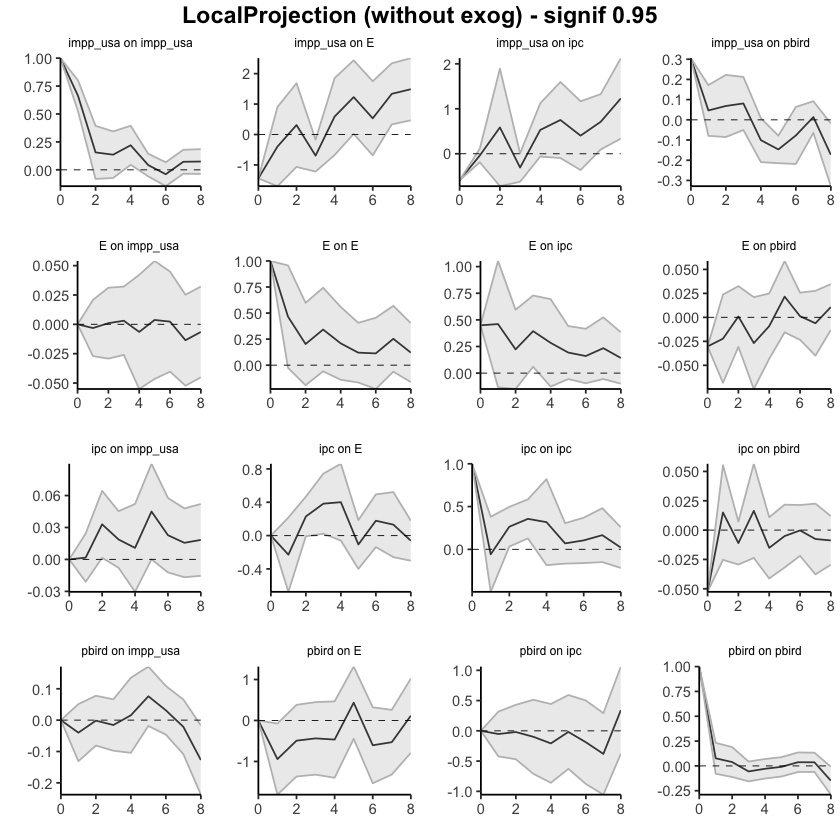

In [11]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.95)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.95

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.4402723,-1.440272,-1.4402723
2,impp_usa,E,1,-1.8373314,-3.137448,-0.5372147
3,impp_usa,E,2,-1.5271444,-4.201522,1.1472330
4,impp_usa,E,3,-2.2204964,-5.418744,0.9777507
5,impp_usa,E,4,-1.6303089,-6.093118,2.8325001
6,impp_usa,E,5,-0.4014413,-6.072098,5.2692152
7,impp_usa,E,6,0.1306430,-6.757520,7.0188062
8,impp_usa,E,7,1.4675220,-6.424451,9.3594951
9,impp_usa,E,8,2.9561729,-5.957078,11.8694237


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000000,0.0000000,0.0000000
65,ipc,E,1,-0.2291645681,-0.6748514,0.2165222
66,ipc,E,2,0.0003213016,-0.6834689,0.6841115
67,ipc,E,3,0.3834057831,-0.6607918,1.4276034
68,ipc,E,4,0.7842984034,-0.7208172,2.2894140
69,ipc,E,5,0.6774655385,-1.1207684,2.4756995
70,ipc,E,6,0.8557852315,-1.2584994,2.9700699
71,ipc,E,7,0.9873120722,-1.5173122,3.4919364
72,ipc,E,8,0.9255973810,-1.8188605,3.6700552


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.000000,0.00000000
92,pbird,E,1,-0.9423482,-1.810148,-0.07454807
93,pbird,E,2,-1.4351246,-3.177408,0.30715884
94,pbird,E,3,-1.8718234,-4.499275,0.75562812
95,pbird,E,4,-2.3376493,-5.897605,1.22230676
96,pbird,E,5,-1.9033400,-6.344032,2.53735236
97,pbird,E,6,-2.5083933,-7.875990,2.85920305
98,pbird,E,7,-3.0377435,-9.194708,3.11922094
99,pbird,E,8,-2.9198259,-9.983311,4.14365889


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.0000000
101,pbird,ipc,1,-0.05260418,-0.4222075,0.3169991
102,pbird,ipc,2,-0.07243518,-0.8917908,0.7469204
103,pbird,ipc,3,-0.17096056,-1.6023577,1.2604366
104,pbird,ipc,4,-0.37884020,-2.4611164,1.7034360
105,pbird,ipc,5,-0.39691741,-3.0891606,2.2953258
106,pbird,ipc,6,-0.58554958,-3.9674664,2.7963672
107,pbird,ipc,7,-0.96687030,-5.0222017,3.0884611
108,pbird,ipc,8,-0.62491540,-5.3999055,4.1500747


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.03032609,-0.03032609,-0.030326093
47,E,pbird,1,-0.05256394,-0.09853937,-0.006588505
48,E,pbird,2,-0.05165828,-0.12929180,0.025975244
49,E,pbird,3,-0.07849647,-0.20399855,0.047005608
50,E,pbird,4,-0.08766925,-0.24723133,0.071892830
51,E,pbird,5,-0.06606306,-0.26283940,0.130713287
52,E,pbird,6,-0.06485555,-0.28621011,0.156499008
53,E,pbird,7,-0.07098672,-0.32612892,0.184155487
54,E,pbird,8,-0.06023166,-0.33929971,0.218836395


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.30543460,0.30543460,0.3054346
20,impp_usa,pbird,1,0.35178036,0.22619314,0.4773676
21,impp_usa,pbird,2,0.42041457,0.14104091,0.6997882
22,impp_usa,pbird,3,0.50147538,0.09085888,0.9120919
23,impp_usa,pbird,4,0.40077205,-0.11852747,0.9200716
24,impp_usa,pbird,5,0.25420617,-0.33327548,0.8416878
25,impp_usa,pbird,6,0.17688603,-0.55179775,0.9055698
26,impp_usa,pbird,7,0.19046574,-0.61656609,0.9974976
27,impp_usa,pbird,8,0.01715469,-0.94502010,0.9793295


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.05260632,-0.05260632,-0.052606319
74,ipc,pbird,1,-0.03758193,-0.07790603,0.002742168
75,ipc,pbird,2,-0.04865169,-0.10726120,0.009957824
76,ipc,pbird,3,-0.03223201,-0.13095624,0.066492222
77,ipc,pbird,4,-0.04734799,-0.17214763,0.077451655
78,ipc,pbird,5,-0.05243304,-0.20400734,0.099141251
79,ipc,pbird,6,-0.05270414,-0.22595558,0.120547296
80,ipc,pbird,7,-0.06030446,-0.26369026,0.143081352
81,ipc,pbird,8,-0.06909640,-0.29319823,0.155005422


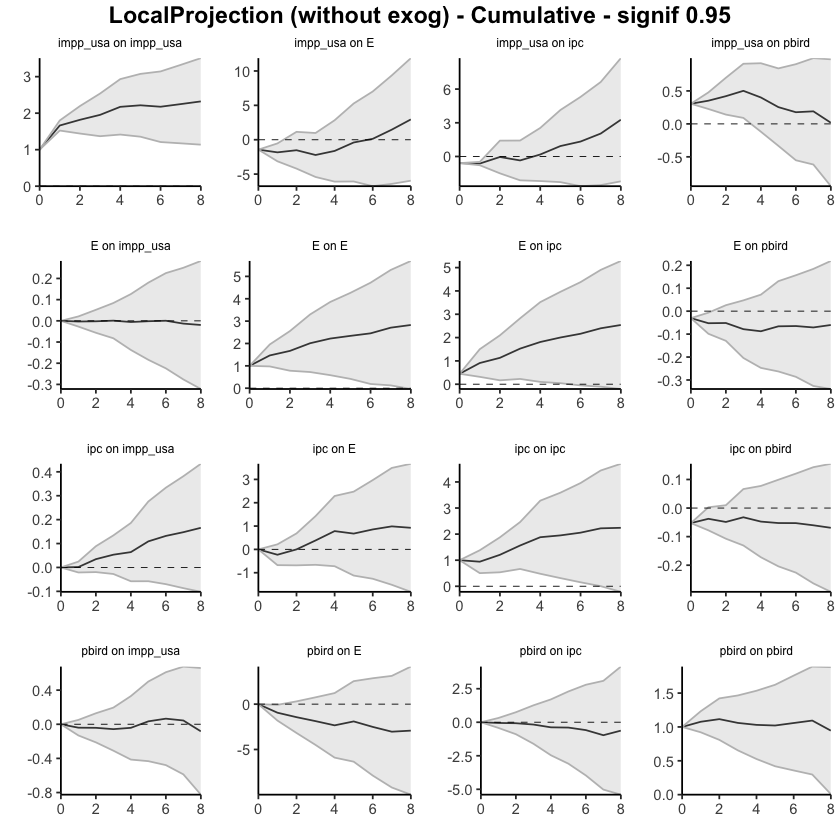

In [12]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.95, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.4402723,-1.44027226,-1.4402723
2,impp_usa,E,1,-0.3970591,-1.06038394,0.2662657
3,impp_usa,E,2,0.3101870,-0.39096644,1.0113404
4,impp_usa,E,3,-0.6933520,-0.96063253,-0.4260716
5,impp_usa,E,4,0.5901875,-0.05499714,1.2353721
6,impp_usa,E,5,1.2288676,0.61261896,1.8451163
7,impp_usa,E,6,0.5320843,-0.08909261,1.1532612
8,impp_usa,E,7,1.3368790,0.82473109,1.8490269
9,impp_usa,E,8,1.4886508,0.96759075,2.0097109


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.00000000,0.000000000
65,ipc,E,1,-0.22916457,-0.45655580,-0.001773335
66,ipc,E,2,0.22948587,0.10800458,0.350967164
67,ipc,E,3,0.38308448,0.19920312,0.566965840
68,ipc,E,4,0.40089262,0.16573039,0.636054852
69,ipc,E,5,-0.10683286,-0.25638304,0.042717310
70,ipc,E,6,0.17831969,0.01706931,0.339570074
71,ipc,E,7,0.13152684,-0.06762604,0.330679719
72,ipc,E,8,-0.06171469,-0.18407873,0.060649348


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.00000000,0.000000000
92,pbird,E,1,-0.9423482,-1.38510337,-0.499593033
93,pbird,E,2,-0.4927764,-0.93894133,-0.046611434
94,pbird,E,3,-0.4366988,-0.88831515,0.014917568
95,pbird,E,4,-0.4658259,-0.94159358,0.009941708
96,pbird,E,5,0.4343093,-0.01504593,0.883664559
97,pbird,E,6,-0.6050533,-1.07796354,-0.132143109
98,pbird,E,7,-0.5293502,-0.93208900,-0.126611376
99,pbird,E,8,0.1179176,-0.34459275,0.580427990


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.00000000
101,pbird,ipc,1,-0.05260418,-0.2411773,0.13596893
102,pbird,ipc,2,-0.01983100,-0.2492965,0.20963445
103,pbird,ipc,3,-0.09852538,-0.4107915,0.21374071
104,pbird,ipc,4,-0.20787964,-0.5399608,0.12420153
105,pbird,ipc,5,-0.01807721,-0.3292848,0.29313042
106,pbird,ipc,6,-0.18863217,-0.5405065,0.16324213
107,pbird,ipc,7,-0.38132071,-0.7248996,-0.03774183
108,pbird,ipc,8,0.34195490,-0.0252179,0.70912769


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.0303260934,-0.030326093,-0.030326093
47,E,pbird,1,-0.0222378448,-0.045694698,0.001219009
48,E,pbird,2,0.0009056589,-0.015246428,0.017057746
49,E,pbird,3,-0.0268381934,-0.051260927,-0.002415460
50,E,pbird,4,-0.0091727777,-0.026550328,0.008204773
51,E,pbird,5,0.0216061927,0.002619323,0.040593062
52,E,pbird,6,0.0012075049,-0.011332401,0.013747411
53,E,pbird,7,-0.0061311656,-0.023369760,0.011107429
54,E,pbird,8,0.0107550612,-0.001452004,0.022962126


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.30543460,0.305434599,0.305434599
20,impp_usa,pbird,1,0.04634576,-0.017729349,0.110420874
21,impp_usa,pbird,2,0.06863420,-0.009828263,0.147096670
22,impp_usa,pbird,3,0.08106082,0.014100182,0.148021452
23,impp_usa,pbird,4,-0.10070333,-0.156153853,-0.045252810
24,impp_usa,pbird,5,-0.14656589,-0.181352683,-0.111779087
25,impp_usa,pbird,6,-0.07732014,-0.149362045,-0.005278231
26,impp_usa,pbird,7,0.01357971,-0.026393784,0.053553208
27,impp_usa,pbird,8,-0.17331105,-0.252465620,-0.094156479


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.0526063191,-0.052606319,-0.052606319
74,ipc,pbird,1,0.0150243896,-0.005549129,0.035597909
75,ipc,pbird,2,-0.0110697578,-0.020399051,-0.001740465
76,ipc,pbird,3,0.0164196790,-0.004047015,0.036886373
77,ipc,pbird,4,-0.0151159784,-0.028419760,-0.001812197
78,ipc,pbird,5,-0.0050850563,-0.018745593,0.008575480
79,ipc,pbird,6,-0.0002710977,-0.011330865,0.010788669
80,ipc,pbird,7,-0.0076003156,-0.022974995,0.007774364
81,ipc,pbird,8,-0.0087919483,-0.019361345,0.001777449


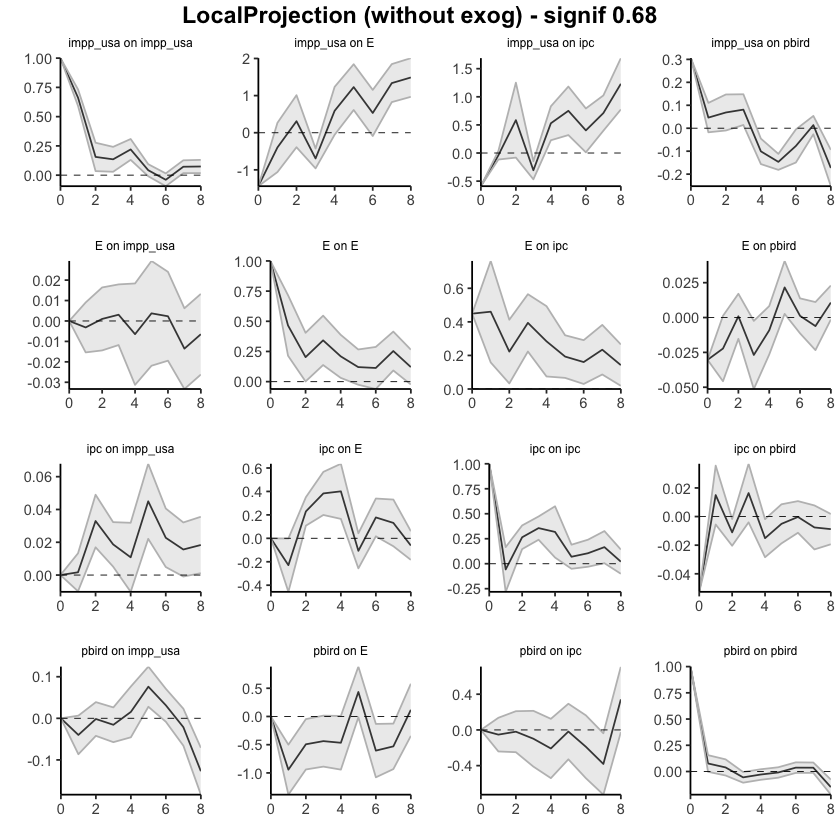

In [14]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-1.4402723,-1.440272,-1.4402723
2,impp_usa,E,1,-1.8373314,-2.500656,-1.1740065
3,impp_usa,E,2,-1.5271444,-2.891623,-0.1626661
4,impp_usa,E,3,-2.2204964,-3.852255,-0.5887377
5,impp_usa,E,4,-1.6303089,-3.907252,0.6466344
6,impp_usa,E,5,-0.4014413,-3.294633,2.4917508
7,impp_usa,E,6,0.1306430,-3.383726,3.6450120
8,impp_usa,E,7,1.4675220,-2.558995,5.4940389
9,impp_usa,E,8,2.9561729,-1.591404,7.5037498


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000000,0.00000000,0.000000000
65,ipc,E,1,-0.2291645681,-0.45655580,-0.001773335
66,ipc,E,2,0.0003213016,-0.34855123,0.349193829
67,ipc,E,3,0.3834057831,-0.14934810,0.916159669
68,ipc,E,4,0.7842984034,0.01638229,1.552214521
69,ipc,E,5,0.6774655385,-0.24000075,1.594931831
70,ipc,E,6,0.8557852315,-0.22293144,1.934501905
71,ipc,E,7,0.9873120722,-0.29055748,2.265181624
72,ipc,E,8,0.9255973810,-0.47463621,2.325830972


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.000000,0.0000000
92,pbird,E,1,-0.9423482,-1.385103,-0.4995930
93,pbird,E,2,-1.4351246,-2.324045,-0.5462045
94,pbird,E,3,-1.8718234,-3.212360,-0.5312869
95,pbird,E,4,-2.3376493,-4.153953,-0.5213452
96,pbird,E,5,-1.9033400,-4.168999,0.3623194
97,pbird,E,6,-2.5083933,-5.246963,0.2301763
98,pbird,E,7,-3.0377435,-6.179052,0.1035649
99,pbird,E,8,-2.9198259,-6.523645,0.6839929


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.0000000
101,pbird,ipc,1,-0.05260418,-0.2411773,0.1359689
102,pbird,ipc,2,-0.07243518,-0.4904737,0.3456034
103,pbird,ipc,3,-0.17096056,-0.9012652,0.5593441
104,pbird,ipc,4,-0.37884020,-1.4412260,0.6835456
105,pbird,ipc,5,-0.39691741,-1.7705109,0.9766760
106,pbird,ipc,6,-0.58554958,-2.3110173,1.1399182
107,pbird,ipc,7,-0.96687030,-3.0359169,1.1021763
108,pbird,ipc,8,-0.62491540,-3.0611348,1.8113040


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.03032609,-0.03032609,-0.030326093
47,E,pbird,1,-0.05256394,-0.07602079,-0.029107085
48,E,pbird,2,-0.05165828,-0.09126722,-0.012049339
49,E,pbird,3,-0.07849647,-0.14252815,-0.014464799
50,E,pbird,4,-0.08766925,-0.16907847,-0.006260026
51,E,pbird,5,-0.06606306,-0.16645915,0.034333036
52,E,pbird,6,-0.06485555,-0.17779155,0.048080447
53,E,pbird,7,-0.07098672,-0.20116131,0.059187876
54,E,pbird,8,-0.06023166,-0.20261332,0.082150002


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.30543460,0.30543460,0.3054346
20,impp_usa,pbird,1,0.35178036,0.28770525,0.4158555
21,impp_usa,pbird,2,0.42041457,0.27787699,0.5629521
22,impp_usa,pbird,3,0.50147538,0.29197717,0.7109736
23,impp_usa,pbird,4,0.40077205,0.13582332,0.6657208
24,impp_usa,pbird,5,0.25420617,-0.04552937,0.5539417
25,impp_usa,pbird,6,0.17688603,-0.19489141,0.5486635
26,impp_usa,pbird,7,0.19046574,-0.22128520,0.6022167
27,impp_usa,pbird,8,0.01715469,-0.47375082,0.5080602


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.05260632,-0.05260632,-0.05260632
74,ipc,pbird,1,-0.03758193,-0.05815545,-0.01700841
75,ipc,pbird,2,-0.04865169,-0.07855450,-0.01874888
76,ipc,pbird,3,-0.03223201,-0.08260151,0.01813750
77,ipc,pbird,4,-0.04734799,-0.11102127,0.01632530
78,ipc,pbird,5,-0.05243304,-0.12976687,0.02490078
79,ipc,pbird,6,-0.05270414,-0.14109773,0.03568945
80,ipc,pbird,7,-0.06030446,-0.16407273,0.04346381
81,ipc,pbird,8,-0.06909640,-0.18343407,0.04524126


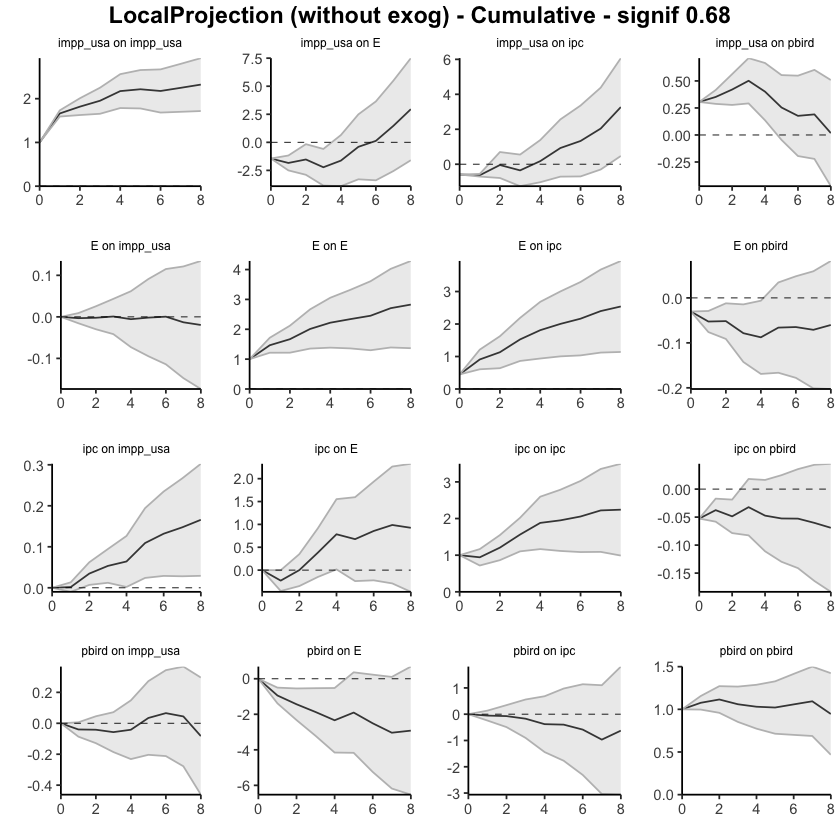

In [15]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 3 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4489         0.4489       1.0000
         1              0.9094         0.6206       1.4655
         2              1.1323         0.6787       1.6684
         3              1.5263         0.7592       2.0104
         4              1.8104         0.8155       2.2201
         5              2.0036         0.8561       2.3405
         6              2.1641         0.8820       2.4536
         7              2.3983         0.8860       2.7070
         8              2.5404         0.8985       2.8274
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4489             0.4489
                  0.4605             0.1717
                  0.2229             0.0581
                  0.3940             0.0806
                  0.2841             0.0562
       

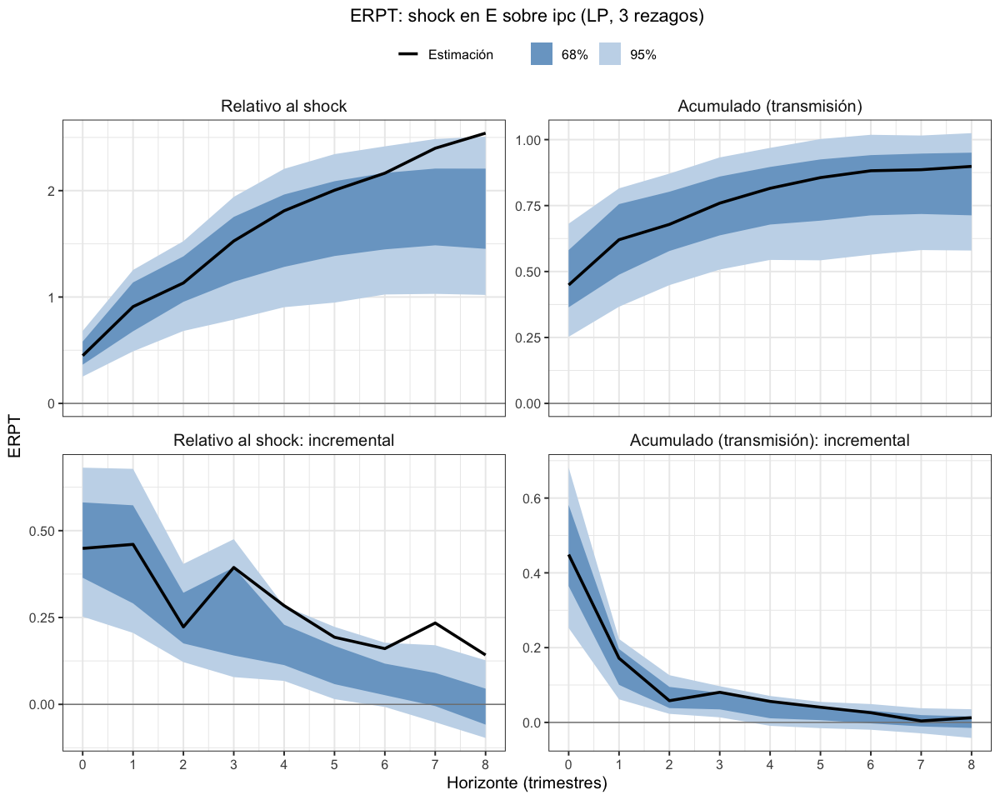

In [ ]:
# Todas endógenas, 3 rezagos
lp_erpt <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 3, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa_endog_p3")

### impp_usa 1950 a 2023 - 1 exógena y el resto endógenas - Selected orders: 2 y 5

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.95

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.0000000
20,ipc,E,1,-0.17749731,-0.59847032,0.2434757
21,ipc,E,2,0.26202491,-0.05611063,0.5801605
22,ipc,E,3,0.28075341,-0.27707269,0.8385795
23,ipc,E,4,0.41017250,0.02497449,0.7953705
24,ipc,E,5,-0.08202937,-0.37280040,0.2087417
25,ipc,E,6,0.15478028,-0.17957685,0.4891374
26,ipc,E,7,0.10142291,-0.35403570,0.5568815
27,ipc,E,8,-0.03174686,-0.28719449,0.2237008


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.0000000,0.00000000
38,pbird,E,1,-0.9379307,-1.8670979,-0.00876356
39,pbird,E,2,-0.4366440,-1.3218937,0.44860573
40,pbird,E,3,-0.4048328,-1.3226034,0.51293784
41,pbird,E,4,-0.4480363,-1.3687118,0.47263917
42,pbird,E,5,0.5082326,-0.3522054,1.36867065
43,pbird,E,6,-0.5654828,-1.4797734,0.34880790
44,pbird,E,7,-0.5034145,-1.2983904,0.29156135
45,pbird,E,8,0.1862058,-0.7958519,1.16826348


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4574976,0.45749761,0.4574976
2,E,ipc,1,0.4829381,-0.16722628,1.1331024
3,E,ipc,2,0.2257089,-0.23151443,0.6829322
4,E,ipc,3,0.3708091,-0.08568610,0.8273043
5,E,ipc,4,0.2844009,-0.14165240,0.7104542
6,E,ipc,5,0.1964499,-0.08628708,0.4791869
7,E,ipc,6,0.1525628,-0.12605773,0.4311834
8,E,ipc,7,0.2201548,-0.11713410,0.5574437
9,E,ipc,8,0.1406651,-0.12017674,0.4015070


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,-0.05606727,-0.4806383,0.3685037
48,pbird,ipc,2,0.01238095,-0.4461893,0.4709512
49,pbird,ipc,3,-0.08370656,-0.6909577,0.5235446
50,pbird,ipc,4,-0.18800703,-0.8135149,0.4375009
51,pbird,ipc,5,0.03602822,-0.5730994,0.6451559
52,pbird,ipc,6,-0.12533451,-0.7718853,0.5212163
53,pbird,ipc,7,-0.35703971,-1.0890301,0.3749507
54,pbird,ipc,8,0.37316886,-0.3988259,1.1451636


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.035019959,-0.03501996,-0.03501996
11,E,pbird,1,-0.019333656,-0.07234130,0.03367399
12,E,pbird,2,0.003957374,-0.03281697,0.04073172
13,E,pbird,3,-0.023539927,-0.06678388,0.01970402
14,E,pbird,4,-0.007984066,-0.03885026,0.02288212
15,E,pbird,5,0.021780003,-0.01317702,0.05673703
16,E,pbird,6,0.002323720,-0.02318269,0.02783013
17,E,pbird,7,-0.005228242,-0.03839175,0.02793527
18,E,pbird,8,0.009287245,-0.01099039,0.02956488


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.051889468,-0.05188947,-0.051889468
29,ipc,pbird,1,0.025222805,-0.02403147,0.074477080
30,ipc,pbird,2,-0.007940472,-0.03460784,0.018726895
31,ipc,pbird,3,0.019661834,-0.01207745,0.051401115
32,ipc,pbird,4,-0.009098184,-0.03014570,0.011949328
33,ipc,pbird,5,-0.004190735,-0.02713318,0.018751707
34,ipc,pbird,6,-0.006764191,-0.02851928,0.014990896
35,ipc,pbird,7,0.001249444,-0.02794314,0.030442030
36,ipc,pbird,8,-0.011951242,-0.02716285,0.003260361


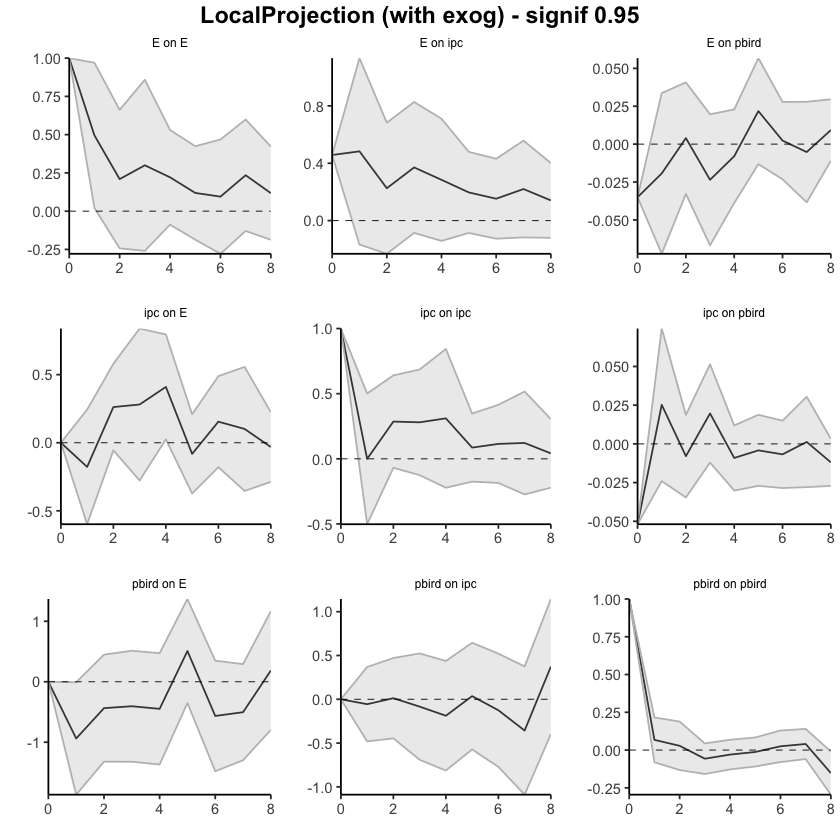

In [16]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.95)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.95

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.0000000,0.0000000
20,ipc,E,1,-0.1774973,-0.5984703,0.2434757
21,ipc,E,2,0.0845276,-0.6545809,0.8236362
22,ipc,E,3,0.3652810,-0.9316536,1.6622157
23,ipc,E,4,0.7754535,-0.9066791,2.4575862
24,ipc,E,5,0.6934242,-1.2794795,2.6663278
25,ipc,E,6,0.8482044,-1.4590564,3.1554653
26,ipc,E,7,0.9496273,-1.8130921,3.7123468
27,ipc,E,8,0.9178805,-2.1002866,3.9360475


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.00000000
38,pbird,E,1,-0.9379307,-1.867098,-0.00876356
39,pbird,E,2,-1.3745747,-3.188992,0.43984217
40,pbird,E,3,-1.7794075,-4.511595,0.95278000
41,pbird,E,4,-2.2274438,-5.880307,1.42541917
42,pbird,E,5,-1.7192111,-6.232512,2.79408983
43,pbird,E,6,-2.2846939,-7.712286,3.14289773
44,pbird,E,7,-2.7881084,-9.010676,3.43445908
45,pbird,E,8,-2.6019026,-9.806528,4.60272257


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4574976,0.45749761,0.4574976
2,E,ipc,1,0.9404357,0.29027133,1.5906000
3,E,ipc,2,1.1661446,0.05875691,2.2735322
4,E,ipc,3,1.5369537,-0.02692919,3.1008366
5,E,ipc,4,1.8213546,-0.16858159,3.8112908
6,E,ipc,5,2.0178045,-0.25486867,4.2904776
7,E,ipc,6,2.1703673,-0.38092640,4.7216610
8,E,ipc,7,2.3905221,-0.49806050,5.2791047
9,E,ipc,8,2.5311872,-0.61823724,5.6806117


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,-0.05606727,-0.4806383,0.3685037
48,pbird,ipc,2,-0.04368632,-0.9268276,0.8394549
49,pbird,ipc,3,-0.12739288,-1.6177853,1.3629995
50,pbird,ipc,4,-0.31539990,-2.4313002,1.8005004
51,pbird,ipc,5,-0.27937168,-3.0043996,2.4456562
52,pbird,ipc,6,-0.40470619,-3.7762850,2.9668726
53,pbird,ipc,7,-0.76174590,-4.8653150,3.3418232
54,pbird,ipc,8,-0.38857704,-5.2641409,4.4869868


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.03501996,-0.03501996,-0.035019959
11,E,pbird,1,-0.05435361,-0.10736126,-0.001345968
12,E,pbird,2,-0.05039624,-0.14017824,0.039385754
13,E,pbird,3,-0.07393617,-0.20696211,0.059089778
14,E,pbird,4,-0.08192023,-0.24581237,0.081971902
15,E,pbird,5,-0.06014023,-0.25898939,0.138708929
16,E,pbird,6,-0.05781651,-0.28217208,0.166539059
17,E,pbird,7,-0.06304475,-0.32056383,0.194474328
18,E,pbird,8,-0.05375751,-0.33155423,0.224039212


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.05188947,-0.05188947,-0.05188947
29,ipc,pbird,1,-0.02666666,-0.07592094,0.02258761
30,ipc,pbird,2,-0.03460713,-0.11052878,0.04131451
31,ipc,pbird,3,-0.01494530,-0.12260622,0.09271562
32,ipc,pbird,4,-0.02404348,-0.15275192,0.10466495
33,ipc,pbird,5,-0.02823422,-0.17988509,0.12341666
34,ipc,pbird,6,-0.03499841,-0.20840437,0.13840755
35,ipc,pbird,7,-0.03374897,-0.23634752,0.16884958
36,ipc,pbird,8,-0.04570021,-0.26351036,0.17210994


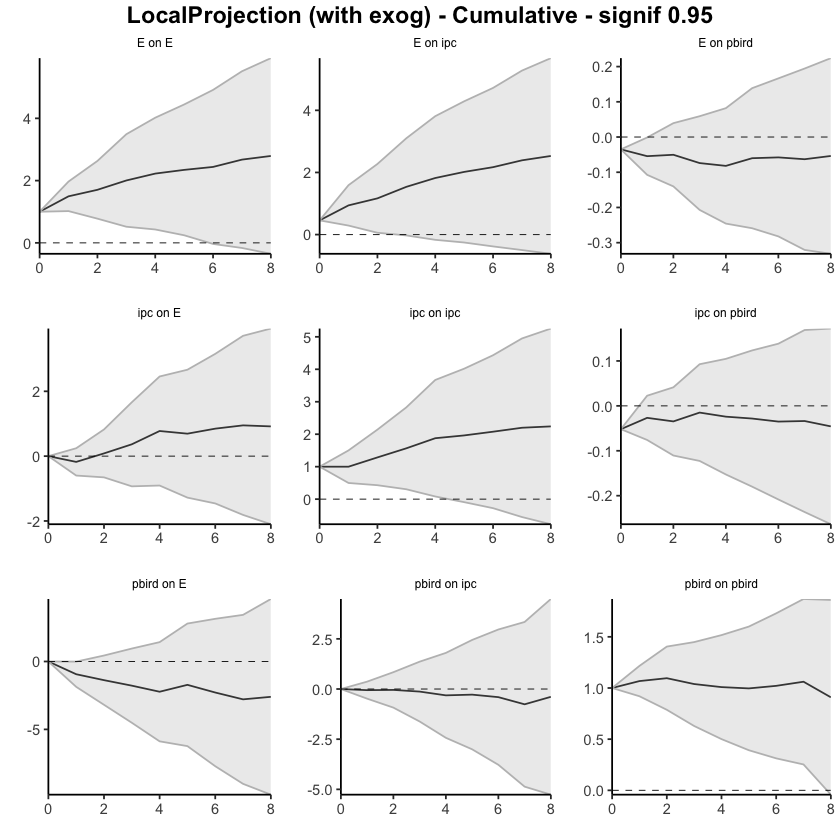

In [17]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.95, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.000000000,0.00000000
20,ipc,E,1,-0.17749731,-0.392279454,0.03728484
21,ipc,E,2,0.26202491,0.099710859,0.42433896
22,ipc,E,3,0.28075341,-0.003851742,0.56535857
23,ipc,E,4,0.41017250,0.213642906,0.60670210
24,ipc,E,5,-0.08202937,-0.230381932,0.06632320
25,ipc,E,6,0.15478028,-0.015810096,0.32537065
26,ipc,E,7,0.10142291,-0.130953932,0.33379975
27,ipc,E,8,-0.03174686,-0.162077282,0.09858356


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.00000000,0.00000000
38,pbird,E,1,-0.9379307,-1.41199559,-0.46386584
39,pbird,E,2,-0.4366440,-0.88830200,0.01501403
40,pbird,E,3,-0.4048328,-0.87308308,0.06341754
41,pbird,E,4,-0.4480363,-0.91776867,0.02169608
42,pbird,E,5,0.5082326,0.06923362,0.94723162
43,pbird,E,6,-0.5654828,-1.03195757,-0.09900793
44,pbird,E,7,-0.5034145,-0.90901450,-0.09781460
45,pbird,E,8,0.1862058,-0.31484405,0.68725563


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4574976,0.457497615,0.4574976
2,E,ipc,1,0.4829381,0.151221558,0.8146546
3,E,ipc,2,0.2257089,-0.007568305,0.4589861
4,E,ipc,3,0.3708091,0.137903386,0.6037148
5,E,ipc,4,0.2844009,0.067026773,0.5017750
6,E,ipc,5,0.1964499,0.052196333,0.3407034
7,E,ipc,6,0.1525628,0.010409485,0.2947162
8,E,ipc,7,0.2201548,0.048068620,0.3922410
9,E,ipc,8,0.1406651,0.007582553,0.2737477


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.00000000
47,pbird,ipc,1,-0.05606727,-0.27268512,0.16055058
48,pbird,ipc,2,0.01238095,-0.22158347,0.24634537
49,pbird,ipc,3,-0.08370656,-0.39352856,0.22611545
50,pbird,ipc,4,-0.18800703,-0.50714372,0.13112966
51,pbird,ipc,5,0.03602822,-0.27475118,0.34680763
52,pbird,ipc,6,-0.12533451,-0.45520738,0.20453836
53,pbird,ipc,7,-0.35703971,-0.73050419,0.01642477
54,pbird,ipc,8,0.37316886,-0.02070601,0.76704372


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.035019959,-0.035019959,-0.035019959
11,E,pbird,1,-0.019333656,-0.046378374,0.007711062
12,E,pbird,2,0.003957374,-0.014805048,0.022719796
13,E,pbird,3,-0.023539927,-0.045603168,-0.001476687
14,E,pbird,4,-0.007984066,-0.023732121,0.007763990
15,E,pbird,5,0.021780003,0.003944786,0.039615220
16,E,pbird,6,0.002323720,-0.010689754,0.015337194
17,E,pbird,7,-0.005228242,-0.022148401,0.011691917
18,E,pbird,8,0.009287245,-0.001058490,0.019632979


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.051889468,-5.188947e-02,-0.051889468
29,ipc,pbird,1,0.025222805,9.307338e-05,0.050352537
30,ipc,pbird,2,-0.007940472,-2.154627e-02,0.005665328
31,ipc,pbird,3,0.019661834,3.468324e-03,0.035855345
32,ipc,pbird,4,-0.009098184,-1.983671e-02,0.001640343
33,ipc,pbird,5,-0.004190735,-1.589606e-02,0.007514593
34,ipc,pbird,6,-0.006764191,-1.786373e-02,0.004335343
35,ipc,pbird,7,0.001249444,-1.364473e-02,0.016143621
36,ipc,pbird,8,-0.011951242,-1.971226e-02,-0.004190220


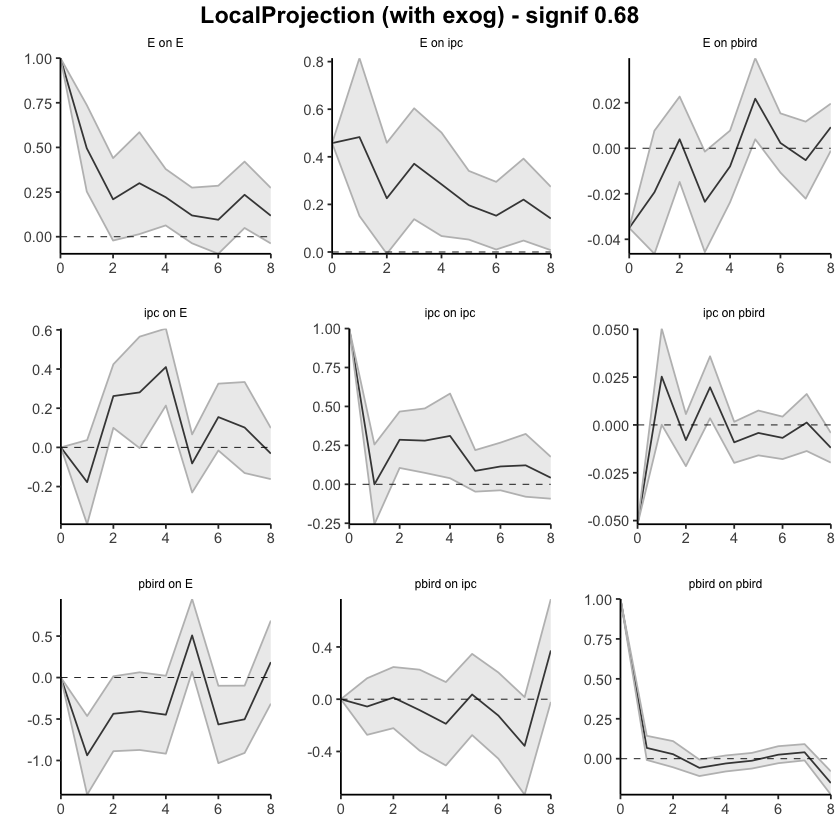

In [18]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.00000000,0.00000000
20,ipc,E,1,-0.1774973,-0.39227945,0.03728484
21,ipc,E,2,0.0845276,-0.29256859,0.46162380
22,ipc,E,3,0.3652810,-0.29642034,1.02698237
23,ipc,E,4,0.7754535,-0.08277743,1.63368447
24,ipc,E,5,0.6934242,-0.31315936,1.70000767
25,ipc,E,6,0.8482044,-0.32896946,2.02537832
26,ipc,E,7,0.9496273,-0.45992339,2.35917807
27,ipc,E,8,0.9178805,-0.62200067,2.45776164


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.0000000
38,pbird,E,1,-0.9379307,-1.411996,-0.4638658
39,pbird,E,2,-1.3745747,-2.300298,-0.4488518
40,pbird,E,3,-1.7794075,-3.173381,-0.3854343
41,pbird,E,4,-2.2274438,-4.091149,-0.3637382
42,pbird,E,5,-1.7192111,-4.021916,0.5834934
43,pbird,E,6,-2.2846939,-5.053873,0.4844855
44,pbird,E,7,-2.7881084,-5.962888,0.3866709
45,pbird,E,8,-2.6019026,-6.277732,1.0739265


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4574976,0.4574976,0.4574976
2,E,ipc,1,0.9404357,0.6087192,1.2721522
3,E,ipc,2,1.1661446,0.6011509,1.7311383
4,E,ipc,3,1.5369537,0.7390543,2.3348531
5,E,ipc,4,1.8213546,0.8060810,2.8366281
6,E,ipc,5,2.0178045,0.8582774,3.1773316
7,E,ipc,6,2.1703673,0.8686868,3.4720478
8,E,ipc,7,2.3905221,0.9167555,3.8642887
9,E,ipc,8,2.5311872,0.9243380,4.1380365


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,-0.05606727,-0.2726851,0.1605506
48,pbird,ipc,2,-0.04368632,-0.4942686,0.4068960
49,pbird,ipc,3,-0.12739288,-0.8877972,0.6330114
50,pbird,ipc,4,-0.31539990,-1.3949409,0.7641411
51,pbird,ipc,5,-0.27937168,-1.6696921,1.1109487
52,pbird,ipc,6,-0.40470619,-2.1248994,1.3154871
53,pbird,ipc,7,-0.76174590,-2.8554036,1.3319118
54,pbird,ipc,8,-0.38857704,-2.8761096,2.0989555


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.03501996,-0.03501996,-0.035019959
11,E,pbird,1,-0.05435361,-0.08139833,-0.027308897
12,E,pbird,2,-0.05039624,-0.09620338,-0.004589101
13,E,pbird,3,-0.07393617,-0.14180655,-0.006065788
14,E,pbird,4,-0.08192023,-0.16553867,0.001698203
15,E,pbird,5,-0.06014023,-0.16159388,0.041313422
16,E,pbird,6,-0.05781651,-0.17228364,0.056650616
17,E,pbird,7,-0.06304475,-0.19443204,0.068342533
18,E,pbird,8,-0.05375751,-0.19549053,0.087975512


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.05188947,-0.05188947,-0.051889468
29,ipc,pbird,1,-0.02666666,-0.05179639,-0.001536931
30,ipc,pbird,2,-0.03460713,-0.07334267,0.004128397
31,ipc,pbird,3,-0.01494530,-0.06987434,0.039983742
32,ipc,pbird,4,-0.02404348,-0.08971105,0.041624084
33,ipc,pbird,5,-0.02823422,-0.10560711,0.049138677
34,ipc,pbird,6,-0.03499841,-0.12347084,0.053474020
35,ipc,pbird,7,-0.03374897,-0.13711557,0.069617640
36,ipc,pbird,8,-0.04570021,-0.15682784,0.065427420


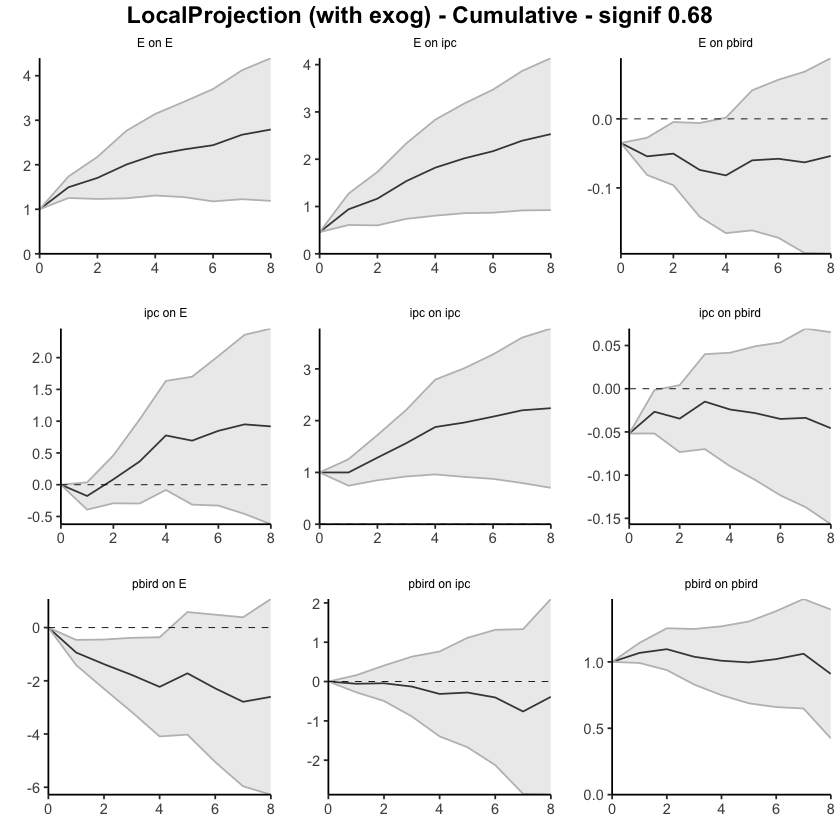

In [19]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas 2 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4575         0.4575       1.0000
         1              0.9404         0.6290       1.4952
         2              1.1661         0.6841       1.7046
         3              1.5370         0.7668       2.0043
         4              1.8214         0.8184       2.2255
         5              2.0178         0.8606       2.3446
         6              2.1704         0.8897       2.4396
         7              2.3905         0.8939       2.6743
         8              2.5312         0.9066       2.7918
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4575             0.4575
                  0.4829             0.1715
                  0.2257             0.0551
                  0.3708             0.0827
                  0.2844       

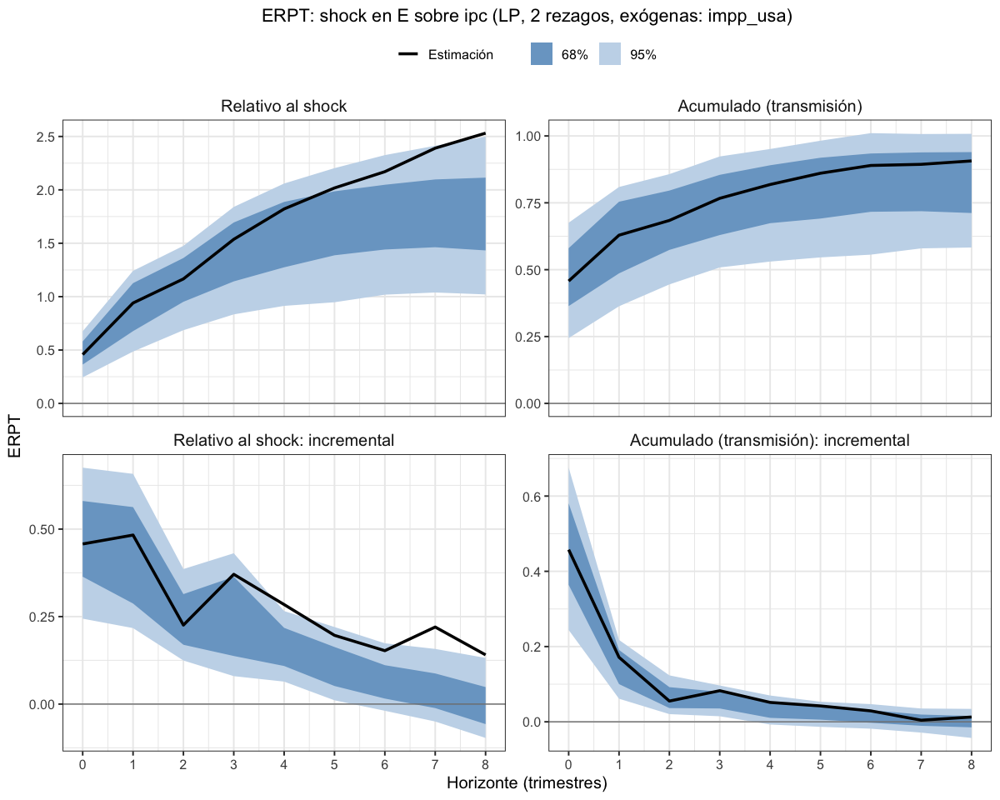

In [28]:
# impp_usa exógena, 2 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 2, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa_exog_p2")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.000000000
20,ipc,E,1,-0.23820072,-0.40842373,-0.067977700
21,ipc,E,2,0.30222778,0.18183921,0.422616347
22,ipc,E,3,0.37304032,0.19167810,0.554402547
23,ipc,E,4,0.32568474,0.11158373,0.539785744
24,ipc,E,5,-0.15421341,-0.31913658,0.010709750
25,ipc,E,6,0.14348995,-0.03852231,0.325502220
26,ipc,E,7,0.06500196,-0.11813170,0.248135612
27,ipc,E,8,-0.14529287,-0.28802210,-0.002563642


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.00000000
38,pbird,E,1,-0.81242813,-1.2552351,-0.36962114
39,pbird,E,2,-0.32355460,-0.8093020,0.16219280
40,pbird,E,3,-0.41943719,-0.9051735,0.06629914
41,pbird,E,4,-0.31496863,-0.7727885,0.14285124
42,pbird,E,5,0.61443036,0.1470621,1.08179859
43,pbird,E,6,-0.52186486,-0.9436718,-0.10005791
44,pbird,E,7,-0.53304961,-0.9277061,-0.13839316
45,pbird,E,8,0.09656598,-0.3635754,0.55670739


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4349947,0.434994713,0.4349947
2,E,ipc,1,0.4778654,0.202827560,0.7529033
3,E,ipc,2,0.2295988,0.077847390,0.3813501
4,E,ipc,3,0.3945800,0.232384056,0.5567760
5,E,ipc,4,0.2769995,0.084574137,0.4694249
6,E,ipc,5,0.1990554,0.075263619,0.3228472
7,E,ipc,6,0.1574868,0.028553368,0.2864202
8,E,ipc,7,0.2337418,0.089746438,0.3777371
9,E,ipc,8,0.1438471,-0.005299783,0.2929940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.00000000
47,pbird,ipc,1,0.02865061,-0.19210746,0.24940868
48,pbird,ipc,2,0.13008594,-0.11028541,0.37045729
49,pbird,ipc,3,-0.04307924,-0.38520420,0.29904572
50,pbird,ipc,4,-0.06220180,-0.35469625,0.23029265
51,pbird,ipc,5,0.11812275,-0.17985229,0.41609779
52,pbird,ipc,6,-0.11357904,-0.37890097,0.15174289
53,pbird,ipc,7,-0.39204506,-0.71058882,-0.07350129
54,pbird,ipc,8,0.36206660,-0.03775349,0.76188669


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.031492818,-0.0314928184,-3.149282e-02
11,E,pbird,1,-0.020807515,-0.0413906357,-2.243944e-04
12,E,pbird,2,-0.001059590,-0.0166117501,1.449257e-02
13,E,pbird,3,-0.026241840,-0.0524240585,-5.962133e-05
14,E,pbird,4,-0.006582954,-0.0219619180,8.796010e-03
15,E,pbird,5,0.019059403,-0.0005232689,3.864208e-02
16,E,pbird,6,-0.001366451,-0.0126550451,9.922142e-03
17,E,pbird,7,-0.006399618,-0.0221361727,9.336937e-03
18,E,pbird,8,0.008691927,-0.0036350731,2.101893e-02


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.049939063,-0.049939063,-0.0499390633
29,ipc,pbird,1,0.012390578,-0.004779559,0.0295607145
30,ipc,pbird,2,-0.026411414,-0.035491561,-0.0173312671
31,ipc,pbird,3,0.017831812,-0.005443534,0.0411071578
32,ipc,pbird,4,-0.012206601,-0.024603496,0.0001902930
33,ipc,pbird,5,-0.013273297,-0.027330781,0.0007841861
34,ipc,pbird,6,-0.009584535,-0.020761860,0.0015927906
35,ipc,pbird,7,-0.008807977,-0.022321546,0.0047055928
36,ipc,pbird,8,-0.009240078,-0.020613418,0.0021332621


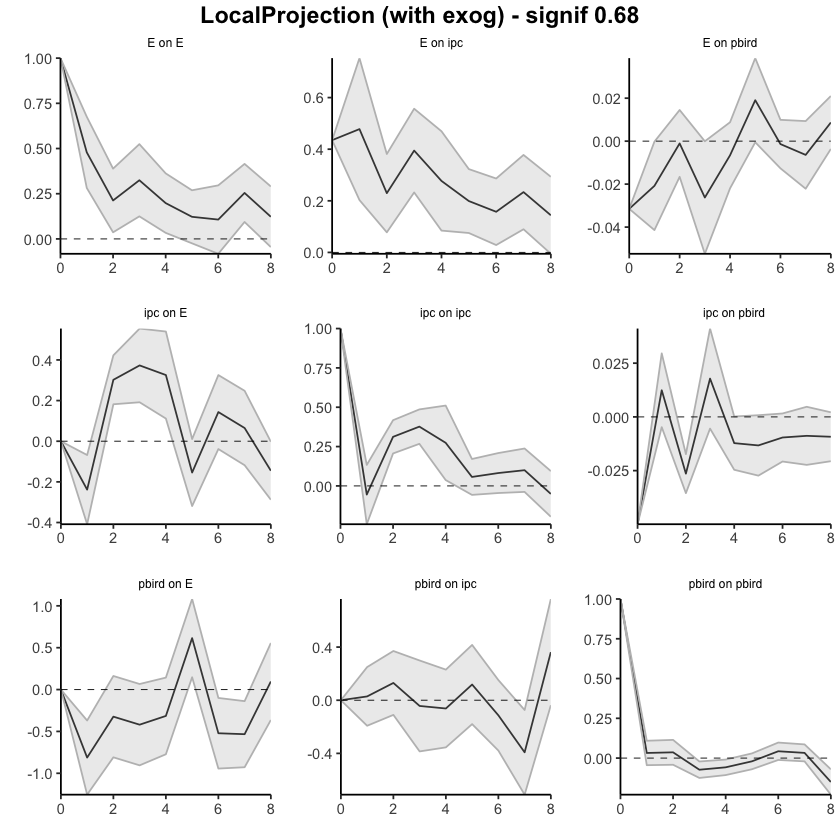

In [20]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.0000000
20,ipc,E,1,-0.23820072,-0.40842373,-0.0679777
21,ipc,E,2,0.06402706,-0.22658453,0.3546386
22,ipc,E,3,0.43706738,-0.03490643,0.9090412
23,ipc,E,4,0.76275212,0.07667730,1.4488269
24,ipc,E,5,0.60853871,-0.24245928,1.4595367
25,ipc,E,6,0.75202866,-0.28098159,1.7850389
26,ipc,E,7,0.81703062,-0.39911328,2.0331745
27,ipc,E,8,0.67173775,-0.68713538,2.0306109


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.000000000
38,pbird,E,1,-0.8124281,-1.255235,-0.369621137
39,pbird,E,2,-1.1359827,-2.064537,-0.207428340
40,pbird,E,3,-1.5554199,-2.969711,-0.141129203
41,pbird,E,4,-1.8703885,-3.742499,0.001722042
42,pbird,E,5,-1.2559582,-3.595437,1.083520631
43,pbird,E,6,-1.7778230,-4.539109,0.983462725
44,pbird,E,7,-2.3108726,-5.466815,0.845069568
45,pbird,E,8,-2.2143067,-5.830390,1.401776959


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4349947,0.4349947,0.4349947
2,E,ipc,1,0.9128601,0.6378223,1.1878980
3,E,ipc,2,1.1424589,0.7156697,1.5692481
4,E,ipc,3,1.5370389,0.9480537,2.1260241
5,E,ipc,4,1.8140385,1.0326279,2.5954491
6,E,ipc,5,2.0130939,1.1078915,2.9182963
7,E,ipc,6,2.1705807,1.1364448,3.2047165
8,E,ipc,7,2.4043225,1.2261913,3.5824536
9,E,ipc,8,2.5481696,1.2208915,3.8754476


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,0.02865061,-0.1921075,0.2494087
48,pbird,ipc,2,0.15873655,-0.3023929,0.6198660
49,pbird,ipc,3,0.11565731,-0.6875971,0.9189117
50,pbird,ipc,4,0.05345551,-1.0422933,1.1492043
51,pbird,ipc,5,0.17157826,-1.2221456,1.5653021
52,pbird,ipc,6,0.05799922,-1.6010466,1.7170450
53,pbird,ipc,7,-0.33404584,-2.3116354,1.6435437
54,pbird,ipc,8,0.02802076,-2.3493889,2.4054304


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.03149282,-0.03149282,-0.031492818
11,E,pbird,1,-0.05230033,-0.07288345,-0.031717213
12,E,pbird,2,-0.05335992,-0.08949520,-0.017224643
13,E,pbird,3,-0.07960176,-0.14191926,-0.017284265
14,E,pbird,4,-0.08618472,-0.16388118,-0.008488254
15,E,pbird,5,-0.06712531,-0.16440445,0.030153822
16,E,pbird,6,-0.06849177,-0.17705949,0.040075964
17,E,pbird,7,-0.07489138,-0.19919567,0.049412901
18,E,pbird,8,-0.06619946,-0.20283074,0.070431828


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.04993906,-0.04993906,-0.049939063
29,ipc,pbird,1,-0.03754849,-0.05471862,-0.020378349
30,ipc,pbird,2,-0.06395990,-0.09021018,-0.037709616
31,ipc,pbird,3,-0.04612809,-0.09565372,0.003397542
32,ipc,pbird,4,-0.05833469,-0.12025721,0.003587835
33,ipc,pbird,5,-0.07160799,-0.14758799,0.004372021
34,ipc,pbird,6,-0.08119252,-0.16834985,0.005964812
35,ipc,pbird,7,-0.09000050,-0.19067140,0.010670404
36,ipc,pbird,8,-0.09924058,-0.21128482,0.012803667


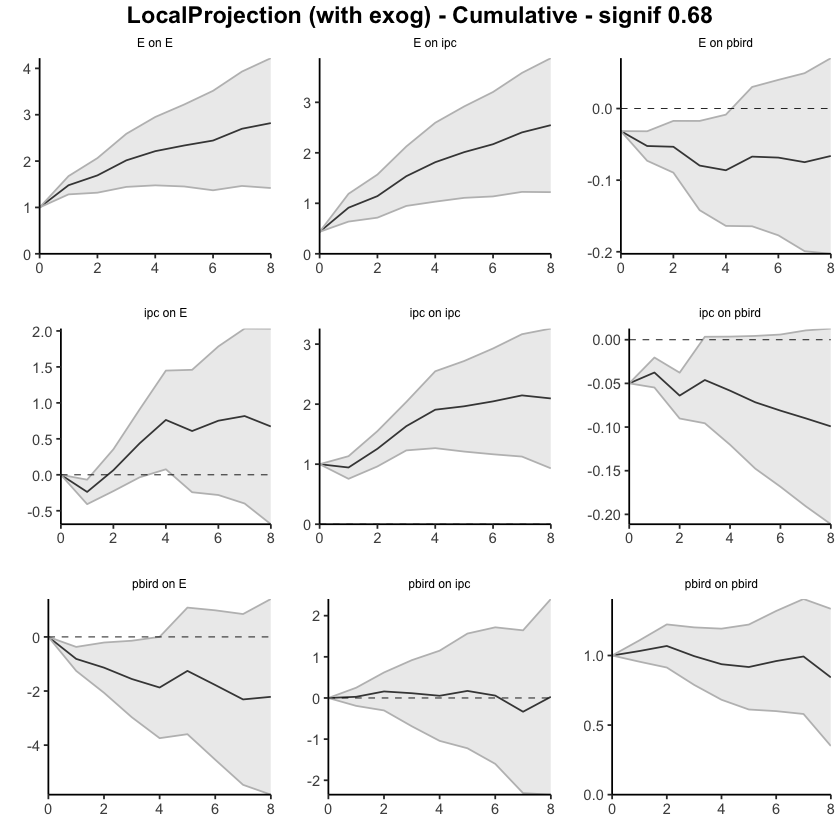

In [21]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas 5 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4350         0.4350       1.0000
         1              0.9129         0.6173       1.4788
         2              1.1425         0.6755       1.6914
         3              1.5370         0.7625       2.0159
         4              1.8140         0.8194       2.2140
         5              2.0131         0.8617       2.3363
         6              2.1706         0.8884       2.4433
         7              2.4043         0.8913       2.6975
         8              2.5482         0.9037       2.8198
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4350             0.4350
                  0.4779             0.1823
                  0.2296             0.0582
                  0.3946             0.0870
                  0.2770       

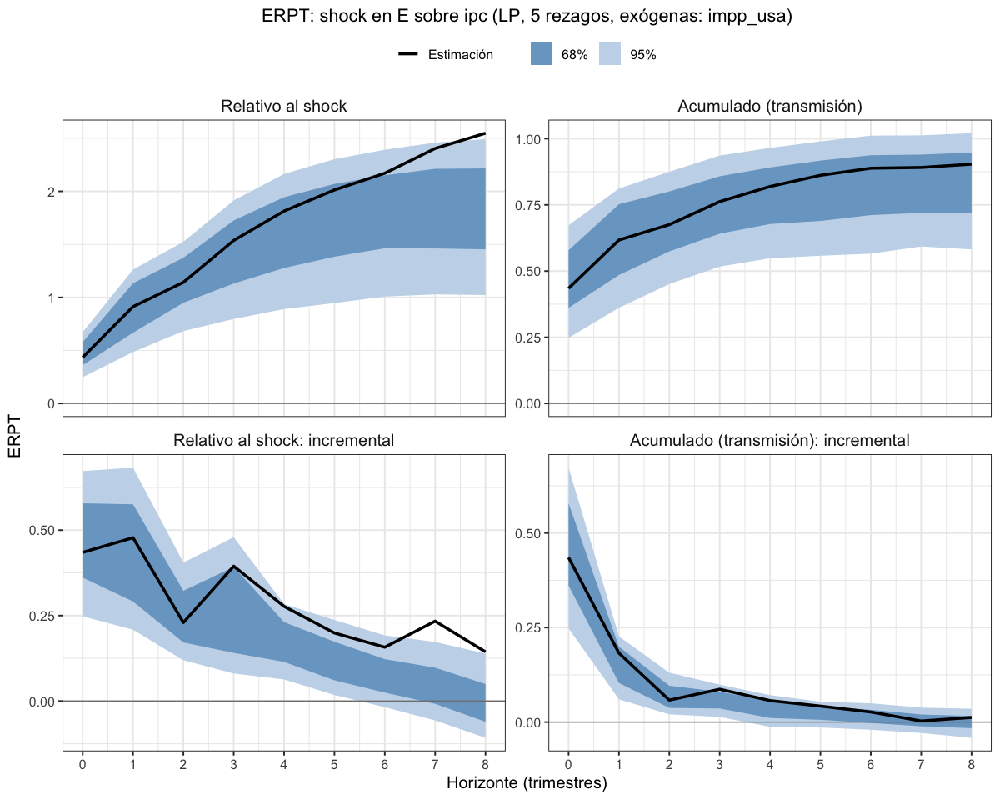

In [29]:
# impp_usa exógena, 5 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 5, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa_exog_p5")

### impp_usa 1950 a 1974 - Todas endógenas - Selected orders: 1 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,99,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,0.58449874,0.5844987,0.58449874
2,impp_usa,E,1,-0.12235411,-0.4580818,0.21337354
3,impp_usa,E,2,-0.41108687,-0.7682542,-0.05391952
4,impp_usa,E,3,-0.67688149,-1.0065234,-0.34723957
5,impp_usa,E,4,-0.76493133,-1.2407792,-0.28908348
6,impp_usa,E,5,-0.40856222,-0.7145866,-0.10253783
7,impp_usa,E,6,-0.04203338,-0.7079272,0.62386044
8,impp_usa,E,7,0.14517417,-0.4953240,0.78567232
9,impp_usa,E,8,-0.53221431,-0.9964271,-0.06800148


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.00000000,0.00000000
65,ipc,E,1,0.01676176,-0.15235207,0.18587560
66,ipc,E,2,-0.02972027,-0.19094040,0.13149987
67,ipc,E,3,-0.22249539,-0.40291883,-0.04207195
68,ipc,E,4,-0.01019862,-0.08488443,0.06448719
69,ipc,E,5,-0.11022122,-0.17939149,-0.04105096
70,ipc,E,6,-0.16150107,-0.31050996,-0.01249218
71,ipc,E,7,-0.42776383,-0.67631098,-0.17921669
72,ipc,E,8,-0.43618694,-0.68228428,-0.19008961


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.00000000
92,pbird,E,1,-0.31627695,-0.7983848,0.16583091
93,pbird,E,2,-0.36391079,-0.7493623,0.02154071
94,pbird,E,3,0.14511913,-0.2079578,0.49819603
95,pbird,E,4,0.51382948,0.1013725,0.92628641
96,pbird,E,5,1.10600075,0.4178230,1.79417852
97,pbird,E,6,-0.03071724,-0.4039029,0.34246845
98,pbird,E,7,-0.34763400,-1.1350152,0.43974722
99,pbird,E,8,-0.59057221,-0.9849123,-0.19623213


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.0000000,0.00000000,0.000000000
101,pbird,ipc,1,0.1228006,0.02130777,0.224293427
102,pbird,ipc,2,-0.1534402,-0.30248442,-0.004395916
103,pbird,ipc,3,0.2211024,0.06501054,0.377194274
104,pbird,ipc,4,0.1616433,-0.02144998,0.344736632
105,pbird,ipc,5,0.1818850,-0.03511870,0.398888698
106,pbird,ipc,6,0.1468263,-0.02046070,0.314113247
107,pbird,ipc,7,0.2454263,0.08989216,0.400960517
108,pbird,ipc,8,0.2842312,0.05039474,0.518067623


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.0162417279,0.016241728,0.016241728
47,E,pbird,1,-0.0484469801,-0.098399144,0.001505184
48,E,pbird,2,-0.0069568757,-0.033106860,0.019193109
49,E,pbird,3,-0.0746603852,-0.106924679,-0.042396091
50,E,pbird,4,-0.0067089984,-0.037701390,0.024283393
51,E,pbird,5,0.0657038229,0.039649413,0.091758233
52,E,pbird,6,0.0007738396,-0.018040826,0.019588505
53,E,pbird,7,0.0192397372,-0.003045004,0.041524478
54,E,pbird,8,-0.0034470450,-0.024651551,0.017757461


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.045800909,0.04580091,0.04580091
20,impp_usa,pbird,1,0.072495960,-0.06134941,0.20634133
21,impp_usa,pbird,2,0.056952650,-0.05201230,0.16591759
22,impp_usa,pbird,3,-0.006426199,-0.11082112,0.09796872
23,impp_usa,pbird,4,-0.082325262,-0.18168887,0.01703835
24,impp_usa,pbird,5,-0.184764933,-0.33318849,-0.03634138
25,impp_usa,pbird,6,-0.163186676,-0.34807073,0.02169738
26,impp_usa,pbird,7,-0.193949621,-0.38035262,-0.00754662
27,impp_usa,pbird,8,-0.185333220,-0.43116316,0.06049672


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.13517107,-0.13517107,-0.13517107
74,ipc,pbird,1,-0.09973752,-0.12599891,-0.07347613
75,ipc,pbird,2,-0.11414540,-0.15348352,-0.07480727
76,ipc,pbird,3,0.03868535,-0.01602732,0.09339802
77,ipc,pbird,4,0.01957612,-0.02128017,0.06043240
78,ipc,pbird,5,0.01513605,-0.01830458,0.04857667
79,ipc,pbird,6,0.08893192,0.04690724,0.13095660
80,ipc,pbird,7,0.07371314,0.05355734,0.09386895
81,ipc,pbird,8,-0.02367222,-0.06827751,0.02093308


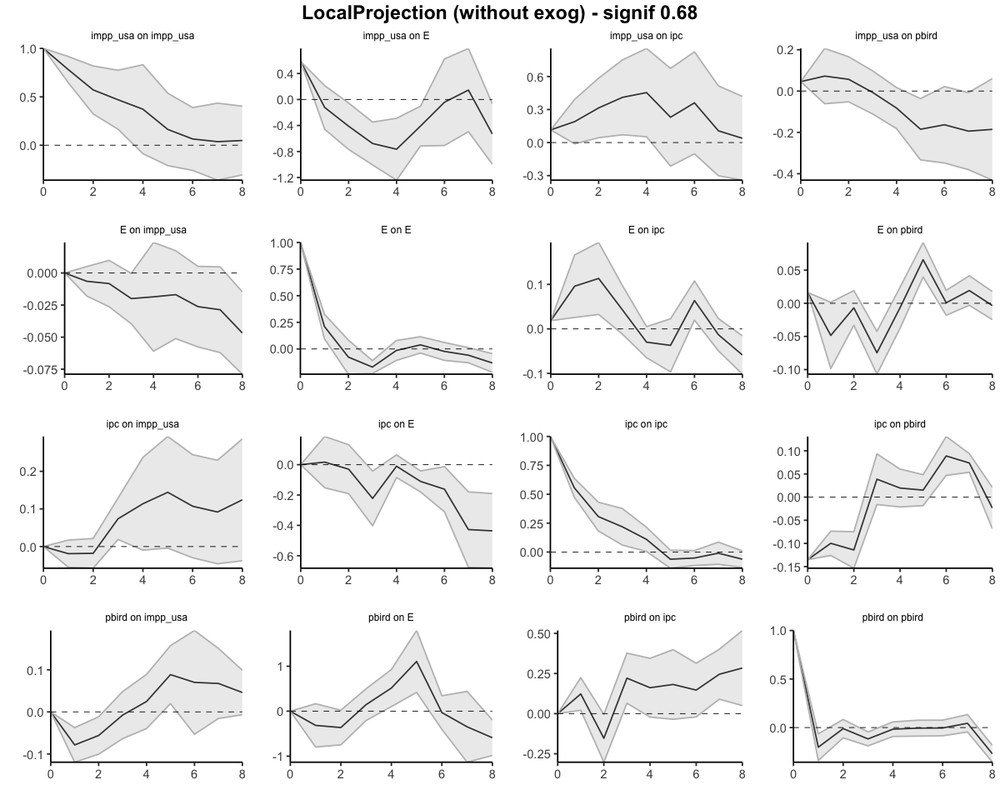

In [35]:
res <- run_lp_model(df_ERPT_Arg_1950_74, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,99,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,0.58449874,0.5844987,0.584498744
2,impp_usa,E,1,0.46214464,0.1264170,0.797872281
3,impp_usa,E,2,0.05105777,-0.6418372,0.743952756
4,impp_usa,E,3,-0.62582372,-1.6483606,0.396713185
5,impp_usa,E,4,-1.39075505,-2.8891398,0.107629701
6,impp_usa,E,5,-1.79931727,-3.6037264,0.005091871
7,impp_usa,E,6,-1.84135065,-4.3116536,0.628952314
8,impp_usa,E,7,-1.69617648,-4.8069776,1.414624633
9,impp_usa,E,8,-2.22839078,-5.8034047,1.346623156


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.0000000,0.00000000
65,ipc,E,1,0.01676176,-0.1523521,0.18587560
66,ipc,E,2,-0.01295850,-0.3432925,0.31737547
67,ipc,E,3,-0.23545389,-0.7462113,0.27530352
68,ipc,E,4,-0.24565251,-0.8310957,0.33979072
69,ipc,E,5,-0.35587374,-1.0104872,0.29873976
70,ipc,E,6,-0.51737481,-1.3209972,0.28624758
71,ipc,E,7,-0.94513864,-1.9973082,0.10703090
72,ipc,E,8,-1.38132558,-2.6795925,-0.08305871


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.0000000
92,pbird,E,1,-0.31627695,-0.7983848,0.1658309
93,pbird,E,2,-0.68018774,-1.5477471,0.1873716
94,pbird,E,3,-0.53506861,-1.7557049,0.6855676
95,pbird,E,4,-0.02123914,-1.6543323,1.6118540
96,pbird,E,5,1.08476161,-1.2365093,3.4060326
97,pbird,E,6,1.05404437,-1.6404123,3.7485010
98,pbird,E,7,0.70641037,-2.7754275,4.1882482
99,pbird,E,8,0.11583817,-3.7603398,3.9920161


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.0000000
101,pbird,ipc,1,0.12280060,0.02130777,0.2242934
102,pbird,ipc,2,-0.03063957,-0.28117665,0.2198975
103,pbird,ipc,3,0.19046284,-0.21616611,0.5970918
104,pbird,ipc,4,0.35210616,-0.23761609,0.9418284
105,pbird,ipc,5,0.53399116,-0.27273479,1.3407171
106,pbird,ipc,6,0.68081744,-0.29319549,1.6548304
107,pbird,ipc,7,0.92624378,-0.20330333,2.0557909
108,pbird,ipc,8,1.21047496,-0.15290859,2.5738585


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.01624173,0.01624173,0.01624173
47,E,pbird,1,-0.03220525,-0.08215742,0.01774691
48,E,pbird,2,-0.03916213,-0.11526428,0.03694002
49,E,pbird,3,-0.11382251,-0.22218896,-0.00545607
50,E,pbird,4,-0.12053151,-0.25989035,0.01882732
51,E,pbird,5,-0.05482769,-0.22024093,0.11058556
52,E,pbird,6,-0.05405385,-0.23828176,0.13017406
53,E,pbird,7,-0.03481411,-0.24132676,0.17169854
54,E,pbird,8,-0.03826116,-0.26597831,0.18945600


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.04580091,0.04580091,0.04580091
20,impp_usa,pbird,1,0.11829687,-0.01554850,0.25214224
21,impp_usa,pbird,2,0.17524952,-0.06756080,0.41805984
22,impp_usa,pbird,3,0.16882332,-0.17838192,0.51602856
23,impp_usa,pbird,4,0.08649806,-0.36007079,0.53306691
24,impp_usa,pbird,5,-0.09826688,-0.69325928,0.49672553
25,impp_usa,pbird,6,-0.26145355,-1.04133001,0.51842291
26,impp_usa,pbird,7,-0.45540317,-1.42168263,0.51087629
27,impp_usa,pbird,8,-0.64073639,-1.85284579,0.57137301


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.1351711,-0.1351711,-0.13517107
74,ipc,pbird,1,-0.2349086,-0.2611700,-0.20864720
75,ipc,pbird,2,-0.3490540,-0.4146535,-0.28345447
76,ipc,pbird,3,-0.3103686,-0.4306808,-0.19005645
77,ipc,pbird,4,-0.2907925,-0.4519610,-0.12962405
78,ipc,pbird,5,-0.2756565,-0.4702656,-0.08104737
79,ipc,pbird,6,-0.1867245,-0.4233583,0.04990922
80,ipc,pbird,7,-0.1130114,-0.3698010,0.14377817
81,ipc,pbird,8,-0.1366836,-0.4380785,0.16471125


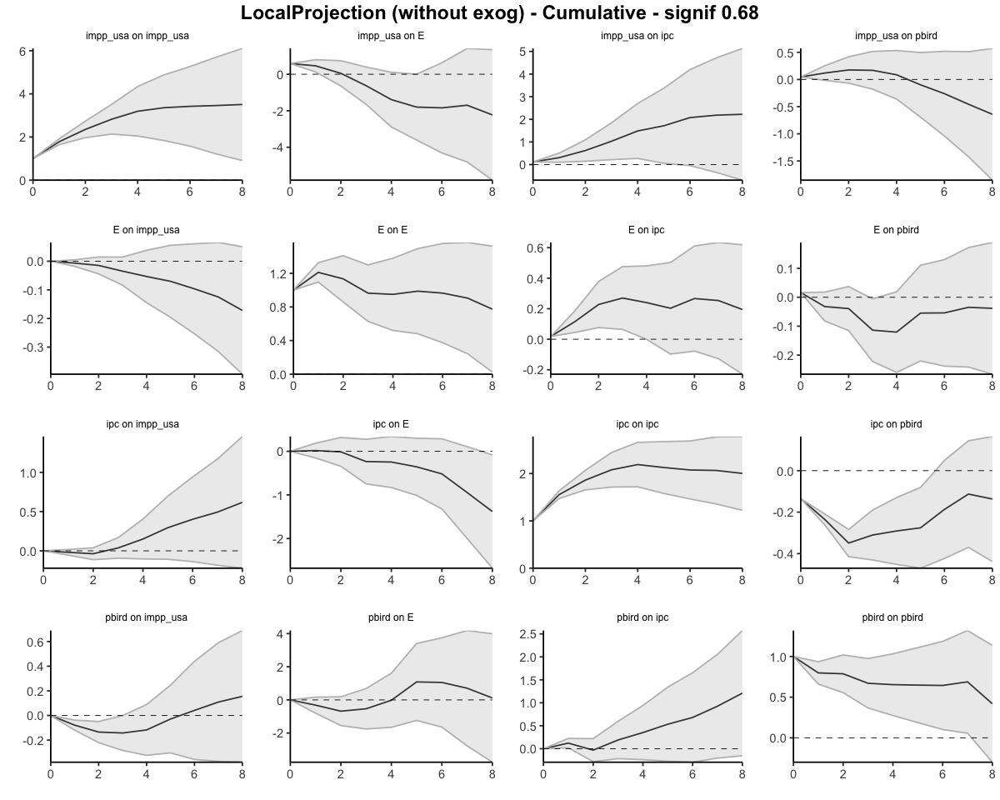

In [36]:
res <- run_lp_model(df_ERPT_Arg_1950_74, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.0185         0.0185       1.0000
         1              0.1145         0.0945       1.2112
         2              0.2278         0.2008       1.1344
         3              0.2701         0.2801       0.9641
         4              0.2401         0.2529       0.9497
         5              0.2031         0.2056       0.9877
         6              0.2668         0.2767       0.9643
         7              0.2537         0.2802       0.9055
         8              0.1950         0.2520       0.7736
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.0185             0.0185
                  0.0960             0.0760
                  0.1134             0.1063
                  0.0422             0.0793
                 -0.0299            -0.0272
       

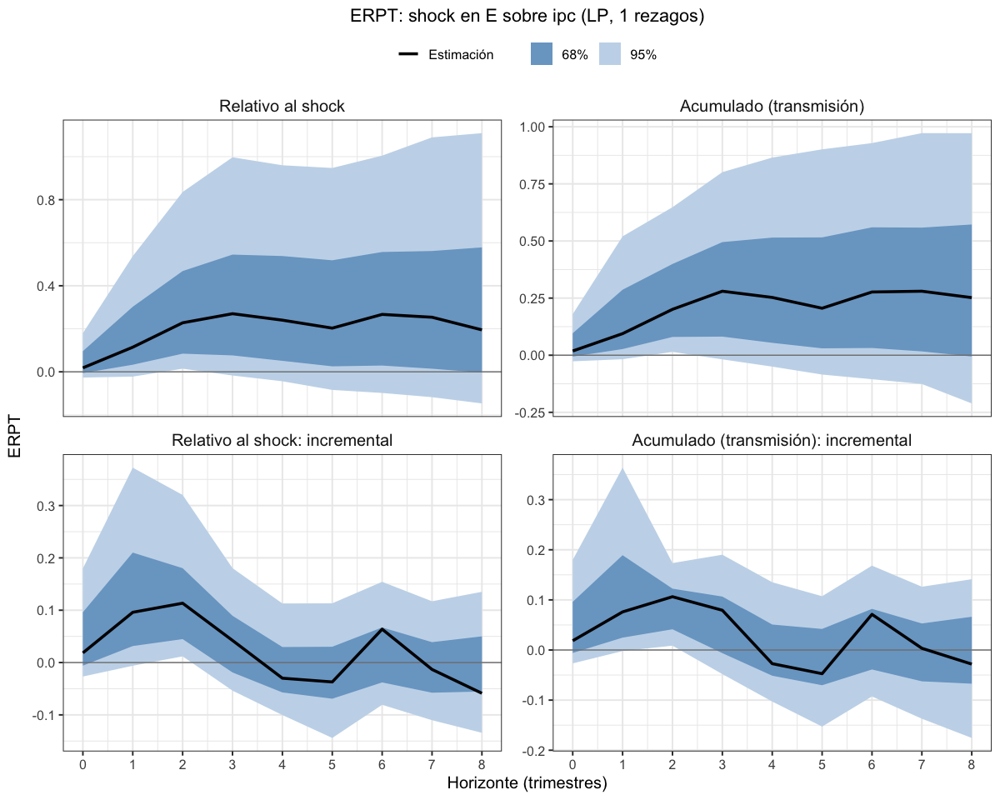

In [37]:
# Todas endógenas, 1 rezago
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_74, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa74_endog_p1")

### impp_usa 1950 a 1974 - 1 exógena y el resto endógenas - Selected orders: 1 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,99,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.000000000,0.00000000,0.00000000
20,ipc,E,1,0.016453013,-0.15313146,0.18603748
21,ipc,E,2,-0.030075516,-0.19167193,0.13152090
22,ipc,E,3,-0.222353725,-0.40312184,-0.04158561
23,ipc,E,4,-0.009697021,-0.08478547,0.06539143
24,ipc,E,5,-0.109141547,-0.17898361,-0.03929948
25,ipc,E,6,-0.161531054,-0.31090425,-0.01215786
26,ipc,E,7,-0.428103194,-0.67741898,-0.17878741
27,ipc,E,8,-0.436763460,-0.68324575,-0.19028117


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.00000000
38,pbird,E,1,-0.31627695,-0.7983848,0.16583091
39,pbird,E,2,-0.36391079,-0.7493623,0.02154071
40,pbird,E,3,0.14511913,-0.2079578,0.49819603
41,pbird,E,4,0.51382948,0.1013725,0.92628641
42,pbird,E,5,1.10600075,0.4178230,1.79417852
43,pbird,E,6,-0.03071724,-0.4039029,0.34246845
44,pbird,E,7,-0.34763400,-1.1350152,0.43974722
45,pbird,E,8,-0.59057221,-0.9849123,-0.19623213


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.02029944,0.02029944,0.020299440
2,E,ipc,1,0.09713221,0.02657782,0.167686607
3,E,ipc,2,0.11379342,0.03248217,0.195104682
4,E,ipc,3,0.04282116,-0.01202263,0.097664944
5,E,ipc,4,-0.02956486,-0.06487552,0.005745793
6,E,ipc,5,-0.03701925,-0.09705261,0.023014119
7,E,ipc,6,0.06380356,0.01949590,0.108111224
8,E,ipc,7,-0.01296207,-0.04953206,0.023607906
9,E,ipc,8,-0.05857492,-0.10207901,-0.015070831


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.00000000,0.000000000
47,pbird,ipc,1,0.1228006,0.02130777,0.224293427
48,pbird,ipc,2,-0.1534402,-0.30248442,-0.004395916
49,pbird,ipc,3,0.2211024,0.06501054,0.377194274
50,pbird,ipc,4,0.1616433,-0.02144998,0.344736632
51,pbird,ipc,5,0.1818850,-0.03511870,0.398888698
52,pbird,ipc,6,0.1468263,-0.02046070,0.314113247
53,pbird,ipc,7,0.2454263,0.08989216,0.400960517
54,pbird,ipc,8,0.2842312,0.05039474,0.518067623


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.0168794785,0.016879479,0.016879479
11,E,pbird,1,-0.0488091143,-0.098931346,0.001313118
12,E,pbird,2,-0.0071761857,-0.033482228,0.019129857
13,E,pbird,3,-0.0746928080,-0.107121262,-0.042264354
14,E,pbird,4,-0.0066876350,-0.037821613,0.024446343
15,E,pbird,5,0.0657264076,0.039538008,0.091914807
16,E,pbird,6,0.0009336269,-0.018029643,0.019896897
17,E,pbird,7,0.0194143539,-0.002986899,0.041815607
18,E,pbird,8,-0.0037296430,-0.025093063,0.017633777


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.13419487,-0.13419487,-0.13419487
29,ipc,pbird,1,-0.09993462,-0.12633022,-0.07353902
30,ipc,pbird,2,-0.11415599,-0.15358643,-0.07472555
31,ipc,pbird,3,0.03857134,-0.01621146,0.09335413
32,ipc,pbird,4,0.01956003,-0.02136955,0.06048961
33,ipc,pbird,5,0.01513029,-0.01839026,0.04865085
34,ipc,pbird,6,0.08892797,0.04682462,0.13103131
35,ipc,pbird,7,0.07375633,0.05351295,0.09399970
36,ipc,pbird,8,-0.02393565,-0.06862574,0.02075445


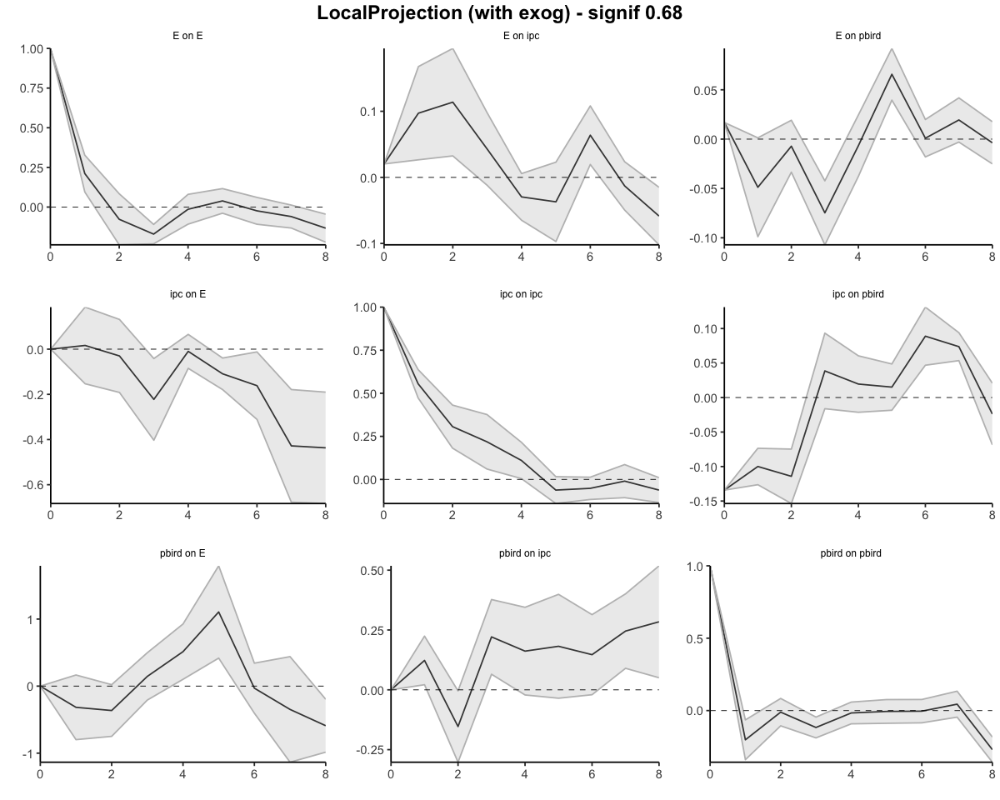

In [38]:
res <- run_lp_model(df_ERPT_Arg_1950_74, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,99,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.0000000,0.00000000
20,ipc,E,1,0.01645301,-0.1531315,0.18603748
21,ipc,E,2,-0.01362250,-0.3448034,0.31755838
22,ipc,E,3,-0.23597623,-0.7479252,0.27597277
23,ipc,E,4,-0.24567325,-0.8327107,0.34136420
24,ipc,E,5,-0.35481480,-1.0116943,0.30206472
25,ipc,E,6,-0.51634585,-1.3225986,0.28990686
26,ipc,E,7,-0.94444904,-2.0000175,0.11111946
27,ipc,E,8,-1.38121250,-2.6832633,-0.07916171


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.0000000
38,pbird,E,1,-0.31627695,-0.7983848,0.1658309
39,pbird,E,2,-0.68018774,-1.5477471,0.1873716
40,pbird,E,3,-0.53506861,-1.7557049,0.6855676
41,pbird,E,4,-0.02123914,-1.6543323,1.6118540
42,pbird,E,5,1.08476161,-1.2365093,3.4060326
43,pbird,E,6,1.05404437,-1.6404123,3.7485010
44,pbird,E,7,0.70641037,-2.7754275,4.1882482
45,pbird,E,8,0.11583817,-3.7603398,3.9920161


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.02029944,0.020299440,0.02029944
2,E,ipc,1,0.11743166,0.046877263,0.18798605
3,E,ipc,2,0.23122508,0.079359429,0.38309073
4,E,ipc,3,0.27404624,0.067336799,0.48075567
5,E,ipc,4,0.24448137,0.002461281,0.48650147
6,E,ipc,5,0.20746213,-0.094591330,0.50951559
7,E,ipc,6,0.27126569,-0.075095427,0.61762681
8,E,ipc,7,0.25830362,-0.124627483,0.64123472
9,E,ipc,8,0.19972870,-0.226706493,0.62616388


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.0000000
47,pbird,ipc,1,0.12280060,0.02130777,0.2242934
48,pbird,ipc,2,-0.03063957,-0.28117665,0.2198975
49,pbird,ipc,3,0.19046284,-0.21616611,0.5970918
50,pbird,ipc,4,0.35210616,-0.23761609,0.9418284
51,pbird,ipc,5,0.53399116,-0.27273479,1.3407171
52,pbird,ipc,6,0.68081744,-0.29319549,1.6548304
53,pbird,ipc,7,0.92624378,-0.20330333,2.0557909
54,pbird,ipc,8,1.21047496,-0.15290859,2.5738585


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.01687948,0.01687948,0.016879479
11,E,pbird,1,-0.03192964,-0.08205187,0.018192596
12,E,pbird,2,-0.03910582,-0.11553410,0.037322453
13,E,pbird,3,-0.11379863,-0.22265536,-0.004941901
14,E,pbird,4,-0.12048626,-0.26047697,0.019504442
15,E,pbird,5,-0.05475986,-0.22093896,0.111419248
16,E,pbird,6,-0.05382623,-0.23896861,0.131316145
17,E,pbird,7,-0.03441188,-0.24195550,0.173131752
18,E,pbird,8,-0.03814152,-0.26704857,0.190765529


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.1341949,-0.1341949,-0.13419487
29,ipc,pbird,1,-0.2341295,-0.2605251,-0.20773389
30,ipc,pbird,2,-0.3482855,-0.4141115,-0.28245944
31,ipc,pbird,3,-0.3097141,-0.4303230,-0.18910532
32,ipc,pbird,4,-0.2901541,-0.4516925,-0.12861570
33,ipc,pbird,5,-0.2750238,-0.4700828,-0.07996485
34,ipc,pbird,6,-0.1860959,-0.4232582,0.05106646
35,ipc,pbird,7,-0.1123395,-0.3697452,0.14506616
36,ipc,pbird,8,-0.1362752,-0.4383709,0.16582060


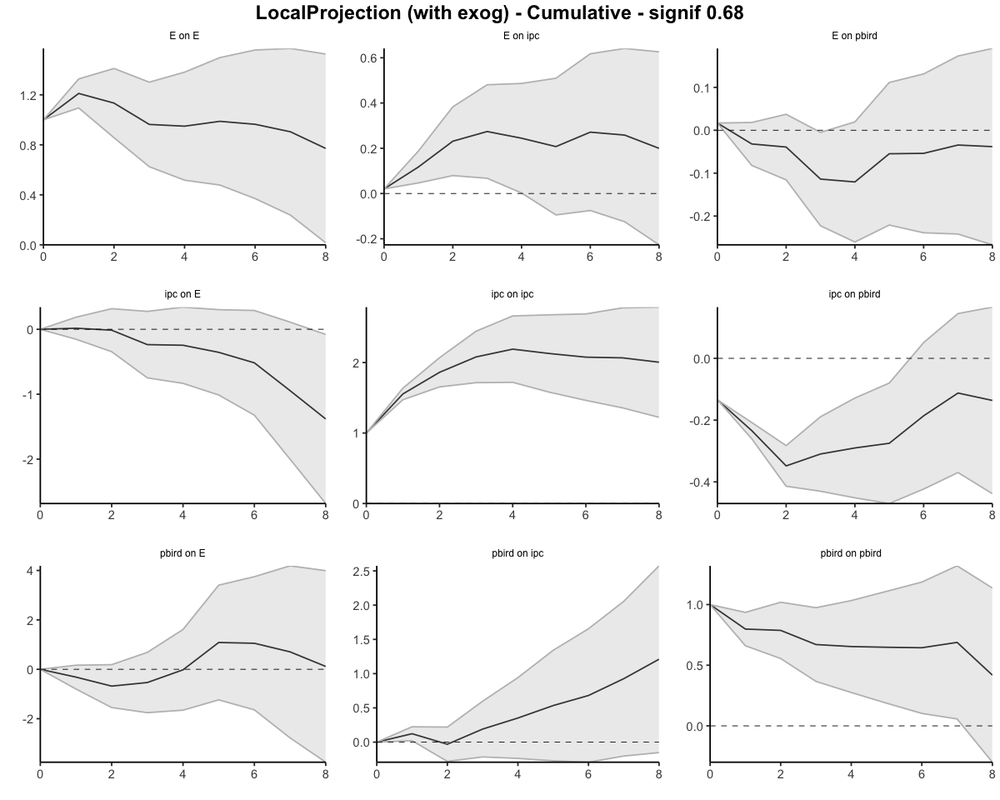

In [39]:
res <- run_lp_model(df_ERPT_Arg_1950_74, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.0203         0.0203       1.0000
         1              0.1174         0.0970       1.2110
         2              0.2312         0.2039       1.1338
         3              0.2740         0.2845       0.9632
         4              0.2445         0.2576       0.9492
         5              0.2075         0.2100       0.9880
         6              0.2713         0.2813       0.9643
         7              0.2583         0.2856       0.9043
         8              0.1997         0.2590       0.7711
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.0203             0.0203
                  0.0971             0.0767
                  0.1138             0.1070
                  0.0428             0.0806
                 -0.0296       

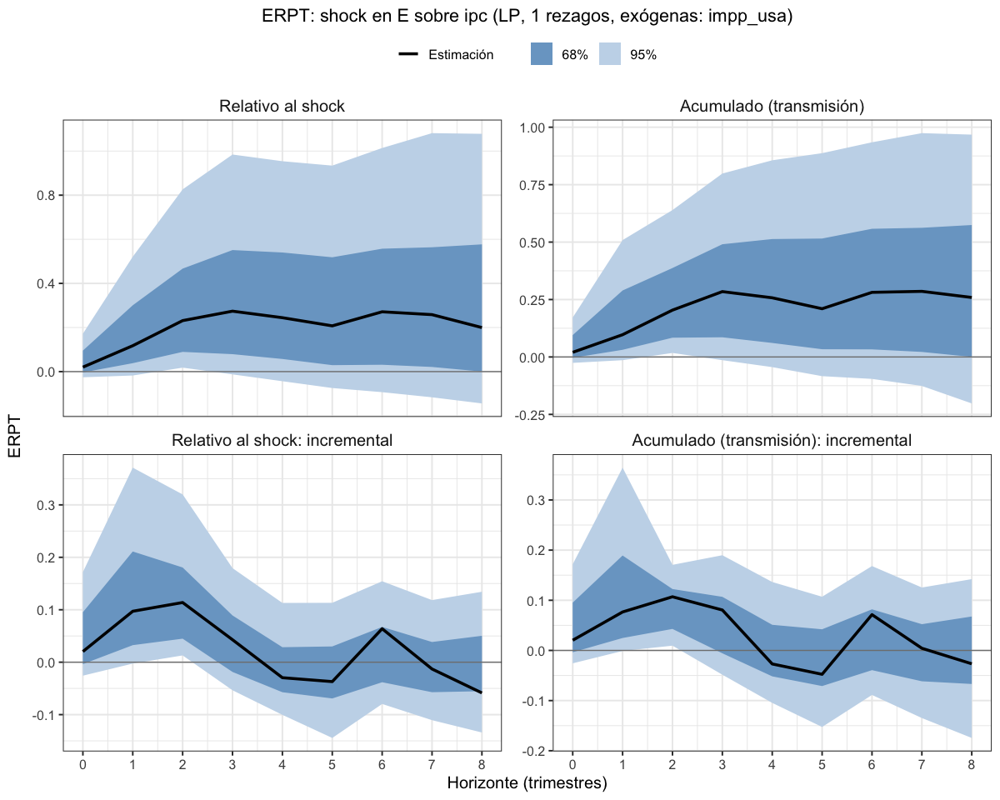

In [74]:
# impp_usa exógena, 1 rezago
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_74, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa74_exog_p1")

### impp_usa 1950 a 1975 - Todas endógenas - Selected orders: 1 y 3 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.3590101,-0.3590101,-0.3590101
2,impp_usa,E,1,-0.4346467,-0.6625781,-0.2067154
3,impp_usa,E,2,-0.1064382,-0.3202129,0.1073366
4,impp_usa,E,3,1.0246809,-0.1767961,2.2261579
5,impp_usa,E,4,2.1713400,0.9143404,3.4283396
6,impp_usa,E,5,2.7188841,1.2036437,4.2341246
7,impp_usa,E,6,2.8975283,1.6036317,4.1914249
8,impp_usa,E,7,3.2361196,1.5806262,4.8916130
9,impp_usa,E,8,2.2742021,-4.9166293,9.4650335


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.0000000,0.00000000
65,ipc,E,1,0.47184625,0.3167383,0.62695424
66,ipc,E,2,0.44389978,-0.2418367,1.12963625
67,ipc,E,3,0.13986881,-0.6035627,0.88330030
68,ipc,E,4,-0.04542994,-0.2755689,0.18470900
69,ipc,E,5,-0.19949116,-0.3474479,-0.05153444
70,ipc,E,6,-0.51898705,-0.7964600,-0.24151411
71,ipc,E,7,-0.44046475,-0.7179514,-0.16297808
72,ipc,E,8,-0.13714752,-0.6953105,0.42101545


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.000000000
92,pbird,E,1,-0.09978467,-0.5701697,0.370600362
93,pbird,E,2,-0.37933554,-0.7488026,-0.009868474
94,pbird,E,3,0.01192277,-0.4064275,0.430273013
95,pbird,E,4,0.12670566,-0.3315865,0.584997780
96,pbird,E,5,0.96601988,0.1106911,1.821348690
97,pbird,E,6,-0.31180355,-0.6698708,0.046263720
98,pbird,E,7,-0.43118334,-1.2108446,0.348477888
99,pbird,E,8,-0.61959225,-1.2250769,-0.014107595


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.00000000
101,pbird,ipc,1,0.13879738,0.02585621,0.25173854
102,pbird,ipc,2,-0.13885959,-0.31188433,0.03416515
103,pbird,ipc,3,0.26463047,0.09750250,0.43175843
104,pbird,ipc,4,0.09364804,-0.08707967,0.27437574
105,pbird,ipc,5,0.02786964,-0.19624569,0.25198498
106,pbird,ipc,6,-0.02147716,-0.21502414,0.17206983
107,pbird,ipc,7,0.24140279,0.05796950,0.42483609
108,pbird,ipc,8,0.22480911,-0.09748105,0.54709927


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.006337096,0.0063370959,0.0063370959
47,E,pbird,1,-0.030089665,-0.0618960415,0.0017167109
48,E,pbird,2,-0.023420371,-0.0472852045,0.0004444623
49,E,pbird,3,-0.044899043,-0.0837523803,-0.0060457065
50,E,pbird,4,-0.003248178,-0.0387693690,0.0322730135
51,E,pbird,5,0.065573807,0.0363027671,0.0948448479
52,E,pbird,6,0.010637870,-0.0127166810,0.0339924210
53,E,pbird,7,0.026091890,-0.0004615334,0.0526453127
54,E,pbird,8,-0.006076271,-0.0315074549,0.0193549135


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.12500925,0.12500925,0.12500925
20,impp_usa,pbird,1,0.09623430,0.03222951,0.16023910
21,impp_usa,pbird,2,0.11187871,0.04814419,0.17561323
22,impp_usa,pbird,3,-0.02165226,-0.05564986,0.01234535
23,impp_usa,pbird,4,-0.11583567,-0.14460564,-0.08706570
24,impp_usa,pbird,5,-0.21460041,-0.26180019,-0.16740063
25,impp_usa,pbird,6,-0.20556820,-0.26767477,-0.14346162
26,impp_usa,pbird,7,-0.20469985,-0.29436145,-0.11503824
27,impp_usa,pbird,8,-0.16774821,-0.29621930,-0.03927711


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.120794823,-0.12079482,-0.120794823
74,ipc,pbird,1,-0.034567992,-0.06199611,-0.007139872
75,ipc,pbird,2,-0.106670791,-0.14289281,-0.070448775
76,ipc,pbird,3,0.033159714,-0.02399223,0.090311660
77,ipc,pbird,4,0.017953139,-0.02235931,0.058265584
78,ipc,pbird,5,0.009873504,-0.02413133,0.043878338
79,ipc,pbird,6,0.093138270,0.05348928,0.132787256
80,ipc,pbird,7,0.066338185,0.04685718,0.085819188
81,ipc,pbird,8,-0.019455280,-0.06076462,0.021854058


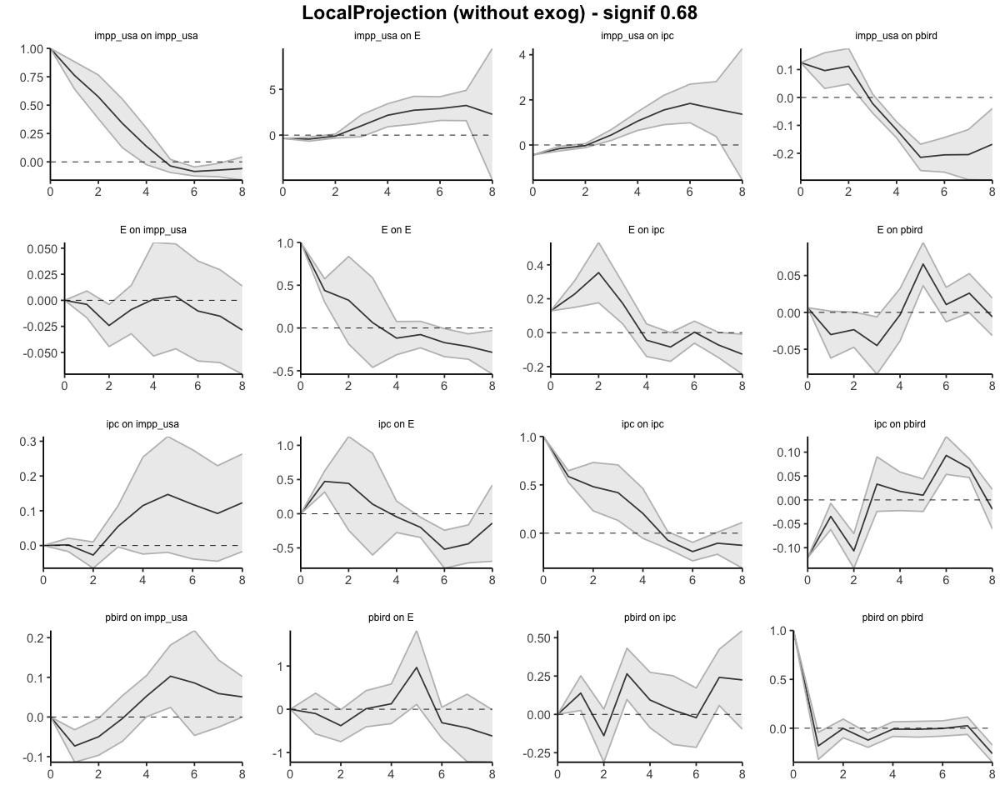

In [40]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.3590101,-0.3590101,-0.3590101
2,impp_usa,E,1,-0.7936568,-1.0215882,-0.5657255
3,impp_usa,E,2,-0.9000950,-1.3418011,-0.4583889
4,impp_usa,E,3,0.1245859,-1.5185971,1.7677690
5,impp_usa,E,4,2.2959259,-0.6042568,5.1961086
6,impp_usa,E,5,5.0148100,0.5993869,9.4302332
7,impp_usa,E,6,7.9123384,2.2030186,13.6216581
8,impp_usa,E,7,11.1484580,3.7836448,18.5132711
9,impp_usa,E,8,13.4226601,-1.1329845,27.9783046


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000,0.00000000,0.0000000
65,ipc,E,1,0.4718462,0.31673826,0.6269542
66,ipc,E,2,0.9157460,0.07490158,1.7565905
67,ipc,E,3,1.0556148,-0.52866109,2.6398908
68,ipc,E,4,1.0101849,-0.80422997,2.8245998
69,ipc,E,5,0.8106938,-1.15167784,2.7730653
70,ipc,E,6,0.2917067,-1.94813783,2.5315512
71,ipc,E,7,-0.1487581,-2.66608926,2.3685731
72,ipc,E,8,-0.2859056,-3.36139974,2.7895886


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.0000000
92,pbird,E,1,-0.09978467,-0.5701697,0.3706004
93,pbird,E,2,-0.47912022,-1.3189723,0.3607319
94,pbird,E,3,-0.46719744,-1.7253998,0.7910049
95,pbird,E,4,-0.34049178,-2.0569862,1.3760027
96,pbird,E,5,0.62552810,-1.9462952,3.1973514
97,pbird,E,6,0.31372455,-2.6161660,3.2436151
98,pbird,E,7,-0.11745879,-3.8270106,3.5920930
99,pbird,E,8,-0.73705104,-5.0520875,3.5779854


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.000000e+00,0.00000000,0.0000000
101,pbird,ipc,1,1.387974e-01,0.02585621,0.2517385
102,pbird,ipc,2,-6.221603e-05,-0.28602813,0.2859037
103,pbird,ipc,3,2.645682e-01,-0.18852563,0.7176621
104,pbird,ipc,4,3.582163e-01,-0.27560530,0.9920379
105,pbird,ipc,5,3.860859e-01,-0.47185099,1.2440228
106,pbird,ipc,6,3.646088e-01,-0.68687513,1.4160927
107,pbird,ipc,7,6.060116e-01,-0.62890563,1.8409288
108,pbird,ipc,8,8.308207e-01,-0.72638667,2.3880280


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.0063370959,0.006337096,0.006337096
47,E,pbird,1,-0.0237525694,-0.055558946,0.008053807
48,E,pbird,2,-0.0471729405,-0.102844150,0.008498269
49,E,pbird,3,-0.0920719839,-0.186596530,0.002452562
50,E,pbird,4,-0.0953201617,-0.225365899,0.034725576
51,E,pbird,5,-0.0297463542,-0.189063132,0.129570424
52,E,pbird,6,-0.0191084842,-0.201779813,0.163562845
53,E,pbird,7,0.0069834055,-0.202241347,0.216208158
54,E,pbird,8,0.0009071348,-0.233748802,0.235563071


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.12500925,0.125009255,0.12500925
20,impp_usa,pbird,1,0.22124356,0.157238762,0.28524835
21,impp_usa,pbird,2,0.33312226,0.205382948,0.46086158
22,impp_usa,pbird,3,0.31147000,0.149733084,0.47320693
23,impp_usa,pbird,4,0.19563434,0.005127447,0.38614123
24,impp_usa,pbird,5,-0.01896607,-0.256672738,0.21874060
25,impp_usa,pbird,6,-0.22453426,-0.524347513,0.07527898
26,impp_usa,pbird,7,-0.42923411,-0.818708965,-0.03975926
27,impp_usa,pbird,8,-0.59698232,-1.114928265,-0.07903637


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.12079482,-0.1207948,-0.120794823
74,ipc,pbird,1,-0.15536281,-0.1827909,-0.127934694
75,ipc,pbird,2,-0.26203361,-0.3256837,-0.198383469
76,ipc,pbird,3,-0.22887389,-0.3496760,-0.108071810
77,ipc,pbird,4,-0.21092075,-0.3720353,-0.049806225
78,ipc,pbird,5,-0.20104725,-0.3961666,-0.005927887
79,ipc,pbird,6,-0.10790898,-0.3426773,0.126859369
80,ipc,pbird,7,-0.04157079,-0.2958201,0.212678557
81,ipc,pbird,8,-0.06102607,-0.3565848,0.234532615


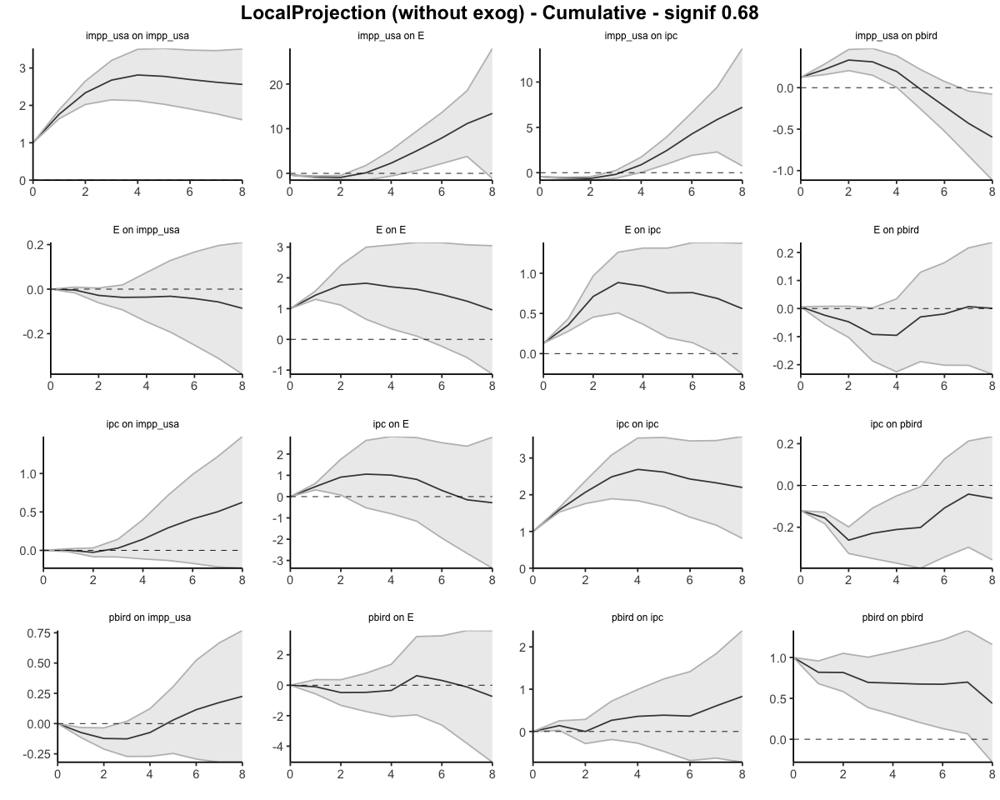

In [41]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1284         0.1284       1.0000
         1              0.3564         0.2478       1.4380
         2              0.7105         0.4031       1.7627
         3              0.8839         0.4842       1.8255
         4              0.8396         0.4919       1.7069
         5              0.7552         0.4634       1.6297
         6              0.7583         0.5200       1.4583
         7              0.6859         0.5525       1.2415
         8              0.5590         0.5844       0.9566
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1284             0.1284
                  0.2280             0.1194
                  0.3541             0.1553
                  0.1734             0.0811
                 -0.0444             0.0077
       

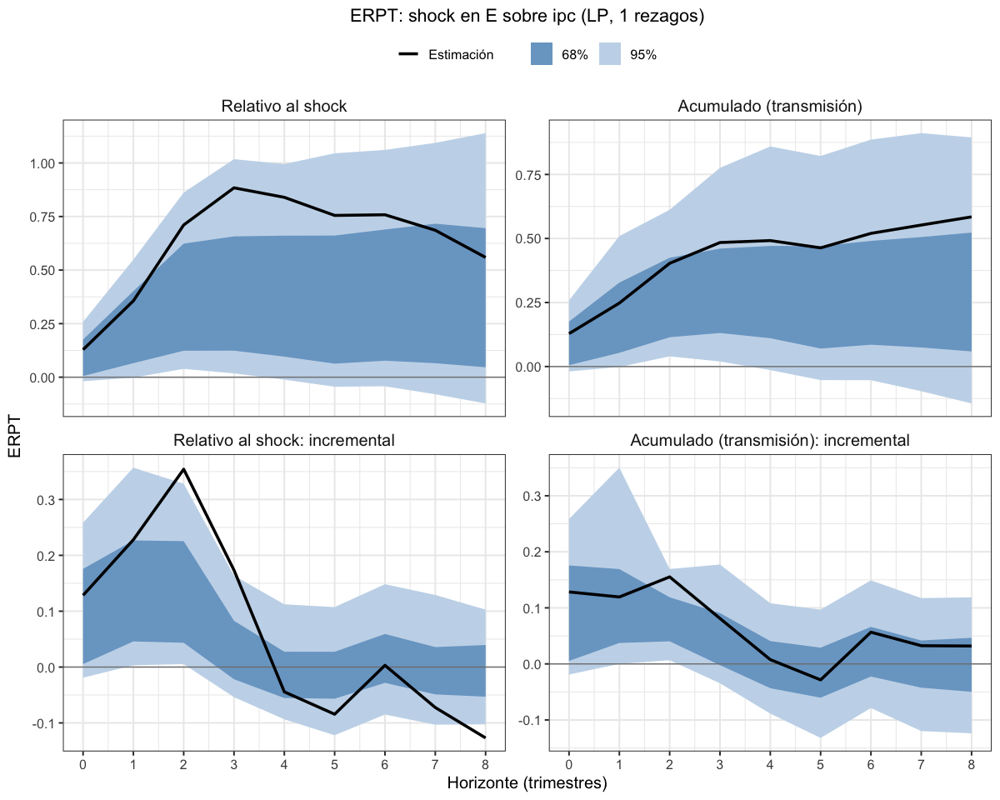

In [75]:
# Todas endógenas, 1 rezago
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_75, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa75_endog_p1")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.1837837,-0.1837837,-0.1837837
2,impp_usa,E,1,-1.2844102,-1.9016590,-0.6671613
3,impp_usa,E,2,-1.7055057,-2.8616134,-0.5493980
4,impp_usa,E,3,-1.0838086,-1.8726056,-0.2950115
5,impp_usa,E,4,0.6740717,-0.2008400,1.5489835
6,impp_usa,E,5,2.0429924,0.9943482,3.0916365
7,impp_usa,E,6,1.7674812,1.0415440,2.4934183
8,impp_usa,E,7,4.5392788,3.5455892,5.5329683
9,impp_usa,E,8,2.3603983,1.7570330,2.9637636


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.000000000,0.00000000,0.00000000
65,ipc,E,1,0.738734223,0.63506578,0.84240267
66,ipc,E,2,0.588848327,0.36230337,0.81539328
67,ipc,E,3,0.179887305,-0.07494392,0.43471853
68,ipc,E,4,-0.027513187,-0.13582529,0.08079891
69,ipc,E,5,-0.000702769,-0.17310525,0.17169971
70,ipc,E,6,-0.279380641,-0.61052707,0.05176578
71,ipc,E,7,-0.375837494,-0.66482127,-0.08685372
72,ipc,E,8,-0.084159275,-0.40013186,0.23181331


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.00000000
92,pbird,E,1,-0.22155404,-0.8598554,0.41674733
93,pbird,E,2,-0.55031853,-1.1917587,0.09112164
94,pbird,E,3,-0.19181715,-0.5779607,0.19432639
95,pbird,E,4,0.06997735,-0.4912713,0.63122598
96,pbird,E,5,0.86931313,0.2020167,1.53660960
97,pbird,E,6,-0.40905873,-0.9376146,0.11949715
98,pbird,E,7,-0.40430910,-1.2730841,0.46446591
99,pbird,E,8,-0.49136515,-0.8956677,-0.08706256


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.00000000
101,pbird,ipc,1,0.24560504,0.07560821,0.41560187
102,pbird,ipc,2,-0.13483584,-0.30889913,0.03922746
103,pbird,ipc,3,0.08489378,-0.11479156,0.28457912
104,pbird,ipc,4,-0.06301543,-0.29509143,0.16906056
105,pbird,ipc,5,0.07929087,-0.16960917,0.32819090
106,pbird,ipc,6,0.09667598,-0.10989899,0.30325094
107,pbird,ipc,7,0.37956568,0.17672510,0.58240626
108,pbird,ipc,8,0.26757842,0.04380604,0.49135080


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.007700907,0.007700907,0.007700907
47,E,pbird,1,-0.020219585,-0.049511996,0.009072827
48,E,pbird,2,-0.018407175,-0.048529437,0.011715086
49,E,pbird,3,-0.036620369,-0.078210914,0.004970176
50,E,pbird,4,-0.025952160,-0.061335182,0.009430861
51,E,pbird,5,0.068471837,0.037060551,0.099883122
52,E,pbird,6,-0.010856313,-0.035023631,0.013311004
53,E,pbird,7,0.034548145,0.010947312,0.058148978
54,E,pbird,8,-0.017638821,-0.042901229,0.007623586


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.04554877,0.04554877,0.04554877
20,impp_usa,pbird,1,0.03575498,-0.05653409,0.12804405
21,impp_usa,pbird,2,0.20325234,0.09478563,0.31171904
22,impp_usa,pbird,3,0.11403615,0.04305046,0.18502185
23,impp_usa,pbird,4,0.15100738,0.06674213,0.23527264
24,impp_usa,pbird,5,-0.15873353,-0.23358048,-0.08388657
25,impp_usa,pbird,6,-0.14446889,-0.22998067,-0.05895710
26,impp_usa,pbird,7,-0.09609305,-0.24199550,0.04980940
27,impp_usa,pbird,8,-0.06215405,-0.16682098,0.04251289


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.16156712,-0.16156712,-0.161567120
74,ipc,pbird,1,0.05312935,0.02383131,0.082427401
75,ipc,pbird,2,-0.14620258,-0.21359219,-0.078812970
76,ipc,pbird,3,0.03729804,-0.03444716,0.109043230
77,ipc,pbird,4,-0.02440878,-0.05343005,0.004612486
78,ipc,pbird,5,-0.05694714,-0.10895839,-0.004935885
79,ipc,pbird,6,0.07684883,0.02028690,0.133410767
80,ipc,pbird,7,0.11507283,0.07327792,0.156867743
81,ipc,pbird,8,-0.07461861,-0.12412342,-0.025113801


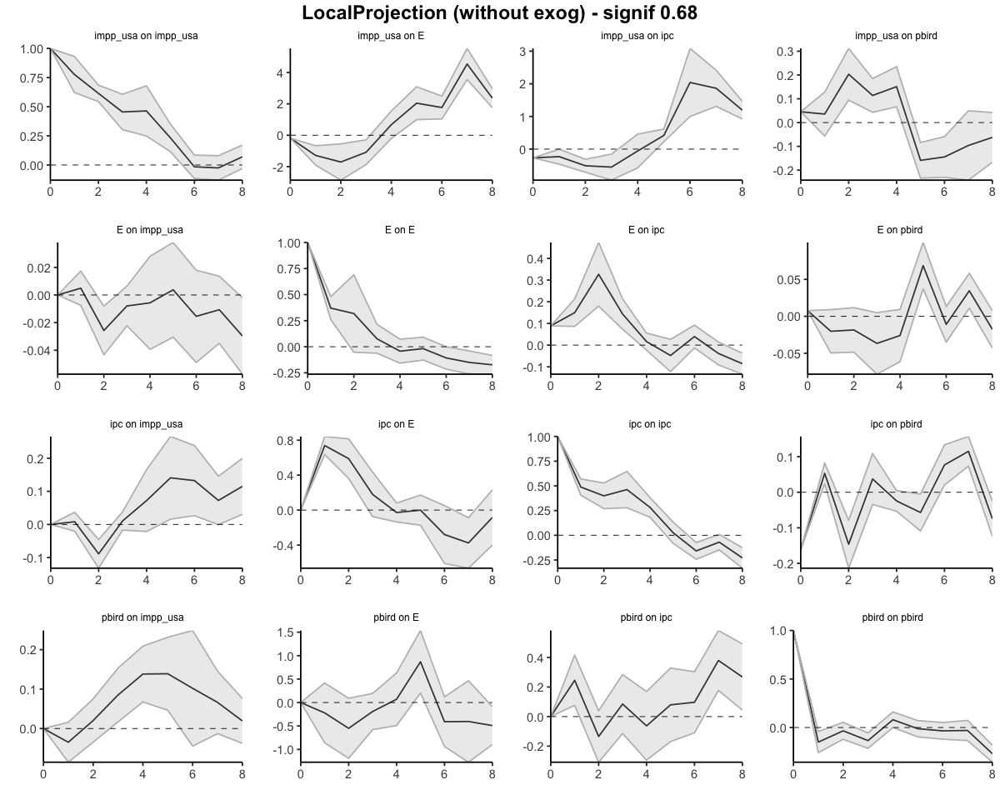

In [43]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.1837837,-0.1837837,-0.1837837
2,impp_usa,E,1,-1.4681939,-2.0854428,-0.8509451
3,impp_usa,E,2,-3.1736997,-4.9470562,-1.4003431
4,impp_usa,E,3,-4.2575082,-6.8196618,-1.6953546
5,impp_usa,E,4,-3.5834365,-7.0205018,-0.1463711
6,impp_usa,E,5,-1.5404441,-6.0261536,2.9452654
7,impp_usa,E,6,0.2270371,-4.9846095,5.4386837
8,impp_usa,E,7,4.7663158,-1.4390203,10.9716520
9,impp_usa,E,8,7.1267141,0.3180126,13.9354156


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000,0.000000000,0.0000000
65,ipc,E,1,0.7387342,0.635065776,0.8424027
66,ipc,E,2,1.3275825,0.997369144,1.6577960
67,ipc,E,3,1.5074699,0.922425225,2.0925145
68,ipc,E,4,1.4799567,0.786599938,2.1733134
69,ipc,E,5,1.4792539,0.613494691,2.3450131
70,ipc,E,6,1.1998733,0.002967625,2.3967789
71,ipc,E,7,0.8240358,-0.661853643,2.3099252
72,ipc,E,8,0.7398765,-1.061985506,2.5417385


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.0000000
92,pbird,E,1,-0.22155404,-0.8598554,0.4167473
93,pbird,E,2,-0.77187257,-2.0516141,0.5078690
94,pbird,E,3,-0.96368972,-2.6295748,0.7021954
95,pbird,E,4,-0.89371237,-3.1208461,1.3334213
96,pbird,E,5,-0.02439924,-2.9188294,2.8700309
97,pbird,E,6,-0.43345797,-3.8564440,2.9895281
98,pbird,E,7,-0.83776707,-5.1295281,3.4539940
99,pbird,E,8,-1.32913221,-6.0251959,3.3669314


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.0000000,0.00000000,0.0000000
101,pbird,ipc,1,0.2456050,0.07560821,0.4156019
102,pbird,ipc,2,0.1107692,-0.23329092,0.4548293
103,pbird,ipc,3,0.1956630,-0.34808248,0.7394084
104,pbird,ipc,4,0.1326475,-0.64317392,0.9084690
105,pbird,ipc,5,0.2119384,-0.81278308,1.2366599
106,pbird,ipc,6,0.3086144,-0.92268207,1.5399109
107,pbird,ipc,7,0.6881801,-0.74595697,2.1223171
108,pbird,ipc,8,0.9557585,-0.70215094,2.6136679


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.007700907,0.007700907,0.007700907
47,E,pbird,1,-0.012518678,-0.041811089,0.016773734
48,E,pbird,2,-0.030925853,-0.090340526,0.028488820
49,E,pbird,3,-0.067546222,-0.168551440,0.033458996
50,E,pbird,4,-0.093498382,-0.229886621,0.042889857
51,E,pbird,5,-0.025026545,-0.192826070,0.142772980
52,E,pbird,6,-0.035882859,-0.227849701,0.156083983
53,E,pbird,7,-0.001334714,-0.216902389,0.214232961
54,E,pbird,8,-0.018973535,-0.259803618,0.221856547


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.04554877,0.04554877,0.04554877
20,impp_usa,pbird,1,0.08130375,-0.01098532,0.17359282
21,impp_usa,pbird,2,0.28455609,0.08380031,0.48531186
22,impp_usa,pbird,3,0.39859224,0.12685078,0.67033371
23,impp_usa,pbird,4,0.54959962,0.19359290,0.90560634
24,impp_usa,pbird,5,0.39086610,-0.03998758,0.82171977
25,impp_usa,pbird,6,0.24639721,-0.26996825,0.76276267
26,impp_usa,pbird,7,0.15030416,-0.51196375,0.81257207
27,impp_usa,pbird,8,0.08815011,-0.67878473,0.85508496


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.1615671,-0.1615671,-0.16156712
74,ipc,pbird,1,-0.1084378,-0.1377358,-0.07913972
75,ipc,pbird,2,-0.2546403,-0.3513280,-0.15795269
76,ipc,pbird,3,-0.2173423,-0.3857752,-0.04890946
77,ipc,pbird,4,-0.2417511,-0.4392052,-0.04429697
78,ipc,pbird,5,-0.2986982,-0.5481636,-0.04923286
79,ipc,pbird,6,-0.2218494,-0.5278767,0.08417791
80,ipc,pbird,7,-0.1067766,-0.4545988,0.24104565
81,ipc,pbird,8,-0.1813952,-0.5787222,0.21593185


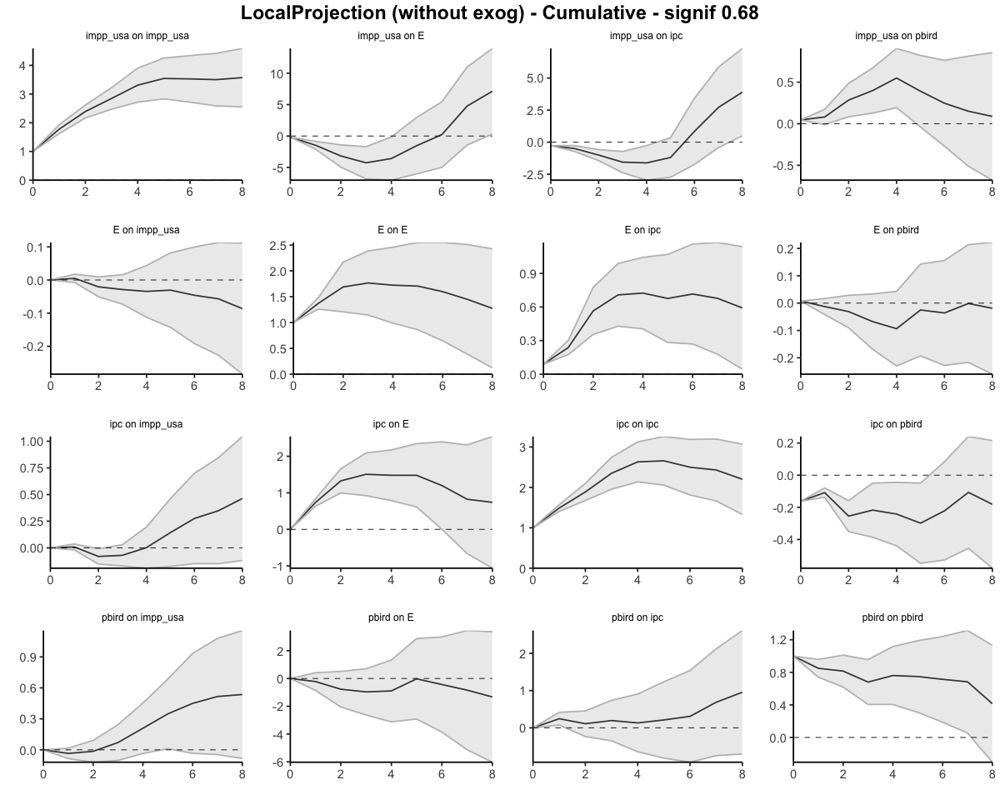

In [42]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 3 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.0888         0.0888       1.0000
         1              0.2385         0.1740       1.3705
         2              0.5650         0.3345       1.6889
         3              0.7082         0.4011       1.7656
         4              0.7244         0.4204       1.7233
         5              0.6766         0.3967       1.7054
         6              0.7160         0.4480       1.5981
         7              0.6777         0.4681       1.4476
         8              0.5919         0.4644       1.2746
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.0888             0.0888
                  0.1496             0.0852
                  0.3265             0.1605
                  0.1432             0.0666
                  0.0161             0.0192
       

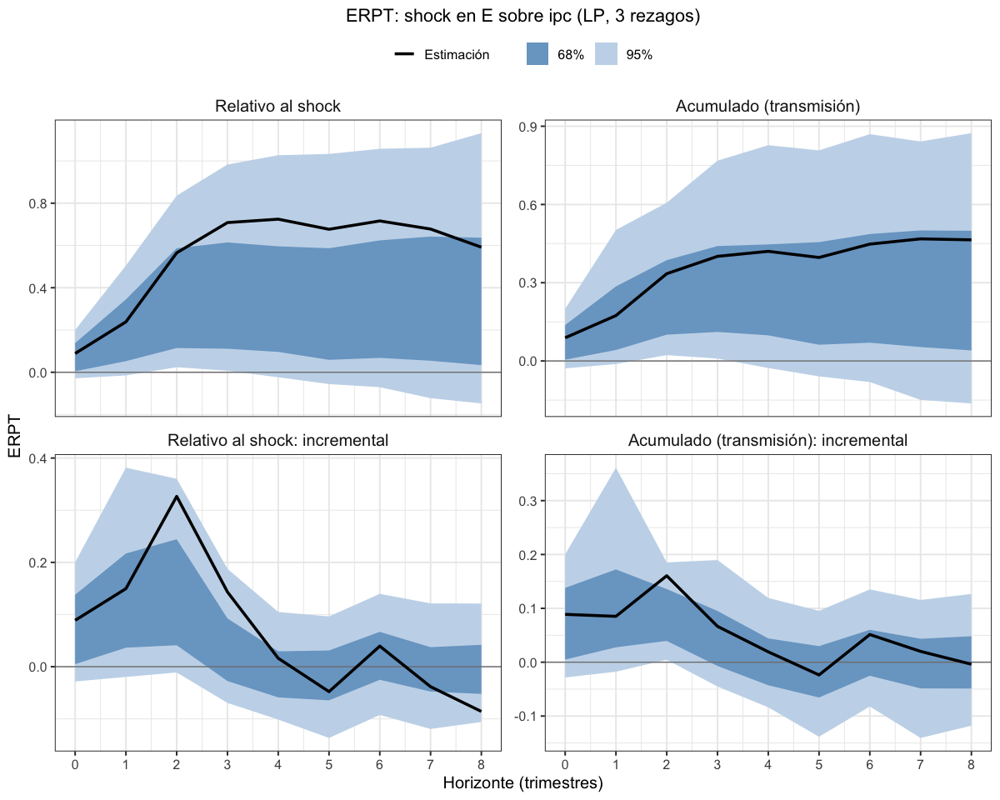

In [92]:
# Todas endógenas, 3 rezagos
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_75, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 3, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa75_endog_p3")

### impp_usa 1950 a 1975 - 1 exógena y el resto endógenas - Selected orders: 1 y 3 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.0000000,0.00000000
20,ipc,E,1,0.4722295,0.3189282,0.62553081
21,ipc,E,2,0.4453568,-0.2389606,1.12967415
22,ipc,E,3,0.1398230,-0.6020016,0.88164768
23,ipc,E,4,-0.0459166,-0.2742953,0.18246210
24,ipc,E,5,-0.2032015,-0.3478730,-0.05852999
25,ipc,E,6,-0.5177895,-0.7938871,-0.24169181
26,ipc,E,7,-0.4388086,-0.7133007,-0.16431653
27,ipc,E,8,-0.1347677,-0.6906051,0.42106964


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.000000000
38,pbird,E,1,-0.09978467,-0.5701697,0.370600362
39,pbird,E,2,-0.37933554,-0.7488026,-0.009868474
40,pbird,E,3,0.01192277,-0.4064275,0.430273013
41,pbird,E,4,0.12670566,-0.3315865,0.584997780
42,pbird,E,5,0.96601988,0.1106911,1.821348690
43,pbird,E,6,-0.31180355,-0.6698708,0.046263720
44,pbird,E,7,-0.43118334,-1.2108446,0.348477888
45,pbird,E,8,-0.61959225,-1.2250769,-0.014107595


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.130957854,0.13095785,1.309579e-01
2,E,ipc,1,0.229400026,0.15061009,3.081900e-01
3,E,ipc,2,0.355426505,0.17708330,5.337697e-01
4,E,ipc,3,0.174299514,0.05301986,2.955792e-01
5,E,ipc,4,-0.043887385,-0.14037807,5.260330e-02
6,E,ipc,5,-0.084594317,-0.16926680,7.817132e-05
7,E,ipc,6,0.002623708,-0.06254800,6.779542e-02
8,E,ipc,7,-0.072773050,-0.14724992,1.703816e-03
9,E,ipc,8,-0.127300273,-0.24551326,-9.087290e-03


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.00000000
47,pbird,ipc,1,0.13879738,0.02585621,0.25173854
48,pbird,ipc,2,-0.13885959,-0.31188433,0.03416515
49,pbird,ipc,3,0.26463047,0.09750250,0.43175843
50,pbird,ipc,4,0.09364804,-0.08707967,0.27437574
51,pbird,ipc,5,0.02786964,-0.19624569,0.25198498
52,pbird,ipc,6,-0.02147716,-0.21502414,0.17206983
53,pbird,ipc,7,0.24140279,0.05796950,0.42483609
54,pbird,ipc,8,0.22480911,-0.09748105,0.54709927


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.005517390,0.0055173900,0.0055173900
11,E,pbird,1,-0.030084223,-0.0618889168,0.0017204702
12,E,pbird,2,-0.023689457,-0.0475970697,0.0002181557
13,E,pbird,3,-0.044752632,-0.0837127190,-0.0057925445
14,E,pbird,4,-0.003197926,-0.0387828008,0.0323869485
15,E,pbird,5,0.065604275,0.0362887581,0.0949197922
16,E,pbird,6,0.010875170,-0.0125395761,0.0342899161
17,E,pbird,7,0.026246650,-0.0003103052,0.0528036043
18,E,pbird,8,-0.005991881,-0.0314826387,0.0194988772


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.124635684,-0.12463568,-0.124635684
29,ipc,pbird,1,-0.033872678,-0.06076880,-0.006976555
30,ipc,pbird,2,-0.106662502,-0.14251840,-0.070806603
31,ipc,pbird,3,0.033626379,-0.02324136,0.090494117
32,ipc,pbird,4,0.017988851,-0.02203630,0.058014002
33,ipc,pbird,5,0.009914312,-0.02377908,0.043607705
34,ipc,pbird,6,0.093148608,0.05380043,0.132496785
35,ipc,pbird,7,0.066238949,0.04710046,0.085377437
36,ipc,pbird,8,-0.018455919,-0.05942836,0.022516521


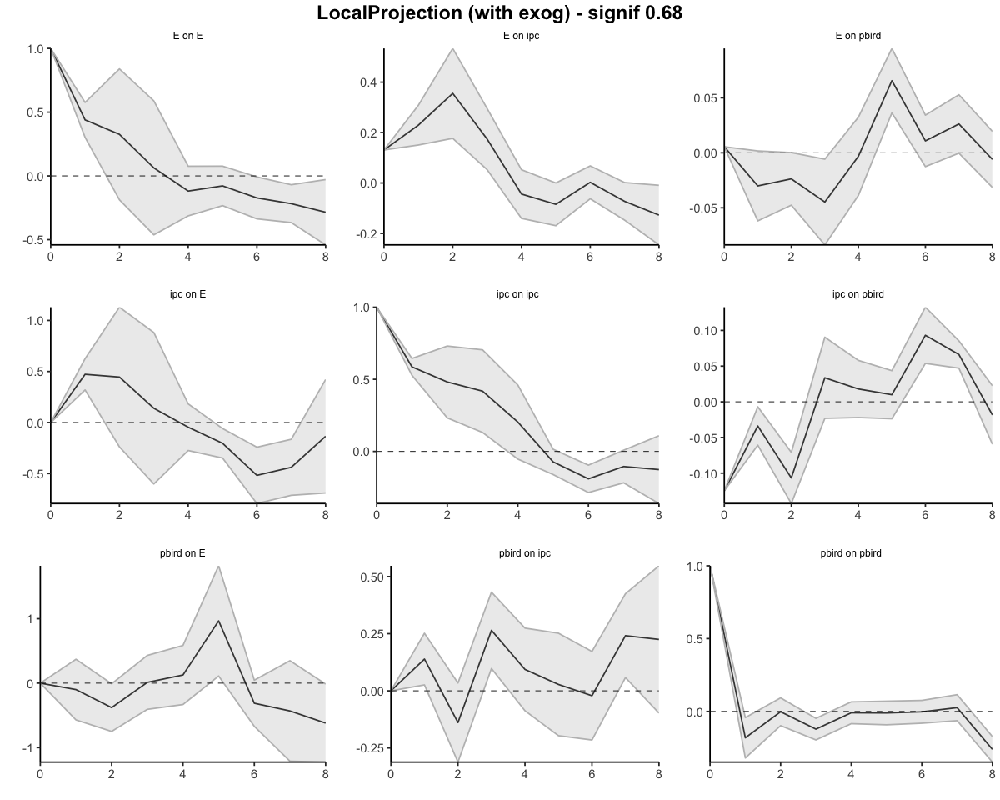

In [45]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.00000000,0.0000000
20,ipc,E,1,0.4722295,0.31892820,0.6255308
21,ipc,E,2,0.9175863,0.07996757,1.7552050
22,ipc,E,3,1.0574093,-0.52203407,2.6368526
23,ipc,E,4,1.0114927,-0.79632937,2.8193147
24,ipc,E,5,0.8082912,-1.14420239,2.7607848
25,ipc,E,6,0.2905017,-1.93808950,2.5190930
26,ipc,E,7,-0.1483069,-2.65139024,2.3547764
27,ipc,E,8,-0.2830747,-3.34199537,2.7758461


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.0000000
38,pbird,E,1,-0.09978467,-0.5701697,0.3706004
39,pbird,E,2,-0.47912022,-1.3189723,0.3607319
40,pbird,E,3,-0.46719744,-1.7253998,0.7910049
41,pbird,E,4,-0.34049178,-2.0569862,1.3760027
42,pbird,E,5,0.62552810,-1.9462952,3.1973514
43,pbird,E,6,0.31372455,-2.6161660,3.2436151
44,pbird,E,7,-0.11745879,-3.8270106,3.5920930
45,pbird,E,8,-0.73705104,-5.0520875,3.5779854


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.1309579,0.130957854,0.1309579
2,E,ipc,1,0.3603579,0.281567945,0.4391478
3,E,ipc,2,0.7157844,0.458651249,0.9729175
4,E,ipc,3,0.8900839,0.511671108,1.2684967
5,E,ipc,4,0.8461965,0.371293038,1.3211000
6,E,ipc,5,0.7616022,0.202026234,1.3211782
7,E,ipc,6,0.7642259,0.139478234,1.3889736
8,E,ipc,7,0.6914529,-0.007771683,1.3906774
9,E,ipc,8,0.5641526,-0.253284939,1.3815901


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.000000e+00,0.00000000,0.0000000
47,pbird,ipc,1,1.387974e-01,0.02585621,0.2517385
48,pbird,ipc,2,-6.221603e-05,-0.28602813,0.2859037
49,pbird,ipc,3,2.645682e-01,-0.18852563,0.7176621
50,pbird,ipc,4,3.582163e-01,-0.27560530,0.9920379
51,pbird,ipc,5,3.860859e-01,-0.47185099,1.2440228
52,pbird,ipc,6,3.646088e-01,-0.68687513,1.4160927
53,pbird,ipc,7,6.060116e-01,-0.62890563,1.8409288
54,pbird,ipc,8,8.308207e-01,-0.72638667,2.3880280


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.0055173900,0.00551739,0.005517390
11,E,pbird,1,-0.0245668333,-0.05637153,0.007237860
12,E,pbird,2,-0.0482562903,-0.10396860,0.007456016
13,E,pbird,3,-0.0930089220,-0.18768132,0.001663471
14,E,pbird,4,-0.0962068482,-0.22646412,0.034050420
15,E,pbird,5,-0.0306025731,-0.19017536,0.128970212
16,E,pbird,6,-0.0197274031,-0.20271493,0.163260128
17,E,pbird,7,0.0065192464,-0.20302524,0.216063732
18,E,pbird,8,0.0005273657,-0.23450788,0.235562610


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.12463568,-0.1246357,-0.12463568
29,ipc,pbird,1,-0.15850836,-0.1854045,-0.13161224
30,ipc,pbird,2,-0.26517086,-0.3279229,-0.20241884
31,ipc,pbird,3,-0.23154448,-0.3511642,-0.11192473
32,ipc,pbird,4,-0.21355563,-0.3732005,-0.05391072
33,ipc,pbird,5,-0.20364132,-0.3969796,-0.01030302
34,ipc,pbird,6,-0.11049271,-0.3431792,0.12219377
35,ipc,pbird,7,-0.04425376,-0.2960787,0.20757120
36,ipc,pbird,8,-0.06270968,-0.3555071,0.23008773


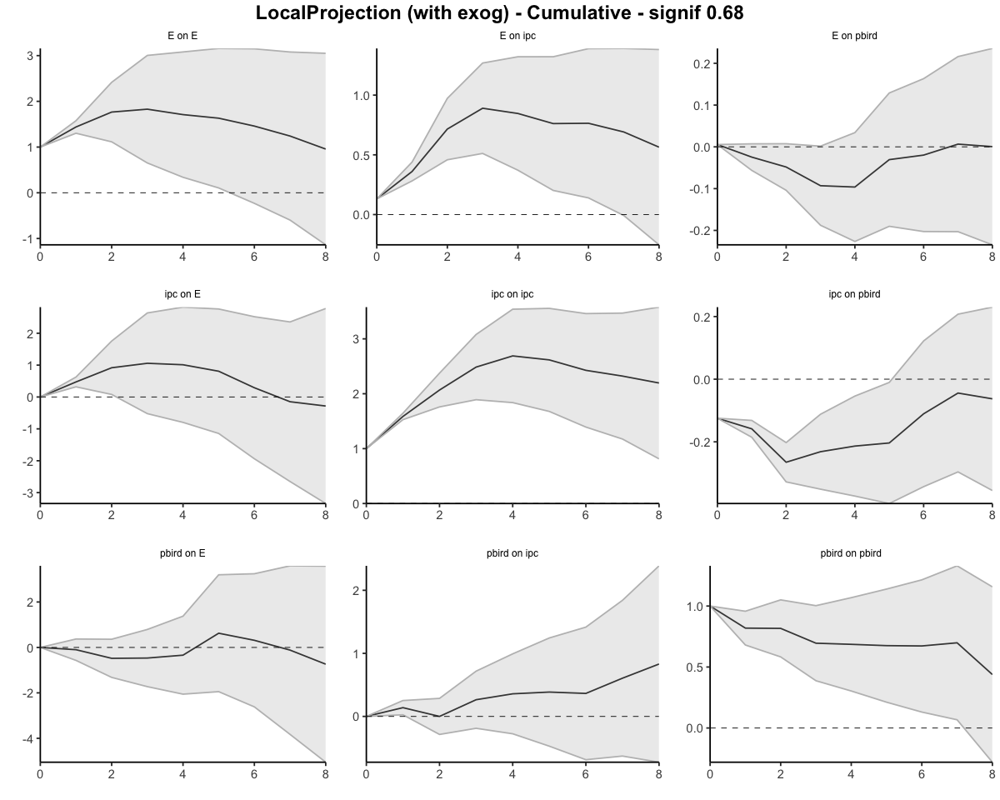

In [44]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1310         0.1310       1.0000
         1              0.3604         0.2504       1.4393
         2              0.7158         0.4055       1.7653
         3              0.8901         0.4868       1.8284
         4              0.8462         0.4949       1.7097
         5              0.7616         0.4668       1.6315
         6              0.7642         0.5238       1.4589
         7              0.6915         0.5571       1.2412
         8              0.5642         0.5900       0.9562
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1310             0.1310
                  0.2294             0.1194
                  0.3554             0.1551
                  0.1743             0.0813
                 -0.0439       

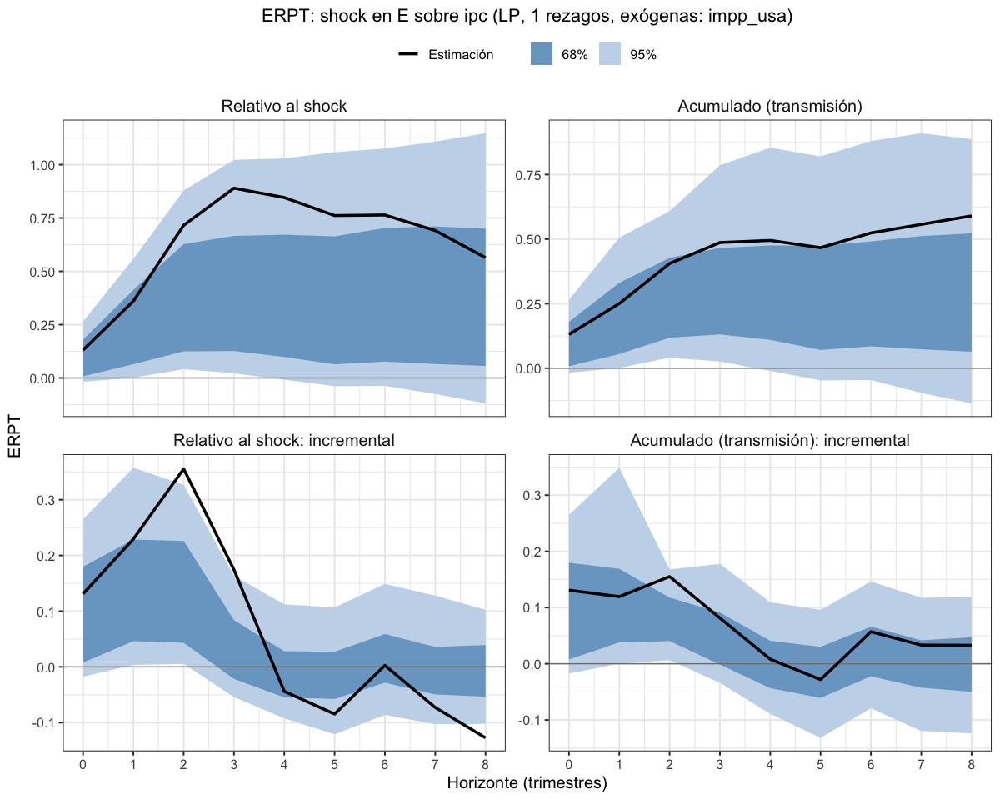

In [77]:
# impp_usa exógena, 1 rezago
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_75, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa75_exog_p1")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000000,0.00000000,0.00000000
20,ipc,E,1,0.7387832409,0.63525602,0.84231046
21,ipc,E,2,0.5889700831,0.36256704,0.81537312
22,ipc,E,3,0.1799297437,-0.07481605,0.43467553
23,ipc,E,4,-0.0275286694,-0.13571659,0.08065926
24,ipc,E,5,-0.0008951024,-0.17314994,0.17135974
25,ipc,E,6,-0.2792901378,-0.61031962,0.05173935
26,ipc,E,7,-0.3757480412,-0.66453960,-0.08695648
27,ipc,E,8,-0.0840505617,-0.39993370,0.23183258


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.00000000
38,pbird,E,1,-0.22155404,-0.8598554,0.41674733
39,pbird,E,2,-0.55031853,-1.1917587,0.09112164
40,pbird,E,3,-0.19181715,-0.5779607,0.19432639
41,pbird,E,4,0.06997735,-0.4912713,0.63122598
42,pbird,E,5,0.86931313,0.2020167,1.53660960
43,pbird,E,6,-0.40905873,-0.9376146,0.11949715
44,pbird,E,7,-0.40430910,-1.2730841,0.46446591
45,pbird,E,8,-0.49136515,-0.8956677,-0.08706256


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.08963512,0.08963512,0.08963512
2,E,ipc,1,0.15001382,0.08671868,0.21330895
3,E,ipc,2,0.32683422,0.17990915,0.47375929
4,E,ipc,3,0.14360479,0.07353971,0.21366986
5,E,ipc,4,0.01637066,-0.02290742,0.05564874
6,E,ipc,5,-0.04780896,-0.12246423,0.02684631
7,E,ipc,6,0.03933029,-0.01327455,0.09193513
8,E,ipc,7,-0.03840963,-0.09126436,0.01444511
9,E,ipc,8,-0.08598119,-0.13423534,-0.03772704


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.00000000
47,pbird,ipc,1,0.24560504,0.07560821,0.41560187
48,pbird,ipc,2,-0.13483584,-0.30889913,0.03922746
49,pbird,ipc,3,0.08489378,-0.11479156,0.28457912
50,pbird,ipc,4,-0.06301543,-0.29509143,0.16906056
51,pbird,ipc,5,0.07929087,-0.16960917,0.32819090
52,pbird,ipc,6,0.09667598,-0.10989899,0.30325094
53,pbird,ipc,7,0.37956568,0.17672510,0.58240626
54,pbird,ipc,8,0.26757842,0.04380604,0.49135080


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.007553837,0.007553837,0.007553837
11,E,pbird,1,-0.020174777,-0.049488080,0.009138526
12,E,pbird,2,-0.018521550,-0.048695102,0.011652002
13,E,pbird,3,-0.036588331,-0.078233757,0.005057095
14,E,pbird,4,-0.025972969,-0.061377223,0.009431286
15,E,pbird,5,0.068427267,0.036976726,0.099877808
16,E,pbird,6,-0.010795151,-0.035005265,0.013414963
17,E,pbird,7,0.034639308,0.011007654,0.058270962
18,E,pbird,8,-0.017692170,-0.042991785,0.007607446


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.16178837,-0.16178837,-0.161788367
29,ipc,pbird,1,0.05316264,0.02388864,0.082436641
30,ipc,pbird,2,-0.14619501,-0.21356527,-0.078824758
31,ipc,pbird,3,0.03732786,-0.03439978,0.109055510
32,ipc,pbird,4,-0.02442654,-0.05342998,0.004576898
33,ipc,pbird,5,-0.05694441,-0.10893705,-0.004951766
34,ipc,pbird,6,0.07685644,0.02031356,0.133399323
35,ipc,pbird,7,0.11507955,0.07330762,0.156851470
36,ipc,pbird,8,-0.07455893,-0.12404429,-0.025073564


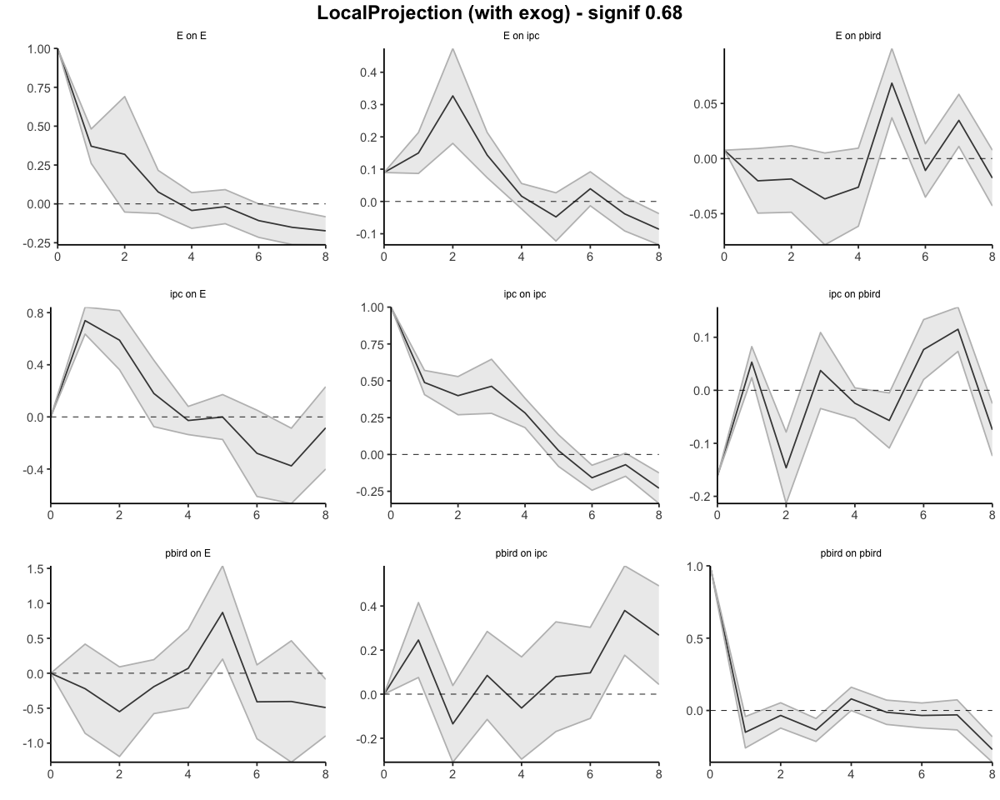

In [46]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,103,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.000000000,0.0000000
20,ipc,E,1,0.7387832,0.635256017,0.8423105
21,ipc,E,2,1.3277533,0.997823059,1.6576836
22,ipc,E,3,1.5076831,0.923007012,2.0923591
23,ipc,E,4,1.4801544,0.787290418,2.1730184
24,ipc,E,5,1.4792593,0.614140475,2.3443781
25,ipc,E,6,1.1999692,0.003820854,2.3961175
26,ipc,E,7,0.8242211,-0.660718747,2.3091610
27,ipc,E,8,0.7401706,-1.060652446,2.5409936


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.0000000
38,pbird,E,1,-0.22155404,-0.8598554,0.4167473
39,pbird,E,2,-0.77187257,-2.0516141,0.5078690
40,pbird,E,3,-0.96368972,-2.6295748,0.7021954
41,pbird,E,4,-0.89371237,-3.1208461,1.3334213
42,pbird,E,5,-0.02439924,-2.9188294,2.8700309
43,pbird,E,6,-0.43345797,-3.8564440,2.9895281
44,pbird,E,7,-0.83776707,-5.1295281,3.4539940
45,pbird,E,8,-1.32913221,-6.0251959,3.3669314


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.08963512,0.08963512,0.08963512
2,E,ipc,1,0.23964893,0.17635379,0.30294407
3,E,ipc,2,0.56648315,0.35626294,0.77670336
4,E,ipc,3,0.71008794,0.42980266,0.99037322
5,E,ipc,4,0.72645860,0.40689523,1.04602196
6,E,ipc,5,0.67864964,0.28443101,1.07286827
7,E,ipc,6,0.71797993,0.27115646,1.16480340
8,E,ipc,7,0.67957030,0.17989210,1.17924851
9,E,ipc,8,0.59358911,0.04565676,1.14152147


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.00000000,0.0000000
47,pbird,ipc,1,0.2456050,0.07560821,0.4156019
48,pbird,ipc,2,0.1107692,-0.23329092,0.4548293
49,pbird,ipc,3,0.1956630,-0.34808248,0.7394084
50,pbird,ipc,4,0.1326475,-0.64317392,0.9084690
51,pbird,ipc,5,0.2119384,-0.81278308,1.2366599
52,pbird,ipc,6,0.3086144,-0.92268207,1.5399109
53,pbird,ipc,7,0.6881801,-0.74595697,2.1223171
54,pbird,ipc,8,0.9557585,-0.70215094,2.6136679


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.007553837,0.007553837,0.007553837
11,E,pbird,1,-0.012620940,-0.041934243,0.016692364
12,E,pbird,2,-0.031142490,-0.090629344,0.028344365
13,E,pbird,3,-0.067730820,-0.168863101,0.033401460
14,E,pbird,4,-0.093703789,-0.230240324,0.042832746
15,E,pbird,5,-0.025276522,-0.193263598,0.142710554
16,E,pbird,6,-0.036071673,-0.228268863,0.156125517
17,E,pbird,7,-0.001432365,-0.217261209,0.214396479
18,E,pbird,8,-0.019124535,-0.260252994,0.222003925


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.1617884,-0.1617884,-0.16178837
29,ipc,pbird,1,-0.1086257,-0.1378997,-0.07935173
30,ipc,pbird,2,-0.2548207,-0.3514650,-0.15817648
31,ipc,pbird,3,-0.2174929,-0.3858648,-0.04912097
32,ipc,pbird,4,-0.2419194,-0.4392948,-0.04454408
33,ipc,pbird,5,-0.2988638,-0.5482318,-0.04949584
34,ipc,pbird,6,-0.2220074,-0.5279182,0.08390348
35,ipc,pbird,7,-0.1069278,-0.4546106,0.24075495
36,ipc,pbird,8,-0.1814868,-0.5786549,0.21568139


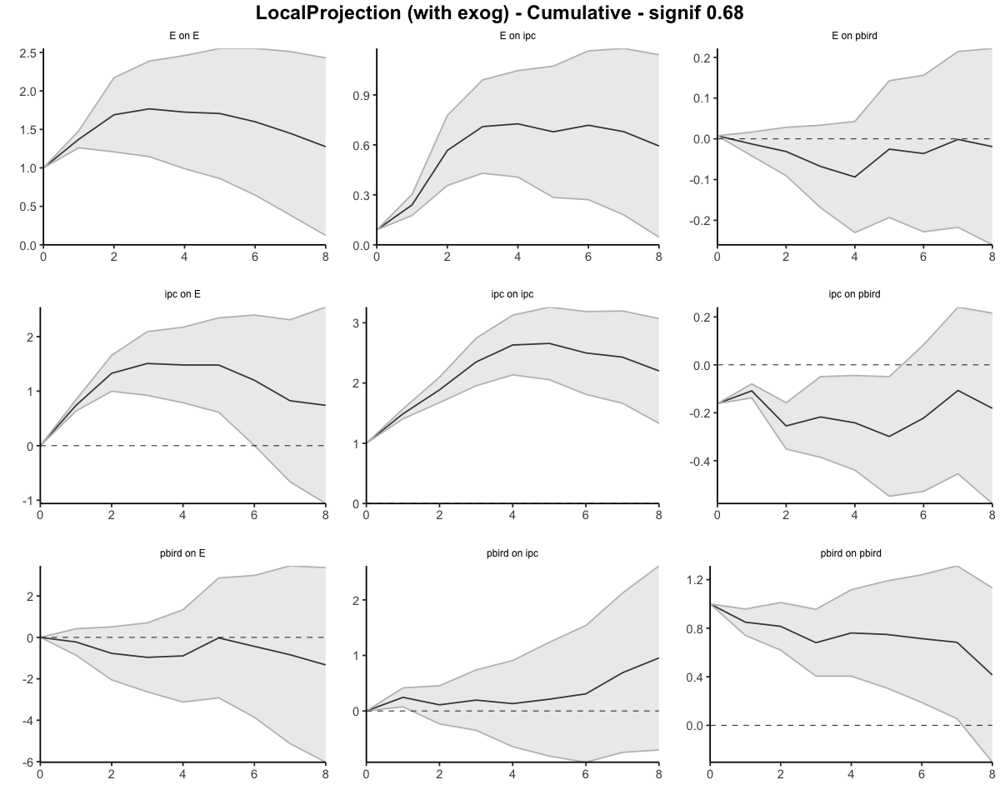

In [47]:
res <- run_lp_model(df_ERPT_Arg_1950_75, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 3 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.0896         0.0896       1.0000
         1              0.2396         0.1748       1.3711
         2              0.5665         0.3352       1.6900
         3              0.7101         0.4019       1.7668
         4              0.7265         0.4213       1.7244
         5              0.6786         0.3977       1.7066
         6              0.7180         0.4490       1.5990
         7              0.6796         0.4692       1.4483
         8              0.5936         0.4655       1.2752
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.0896             0.0896
                  0.1500             0.0852
                  0.3268             0.1604
                  0.1436             0.0667
                  0.0164       

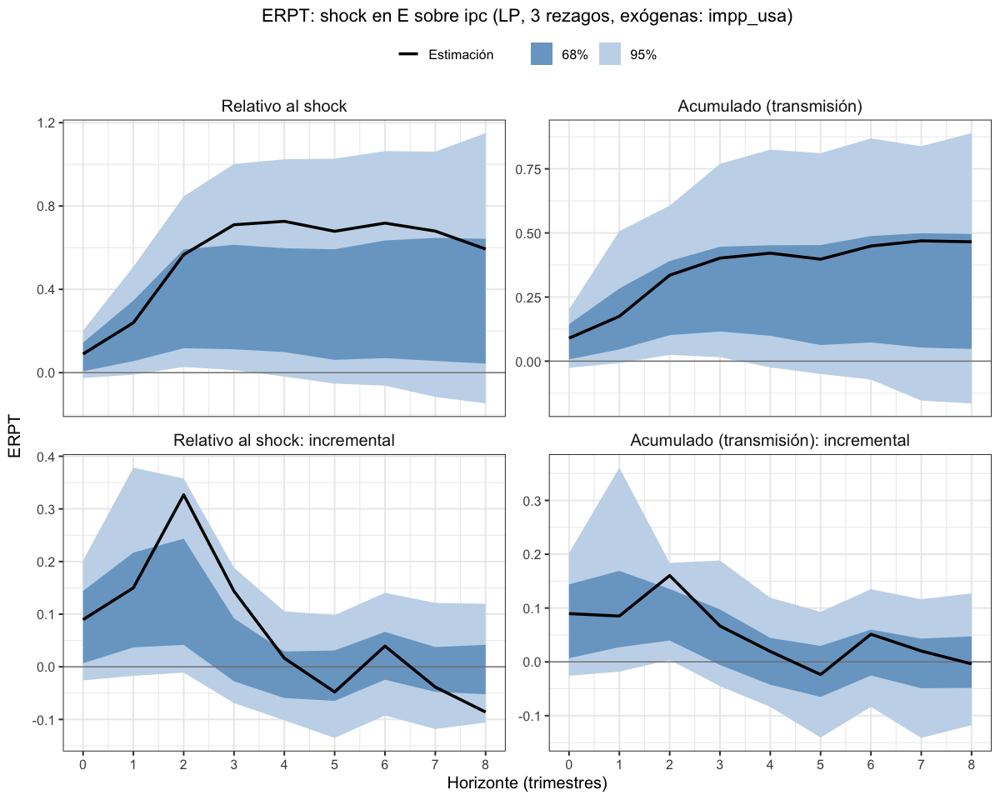

In [78]:
# impp_usa exógena, 3 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_75, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 3, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa75_exog_p3")

### impp_usa 1950 a 1982 - Todas endógenas - Selected orders: 1 y 3 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.39424534,-0.39424534,-0.3942453
2,impp_usa,E,1,-0.58198504,-0.91496678,-0.2490033
3,impp_usa,E,2,-0.09075031,-0.59624433,0.4147437
4,impp_usa,E,3,0.41416447,-0.58572908,1.4140580
5,impp_usa,E,4,1.39230578,0.02309586,2.7615157
6,impp_usa,E,5,2.21837296,0.86268864,3.5740573
7,impp_usa,E,6,2.54564046,1.48539051,3.6058904
8,impp_usa,E,7,2.73226160,1.66435051,3.8001727
9,impp_usa,E,8,2.10990268,1.26072729,2.9590781


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000,0.000000000,0.0000000
65,ipc,E,1,0.2962597,0.198332131,0.3941872
66,ipc,E,2,0.2935649,0.095732791,0.4913970
67,ipc,E,3,0.4425882,0.295445473,0.5897309
68,ipc,E,4,0.3027271,0.190068341,0.4153858
69,ipc,E,5,0.1119520,-0.016095580,0.2399996
70,ipc,E,6,0.2320376,0.080091093,0.3839841
71,ipc,E,7,0.1734466,0.005952511,0.3409407
72,ipc,E,8,0.2213366,0.036744162,0.4059290


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.000000000
92,pbird,E,1,-0.97769624,-1.6322336,-0.323158904
93,pbird,E,2,-0.41194970,-0.7633702,-0.060529164
94,pbird,E,3,0.03546304,-0.3956222,0.466548285
95,pbird,E,4,-0.17533020,-0.7173661,0.366705655
96,pbird,E,5,0.51516109,-0.2056242,1.235946347
97,pbird,E,6,-0.54496064,-1.0935495,0.003628188
98,pbird,E,7,-0.31941750,-0.8999248,0.261089777
99,pbird,E,8,-0.11755704,-0.5693072,0.334193119


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.00000000
101,pbird,ipc,1,0.05775838,-0.12317119,0.23868794
102,pbird,ipc,2,-0.15687623,-0.33390703,0.02015456
103,pbird,ipc,3,0.23312791,0.06412414,0.40213168
104,pbird,ipc,4,0.03537512,-0.17990465,0.25065489
105,pbird,ipc,5,0.02104273,-0.19061588,0.23270135
106,pbird,ipc,6,-0.01786629,-0.32790619,0.29217360
107,pbird,ipc,7,0.13864395,-0.06722435,0.34451225
108,pbird,ipc,8,0.40176199,0.17228069,0.63124329


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.001623317,0.001623317,0.001623317
47,E,pbird,1,-0.020202286,-0.046294868,0.005890296
48,E,pbird,2,-0.010739534,-0.035206059,0.013726990
49,E,pbird,3,-0.039707435,-0.069973336,-0.009441533
50,E,pbird,4,-0.018308963,-0.040754210,0.004136283
51,E,pbird,5,0.030065825,0.003374041,0.056757609
52,E,pbird,6,0.010477545,-0.007640225,0.028595316
53,E,pbird,7,0.013622214,-0.009534318,0.036778745
54,E,pbird,8,0.007302822,-0.012568683,0.027174326


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.16111741,0.16111741,0.16111741
20,impp_usa,pbird,1,0.05362518,-0.01079628,0.11804665
21,impp_usa,pbird,2,0.04905621,-0.01656787,0.11468029
22,impp_usa,pbird,3,-0.04099564,-0.09387275,0.01188148
23,impp_usa,pbird,4,-0.13094008,-0.19017120,-0.07170897
24,impp_usa,pbird,5,-0.21472931,-0.27624410,-0.15321452
25,impp_usa,pbird,6,-0.22512497,-0.30408918,-0.14616076
26,impp_usa,pbird,7,-0.18550187,-0.27709777,-0.09390597
27,impp_usa,pbird,8,-0.18380927,-0.26136947,-0.10624907


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.07734714,-0.077347140,-0.0773471400
74,ipc,pbird,1,-0.02167161,-0.042213587,-0.0011296326
75,ipc,pbird,2,-0.02889065,-0.048125306,-0.0096559871
76,ipc,pbird,3,0.03835635,0.013049089,0.0636636144
77,ipc,pbird,4,0.02546176,0.004205128,0.0467183913
78,ipc,pbird,5,-0.01747494,-0.034528934,-0.0004209377
79,ipc,pbird,6,0.00323486,-0.023428900,0.0298986199
80,ipc,pbird,7,-0.02976582,-0.064059366,0.0045277190
81,ipc,pbird,8,-0.03652821,-0.053526830,-0.0195295875


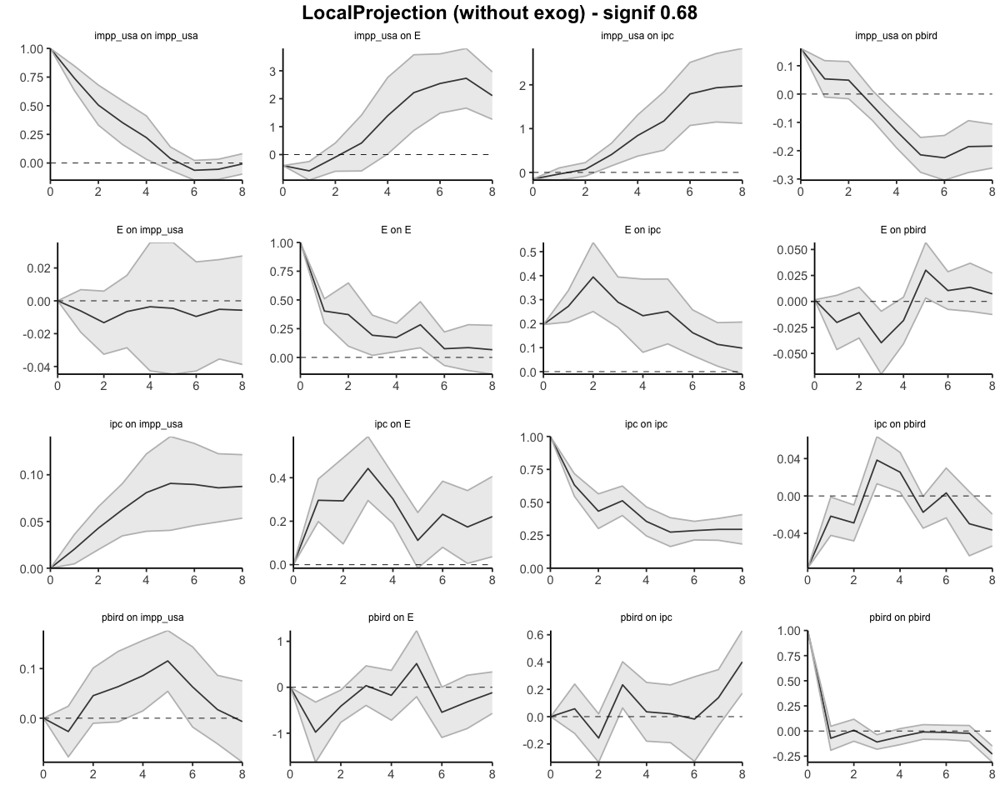

In [49]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.3942453,-0.3942453,-0.3942453
2,impp_usa,E,1,-0.9762304,-1.3092121,-0.6432486
3,impp_usa,E,2,-1.0669807,-1.9054565,-0.2285049
4,impp_usa,E,3,-0.6528162,-2.4911855,1.1855531
5,impp_usa,E,4,0.7394896,-2.4680897,3.9470688
6,impp_usa,E,5,2.9578625,-1.6054010,7.5211261
7,impp_usa,E,6,5.5035030,-0.1200105,11.1270165
8,impp_usa,E,7,8.2357646,1.5443400,14.9271892
9,impp_usa,E,8,10.3456673,2.8050673,17.8862672


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000,0.0000000,0.0000000
65,ipc,E,1,0.2962597,0.1983321,0.3941872
66,ipc,E,2,0.5898246,0.2940649,0.8855842
67,ipc,E,3,1.0324127,0.5895104,1.4753151
68,ipc,E,4,1.3351398,0.7795787,1.8907009
69,ipc,E,5,1.4470918,0.7634832,2.1307005
70,ipc,E,6,1.6791294,0.8435742,2.5146846
71,ipc,E,7,1.8525760,0.8495268,2.8556253
72,ipc,E,8,2.0739126,0.8862709,3.2615542


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.000000,0.00000000
92,pbird,E,1,-0.9776962,-1.632234,-0.32315890
93,pbird,E,2,-1.3896459,-2.395604,-0.38368807
94,pbird,E,3,-1.3541829,-2.791226,0.08286022
95,pbird,E,4,-1.5295131,-3.508592,0.44956587
96,pbird,E,5,-1.0143520,-3.714216,1.68551222
97,pbird,E,6,-1.5593126,-4.807766,1.68914041
98,pbird,E,7,-1.8787301,-5.707690,1.95023018
99,pbird,E,8,-1.9962872,-6.276998,2.28442330


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.0000000
101,pbird,ipc,1,0.05775838,-0.1231712,0.2386879
102,pbird,ipc,2,-0.09911786,-0.4570782,0.2588425
103,pbird,ipc,3,0.13401005,-0.3929541,0.6609742
104,pbird,ipc,4,0.16938517,-0.5728587,0.9116291
105,pbird,ipc,5,0.19042790,-0.7634746,1.1443304
106,pbird,ipc,6,0.17256161,-1.0913808,1.4365040
107,pbird,ipc,7,0.31120556,-1.1586052,1.7810163
108,pbird,ipc,8,0.71296755,-0.9863245,2.4122596


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.001623317,0.001623317,0.001623317
47,E,pbird,1,-0.018578968,-0.044671550,0.007513614
48,E,pbird,2,-0.029318503,-0.079877609,0.021240604
49,E,pbird,3,-0.069025937,-0.149850945,0.011799070
50,E,pbird,4,-0.087334901,-0.190605155,0.015935353
51,E,pbird,5,-0.057269076,-0.187231114,0.072692962
52,E,pbird,6,-0.046791530,-0.194871339,0.101288278
53,E,pbird,7,-0.033169317,-0.204405657,0.138067023
54,E,pbird,8,-0.025866495,-0.216974339,0.165241349


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.16111741,0.1611174,0.16111741
20,impp_usa,pbird,1,0.21474259,0.1503211,0.27916406
21,impp_usa,pbird,2,0.26379880,0.1337533,0.39384435
22,impp_usa,pbird,3,0.22280317,0.0398805,0.40572583
23,impp_usa,pbird,4,0.09186308,-0.1502907,0.33401686
24,impp_usa,pbird,5,-0.12286623,-0.4265348,0.18080234
25,impp_usa,pbird,6,-0.34799120,-0.7306240,0.03464158
26,impp_usa,pbird,7,-0.53349306,-1.0077217,-0.05926439
27,impp_usa,pbird,8,-0.71730233,-1.2690912,-0.16551346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.07734714,-0.07734714,-0.07734714
74,ipc,pbird,1,-0.09901875,-0.11956073,-0.07847677
75,ipc,pbird,2,-0.12790940,-0.16768603,-0.08813276
76,ipc,pbird,3,-0.08955304,-0.15463694,-0.02446915
77,ipc,pbird,4,-0.06409128,-0.15043182,0.02224925
78,ipc,pbird,5,-0.08156622,-0.18496075,0.02182831
79,ipc,pbird,6,-0.07833136,-0.20838965,0.05172693
80,ipc,pbird,7,-0.10809718,-0.27244902,0.05625465
81,ipc,pbird,8,-0.14462539,-0.32597585,0.03672506


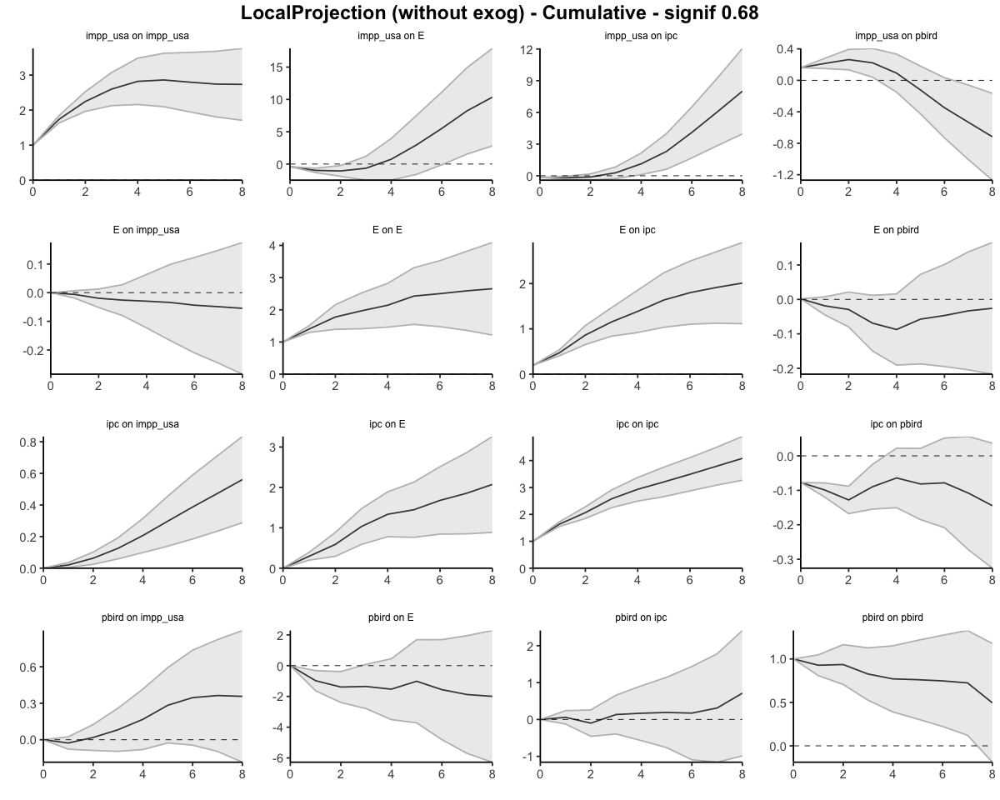

In [48]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1964         0.1964       1.0000
         1              0.4687         0.3340       1.4033
         2              0.8633         0.4861       1.7758
         3              1.1527         0.5855       1.9686
         4              1.3858         0.6469       2.1422
         5              1.6367         0.6745       2.4265
         6              1.7990         0.7190       2.5022
         7              1.9127         0.7392       2.5875
         8              2.0108         0.7576       2.6543
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1964             0.1964
                  0.2723             0.1376
                  0.3945             0.1521
                  0.2894             0.0994
                  0.2331             0.0614
       

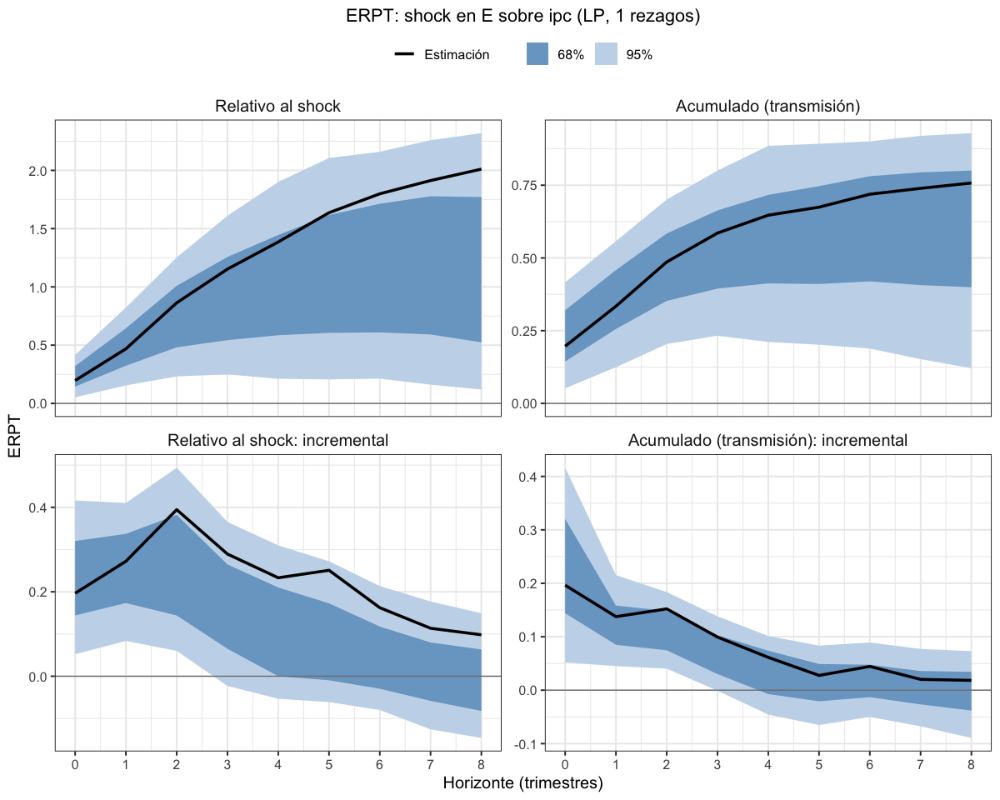

In [79]:
# Todas endógenas, 1 rezago
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_82, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa82_endog_p1")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.7280368,-0.7280368,-0.7280368
2,impp_usa,E,1,-1.7830677,-2.4810676,-1.0850678
3,impp_usa,E,2,-0.9060933,-1.7148654,-0.0973211
4,impp_usa,E,3,-1.1215305,-1.6946447,-0.5484164
5,impp_usa,E,4,-0.1739760,-1.3105732,0.9626212
6,impp_usa,E,5,1.0322160,-0.2078078,2.2722397
7,impp_usa,E,6,1.4655383,0.5049009,2.4261758
8,impp_usa,E,7,3.0252812,1.8666226,4.1839398
9,impp_usa,E,8,1.5486909,1.0052184,2.0921635


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.00000000,0.0000000
65,ipc,E,1,0.05194869,-0.29158664,0.3954840
66,ipc,E,2,0.07199767,-0.11032531,0.2543206
67,ipc,E,3,0.24472285,0.03222025,0.4572254
68,ipc,E,4,0.14525936,0.03410856,0.2564102
69,ipc,E,5,0.04989816,-0.08007962,0.1798759
70,ipc,E,6,0.15339623,-0.08531276,0.3921052
71,ipc,E,7,0.12578014,-0.09269392,0.3442542
72,ipc,E,8,0.06344140,-0.13270623,0.2595890


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.000000000
92,pbird,E,1,-0.90841616,-1.4957379,-0.321094433
93,pbird,E,2,-0.37477436,-0.7568783,0.007329562
94,pbird,E,3,-0.02325818,-0.4346123,0.388095988
95,pbird,E,4,-0.04750027,-0.5887211,0.493720609
96,pbird,E,5,0.50890766,-0.1340120,1.151827315
97,pbird,E,6,-0.57020580,-1.0836650,-0.056746607
98,pbird,E,7,-0.26045068,-0.8723105,0.351409108
99,pbird,E,8,-0.11818559,-0.5112191,0.274847870


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.00000000
101,pbird,ipc,1,0.11857620,-0.04478227,0.28193467
102,pbird,ipc,2,-0.13847849,-0.31727231,0.04031533
103,pbird,ipc,3,0.23453840,0.07143724,0.39763956
104,pbird,ipc,4,0.09902297,-0.15552208,0.35356803
105,pbird,ipc,5,0.05203320,-0.13003619,0.23410259
106,pbird,ipc,6,-0.01454128,-0.23808105,0.20899849
107,pbird,ipc,7,0.16566375,-0.02108476,0.35241226
108,pbird,ipc,8,0.38468556,0.17228766,0.59708346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.001079297,0.001079297,0.001079297
47,E,pbird,1,-0.017833391,-0.043080074,0.007413292
48,E,pbird,2,-0.005345850,-0.035899969,0.025208269
49,E,pbird,3,-0.040190042,-0.075913060,-0.004467024
50,E,pbird,4,-0.033154527,-0.058420337,-0.007888717
51,E,pbird,5,0.031133928,-0.001260590,0.063528446
52,E,pbird,6,0.008921579,-0.008482719,0.026325877
53,E,pbird,7,0.014625125,-0.005287268,0.034537518
54,E,pbird,8,0.003631920,-0.017902424,0.025166263


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.14875264,0.14875264,0.14875264
20,impp_usa,pbird,1,0.06322031,-0.02638225,0.15282286
21,impp_usa,pbird,2,0.08777134,0.02739513,0.14814755
22,impp_usa,pbird,3,0.13391449,0.06859678,0.19923221
23,impp_usa,pbird,4,0.11765299,0.05017593,0.18513005
24,impp_usa,pbird,5,-0.11376711,-0.18223449,-0.04529974
25,impp_usa,pbird,6,-0.15928466,-0.24635989,-0.07220943
26,impp_usa,pbird,7,-0.06622144,-0.16052156,0.02807868
27,impp_usa,pbird,8,-0.14271464,-0.24960292,-0.03582635


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.1228415642,-0.12284156,-0.122841564
74,ipc,pbird,1,-0.0001134163,-0.01693842,0.016711590
75,ipc,pbird,2,-0.0560377420,-0.10302760,-0.009047880
76,ipc,pbird,3,0.0054185567,-0.03401764,0.044854753
77,ipc,pbird,4,0.0048642755,-0.01753463,0.027263183
78,ipc,pbird,5,-0.0207914638,-0.06470382,0.023120892
79,ipc,pbird,6,0.0577197327,0.02938907,0.086050396
80,ipc,pbird,7,-0.0120127381,-0.04992361,0.025898137
81,ipc,pbird,8,-0.0339242362,-0.06325245,-0.004596027


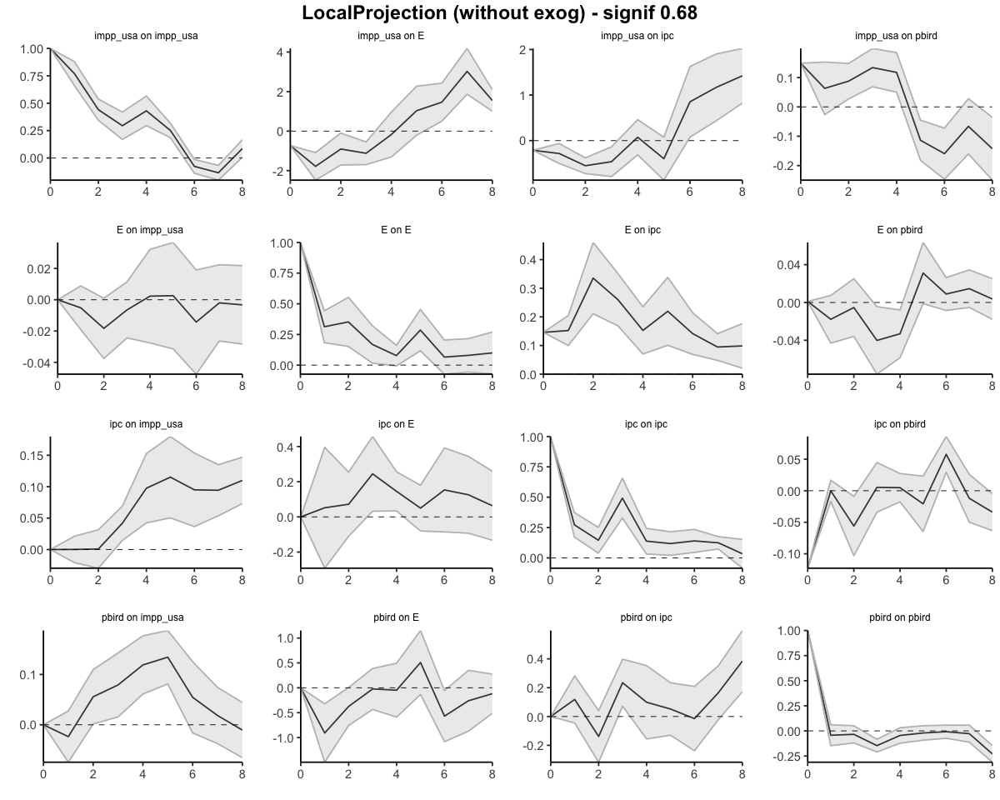

In [51]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.7280368,-0.7280368,-0.7280368
2,impp_usa,E,1,-2.5111045,-3.2091044,-1.8131046
3,impp_usa,E,2,-3.4171978,-4.9239698,-1.9104257
4,impp_usa,E,3,-4.5387283,-6.6186145,-2.4588421
5,impp_usa,E,4,-4.7127043,-7.9291878,-1.4962209
6,impp_usa,E,5,-3.6804884,-8.1369956,0.7760188
7,impp_usa,E,6,-2.2149500,-7.6320947,3.2021947
8,impp_usa,E,7,0.8103312,-5.7654721,7.3861344
9,impp_usa,E,8,2.3590221,-4.7602536,9.4782979


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.0000000,0.0000000
65,ipc,E,1,0.05194869,-0.2915866,0.3954840
66,ipc,E,2,0.12394636,-0.4019119,0.6498047
67,ipc,E,3,0.36866920,-0.3696917,1.1070301
68,ipc,E,4,0.51392856,-0.3355831,1.3634403
69,ipc,E,5,0.56382671,-0.4156628,1.5433162
70,ipc,E,6,0.71722294,-0.5009755,1.9354214
71,ipc,E,7,0.84300308,-0.5936694,2.2796756
72,ipc,E,8,0.90644447,-0.7263757,2.5392646


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.000000,0.00000000
92,pbird,E,1,-0.9084162,-1.495738,-0.32109443
93,pbird,E,2,-1.2831905,-2.252616,-0.31376487
94,pbird,E,3,-1.3064487,-2.687229,0.07433112
95,pbird,E,4,-1.3539490,-3.275950,0.56805173
96,pbird,E,5,-0.8450413,-3.409962,1.71987904
97,pbird,E,6,-1.4152471,-4.493627,1.66313243
98,pbird,E,7,-1.6756978,-5.365937,2.01454154
99,pbird,E,8,-1.7938834,-5.877156,2.28938941


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.0000000
101,pbird,ipc,1,0.11857620,-0.04478227,0.2819347
102,pbird,ipc,2,-0.01990229,-0.36205458,0.3222500
103,pbird,ipc,3,0.21463611,-0.29061734,0.7198896
104,pbird,ipc,4,0.31365908,-0.44613942,1.0734576
105,pbird,ipc,5,0.36569228,-0.57617561,1.3075602
106,pbird,ipc,6,0.35115100,-0.81425667,1.5165587
107,pbird,ipc,7,0.51681475,-0.83534143,1.8689709
108,pbird,ipc,8,0.90150031,-0.66305376,2.4660544


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,0.001079297,0.001079297,0.001079297
47,E,pbird,1,-0.016754094,-0.042000777,0.008492589
48,E,pbird,2,-0.022099944,-0.077900746,0.033700858
49,E,pbird,3,-0.062289986,-0.153813806,0.029233834
50,E,pbird,4,-0.095444513,-0.212234143,0.021345117
51,E,pbird,5,-0.064310585,-0.213494733,0.084873562
52,E,pbird,6,-0.055389006,-0.221977452,0.111199440
53,E,pbird,7,-0.040763881,-0.227264721,0.145736958
54,E,pbird,8,-0.037131962,-0.245167145,0.170903221


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.14875264,0.14875264,0.1487526
20,impp_usa,pbird,1,0.21197294,0.12237039,0.3015755
21,impp_usa,pbird,2,0.29974428,0.14976552,0.4497230
22,impp_usa,pbird,3,0.43365878,0.21836230,0.6489553
23,impp_usa,pbird,4,0.55131177,0.26853823,0.8340853
24,impp_usa,pbird,5,0.43754466,0.08630374,0.7887856
25,impp_usa,pbird,6,0.27826000,-0.16005615,0.7165761
26,impp_usa,pbird,7,0.21203856,-0.32057771,0.7446548
27,impp_usa,pbird,8,0.06932392,-0.57018063,0.7088285


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.1228416,-0.1228416,-0.12284156
74,ipc,pbird,1,-0.1229550,-0.1397800,-0.10612997
75,ipc,pbird,2,-0.1789927,-0.2428076,-0.11517785
76,ipc,pbird,3,-0.1735742,-0.2768252,-0.07032310
77,ipc,pbird,4,-0.1687099,-0.2943599,-0.04305992
78,ipc,pbird,5,-0.1895014,-0.3590637,-0.01993903
79,ipc,pbird,6,-0.1317816,-0.3296746,0.06611137
80,ipc,pbird,7,-0.1437944,-0.3795982,0.09200951
81,ipc,pbird,8,-0.1777186,-0.4428507,0.08741348


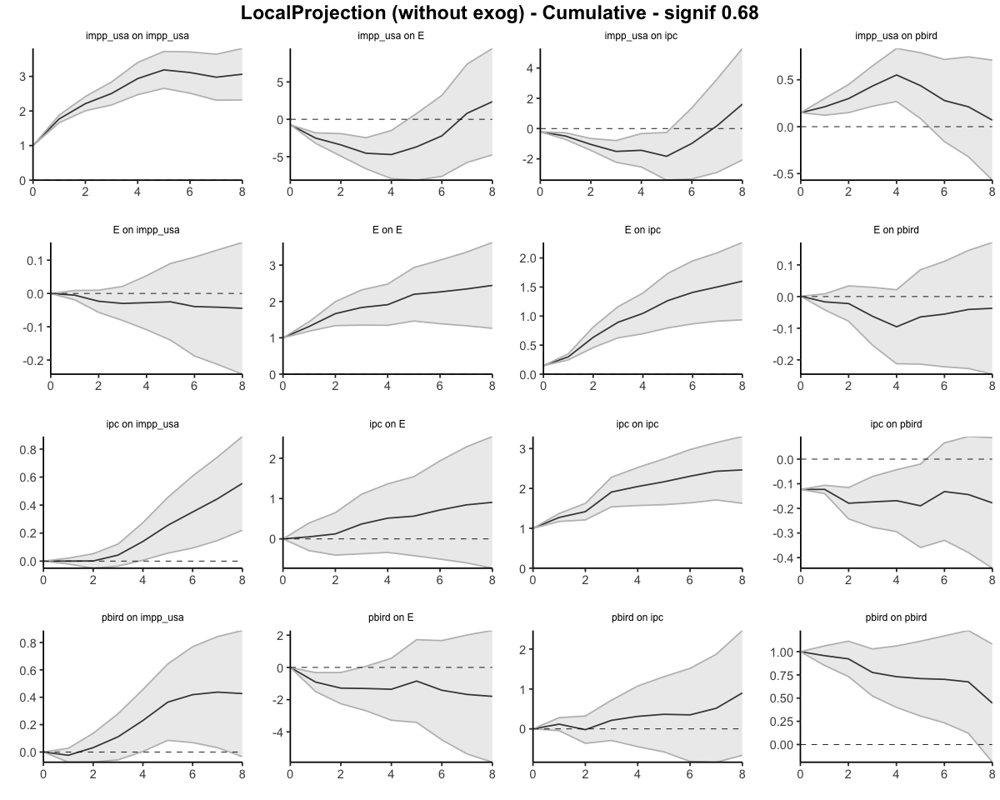

In [50]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 3 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1459         0.1459       1.0000
         1              0.2983         0.2272       1.3132
         2              0.6338         0.3806       1.6654
         3              0.8936         0.4872       1.8343
         4              1.0464         0.5473       1.9118
         5              1.2659         0.5760       2.1976
         6              1.4076         0.6220       2.2632
         7              1.5024         0.6413       2.3429
         8              1.6011         0.6556       2.4424
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1459             0.1459
                  0.1524             0.0813
                  0.3355             0.1534
                  0.2597             0.1066
                  0.1528             0.0602
       

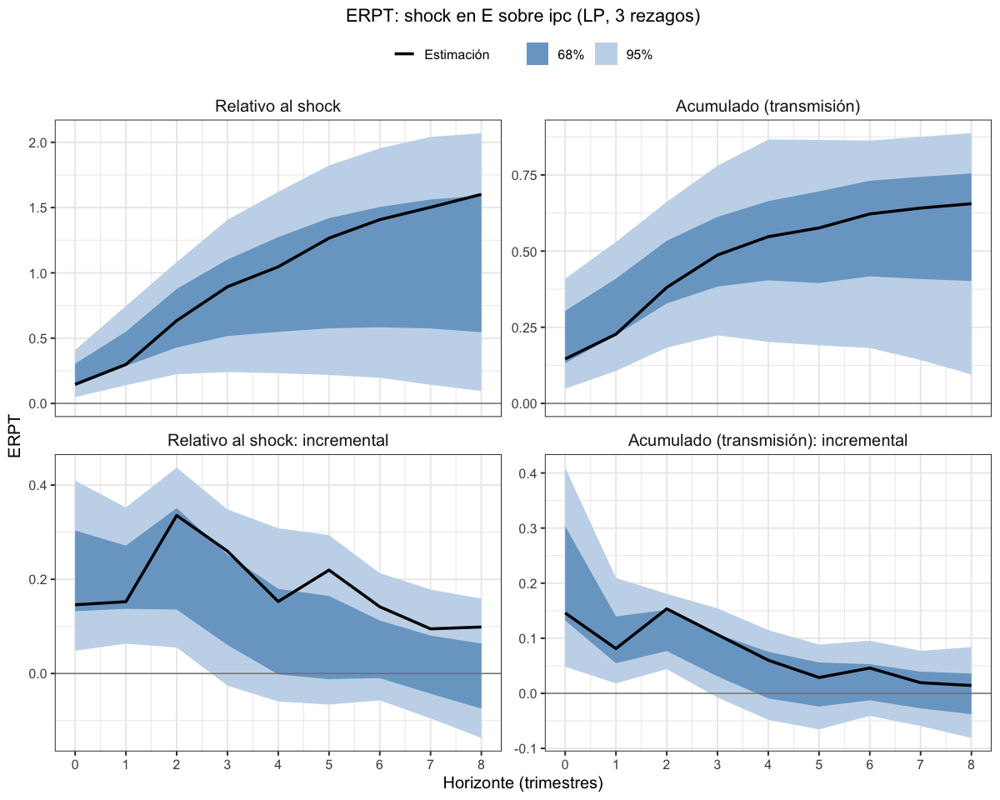

In [93]:
# Todas endógenas, 3 rezagos
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_82, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 3, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa82_endog_p3")

### impp_usa 1950 a 1982 - 1 exógena y el resto endógenas - Selected orders: 1, 2 y 3 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.000000000,0.0000000
20,ipc,E,1,0.2973499,0.200152289,0.3945476
21,ipc,E,2,0.2940243,0.096584051,0.4914645
22,ipc,E,3,0.4425486,0.295886644,0.5892106
23,ipc,E,4,0.3029226,0.190868300,0.4149769
24,ipc,E,5,0.1113775,-0.015866281,0.2386214
25,ipc,E,6,0.2326453,0.081310547,0.3839800
26,ipc,E,7,0.1738028,0.006956047,0.3406495
27,ipc,E,8,0.2214676,0.037379016,0.4055563


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.000000000
38,pbird,E,1,-0.97769624,-1.6322336,-0.323158904
39,pbird,E,2,-0.41194970,-0.7633702,-0.060529164
40,pbird,E,3,0.03546304,-0.3956222,0.466548285
41,pbird,E,4,-0.17533020,-0.7173661,0.366705655
42,pbird,E,5,0.51516109,-0.2056242,1.235946347
43,pbird,E,6,-0.54496064,-1.0935495,0.003628188
44,pbird,E,7,-0.31941750,-0.8999248,0.261089777
45,pbird,E,8,-0.11755704,-0.5693072,0.334193119


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.19686812,0.19686812,0.1968681
2,E,ipc,1,0.27251791,0.20726233,0.3377735
3,E,ipc,2,0.39487229,0.25116207,0.5385825
4,E,ipc,3,0.28938256,0.18431610,0.3944490
5,E,ipc,4,0.23326635,0.08100937,0.3855233
6,E,ipc,5,0.25103455,0.11612132,0.3859478
7,E,ipc,6,0.16243962,0.06755111,0.2573281
8,E,ipc,7,0.11362247,0.02316632,0.2040786
9,E,ipc,8,0.09792339,-0.01050254,0.2063493


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.00000000
47,pbird,ipc,1,0.05775838,-0.12317119,0.23868794
48,pbird,ipc,2,-0.15687623,-0.33390703,0.02015456
49,pbird,ipc,3,0.23312791,0.06412414,0.40213168
50,pbird,ipc,4,0.03537512,-0.17990465,0.25065489
51,pbird,ipc,5,0.02104273,-0.19061588,0.23270135
52,pbird,ipc,6,-0.01786629,-0.32790619,0.29217360
53,pbird,ipc,7,0.13864395,-0.06722435,0.34451225
54,pbird,ipc,8,0.40176199,0.17228069,0.63124329


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.0006891516,0.0006891516,0.0006891516
11,E,pbird,1,-0.0201465339,-0.0461400458,0.0058469780
12,E,pbird,2,-0.0107589125,-0.0351349603,0.0136171353
13,E,pbird,3,-0.0395926582,-0.0698044276,-0.0093808888
14,E,pbird,4,-0.0182476813,-0.0406301411,0.0041347785
15,E,pbird,5,0.0300667606,0.0034332004,0.0567003209
16,E,pbird,6,0.0104913550,-0.0075731150,0.0285558249
17,E,pbird,7,0.0136300932,-0.0094709847,0.0367311712
18,E,pbird,8,0.0074946519,-0.0123118324,0.0273011361


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.078462273,-0.07846227,-0.0784622733
29,ipc,pbird,1,-0.021591199,-0.04199976,-0.0011826381
30,ipc,pbird,2,-0.028899394,-0.04801196,-0.0097868276
31,ipc,pbird,3,0.038478152,0.01325121,0.0637050922
32,ipc,pbird,4,0.025524166,0.00435643,0.0466919011
33,ipc,pbird,5,-0.017464566,-0.03443753,-0.0004916024
34,ipc,pbird,6,0.003250242,-0.02333351,0.0298339931
35,ipc,pbird,7,-0.029740381,-0.06394723,0.0044664655
36,ipc,pbird,8,-0.036271587,-0.05318079,-0.0193623809


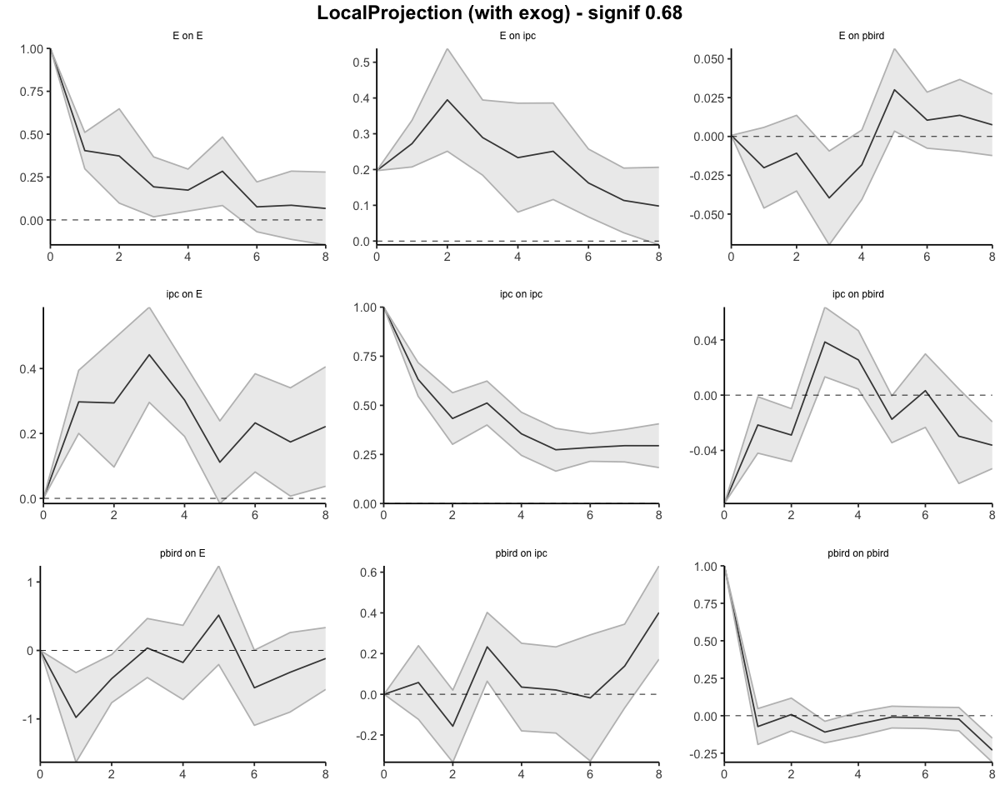

In [53]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.0000000,0.0000000
20,ipc,E,1,0.2973499,0.2001523,0.3945476
21,ipc,E,2,0.5913742,0.2967363,0.8860121
22,ipc,E,3,1.0339228,0.5926230,1.4752227
23,ipc,E,4,1.3368454,0.7834913,1.8901996
24,ipc,E,5,1.4482230,0.7676250,2.1288209
25,ipc,E,6,1.6808683,0.8489355,2.5128010
26,ipc,E,7,1.8546711,0.8558916,2.8534505
27,ipc,E,8,2.0761387,0.8932706,3.2590068


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.00000000
38,pbird,E,1,-0.9776962,-1.632234,-0.32315890
39,pbird,E,2,-1.3896459,-2.395604,-0.38368807
40,pbird,E,3,-1.3541829,-2.791226,0.08286022
41,pbird,E,4,-1.5295131,-3.508592,0.44956587
42,pbird,E,5,-1.0143520,-3.714216,1.68551222
43,pbird,E,6,-1.5593126,-4.807766,1.68914041
44,pbird,E,7,-1.8787301,-5.707690,1.95023018
45,pbird,E,8,-1.9962872,-6.276998,2.28442330


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.1968681,0.1968681,0.1968681
2,E,ipc,1,0.4693860,0.4041305,0.5346416
3,E,ipc,2,0.8642583,0.6552925,1.0732241
4,E,ipc,3,1.1536409,0.8396086,1.4676731
5,E,ipc,4,1.3869072,0.9206180,1.8531965
6,E,ipc,5,1.6379418,1.0367393,2.2391443
7,E,ipc,6,1.8003814,1.1042904,2.4964724
8,E,ipc,7,1.9140039,1.1274567,2.7005510
9,E,ipc,8,2.0119273,1.1169542,2.9069003


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,0.05775838,-0.1231712,0.2386879
48,pbird,ipc,2,-0.09911786,-0.4570782,0.2588425
49,pbird,ipc,3,0.13401005,-0.3929541,0.6609742
50,pbird,ipc,4,0.16938517,-0.5728587,0.9116291
51,pbird,ipc,5,0.19042790,-0.7634746,1.1443304
52,pbird,ipc,6,0.17256161,-1.0913808,1.4365040
53,pbird,ipc,7,0.31120556,-1.1586052,1.7810163
54,pbird,ipc,8,0.71296755,-0.9863245,2.4122596


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.0006891516,0.0006891516,0.0006891516
11,E,pbird,1,-0.0194573823,-0.0454508942,0.0065361296
12,E,pbird,2,-0.0302162948,-0.0805858545,0.0201532649
13,E,pbird,3,-0.0698089530,-0.1503902820,0.0107723761
14,E,pbird,4,-0.0880566343,-0.1910204232,0.0149071546
15,E,pbird,5,-0.0579898736,-0.1875872228,0.0716074755
16,E,pbird,6,-0.0474985187,-0.1951603378,0.1001633004
17,E,pbird,7,-0.0338684254,-0.2046313225,0.1368944716
18,E,pbird,8,-0.0263737736,-0.2169431548,0.1641956077


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.07846227,-0.07846227,-0.07846227
29,ipc,pbird,1,-0.10005347,-0.12046203,-0.07964491
30,ipc,pbird,2,-0.12895287,-0.16847399,-0.08943174
31,ipc,pbird,3,-0.09047471,-0.15522278,-0.02572665
32,ipc,pbird,4,-0.06495055,-0.15086635,0.02096525
33,ipc,pbird,5,-0.08241511,-0.18530388,0.02047365
34,ipc,pbird,6,-0.07916487,-0.20863739,0.05030764
35,ipc,pbird,7,-0.10890525,-0.27258462,0.05477411
36,ipc,pbird,8,-0.14517684,-0.32576541,0.03541173


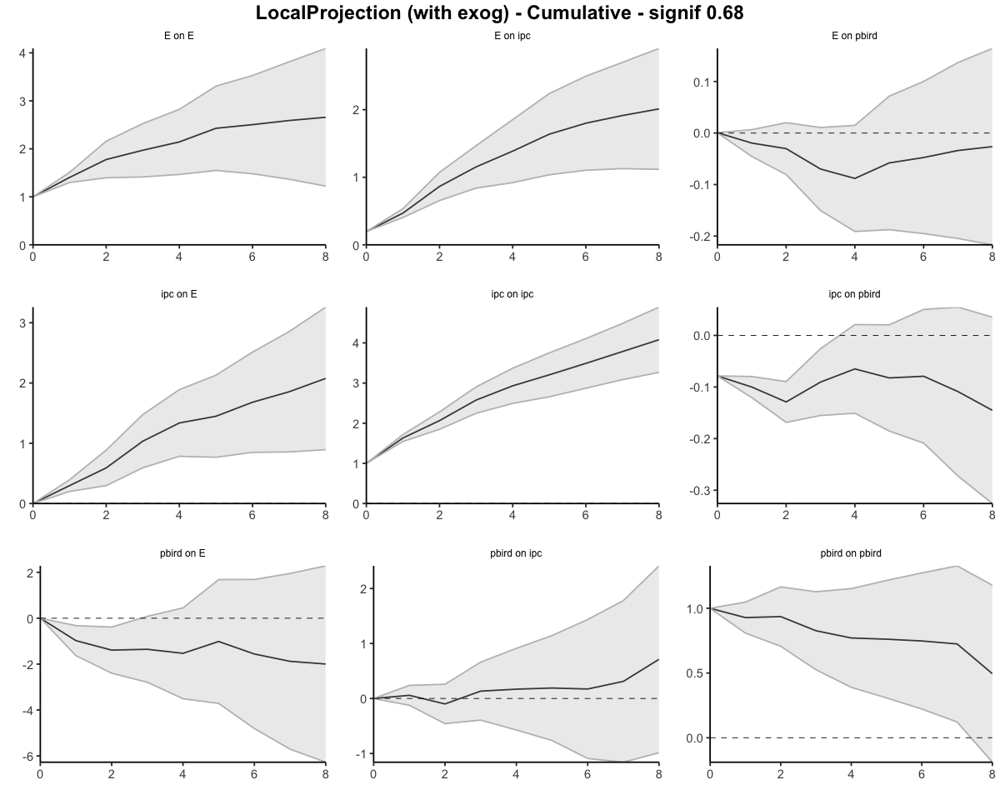

In [52]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1969         0.1969       1.0000
         1              0.4694         0.3343       1.4043
         2              0.8643         0.4863       1.7773
         3              1.1536         0.5855       1.9702
         4              1.3869         0.6468       2.1442
         5              1.6379         0.6746       2.4280
         6              1.8004         0.7189       2.5044
         7              1.9140         0.7390       2.5900
         8              2.0119         0.7572       2.6570
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1969             0.1969
                  0.2725             0.1374
                  0.3949             0.1520
                  0.2894             0.0993
                  0.2333       

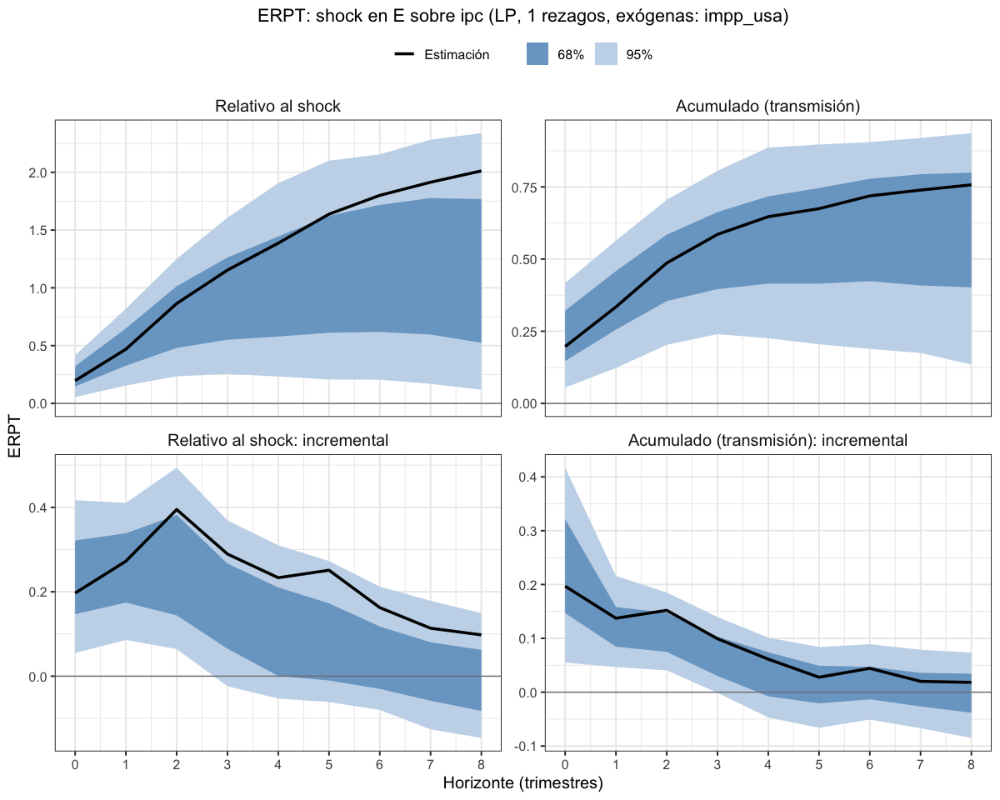

In [81]:
# impp_usa exógena, 1 rezago
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_82, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa82_exog_p1")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.0000000
20,ipc,E,1,0.01437613,-0.29315072,0.3219030
21,ipc,E,2,0.06477639,-0.18595184,0.3155046
22,ipc,E,3,0.36826055,0.22371287,0.5128082
23,ipc,E,4,0.06121253,-0.10193225,0.2243573
24,ipc,E,5,0.07916749,-0.05942534,0.2177603
25,ipc,E,6,0.17644564,-0.03086809,0.3837594
26,ipc,E,7,0.09332703,-0.03203911,0.2186932
27,ipc,E,8,0.05963575,-0.08562485,0.2048963


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000000,0.0000000,0.00000000
38,pbird,E,1,-0.9004883461,-1.4737351,-0.32724160
39,pbird,E,2,-0.3939926160,-0.7613169,-0.02666834
40,pbird,E,3,-0.0003115404,-0.4238270,0.42320390
41,pbird,E,4,-0.1376139695,-0.6932365,0.41800859
42,pbird,E,5,0.4513212395,-0.1912634,1.09390589
43,pbird,E,6,-0.6066981295,-1.1675843,-0.04581193
44,pbird,E,7,-0.3923231644,-0.9787332,0.19408688
45,pbird,E,8,-0.1956658359,-0.6225151,0.23118341


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.16613668,0.16613668,0.1661367
2,E,ipc,1,0.17218027,0.10926445,0.2350961
3,E,ipc,2,0.33522287,0.20590150,0.4645442
4,E,ipc,3,0.27792390,0.18672447,0.3691233
5,E,ipc,4,0.17168719,0.07059002,0.2727843
6,E,ipc,5,0.22686025,0.09785229,0.3558682
7,E,ipc,6,0.14616547,0.07980357,0.2125274
8,E,ipc,7,0.10260532,0.05057844,0.1546322
9,E,ipc,8,0.08683161,0.01401038,0.1596528


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.00000000
47,pbird,ipc,1,0.12182281,-0.05694910,0.30059471
48,pbird,ipc,2,-0.16736973,-0.34635709,0.01161763
49,pbird,ipc,3,0.23143384,0.04652178,0.41634590
50,pbird,ipc,4,0.05786857,-0.21453213,0.33026926
51,pbird,ipc,5,0.00387231,-0.19400410,0.20174872
52,pbird,ipc,6,-0.05085051,-0.31537512,0.21367409
53,pbird,ipc,7,0.12073610,-0.12798471,0.36945691
54,pbird,ipc,8,0.35225752,0.14740233,0.55711271


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.0005199222,5.199222e-04,0.0005199222
11,E,pbird,1,-0.0187922223,-4.517934e-02,0.0075948940
12,E,pbird,2,-0.0057569560,-3.296054e-02,0.0214466278
13,E,pbird,3,-0.0401626951,-7.495029e-02,-0.0053750993
14,E,pbird,4,-0.0343747826,-5.775912e-02,-0.0109904494
15,E,pbird,5,0.0293322595,-6.226695e-05,0.0587267859
16,E,pbird,6,0.0114969306,-2.306693e-03,0.0253005538
17,E,pbird,7,0.0127388590,-1.195498e-02,0.0374326957
18,E,pbird,8,0.0046194837,-1.447536e-02,0.0237143245


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.093604438,-0.09360444,-0.093604438
29,ipc,pbird,1,-0.008888733,-0.02805895,0.010281482
30,ipc,pbird,2,-0.050789989,-0.08761209,-0.013967888
31,ipc,pbird,3,0.044228479,0.01181741,0.076639547
32,ipc,pbird,4,0.009911331,-0.01066246,0.030485121
33,ipc,pbird,5,-0.024273315,-0.05021271,0.001666082
34,ipc,pbird,6,0.040041972,0.02465412,0.055429825
35,ipc,pbird,7,0.002655193,-0.04735861,0.052668996
36,ipc,pbird,8,-0.040604997,-0.05772242,-0.023487577


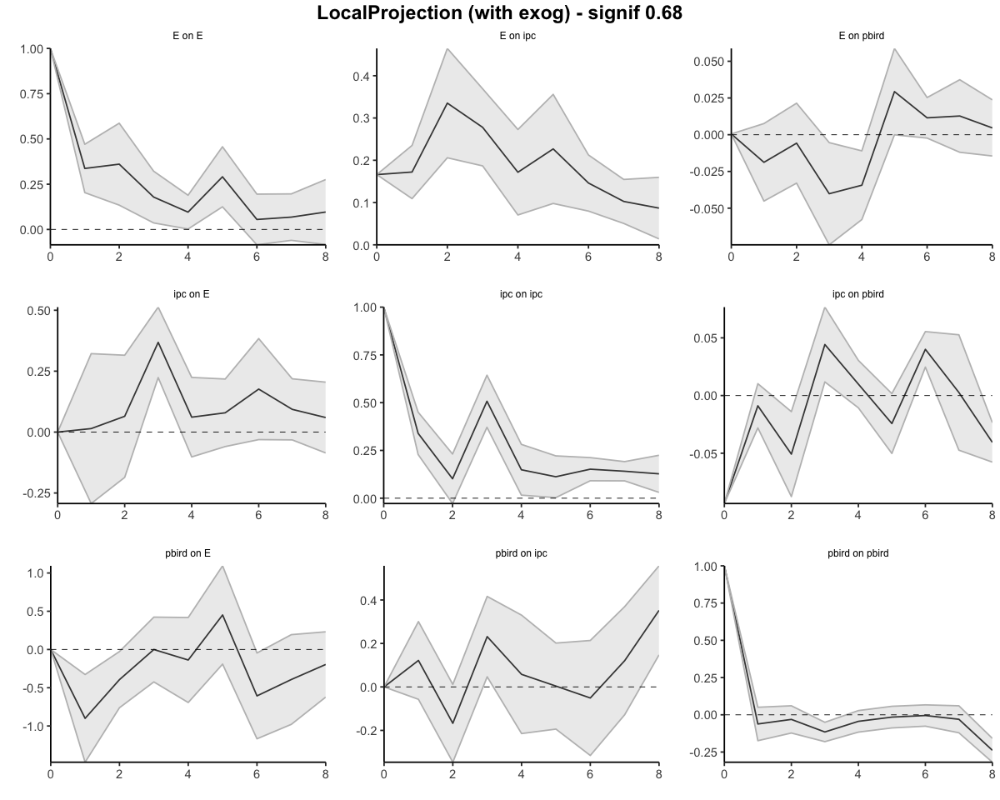

In [55]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.0000000,0.0000000
20,ipc,E,1,0.01437613,-0.2931507,0.3219030
21,ipc,E,2,0.07915252,-0.4791026,0.6374076
22,ipc,E,3,0.44741308,-0.2553897,1.1502158
23,ipc,E,4,0.50862560,-0.3573219,1.3745731
24,ipc,E,5,0.58779310,-0.4167473,1.5923335
25,ipc,E,6,0.76423874,-0.4476154,1.9760928
26,ipc,E,7,0.85756577,-0.4796545,2.1947860
27,ipc,E,8,0.91720152,-0.5652793,2.3996824


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.00000000
38,pbird,E,1,-0.9004883,-1.473735,-0.32724160
39,pbird,E,2,-1.2944810,-2.235052,-0.35390994
40,pbird,E,3,-1.2947925,-2.658879,0.06929396
41,pbird,E,4,-1.4324065,-3.352115,0.48730255
42,pbird,E,5,-0.9810852,-3.543379,1.58120844
43,pbird,E,6,-1.5877834,-4.710963,1.53539651
44,pbird,E,7,-1.9801065,-5.689696,1.72948339
45,pbird,E,8,-2.1757724,-6.312212,1.96066680


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.1661367,0.1661367,0.1661367
2,E,ipc,1,0.3383170,0.2754011,0.4012328
3,E,ipc,2,0.6735398,0.4813026,0.8657770
4,E,ipc,3,0.9514637,0.6680271,1.2349003
5,E,ipc,4,1.1231509,0.7386171,1.5076847
6,E,ipc,5,1.3500112,0.8364694,1.8635529
7,E,ipc,6,1.4961766,0.9162730,2.0760803
8,E,ipc,7,1.5987819,0.9668514,2.2307125
9,E,ipc,8,1.6856136,0.9808618,2.3903653


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,0.12182281,-0.0569491,0.3005947
48,pbird,ipc,2,-0.04554693,-0.4033062,0.3122123
49,pbird,ipc,3,0.18588691,-0.3567844,0.7285582
50,pbird,ipc,4,0.24375548,-0.5713165,1.0588275
51,pbird,ipc,5,0.24762779,-0.7653206,1.2605762
52,pbird,ipc,6,0.19677728,-1.0806958,1.4742503
53,pbird,ipc,7,0.31751338,-1.2086805,1.8437072
54,pbird,ipc,8,0.66977090,-1.0612781,2.4008199


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,0.0005199222,0.0005199222,0.0005199222
11,E,pbird,1,-0.0182723000,-0.0446594163,0.0081148162
12,E,pbird,2,-0.0240292560,-0.0776199561,0.0295614441
13,E,pbird,3,-0.0641919511,-0.1525702470,0.0241863448
14,E,pbird,4,-0.0985667337,-0.2103293628,0.0131958954
15,E,pbird,5,-0.0692344743,-0.2103916298,0.0719226813
16,E,pbird,6,-0.0577375437,-0.2126983225,0.0972232351
17,E,pbird,7,-0.0449986846,-0.2246533001,0.1346559308
18,E,pbird,8,-0.0403792009,-0.2391286572,0.1583702553


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.09360444,-0.09360444,-0.093604438
29,ipc,pbird,1,-0.10249317,-0.12166338,-0.083322956
30,ipc,pbird,2,-0.15328316,-0.20927547,-0.097290845
31,ipc,pbird,3,-0.10905468,-0.19745806,-0.020651298
32,ipc,pbird,4,-0.09914335,-0.20812052,0.009833823
33,ipc,pbird,5,-0.12341667,-0.25833324,0.011499905
34,ipc,pbird,6,-0.08337469,-0.23367912,0.066929730
35,ipc,pbird,7,-0.08071950,-0.28103773,0.119598726
36,ipc,pbird,8,-0.12132450,-0.33876014,0.096111149


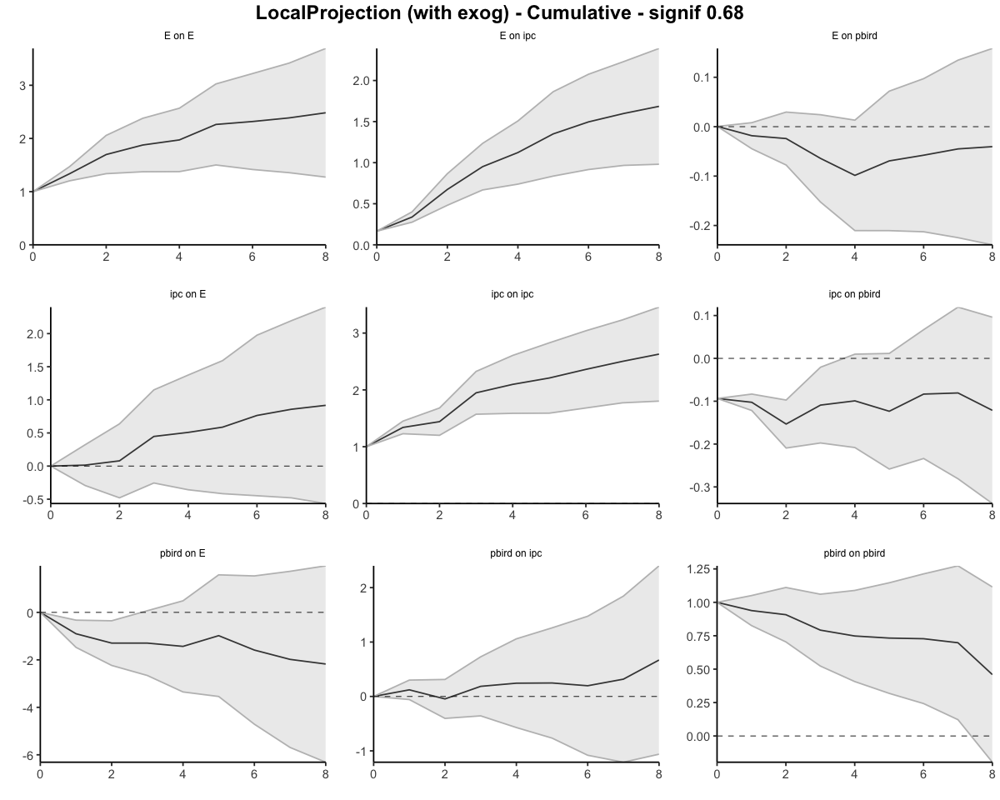

In [54]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 2 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1661         0.1661       1.0000
         1              0.3383         0.2530       1.3370
         2              0.6735         0.3967       1.6977
         3              0.9515         0.5070       1.8767
         4              1.1232         0.5694       1.9724
         5              1.3500         0.5965       2.2634
         6              1.4962         0.6453       2.3185
         7              1.5988         0.6699       2.3867
         8              1.6856         0.6789       2.4830
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1661             0.1661
                  0.1722             0.0869
                  0.3352             0.1437
                  0.2779             0.1103
                  0.1717       

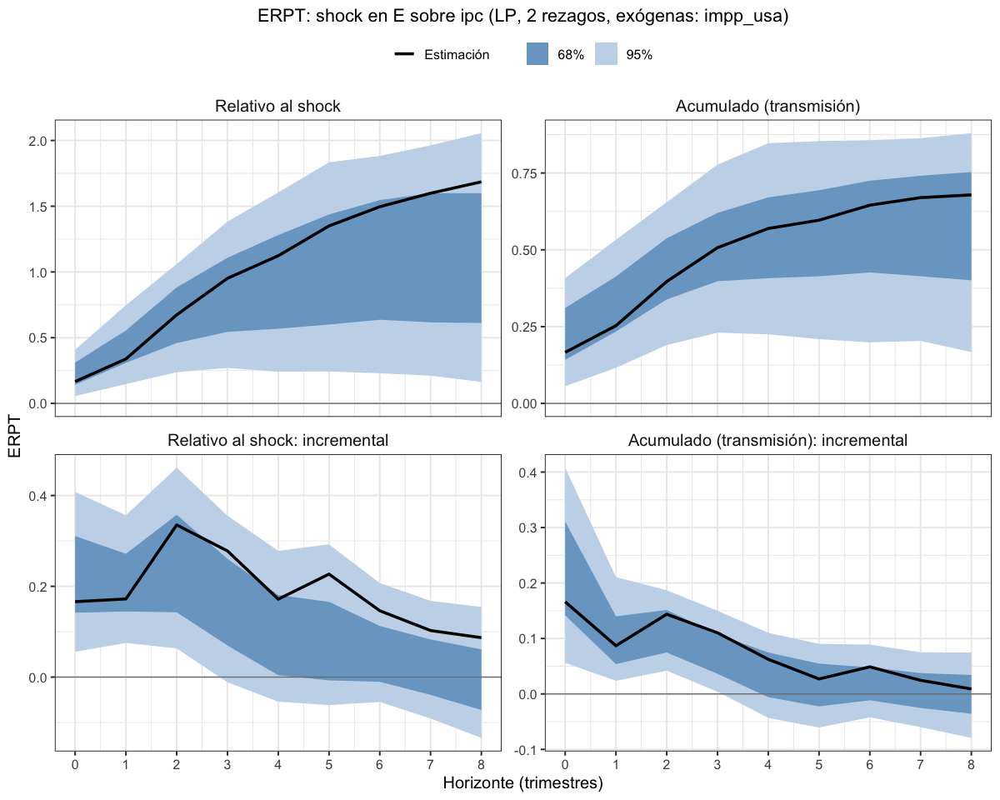

In [82]:
# impp_usa exógena, 2 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_82, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 2, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa82_exog_p2")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.0000000
20,ipc,E,1,0.05359354,-0.28887834,0.3960654
21,ipc,E,2,0.07267626,-0.10895485,0.2543074
22,ipc,E,3,0.24476496,0.03300719,0.4565227
23,ipc,E,4,0.14534536,0.03517454,0.2555162
24,ipc,E,5,0.04897669,-0.07983696,0.1777903
25,ipc,E,6,0.15442868,-0.08335059,0.3922080
26,ipc,E,7,0.12625173,-0.09111445,0.3436179
27,ipc,E,8,0.06365539,-0.13178058,0.2590914


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.000000000
38,pbird,E,1,-0.90841616,-1.4957379,-0.321094433
39,pbird,E,2,-0.37477436,-0.7568783,0.007329562
40,pbird,E,3,-0.02325818,-0.4346123,0.388095988
41,pbird,E,4,-0.04750027,-0.5887211,0.493720609
42,pbird,E,5,0.50890766,-0.1340120,1.151827315
43,pbird,E,6,-0.57020580,-1.0836650,-0.056746607
44,pbird,E,7,-0.26045068,-0.8723105,0.351409108
45,pbird,E,8,-0.11818559,-0.5112191,0.274847870


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.14700600,0.14700600,0.1470060
2,E,ipc,1,0.15256265,0.10007314,0.2050522
3,E,ipc,2,0.33585718,0.21156449,0.4601499
4,E,ipc,3,0.25995330,0.16892969,0.3509769
5,E,ipc,4,0.15279835,0.07056947,0.2350272
6,E,ipc,5,0.21961837,0.10117165,0.3380651
7,E,ipc,6,0.14184823,0.06934675,0.2143497
8,E,ipc,7,0.09470841,0.04835198,0.1410648
9,E,ipc,8,0.09821239,0.02046893,0.1759558


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.00000000
47,pbird,ipc,1,0.11857620,-0.04478227,0.28193467
48,pbird,ipc,2,-0.13847849,-0.31727231,0.04031533
49,pbird,ipc,3,0.23453840,0.07143724,0.39763956
50,pbird,ipc,4,0.09902297,-0.15552208,0.35356803
51,pbird,ipc,5,0.05203320,-0.13003619,0.23410259
52,pbird,ipc,6,-0.01454128,-0.23808105,0.20899849
53,pbird,ipc,7,0.16566375,-0.02108476,0.35241226
54,pbird,ipc,8,0.38468556,0.17228766,0.59708346


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.0004653298,-0.0004653298,-0.0004653298
11,E,pbird,1,-0.0177725594,-0.0428901975,0.0073450788
12,E,pbird,2,-0.0053590694,-0.0358440745,0.0251259356
13,E,pbird,3,-0.0399774400,-0.0756545794,-0.0043003005
14,E,pbird,4,-0.0330852201,-0.0582670146,-0.0079034256
15,E,pbird,5,0.0311403098,-0.0012007071,0.0634813267
16,E,pbird,6,0.0089961463,-0.0083466888,0.0263389814
17,E,pbird,7,0.0146504813,-0.0051836518,0.0344846145
18,E,pbird,8,0.0039177376,-0.0175321315,0.0253676067


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-1.246522e-01,-0.12465224,-0.124652240
29,ipc,pbird,1,-3.513521e-05,-0.01667073,0.016600457
30,ipc,pbird,2,-5.597581e-02,-0.10281075,-0.009140875
31,ipc,pbird,3,5.683956e-03,-0.03363779,0.045005704
32,ipc,pbird,4,4.946432e-03,-0.01731304,0.027205904
33,ipc,pbird,5,-2.075399e-02,-0.06453581,0.023027824
34,ipc,pbird,6,5.773422e-02,0.02952238,0.085946056
35,ipc,pbird,7,-1.196326e-02,-0.04972025,0.025793730
36,ipc,pbird,8,-3.350941e-02,-0.06268784,-0.004330985


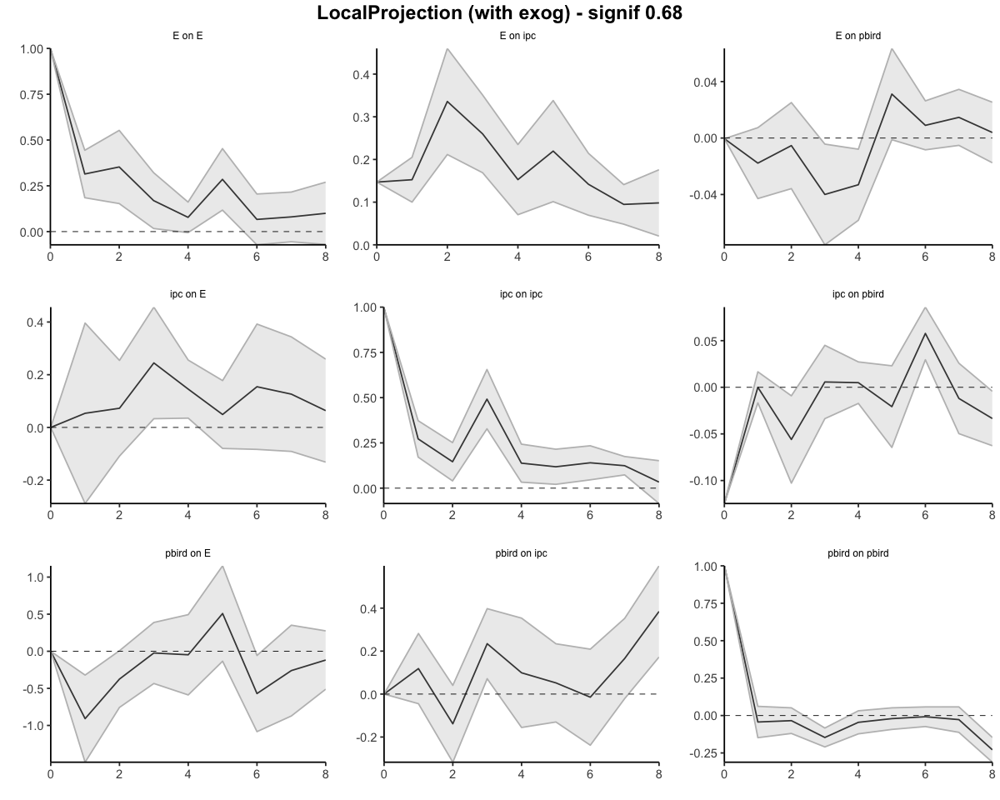

In [57]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,131,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.0000000,0.0000000
20,ipc,E,1,0.05359354,-0.2888783,0.3960654
21,ipc,E,2,0.12626980,-0.3978332,0.6503728
22,ipc,E,3,0.37103476,-0.3648260,1.1068955
23,ipc,E,4,0.51638012,-0.3296515,1.3624117
24,ipc,E,5,0.56535681,-0.4094884,1.5402020
25,ipc,E,6,0.71978549,-0.4928390,1.9324100
26,ipc,E,7,0.84603722,-0.5839535,2.2760279
27,ipc,E,8,0.90969262,-0.7157340,2.5351193


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.00000000
38,pbird,E,1,-0.9084162,-1.495738,-0.32109443
39,pbird,E,2,-1.2831905,-2.252616,-0.31376487
40,pbird,E,3,-1.3064487,-2.687229,0.07433112
41,pbird,E,4,-1.3539490,-3.275950,0.56805173
42,pbird,E,5,-0.8450413,-3.409962,1.71987904
43,pbird,E,6,-1.4152471,-4.493627,1.66313243
44,pbird,E,7,-1.6756978,-5.365937,2.01454154
45,pbird,E,8,-1.7938834,-5.877156,2.28938941


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.1470060,0.1470060,0.1470060
2,E,ipc,1,0.2995687,0.2470791,0.3520582
3,E,ipc,2,0.6354258,0.4586436,0.8122080
4,E,ipc,3,0.8953791,0.6275733,1.1631849
5,E,ipc,4,1.0481775,0.6981428,1.3982122
6,E,ipc,5,1.2677959,0.7993144,1.7362773
7,E,ipc,6,1.4096441,0.8686612,1.9506270
8,E,ipc,7,1.5043525,0.9170132,2.0916918
9,E,ipc,8,1.6025649,0.9374821,2.2676477


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.0000000
47,pbird,ipc,1,0.11857620,-0.04478227,0.2819347
48,pbird,ipc,2,-0.01990229,-0.36205458,0.3222500
49,pbird,ipc,3,0.21463611,-0.29061734,0.7198896
50,pbird,ipc,4,0.31365908,-0.44613942,1.0734576
51,pbird,ipc,5,0.36569228,-0.57617561,1.3075602
52,pbird,ipc,6,0.35115100,-0.81425667,1.5165587
53,pbird,ipc,7,0.51681475,-0.83534143,1.8689709
54,pbird,ipc,8,0.90150031,-0.66305376,2.4660544


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.0004653298,-0.0004653298,-0.0004653298
11,E,pbird,1,-0.0182378892,-0.0433555273,0.0068797489
12,E,pbird,2,-0.0235969586,-0.0791996018,0.0320056846
13,E,pbird,3,-0.0635743986,-0.1548541813,0.0277053840
14,E,pbird,4,-0.0966596187,-0.2131211959,0.0198019585
15,E,pbird,5,-0.0655193089,-0.2143219030,0.0832832852
16,E,pbird,6,-0.0565231626,-0.2226685918,0.1096222666
17,E,pbird,7,-0.0418726812,-0.2278522436,0.1441068811
18,E,pbird,8,-0.0379549436,-0.2453843751,0.1694744878


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.1246522,-0.1246522,-0.12465224
29,ipc,pbird,1,-0.1246874,-0.1413230,-0.10805178
30,ipc,pbird,2,-0.1806632,-0.2441337,-0.11719266
31,ipc,pbird,3,-0.1749792,-0.2777715,-0.07218695
32,ipc,pbird,4,-0.1700328,-0.2950845,-0.04498105
33,ipc,pbird,5,-0.1907868,-0.3596204,-0.02195323
34,ipc,pbird,6,-0.1330526,-0.3300980,0.06399283
35,ipc,pbird,7,-0.1450158,-0.3798182,0.08978656
36,ipc,pbird,8,-0.1785252,-0.4425061,0.08545558


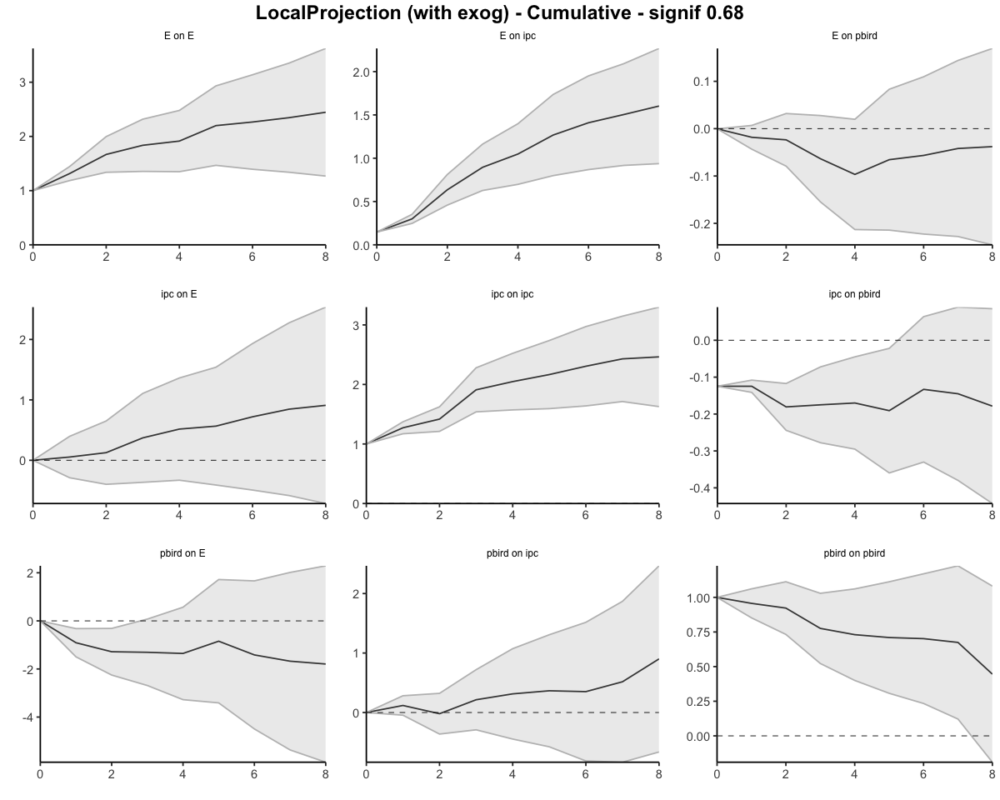

In [56]:
res <- run_lp_model(df_ERPT_Arg_1950_82, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 3 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.1470         0.1470       1.0000
         1              0.2996         0.2279       1.3145
         2              0.6354         0.3811       1.6674
         3              0.8954         0.4875       1.8365
         4              1.0482         0.5475       1.9143
         5              1.2678         0.5764       2.1995
         6              1.4096         0.6221       2.2659
         7              1.5044         0.6412       2.3461
         8              1.6026         0.6552       2.4459
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.1470             0.1470
                  0.1526             0.0809
                  0.3359             0.1532
                  0.2600             0.1064
                  0.1528       

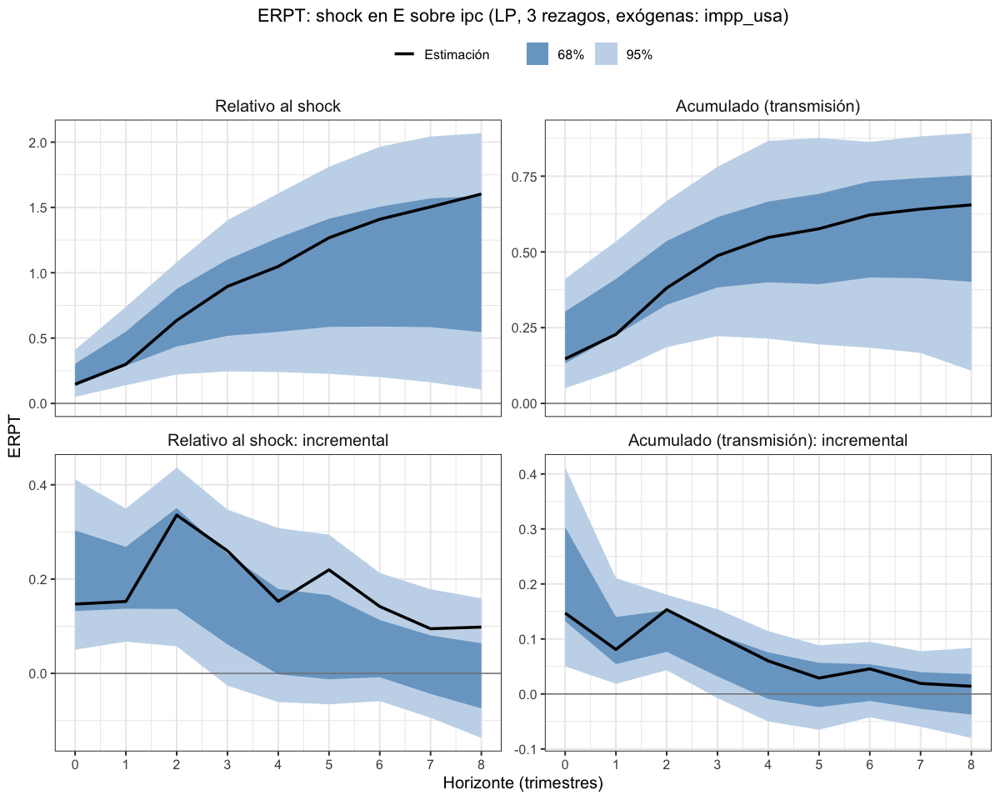

In [83]:
# impp_usa exógena, 3 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_82, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 3, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa82_exog_p3")

### impp_usa 1950 a 1987 - Todas endógenas - Selected orders: 1

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,151,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.6019405,-0.60194051,-0.6019405
2,impp_usa,E,1,-0.7762271,-1.09498049,-0.4574737
3,impp_usa,E,2,-0.2238367,-0.68169951,0.2340261
4,impp_usa,E,3,0.2686151,-0.68333814,1.2205683
5,impp_usa,E,4,1.1944167,-0.08071575,2.4695492
6,impp_usa,E,5,1.7810478,0.32613321,3.2359624
7,impp_usa,E,6,1.7154454,0.43776379,2.9931270
8,impp_usa,E,7,1.9431468,0.76753151,3.1187621
9,impp_usa,E,8,1.4439639,0.46765322,2.4202746


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000,0.000000000,0.0000000
65,ipc,E,1,0.4763954,0.362356032,0.5904348
66,ipc,E,2,0.4386711,0.207353172,0.6699891
67,ipc,E,3,0.5570540,0.313674448,0.8004335
68,ipc,E,4,0.4837845,0.276233417,0.6913357
69,ipc,E,5,0.2523679,-0.017943612,0.5226795
70,ipc,E,6,0.3523225,0.065760495,0.6388845
71,ipc,E,7,0.2840283,-0.019061925,0.5871186
72,ipc,E,8,0.2481128,-0.005990702,0.5022163


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.000000000,0.00000000
92,pbird,E,1,-0.62950637,-1.240657811,-0.01835492
93,pbird,E,2,0.15464277,-0.226600868,0.53588640
94,pbird,E,3,0.52124540,0.003591916,1.03889888
95,pbird,E,4,0.45922061,-0.116374211,1.03481544
96,pbird,E,5,1.16618636,0.425067195,1.90730553
97,pbird,E,6,-0.18830018,-0.838657350,0.46205699
98,pbird,E,7,-0.02099653,-0.843855452,0.80186239
99,pbird,E,8,0.04326883,-0.612667049,0.69920470


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.0000000,0.00000000,0.0000000
101,pbird,ipc,1,0.3307897,0.13136020,0.5302192
102,pbird,ipc,2,0.3294135,0.01688249,0.6419445
103,pbird,ipc,3,0.6216674,0.26425847,0.9790763
104,pbird,ipc,4,0.5952900,0.23491798,0.9556620
105,pbird,ipc,5,0.5345670,0.15824785,0.9108861
106,pbird,ipc,6,0.2321472,-0.23708452,0.7013789
107,pbird,ipc,7,0.3509305,-0.18914955,0.8910106
108,pbird,ipc,8,0.3374053,-0.13762845,0.8124390


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.005306833,-0.005306833,-0.0053068333
47,E,pbird,1,-0.024859957,-0.049142597,-0.0005773172
48,E,pbird,2,-0.007113494,-0.029253055,0.0150260674
49,E,pbird,3,-0.029528862,-0.057549487,-0.0015082365
50,E,pbird,4,-0.008654276,-0.030353205,0.0130446531
51,E,pbird,5,0.016532483,-0.008247016,0.0413119818
52,E,pbird,6,0.003481007,-0.012914219,0.0198762334
53,E,pbird,7,0.012095890,-0.008603953,0.0327957327
54,E,pbird,8,0.005835499,-0.011356636,0.0230276344


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.17826236,0.17826236,0.178262355
20,impp_usa,pbird,1,0.03145371,-0.02543516,0.088342576
21,impp_usa,pbird,2,0.04147034,-0.01703610,0.099976781
22,impp_usa,pbird,3,-0.04510890,-0.09208990,0.001872103
23,impp_usa,pbird,4,-0.14446849,-0.19951851,-0.089418476
24,impp_usa,pbird,5,-0.21223107,-0.26574254,-0.158719604
25,impp_usa,pbird,6,-0.18109321,-0.25574542,-0.106441001
26,impp_usa,pbird,7,-0.14688585,-0.23294841,-0.060823285
27,impp_usa,pbird,8,-0.15926279,-0.23512489,-0.083400688


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.063397726,-0.0633977259,-0.063397726
74,ipc,pbird,1,-0.019894916,-0.0366647617,-0.003125070
75,ipc,pbird,2,-0.025557091,-0.0413420855,-0.009772096
76,ipc,pbird,3,0.025245096,-0.0004184072,0.050908600
77,ipc,pbird,4,0.007349567,-0.0149660441,0.029665179
78,ipc,pbird,5,-0.023900949,-0.0438205484,-0.003981349
79,ipc,pbird,6,-0.010031015,-0.0298158464,0.009753817
80,ipc,pbird,7,-0.034084670,-0.0589852393,-0.009184101
81,ipc,pbird,8,-0.024255226,-0.0414382947,-0.007072158


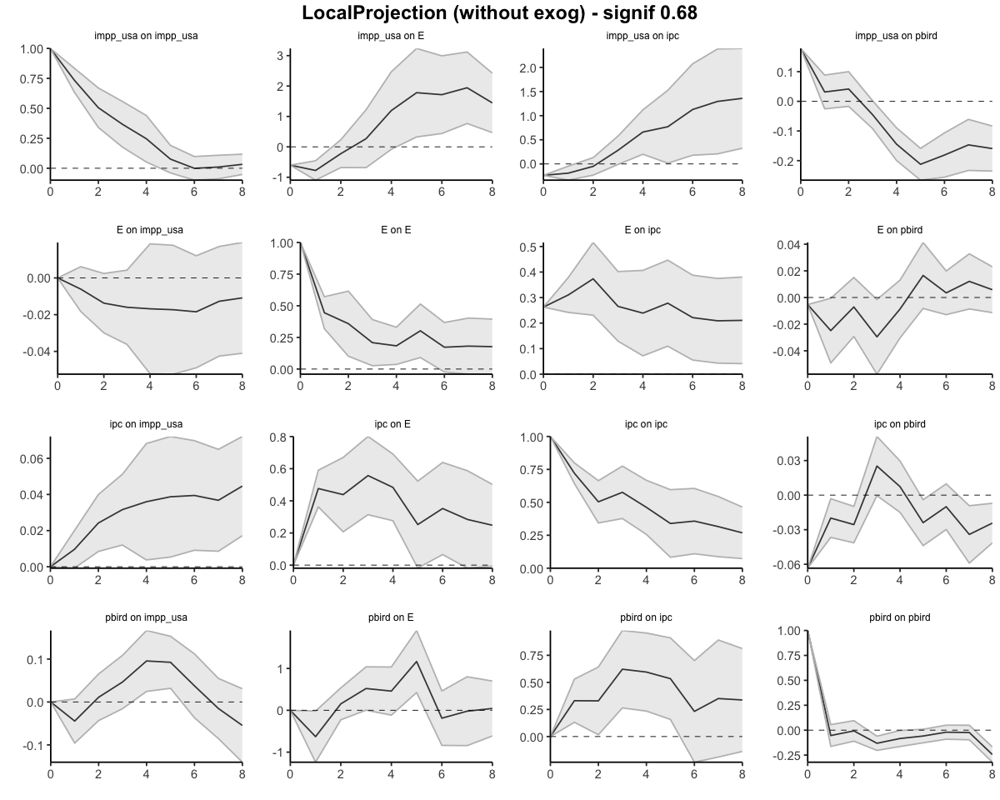

In [58]:
res <- run_lp_model(df_ERPT_Arg_1950_87, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,151,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.6019405,-0.6019405,-0.6019405
2,impp_usa,E,1,-1.3781676,-1.6969210,-1.0594142
3,impp_usa,E,2,-1.6020043,-2.3786205,-0.8253881
4,impp_usa,E,3,-1.3333892,-3.0619586,0.3951802
5,impp_usa,E,4,-0.1389725,-3.1426744,2.8647294
6,impp_usa,E,5,1.6420753,-2.8165412,6.1006919
7,impp_usa,E,6,3.3575208,-2.3787774,9.0938189
8,impp_usa,E,7,5.3006676,-1.6112459,12.2125810
9,impp_usa,E,8,6.7446315,-1.1435927,14.6328556


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.0000000,0.0000000,0.0000000
65,ipc,E,1,0.4763954,0.3623560,0.5904348
66,ipc,E,2,0.9150666,0.5697092,1.2604239
67,ipc,E,3,1.4721205,0.8833837,2.0608574
68,ipc,E,4,1.9559051,1.1596171,2.7521931
69,ipc,E,5,2.2082730,1.1416735,3.2748726
70,ipc,E,6,2.5605955,1.2074340,3.9137571
71,ipc,E,7,2.8446238,1.1883720,4.5008757
72,ipc,E,8,3.0927366,1.1823813,5.0030920


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.000000,0.00000000
92,pbird,E,1,-0.6295064,-1.240658,-0.01835492
93,pbird,E,2,-0.4748636,-1.467259,0.51753148
94,pbird,E,3,0.0463818,-1.463667,1.55643037
95,pbird,E,4,0.5056024,-1.580041,2.59124581
96,pbird,E,5,1.6717888,-1.154974,4.49855134
97,pbird,E,6,1.4834886,-1.993631,4.96060833
98,pbird,E,7,1.4624921,-2.837487,5.76247072
99,pbird,E,8,1.5057609,-3.450154,6.46167542


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.0000000,0.0000000,0.0000000
101,pbird,ipc,1,0.3307897,0.1313602,0.5302192
102,pbird,ipc,2,0.6602032,0.1482427,1.1721637
103,pbird,ipc,3,1.2818706,0.4125012,2.1512400
104,pbird,ipc,4,1.8771606,0.6474191,3.1069020
105,pbird,ipc,5,2.4117275,0.8056670,4.0177881
106,pbird,ipc,6,2.6438747,0.5685825,4.7191669
107,pbird,ipc,7,2.9948052,0.3794329,5.6101776
108,pbird,ipc,8,3.3322105,0.2418045,6.4226166


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.005306833,-0.005306833,-0.005306833
47,E,pbird,1,-0.030166790,-0.054449430,-0.005884150
48,E,pbird,2,-0.037280284,-0.083702485,0.009141917
49,E,pbird,3,-0.066809146,-0.141251972,0.007633680
50,E,pbird,4,-0.075463422,-0.171605177,0.020678334
51,E,pbird,5,-0.058930939,-0.179852193,0.061990315
52,E,pbird,6,-0.055449932,-0.192766413,0.081866549
53,E,pbird,7,-0.043354042,-0.201370365,0.114662281
54,E,pbird,8,-0.037518543,-0.212727001,0.137689916


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.17826236,0.17826236,0.17826236
20,impp_usa,pbird,1,0.20971606,0.15282720,0.26660493
21,impp_usa,pbird,2,0.25118640,0.13579109,0.36658171
22,impp_usa,pbird,3,0.20607750,0.04370119,0.36845381
23,impp_usa,pbird,4,0.06160901,-0.15581732,0.27903534
24,impp_usa,pbird,5,-0.15062206,-0.42155986,0.12031573
25,impp_usa,pbird,6,-0.33171527,-0.67730527,0.01387473
26,impp_usa,pbird,7,-0.47860112,-0.91025368,-0.04694855
27,impp_usa,pbird,8,-0.63786390,-1.14537857,-0.13034924


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.06339773,-0.06339773,-0.0633977259
74,ipc,pbird,1,-0.08329264,-0.10006249,-0.0665227959
75,ipc,pbird,2,-0.10884973,-0.14140457,-0.0762948918
76,ipc,pbird,3,-0.08360464,-0.14182298,-0.0253862918
77,ipc,pbird,4,-0.07625507,-0.15678902,0.0042788871
78,ipc,pbird,5,-0.10015602,-0.20060957,0.0002975379
79,ipc,pbird,6,-0.11018703,-0.23042542,0.0100513547
80,ipc,pbird,7,-0.14427170,-0.28941066,0.0008672539
81,ipc,pbird,8,-0.16852693,-0.33084895,-0.0062049041


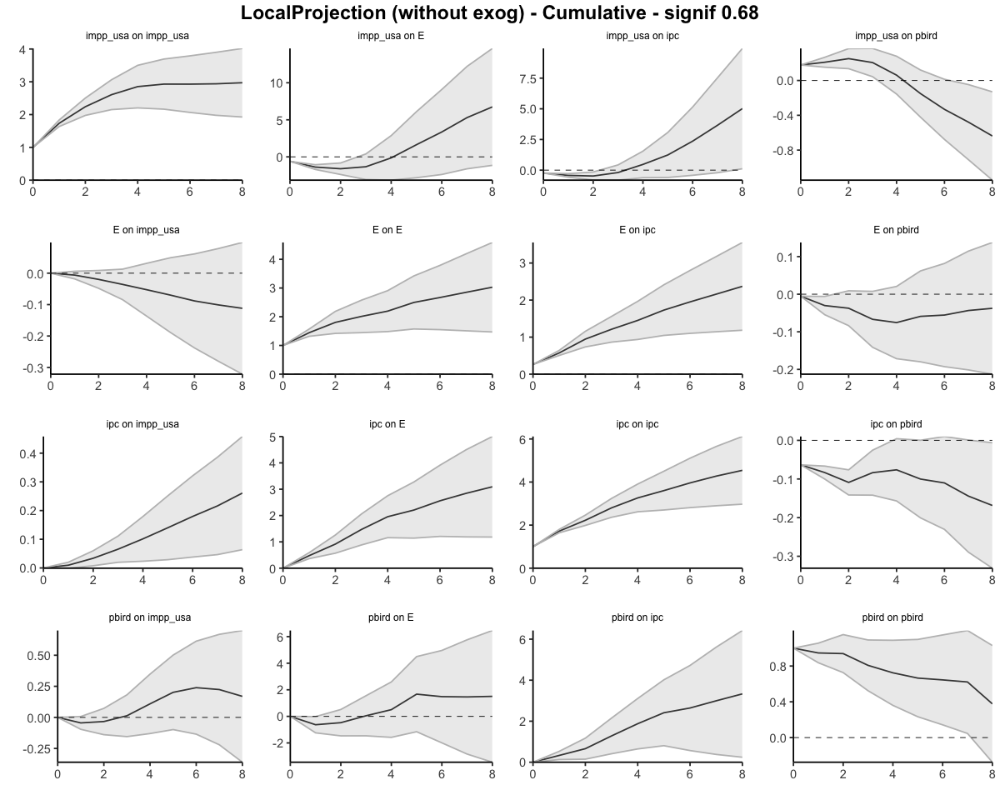

In [59]:
res <- run_lp_model(df_ERPT_Arg_1950_87, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.2628         0.2628       1.0000
         1              0.5731         0.3966       1.4449
         2              0.9465         0.5249       1.8033
         3              1.2121         0.6025       2.0119
         4              1.4513         0.6611       2.1953
         5              1.7294         0.6924       2.4975
         6              1.9509         0.7307       2.6699
         7              2.1600         0.7576       2.8510
         8              2.3707         0.7829       3.0280
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.2628             0.2628
                  0.3103             0.1339
                  0.3734             0.1283
                  0.2656             0.0776
                  0.2392             0.0586
       

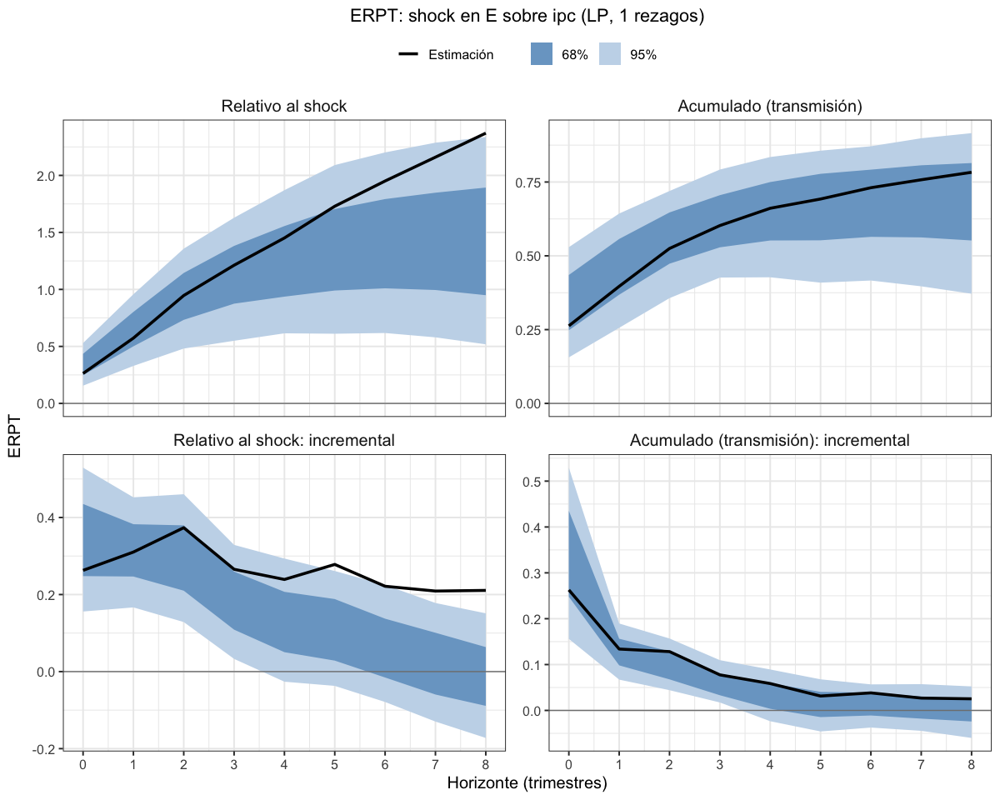

In [84]:
# Todas endógenas, 1 rezago
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_87, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa87_endog_p1")

### impp_usa 1950 a 1987 - 1 exógena y el resto endógenas - Selected orders: 1 y 3 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,151,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.000000000,0.0000000
20,ipc,E,1,0.4770706,0.363686634,0.5904545
21,ipc,E,2,0.4385053,0.207596201,0.6694144
22,ipc,E,3,0.5564949,0.313670596,0.7993193
23,ipc,E,4,0.4832920,0.276358228,0.6902258
24,ipc,E,5,0.2511172,-0.018399495,0.5206339
25,ipc,E,6,0.3525245,0.066659953,0.6383890
26,ipc,E,7,0.2840508,-0.018156892,0.5862586
27,ipc,E,8,0.2480664,-0.005333618,0.5014664


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.000000000,0.00000000
38,pbird,E,1,-0.62950637,-1.240657811,-0.01835492
39,pbird,E,2,0.15464277,-0.226600868,0.53588640
40,pbird,E,3,0.52124540,0.003591916,1.03889888
41,pbird,E,4,0.45922061,-0.116374211,1.03481544
42,pbird,E,5,1.16618636,0.425067195,1.90730553
43,pbird,E,6,-0.18830018,-0.838657350,0.46205699
44,pbird,E,7,-0.02099653,-0.843855452,0.80186239
45,pbird,E,8,0.04326883,-0.612667049,0.69920470


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2634351,0.26343511,0.2634351
2,E,ipc,1,0.3103168,0.24209437,0.3785391
3,E,ipc,2,0.3733075,0.23121517,0.5153999
4,E,ipc,3,0.2650419,0.12906961,0.4010141
5,E,ipc,4,0.2386049,0.07171182,0.4054980
6,E,ipc,5,0.2776001,0.10945748,0.4457426
7,E,ipc,6,0.2214097,0.05572893,0.3870906
8,E,ipc,7,0.2087759,0.04353633,0.3740154
9,E,ipc,8,0.2104523,0.04146336,0.3794412


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.00000000,0.0000000
47,pbird,ipc,1,0.3307897,0.13136020,0.5302192
48,pbird,ipc,2,0.3294135,0.01688249,0.6419445
49,pbird,ipc,3,0.6216674,0.26425847,0.9790763
50,pbird,ipc,4,0.5952900,0.23491798,0.9556620
51,pbird,ipc,5,0.5345670,0.15824785,0.9108861
52,pbird,ipc,6,0.2321472,-0.23708452,0.7013789
53,pbird,ipc,7,0.3509305,-0.18914955,0.8910106
54,pbird,ipc,8,0.3374053,-0.13762845,0.8124390


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.006791783,-0.006791783,-0.0067917828
11,E,pbird,1,-0.024795537,-0.048931411,-0.0006596631
12,E,pbird,2,-0.007119985,-0.029121385,0.0148814146
13,E,pbird,3,-0.029322494,-0.057257341,-0.0013876465
14,E,pbird,4,-0.008528948,-0.030126877,0.0130689812
15,E,pbird,5,0.016601466,-0.008092950,0.0412958816
16,E,pbird,6,0.003503609,-0.012803190,0.0198104081
17,E,pbird,7,0.012106953,-0.008503893,0.0327177996
18,E,pbird,8,0.006172562,-0.010920300,0.0232654249


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.064470223,-0.0644702233,-0.064470223
29,ipc,pbird,1,-0.019837238,-0.0364897397,-0.003184736
30,ipc,pbird,2,-0.025549331,-0.0412238621,-0.009874800
31,ipc,pbird,3,0.025386052,-0.0002010585,0.050973162
32,ipc,pbird,4,0.007439101,-0.0147904523,0.029668654
33,ipc,pbird,5,-0.023837907,-0.0436844575,-0.003991356
34,ipc,pbird,6,-0.010009276,-0.0297186403,0.009700088
35,ipc,pbird,7,-0.034059663,-0.0588818231,-0.009237504
36,ipc,pbird,8,-0.023992754,-0.0410935754,-0.006891934


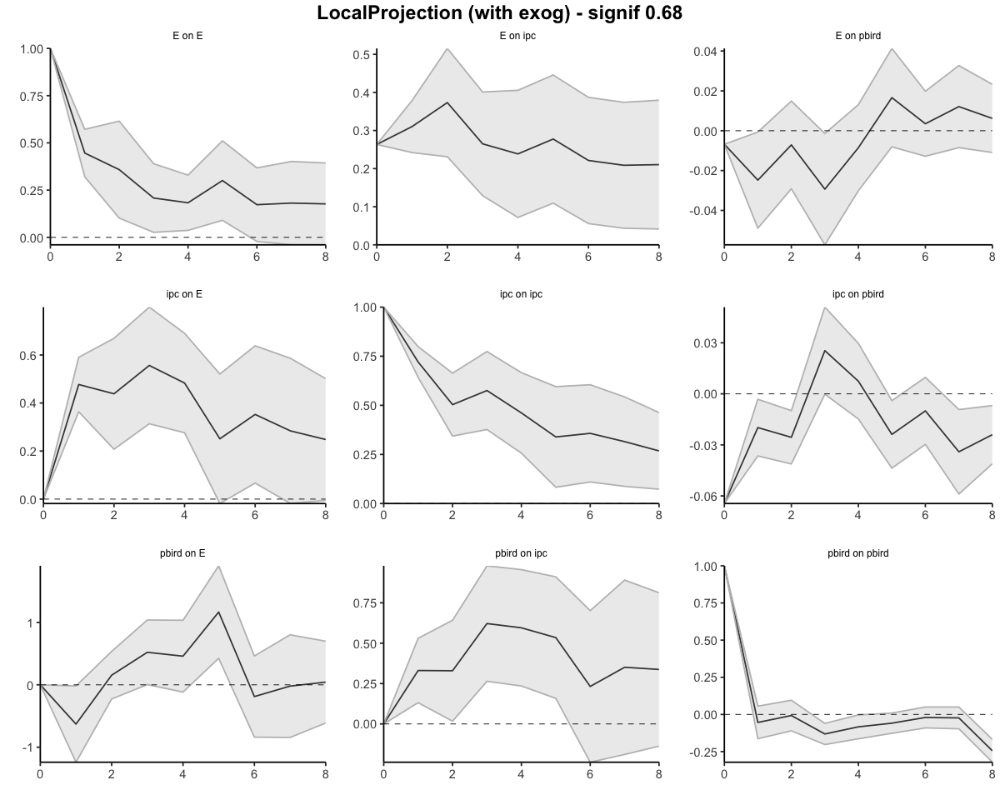

In [60]:
res <- run_lp_model(df_ERPT_Arg_1950_87, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,151,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.0000000,0.0000000
20,ipc,E,1,0.4770706,0.3636866,0.5904545
21,ipc,E,2,0.9155759,0.5712828,1.2598689
22,ipc,E,3,1.4720708,0.8849534,2.0591881
23,ipc,E,4,1.9553628,1.1613117,2.7494140
24,ipc,E,5,2.2064800,1.1429122,3.2700479
25,ipc,E,6,2.5590045,1.2095721,3.9084369
26,ipc,E,7,2.8430553,1.1914152,4.4946954
27,ipc,E,8,3.0911217,1.1860816,4.9961618


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.00000000
38,pbird,E,1,-0.6295064,-1.240658,-0.01835492
39,pbird,E,2,-0.4748636,-1.467259,0.51753148
40,pbird,E,3,0.0463818,-1.463667,1.55643037
41,pbird,E,4,0.5056024,-1.580041,2.59124581
42,pbird,E,5,1.6717888,-1.154974,4.49855134
43,pbird,E,6,1.4834886,-1.993631,4.96060833
44,pbird,E,7,1.4624921,-2.837487,5.76247072
45,pbird,E,8,1.5057609,-3.450154,6.46167542


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2634351,0.2634351,0.2634351
2,E,ipc,1,0.5737519,0.5055295,0.6419743
3,E,ipc,2,0.9470594,0.7367447,1.1573742
4,E,ipc,3,1.2121013,0.8658143,1.5583883
5,E,ipc,4,1.4507062,0.9375261,1.9638863
6,E,ipc,5,1.7283062,1.0469836,2.4096289
7,E,ipc,6,1.9497160,1.1027125,2.7967195
8,E,ipc,7,2.1584919,1.1462488,3.1707349
9,E,ipc,8,2.3689442,1.1877122,3.5501762


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.0000000,0.0000000
47,pbird,ipc,1,0.3307897,0.1313602,0.5302192
48,pbird,ipc,2,0.6602032,0.1482427,1.1721637
49,pbird,ipc,3,1.2818706,0.4125012,2.1512400
50,pbird,ipc,4,1.8771606,0.6474191,3.1069020
51,pbird,ipc,5,2.4117275,0.8056670,4.0177881
52,pbird,ipc,6,2.6438747,0.5685825,4.7191669
53,pbird,ipc,7,2.9948052,0.3794329,5.6101776
54,pbird,ipc,8,3.3322105,0.2418045,6.4226166


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.006791783,-0.006791783,-0.006791783
11,E,pbird,1,-0.031587320,-0.055723193,-0.007451446
12,E,pbird,2,-0.038707305,-0.084844579,0.007429969
13,E,pbird,3,-0.068029799,-0.142101920,0.006042322
14,E,pbird,4,-0.076558747,-0.172228797,0.019111303
15,E,pbird,5,-0.059957281,-0.180321747,0.060407185
16,E,pbird,6,-0.056453672,-0.193124937,0.080217593
17,E,pbird,7,-0.044346719,-0.201628830,0.112935393
18,E,pbird,8,-0.038174156,-0.212549131,0.136200818


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.06447022,-0.06447022,-0.0644702233
29,ipc,pbird,1,-0.08430746,-0.10095996,-0.0676549595
30,ipc,pbird,2,-0.10985679,-0.14218383,-0.0775297593
31,ipc,pbird,3,-0.08447074,-0.14238488,-0.0265565968
32,ipc,pbird,4,-0.07703164,-0.15717534,0.0031120568
33,ipc,pbird,5,-0.10086955,-0.20085979,-0.0008792987
34,ipc,pbird,6,-0.11087882,-0.23057843,0.0088207893
35,ipc,pbird,7,-0.14493849,-0.28946026,-0.0004167142
36,ipc,pbird,8,-0.16893124,-0.33055383,-0.0073086478


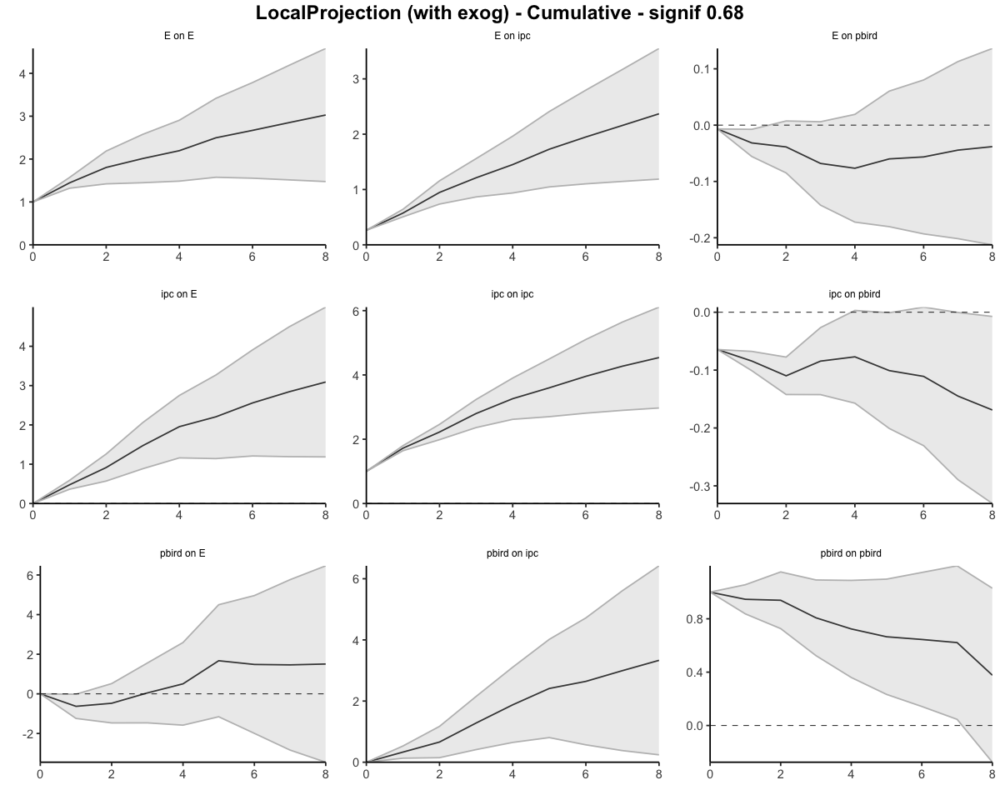

In [61]:
res <- run_lp_model(df_ERPT_Arg_1950_87, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.2634         0.2634       1.0000
         1              0.5738         0.3968       1.4461
         2              0.9471         0.5248       1.8046
         3              1.2121         0.6022       2.0128
         4              1.4507         0.6607       2.1959
         5              1.7283         0.6923       2.4966
         6              1.9497         0.7304       2.6695
         7              2.1585         0.7572       2.8508
         8              2.3689         0.7824       3.0279
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.2634             0.2634
                  0.3103             0.1333
                  0.3733             0.1280
                  0.2650             0.0774
                  0.2386       

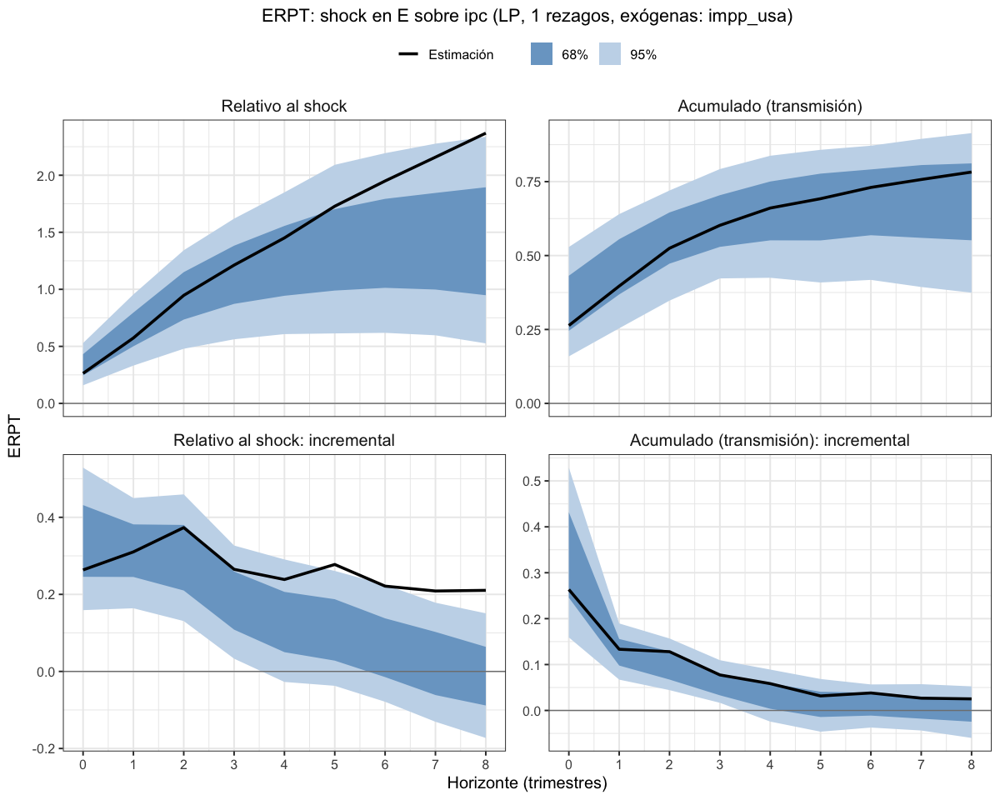

In [85]:
# impp_usa exógena, 1 rezago
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_87, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa87_exog_p1")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,151,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.00000000,0.00000000
20,ipc,E,1,0.4298677,0.22086086,0.63887455
21,ipc,E,2,0.2559587,0.08986201,0.42205540
22,ipc,E,3,0.3705244,0.13653567,0.60451316
23,ipc,E,4,0.2662991,0.05347742,0.47912072
24,ipc,E,5,0.1157902,-0.15417454,0.38575498
25,ipc,E,6,0.2006899,-0.12206300,0.52344277
26,ipc,E,7,0.0293728,-0.21682843,0.27557404
27,ipc,E,8,-0.2620113,-0.42659722,-0.09742538


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.00000000,0.00000000
38,pbird,E,1,-0.52252327,-1.08963016,0.04458362
39,pbird,E,2,0.25451002,-0.18668160,0.69570163
40,pbird,E,3,0.48481358,-0.02823292,0.99786008
41,pbird,E,4,0.61824254,0.04647930,1.19000578
42,pbird,E,5,1.22482119,0.49230304,1.95733934
43,pbird,E,6,-0.17794009,-0.85157816,0.49569799
44,pbird,E,7,-0.11951348,-0.95376770,0.71474075
45,pbird,E,8,-0.09995913,-0.69923280,0.49931453


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2341640,0.234163962,0.2341640
2,E,ipc,1,0.2284756,0.148117685,0.3088335
3,E,ipc,2,0.3286688,0.210268654,0.4470689
4,E,ipc,3,0.2431735,0.135812321,0.3505347
5,E,ipc,4,0.1682682,0.046611732,0.2899246
6,E,ipc,5,0.2329726,0.075268504,0.3906768
7,E,ipc,6,0.1750687,0.009678521,0.3404588
8,E,ipc,7,0.1536768,0.028950742,0.2784029
9,E,ipc,8,0.1243653,0.008279645,0.2404509


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.00000000,0.0000000
47,pbird,ipc,1,0.3958748,0.19842254,0.5933270
48,pbird,ipc,2,0.3874046,0.07835221,0.6964571
49,pbird,ipc,3,0.6216554,0.27997282,0.9633381
50,pbird,ipc,4,0.6561932,0.28646774,1.0259186
51,pbird,ipc,5,0.5902678,0.09137940,1.0891561
52,pbird,ipc,6,0.2197662,-0.22194972,0.6614821
53,pbird,ipc,7,0.3009924,-0.16490410,0.7668889
54,pbird,ipc,8,0.2561389,-0.13440400,0.6466818


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.009431318,-0.009431318,-0.009431318
11,E,pbird,1,-0.026755756,-0.050916727,-0.002594786
12,E,pbird,2,-0.006450275,-0.033143949,0.020243400
13,E,pbird,3,-0.034284891,-0.065601646,-0.002968135
14,E,pbird,4,-0.017741276,-0.039559103,0.004076552
15,E,pbird,5,0.018578250,-0.009964523,0.047121023
16,E,pbird,6,0.005419212,-0.010420255,0.021258679
17,E,pbird,7,0.006828254,-0.012178130,0.025834638
18,E,pbird,8,0.010455606,-0.005343036,0.026254248


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.094690578,-0.094690578,-0.094690578
29,ipc,pbird,1,-0.031061557,-0.047973656,-0.014149458
30,ipc,pbird,2,-0.048749336,-0.079168086,-0.018330585
31,ipc,pbird,3,0.007602153,-0.021631420,0.036835726
32,ipc,pbird,4,0.003597128,-0.017728896,0.024923151
33,ipc,pbird,5,-0.022131325,-0.053249654,0.008987005
34,ipc,pbird,6,0.022021117,-0.001054188,0.045096422
35,ipc,pbird,7,-0.026153983,-0.057417602,0.005109637
36,ipc,pbird,8,0.001252349,-0.018800950,0.021305648


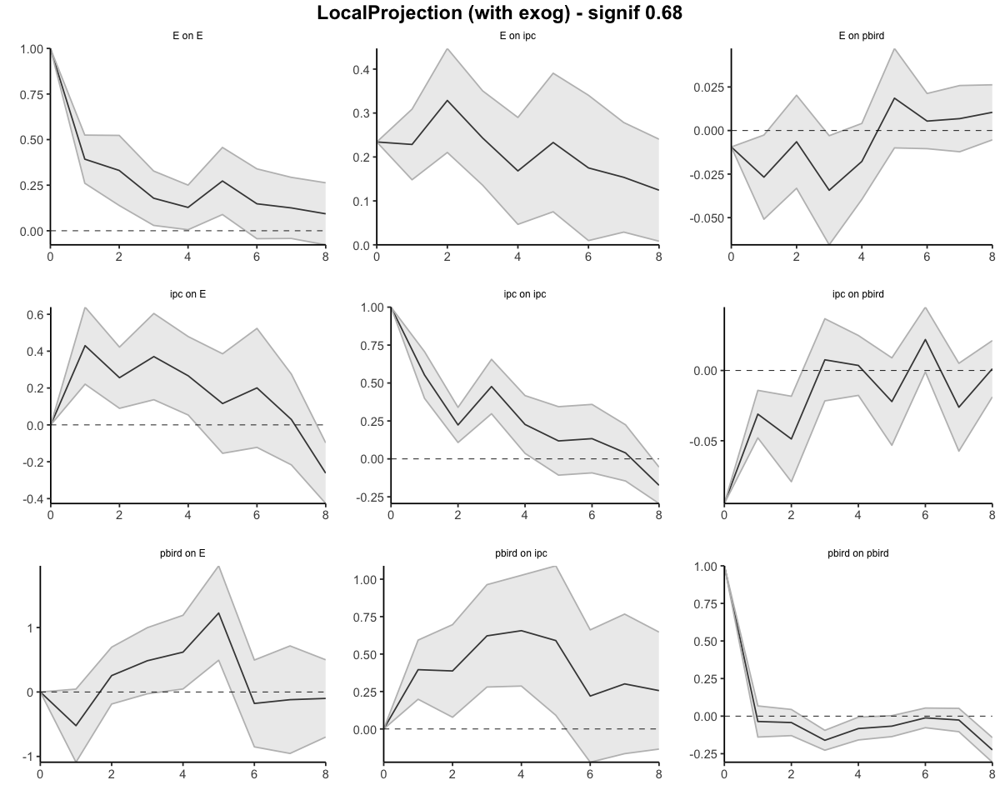

In [62]:
res <- run_lp_model(df_ERPT_Arg_1950_87, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,151,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.0000000,0.000000000,0.0000000
20,ipc,E,1,0.4298677,0.220860858,0.6388745
21,ipc,E,2,0.6858264,0.310722870,1.0609299
22,ipc,E,3,1.0563508,0.447258543,1.6654431
23,ipc,E,4,1.3226499,0.500735959,2.1445638
24,ipc,E,5,1.4384401,0.346561419,2.5303188
25,ipc,E,6,1.6391300,0.224498420,3.0537616
26,ipc,E,7,1.6685028,0.007669988,3.3293356
27,ipc,E,8,1.4064915,-0.418927237,3.2319102


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.0000000,0.00000000
38,pbird,E,1,-0.5225233,-1.0896302,0.04458362
39,pbird,E,2,-0.2680132,-1.2763118,0.74028526
40,pbird,E,3,0.2168003,-1.3045447,1.73814534
41,pbird,E,4,0.8350429,-1.2580654,2.92815112
42,pbird,E,5,2.0598641,-0.7657623,4.88549046
43,pbird,E,6,1.8819240,-1.6173405,5.38118845
44,pbird,E,7,1.7624105,-2.5711082,6.09592920
45,pbird,E,8,1.6624514,-3.2703410,6.59524373


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2341640,0.2341640,0.2341640
2,E,ipc,1,0.4626396,0.3822816,0.5429975
3,E,ipc,2,0.7913083,0.5925503,0.9900664
4,E,ipc,3,1.0344818,0.7283626,1.3406010
5,E,ipc,4,1.2027500,0.7749744,1.6305257
6,E,ipc,5,1.4357226,0.8502429,2.0212024
7,E,ipc,6,1.6107913,0.8599214,2.3616612
8,E,ipc,7,1.7644681,0.8888721,2.6400641
9,E,ipc,8,1.8888334,0.8971518,2.8805150


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.0000000,0.000000
47,pbird,ipc,1,0.3958748,0.1984225,0.593327
48,pbird,ipc,2,0.7832794,0.2767748,1.289784
49,pbird,ipc,3,1.4049349,0.5567476,2.253122
50,pbird,ipc,4,2.0611280,0.8432153,3.279041
51,pbird,ipc,5,2.6513958,0.9345947,4.368197
52,pbird,ipc,6,2.8711620,0.7126450,5.029679
53,pbird,ipc,7,3.1721544,0.5477409,5.796568
54,pbird,ipc,8,3.4282933,0.4133369,6.443250


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.009431318,-0.009431318,-0.009431318
11,E,pbird,1,-0.036187074,-0.060348045,-0.012026104
12,E,pbird,2,-0.042637349,-0.093491994,0.008217296
13,E,pbird,3,-0.076922240,-0.159093640,0.005249161
14,E,pbird,4,-0.094663515,-0.198652743,0.009325713
15,E,pbird,5,-0.076085265,-0.208617266,0.056446735
16,E,pbird,6,-0.070666054,-0.219037522,0.077705414
17,E,pbird,7,-0.063837800,-0.231215652,0.103540052
18,E,pbird,8,-0.053382193,-0.236558687,0.129794300


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.09469058,-0.09469058,-0.094690578
29,ipc,pbird,1,-0.12575214,-0.14266423,-0.108840036
30,ipc,pbird,2,-0.17450147,-0.22183232,-0.127170622
31,ipc,pbird,3,-0.16689932,-0.24346374,-0.090334896
32,ipc,pbird,4,-0.16330219,-0.26119264,-0.065411745
33,ipc,pbird,5,-0.18543352,-0.31444229,-0.056424740
34,ipc,pbird,6,-0.16341240,-0.31549648,-0.011328318
35,ipc,pbird,7,-0.18956638,-0.37291408,-0.006218681
36,ipc,pbird,8,-0.18831403,-0.39171503,0.015086968


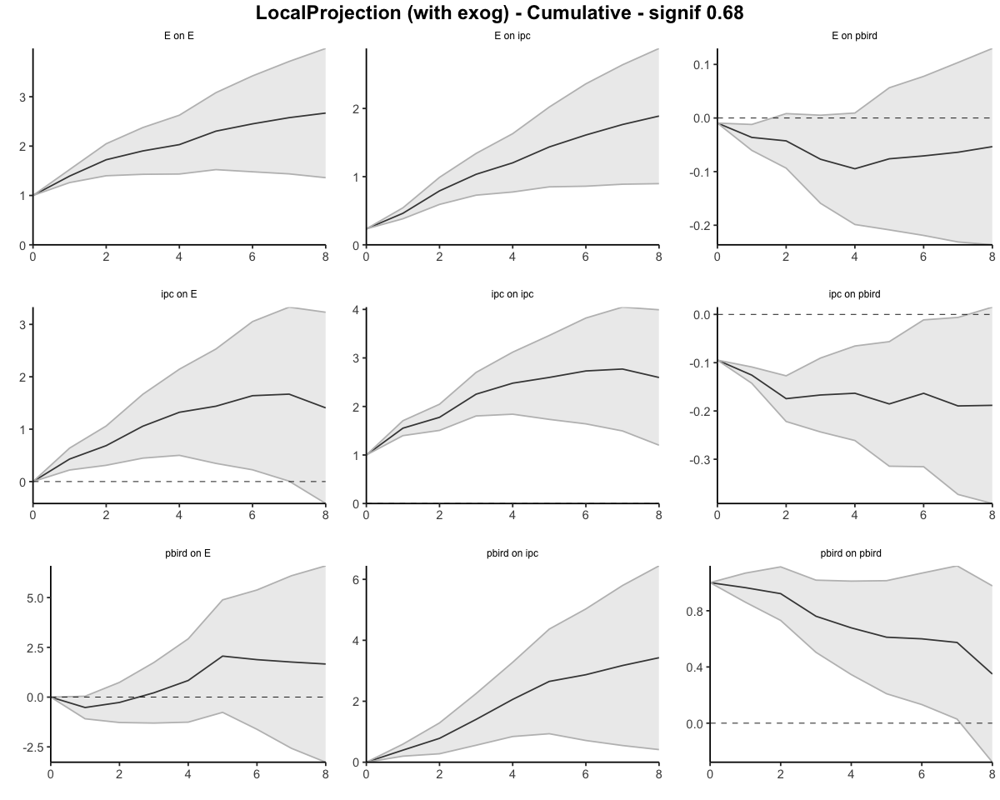

In [63]:
res <- run_lp_model(df_ERPT_Arg_1950_87, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 3 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.2342         0.2342       1.0000
         1              0.4626         0.3322       1.3927
         2              0.7913         0.4591       1.7235
         3              1.0345         0.5439       1.9020
         4              1.2028         0.5925       2.0300
         5              1.4357         0.6234       2.3030
         6              1.6108         0.6572       2.4509
         7              1.7645         0.6849       2.5762
         8              1.8888         0.7076       2.6692
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.2342             0.2342
                  0.2285             0.0980
                  0.3287             0.1269
                  0.2432             0.0848
                  0.1683       

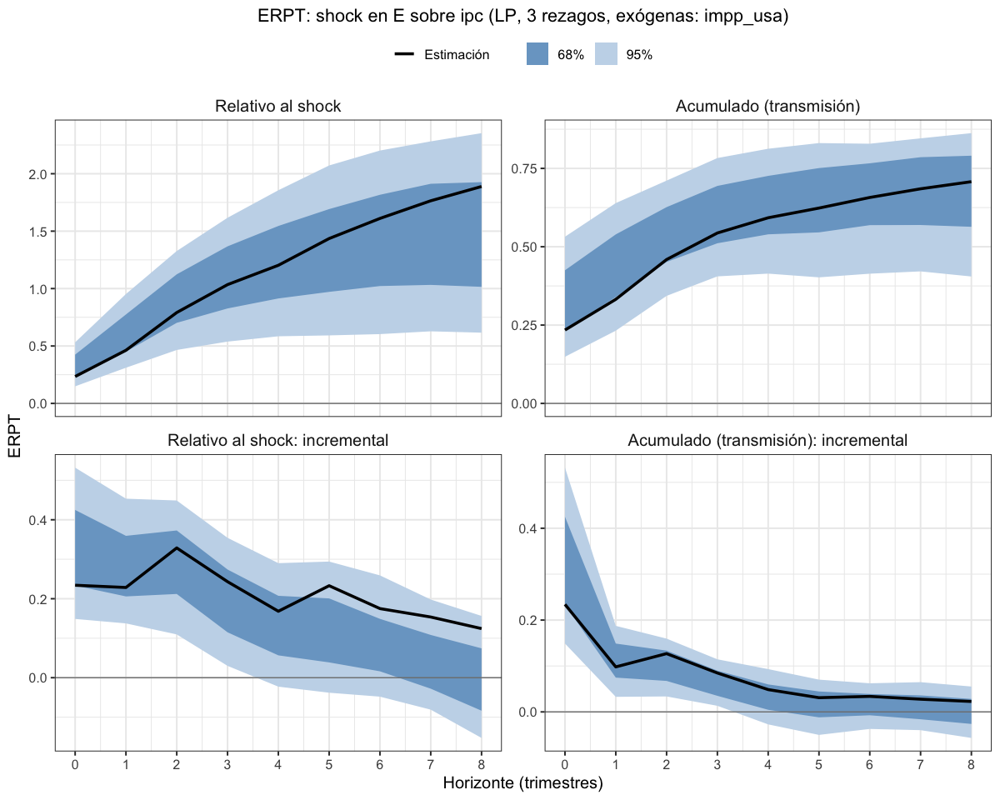

In [86]:
# impp_usa exógena, 3 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_87, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 3, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa87_exog_p3")

### impp_usa 1950 a 1990 - Todas endógenas - Selected orders: 1 y 2 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-2.09792879,-2.09792879,-2.09792879
2,impp_usa,E,1,-0.43466868,-1.45127262,0.58193527
3,impp_usa,E,2,-0.06333389,-0.19993146,0.07326367
4,impp_usa,E,3,-0.30713830,-0.57529734,-0.03897927
5,impp_usa,E,4,1.60749756,0.73910216,2.47589296
6,impp_usa,E,5,1.79664558,9.45859153,-5.86530037
7,impp_usa,E,6,0.80290126,-0.01870609,1.62450860
8,impp_usa,E,7,1.40564559,0.79830385,2.01298732
9,impp_usa,E,8,1.39754452,0.68178965,2.11329939


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.00000000,0.0000000
65,ipc,E,1,0.06273217,-0.04123090,0.1666952
66,ipc,E,2,0.44420239,0.10481926,0.7835855
67,ipc,E,3,0.29293737,-0.02827285,0.6141476
68,ipc,E,4,0.44287186,0.19140426,0.6943395
69,ipc,E,5,0.15879866,-8.74414437,9.0617417
70,ipc,E,6,0.62665653,0.35771919,0.8955939
71,ipc,E,7,0.45489876,0.14476329,0.7650342
72,ipc,E,8,0.32307392,0.06416780,0.5819800


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.00000000,0.0000000
92,pbird,E,1,-0.4224439,-1.27941026,0.4345225
93,pbird,E,2,0.3351400,-0.09956766,0.7698476
94,pbird,E,3,-0.2131322,-0.87137607,0.4451116
95,pbird,E,4,-0.2494332,-1.03322073,0.5343543
96,pbird,E,5,1.3668035,-2.40361076,5.1372178
97,pbird,E,6,-0.5789310,-1.30428227,0.1464203
98,pbird,E,7,-0.2214880,-0.92680477,0.4838288
99,pbird,E,8,1.1990557,0.20434551,2.1937659


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.00000000,0.0000000
101,pbird,ipc,1,0.45545181,0.02939128,0.8815123
102,pbird,ipc,2,0.77471591,0.39424558,1.1551862
103,pbird,ipc,3,0.19020805,-0.25381506,0.6342312
104,pbird,ipc,4,0.09787129,-0.45338828,0.6491309
105,pbird,ipc,5,0.47635316,-0.02378070,0.9764870
106,pbird,ipc,6,0.27833954,-0.16790945,0.7245885
107,pbird,ipc,7,-0.22476954,-0.86208811,0.4125490
108,pbird,ipc,8,1.27671949,0.56651768,1.9869213


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.0298011915,-0.029801192,-0.029801192
47,E,pbird,1,-0.0205314927,-0.044767284,0.003704299
48,E,pbird,2,0.0006329443,-0.031023213,0.032289101
49,E,pbird,3,-0.0242650688,-0.051035390,0.002505252
50,E,pbird,4,-0.0024982913,-0.021118193,0.016121610
51,E,pbird,5,0.0148996724,-0.005013532,0.034812877
52,E,pbird,6,0.0005633214,-0.018662848,0.019789491
53,E,pbird,7,-0.0032286964,-0.028190008,0.021732615
54,E,pbird,8,0.0034774734,-0.017532408,0.024487354


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.234932701,0.234932701,0.23493270
20,impp_usa,pbird,1,0.005494734,-0.024806397,0.03579586
21,impp_usa,pbird,2,0.033349963,0.027037048,0.03966288
22,impp_usa,pbird,3,0.017066653,0.008418508,0.02571480
23,impp_usa,pbird,4,-0.184453987,-0.223561114,-0.14534686
24,impp_usa,pbird,5,-0.238773707,-0.266618167,-0.21092925
25,impp_usa,pbird,6,-0.135445645,-0.186790542,-0.08410075
26,impp_usa,pbird,7,-0.149981725,-0.193746987,-0.10621646
27,impp_usa,pbird,8,-0.184958690,-0.231615069,-0.13830231


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.05684071,-0.056840706,-0.056840706
74,ipc,pbird,1,0.01973732,0.003704352,0.035770282
75,ipc,pbird,2,-0.02616905,-0.048170874,-0.004167221
76,ipc,pbird,3,0.03210373,0.013866028,0.050341427
77,ipc,pbird,4,0.01044061,-0.004225522,0.025106747
78,ipc,pbird,5,-0.01956044,-0.031095635,-0.008025237
79,ipc,pbird,6,-0.01636786,-0.033927883,0.001192162
80,ipc,pbird,7,-0.03349265,-0.055262847,-0.011722451
81,ipc,pbird,8,-0.02119794,-0.038467716,-0.003928156


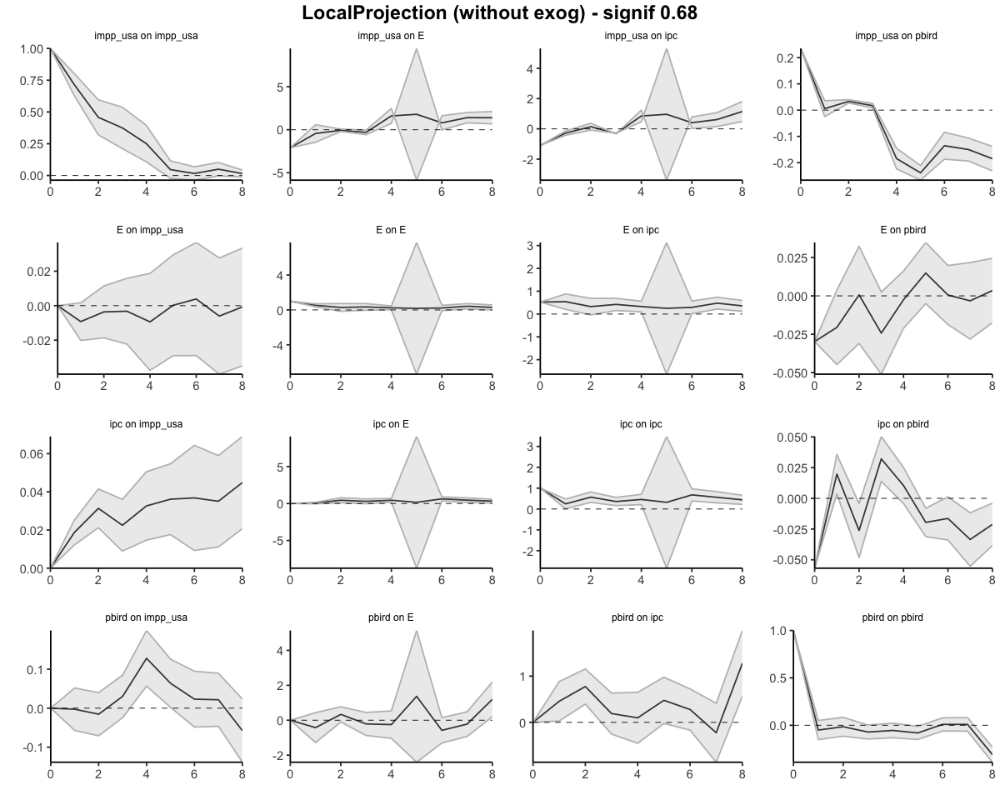

In [65]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-2.0979288,-2.097929,-2.0979288
2,impp_usa,E,1,-2.5325975,-3.549201,-1.5159935
3,impp_usa,E,2,-2.5959314,-3.749133,-1.4427298
4,impp_usa,E,3,-2.9030697,-4.324430,-1.4817091
5,impp_usa,E,4,-1.2955721,-3.585328,0.9941838
6,impp_usa,E,5,0.5010735,5.873263,-4.8711165
7,impp_usa,E,6,1.3039747,5.854557,-3.2466079
8,impp_usa,E,7,2.7096203,6.652861,-1.2336206
9,impp_usa,E,8,4.1071648,7.334651,0.8796788


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.00000000,0.0000000
65,ipc,E,1,0.06273217,-0.04123090,0.1666952
66,ipc,E,2,0.50693456,0.06358835,0.9502808
67,ipc,E,3,0.79987193,0.03531550,1.5644284
68,ipc,E,4,1.24274378,0.22671976,2.2587678
69,ipc,E,5,1.40154245,-8.51742461,11.3205095
70,ipc,E,6,2.02819897,-8.15970542,12.2161034
71,ipc,E,7,2.48309773,-8.01494213,12.9811376
72,ipc,E,8,2.80617165,-7.95077433,13.5631176


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.000000,0.0000000
92,pbird,E,1,-0.42244387,-1.279410,0.4345225
93,pbird,E,2,-0.08730390,-1.378978,1.2043701
94,pbird,E,3,-0.30043612,-2.250354,1.6494818
95,pbird,E,4,-0.54986935,-3.283575,2.1838360
96,pbird,E,5,0.81693416,-5.687185,7.3210538
97,pbird,E,6,0.23800316,-6.991468,7.4674741
98,pbird,E,7,0.01651517,-7.918273,7.9513029
99,pbird,E,8,1.21557086,-7.713927,10.1450687


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.0000000,0.00000000,0.0000000
101,pbird,ipc,1,0.4554518,0.02939128,0.8815123
102,pbird,ipc,2,1.2301677,0.42363685,2.0366986
103,pbird,ipc,3,1.4203758,0.16982179,2.6709297
104,pbird,ipc,4,1.5182470,-0.28356649,3.3200606
105,pbird,ipc,5,1.9946002,-0.30734719,4.2965476
106,pbird,ipc,6,2.2729398,-0.47525664,5.0211362
107,pbird,ipc,7,2.0481702,-1.33734475,5.4336852
108,pbird,ipc,8,3.3248897,-0.77082708,7.4206065


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.02980119,-0.02980119,-0.029801192
47,E,pbird,1,-0.05033268,-0.07456848,-0.026096893
48,E,pbird,2,-0.04969974,-0.10559169,0.006192209
49,E,pbird,3,-0.07396481,-0.15662708,0.008697461
50,E,pbird,4,-0.07646310,-0.17774527,0.024819071
51,E,pbird,5,-0.06156343,-0.18275880,0.059631948
52,E,pbird,6,-0.06100011,-0.20142165,0.079421439
53,E,pbird,7,-0.06422880,-0.22961166,0.101154054
54,E,pbird,8,-0.06075133,-0.24714407,0.125641408


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.2349327,0.23493270,0.23493270
20,impp_usa,pbird,1,0.2404274,0.21012630,0.27072856
21,impp_usa,pbird,2,0.2737774,0.23716335,0.31039144
22,impp_usa,pbird,3,0.2908441,0.24558186,0.33610624
23,impp_usa,pbird,4,0.1063901,0.02202074,0.19075938
24,impp_usa,pbird,5,-0.1323836,-0.24459742,-0.02016987
25,impp_usa,pbird,6,-0.2678293,-0.43138796,-0.10427061
26,impp_usa,pbird,7,-0.4178110,-0.62513495,-0.21048708
27,impp_usa,pbird,8,-0.6027697,-0.85675002,-0.34878939


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.05684071,-0.05684071,-0.05684071
74,ipc,pbird,1,-0.03710339,-0.05313635,-0.02107042
75,ipc,pbird,2,-0.06327244,-0.10130723,-0.02523764
76,ipc,pbird,3,-0.03116871,-0.08744120,0.02510378
77,ipc,pbird,4,-0.02072810,-0.09166672,0.05021053
78,ipc,pbird,5,-0.04028853,-0.12276236,0.04218529
79,ipc,pbird,6,-0.05665639,-0.15669024,0.04337746
80,ipc,pbird,7,-0.09014904,-0.21195309,0.03165500
81,ipc,pbird,8,-0.11134698,-0.25042080,0.02772685


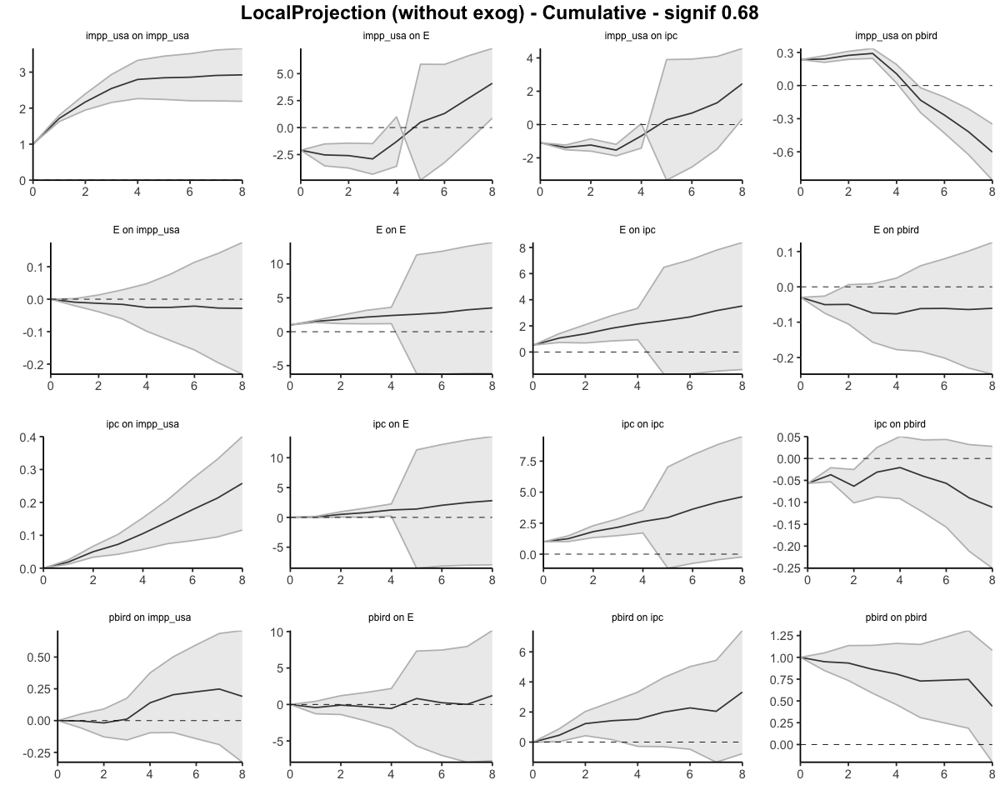

In [64]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.5244         0.5244       1.0000
         1              1.0664         0.6975       1.5289
         2              1.3923         0.7673       1.8145
         3              1.8140         0.8404       2.1586
         4              2.1424         0.8944       2.3955
         5              2.3933         0.9272       2.5813
         6              2.6856         0.9579       2.8036
         7              3.1623         0.9795       3.2283
         8              3.5208         1.0020       3.5137
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.5244             0.5244
                  0.5420             0.1731
                  0.3259             0.0698
                  0.4217             0.0730
                  0.3284             0.0540
       

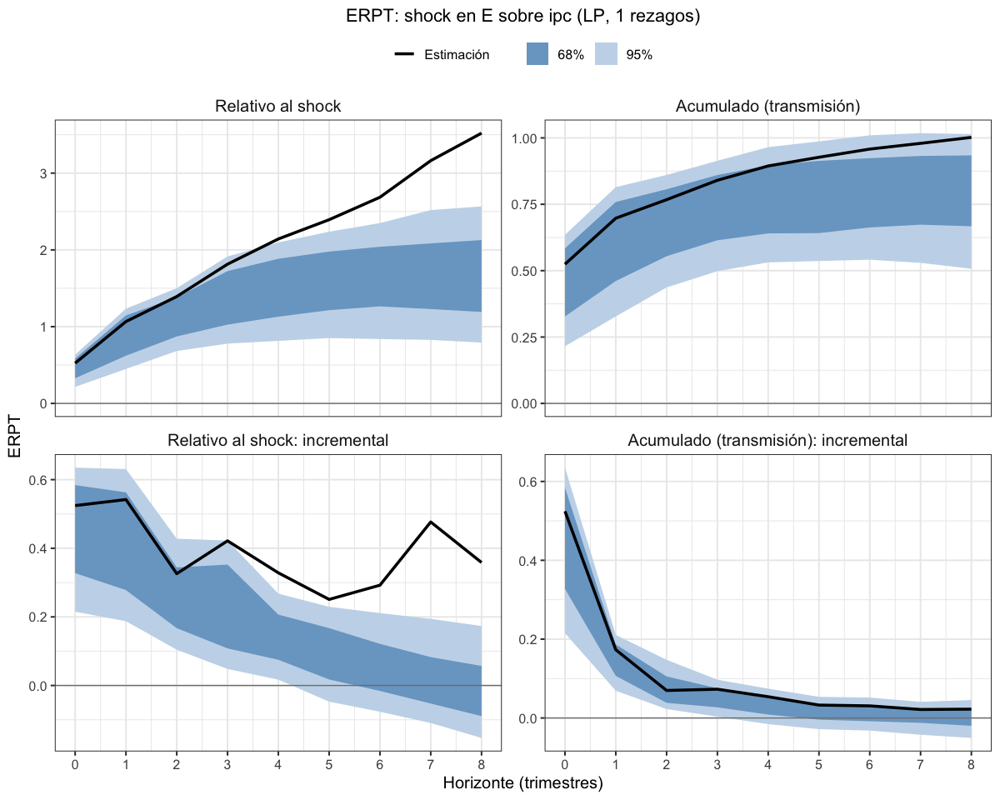

In [87]:
# Todas endógenas, 1 rezago
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_90, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa90_endog_p1")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-3.0120325,-3.01203249,-3.0120325
2,impp_usa,E,1,-0.3456929,-1.45229163,0.7609058
3,impp_usa,E,2,0.2676209,-0.69037579,1.2256176
4,impp_usa,E,3,-2.9377257,-3.16054576,-2.7149057
5,impp_usa,E,4,0.9819834,0.02299323,1.9409736
6,impp_usa,E,5,2.1817636,2.26068873,2.1028385
7,impp_usa,E,6,-0.4877102,-1.47459382,0.4991735
8,impp_usa,E,7,0.4084318,0.27114089,0.5457228
9,impp_usa,E,8,1.3542675,1.02129696,1.6872380


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.00000000,0.00000000
65,ipc,E,1,-0.23896219,-0.44577613,-0.03214826
66,ipc,E,2,0.19962714,-0.15655809,0.55581238
67,ipc,E,3,0.19256030,0.06365545,0.32146514
68,ipc,E,4,0.48042099,0.26409689,0.69674508
69,ipc,E,5,-0.43865562,-1.05424400,0.17693276
70,ipc,E,6,0.16931464,-0.06819019,0.40681947
71,ipc,E,7,0.60398172,0.22489218,0.98307125
72,ipc,E,8,0.05407086,-0.16345726,0.27159897


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.00000000,0.0000000,0.0000000
92,pbird,E,1,-0.97082848,-1.6987705,-0.2428865
93,pbird,E,2,-0.02390445,-0.5849694,0.5371605
94,pbird,E,3,-0.23365013,-0.9626457,0.4953455
95,pbird,E,4,-0.16158758,-0.9593262,0.6361510
96,pbird,E,5,1.18028779,0.0796611,2.2809145
97,pbird,E,6,-0.55906589,-1.3494926,0.2313608
98,pbird,E,7,-0.16446384,-0.8984447,0.5695170
99,pbird,E,8,1.18984279,0.1799597,2.1997259


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.00000000,0.0000000,0.0000000
101,pbird,ipc,1,-0.11908810,-0.4934844,0.2553082
102,pbird,ipc,2,0.27718591,-0.4891793,1.0435512
103,pbird,ipc,3,0.04322337,-0.4723322,0.5587789
104,pbird,ipc,4,0.06415558,-0.4580768,0.5863880
105,pbird,ipc,5,0.36329347,-3.7259044,4.4524913
106,pbird,ipc,6,0.24939982,-0.2921257,0.7909254
107,pbird,ipc,7,-0.10550529,-0.6897900,0.4787794
108,pbird,ipc,8,1.30286780,0.5846259,2.0211097


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.027283982,-0.027283982,-0.027283982
47,E,pbird,1,-0.023300316,-0.051678757,0.005078126
48,E,pbird,2,0.008446221,-0.012076785,0.028969228
49,E,pbird,3,-0.025317747,-0.048413841,-0.002221653
50,E,pbird,4,-0.008876598,-0.027991239,0.010238043
51,E,pbird,5,0.022127602,-0.003524786,0.047779989
52,E,pbird,6,0.009805998,-0.008044573,0.027656569
53,E,pbird,7,-0.014748689,-0.040660089,0.011162712
54,E,pbird,8,0.006044700,-0.013590139,0.025679539


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.25775624,0.25775624,0.257756244
20,impp_usa,pbird,1,-0.04633449,-0.06159724,-0.031071731
21,impp_usa,pbird,2,0.02594055,-0.01913748,0.071018581
22,impp_usa,pbird,3,0.26767149,0.24531001,0.290032959
23,impp_usa,pbird,4,-0.02796529,-0.08168023,0.025749663
24,impp_usa,pbird,5,-0.25863012,-0.26431208,-0.252948168
25,impp_usa,pbird,6,-0.05384558,-0.11569884,0.008007677
26,impp_usa,pbird,7,-0.05776478,-0.07509124,-0.040438326
27,impp_usa,pbird,8,-0.28512552,-0.34179964,-0.228451403


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.057784468,-0.057784468,-0.057784468
74,ipc,pbird,1,0.026420816,0.001636148,0.051205483
75,ipc,pbird,2,-0.010267571,-0.025295143,0.004760001
76,ipc,pbird,3,0.027161226,0.012391122,0.041931329
77,ipc,pbird,4,-0.006379531,-0.019464027,0.006704964
78,ipc,pbird,5,0.003678688,-0.017695521,0.025052896
79,ipc,pbird,6,0.016994503,-0.001251492,0.035240498
80,ipc,pbird,7,-0.039949235,-0.066800371,-0.013098098
81,ipc,pbird,8,-0.018734517,-0.036086003,-0.001383031


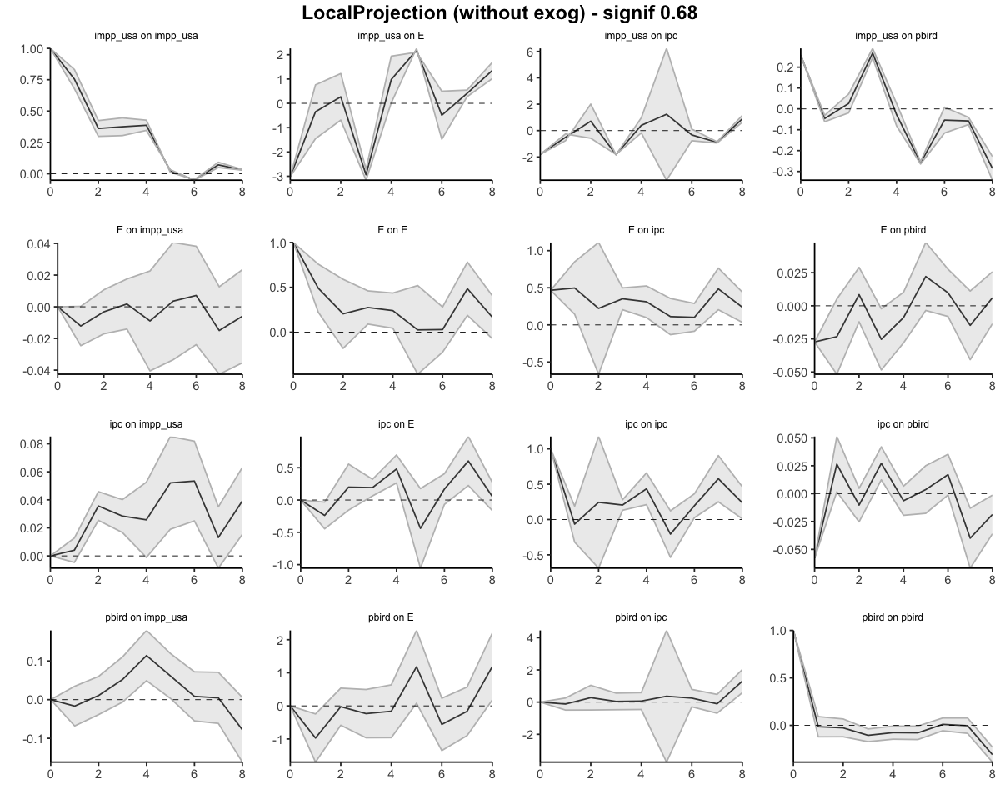

In [67]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"impp_usa, E, ipc, pbird",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-3.012032,-3.012032,-3.0120325
2,impp_usa,E,1,-3.357725,-4.464324,-2.2511267
3,impp_usa,E,2,-3.090105,-5.154700,-1.0255091
4,impp_usa,E,3,-6.027830,-8.315246,-3.7404148
5,impp_usa,E,4,-5.045847,-8.292252,-1.7994412
6,impp_usa,E,5,-2.864083,-6.031564,0.3033973
7,impp_usa,E,6,-3.351793,-7.506158,0.8025707
8,impp_usa,E,7,-2.943362,-7.235017,1.3482935
9,impp_usa,E,8,-1.589094,-6.213720,3.0355315


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
64,ipc,E,0,0.00000000,0.0000000,0.00000000
65,ipc,E,1,-0.23896219,-0.4457761,-0.03214826
66,ipc,E,2,-0.03933505,-0.6023342,0.52366412
67,ipc,E,3,0.15322525,-0.5386788,0.84512926
68,ipc,E,4,0.63364623,-0.2745819,1.54187434
69,ipc,E,5,0.19499062,-1.3288259,1.71880711
70,ipc,E,6,0.36430526,-1.3970161,2.12562658
71,ipc,E,7,0.96828697,-1.1721239,3.10869783
72,ipc,E,8,1.02235783,-1.3355811,3.38029680


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
91,pbird,E,0,0.0000000,0.000000,0.0000000
92,pbird,E,1,-0.9708285,-1.698770,-0.2428865
93,pbird,E,2,-0.9947329,-2.283740,0.2942740
94,pbird,E,3,-1.2283831,-3.246386,0.7896195
95,pbird,E,4,-1.3899706,-4.205712,1.4257705
96,pbird,E,5,-0.2096828,-4.126051,3.7066850
97,pbird,E,6,-0.7687487,-5.475543,3.9380458
98,pbird,E,7,-0.9332126,-6.373988,4.5075627
99,pbird,E,8,0.2566302,-6.194028,6.7072886


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
100,pbird,ipc,0,0.0000000,0.0000000,0.0000000
101,pbird,ipc,1,-0.1190881,-0.4934844,0.2553082
102,pbird,ipc,2,0.1580978,-0.9826638,1.2988594
103,pbird,ipc,3,0.2013212,-1.4549959,1.8576383
104,pbird,ipc,4,0.2654768,-1.9130727,2.4440262
105,pbird,ipc,5,0.6287702,-5.6389771,6.8965176
106,pbird,ipc,6,0.8781700,-5.9311028,7.6874429
107,pbird,ipc,7,0.7726648,-6.6208928,8.1662223
108,pbird,ipc,8,2.0755326,-6.0362668,10.1873320


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,E,pbird,0,-0.02728398,-0.02728398,-0.027283982
47,E,pbird,1,-0.05058430,-0.07896274,-0.022205856
48,E,pbird,2,-0.04213808,-0.09103952,0.006763371
49,E,pbird,3,-0.06745582,-0.13945337,0.004541718
50,E,pbird,4,-0.07633242,-0.16744460,0.014779761
51,E,pbird,5,-0.05420482,-0.17096939,0.062559750
52,E,pbird,6,-0.04439882,-0.17901396,0.090216319
53,E,pbird,7,-0.05914751,-0.21967405,0.101379031
54,E,pbird,8,-0.05310281,-0.23326419,0.127058570


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,impp_usa,pbird,0,0.2577562,0.25775624,0.2577562
20,impp_usa,pbird,1,0.2114218,0.19615900,0.2266845
21,impp_usa,pbird,2,0.2373623,0.17702152,0.2977031
22,impp_usa,pbird,3,0.5050338,0.42233154,0.5877361
23,impp_usa,pbird,4,0.4770685,0.34065131,0.6134857
24,impp_usa,pbird,5,0.2184384,0.07633922,0.3605375
25,impp_usa,pbird,6,0.1645928,-0.03935962,0.3685452
26,impp_usa,pbird,7,0.1068280,-0.11445086,0.3281069
27,impp_usa,pbird,8,-0.1782975,-0.45625049,0.0996555


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
73,ipc,pbird,0,-0.0577844684,-0.05778447,-0.057784468
74,ipc,pbird,1,-0.0313636527,-0.05614832,-0.006578985
75,ipc,pbird,2,-0.0416312235,-0.08144346,-0.001818984
76,ipc,pbird,3,-0.0144699980,-0.06905234,0.040112345
77,ipc,pbird,4,-0.0208495292,-0.08851637,0.046817309
78,ipc,pbird,5,-0.0171708416,-0.10621189,0.071870205
79,ipc,pbird,6,-0.0001763384,-0.10746338,0.107110703
80,ipc,pbird,7,-0.0401255729,-0.17426375,0.094012605
81,ipc,pbird,8,-0.0588600898,-0.21034975,0.092629574


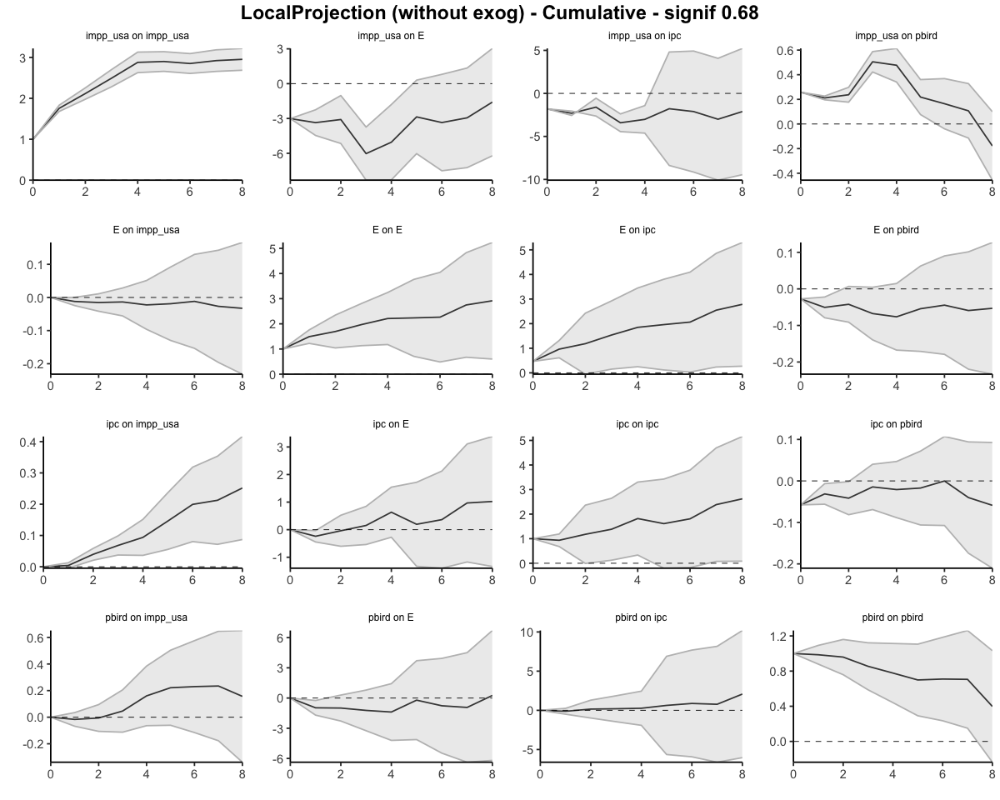

In [66]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.68, cumulative=TRUE)

#### Todas endógenas 2 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4664         0.4664       1.0000
         1              0.9633         0.6461       1.4908
         2              1.1858         0.6994       1.6954
         3              1.5373         0.7801       1.9707
         4              1.8491         0.8362       2.2111
         5              1.9610         0.8768       2.2365
         6              2.0629         0.9105       2.2656
         7              2.5477         0.9265       2.7499
         8              2.7855         0.9549       2.9169
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4664             0.4664
                  0.4968             0.1797
                  0.2225             0.0533
                  0.3516             0.0807
                  0.3117             0.0561
       

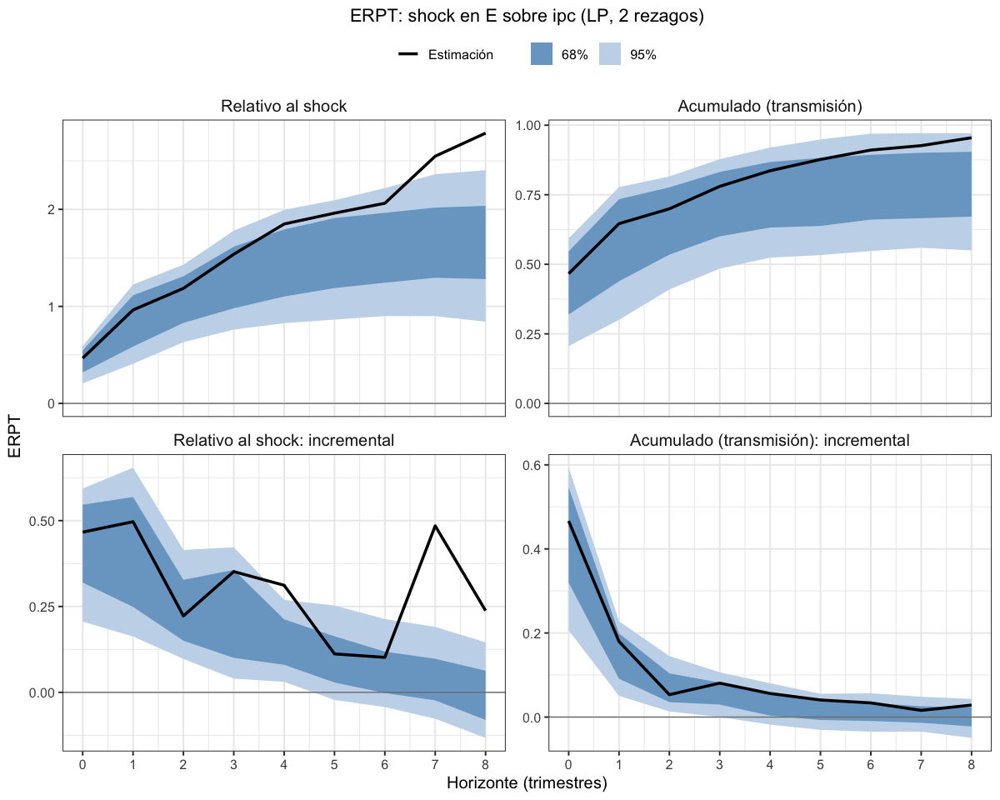

In [88]:
# Todas endógenas, 2 rezagos
lp_erpt <- erpt_lp(df_ERPT_Arg_1950_90, endog = c("impp_usa", "E", "ipc", "pbird"),
                   fixed_lags = 2, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt, archivo = "erpt_lp_impp_usa90_endog_p2")

### impp_usa 1950 a 1990 - 1 exógena y el resto endógenas - Selected orders: 1, 2 y 3 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.0000000
20,ipc,E,1,0.06271556,-0.04128120,0.1667123
21,ipc,E,2,0.44421556,0.10481534,0.7836158
22,ipc,E,3,0.29292899,-0.02830711,0.6141651
23,ipc,E,4,0.44286205,0.19136364,0.6943605
24,ipc,E,5,0.15885240,-8.74423887,9.0619437
25,ipc,E,6,0.62663377,0.35766791,0.8955996
26,ipc,E,7,0.45489005,0.14472685,0.7650532
27,ipc,E,8,0.32312106,0.06417584,0.5820663


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.00000000,0.0000000
38,pbird,E,1,-0.4224439,-1.27941026,0.4345225
39,pbird,E,2,0.3351400,-0.09956766,0.7698476
40,pbird,E,3,-0.2131322,-0.87137607,0.4451116
41,pbird,E,4,-0.2494332,-1.03322073,0.5343543
42,pbird,E,5,1.3668035,-2.40361076,5.1372178
43,pbird,E,6,-0.5789310,-1.30428227,0.1464203
44,pbird,E,7,-0.2214880,-0.92680477,0.4838288
45,pbird,E,8,1.1990557,0.20434551,2.1937659


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5242966,0.52429657,0.5242966
2,E,ipc,1,0.5409673,0.20471834,0.8772164
3,E,ipc,2,0.3240791,-0.03767719,0.6858354
4,E,ipc,3,0.4211997,0.15483894,0.6875604
5,E,ipc,4,0.3281119,0.09436305,0.5618608
6,E,ipc,5,0.2497825,-2.63532285,3.1348879
7,E,ipc,6,0.2916545,0.01681754,0.5664914
8,E,ipc,7,0.4770853,0.21800132,0.7361693
9,E,ipc,8,0.3555681,0.12078374,0.5903524


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.00000000,0.0000000
47,pbird,ipc,1,0.45545181,0.02939128,0.8815123
48,pbird,ipc,2,0.77471591,0.39424558,1.1551862
49,pbird,ipc,3,0.19020805,-0.25381506,0.6342312
50,pbird,ipc,4,0.09787129,-0.45338828,0.6491309
51,pbird,ipc,5,0.47635316,-0.02378070,0.9764870
52,pbird,ipc,6,0.27833954,-0.16790945,0.7245885
53,pbird,ipc,7,-0.22476954,-0.86208811,0.4125490
54,pbird,ipc,8,1.27671949,0.56651768,1.9869213


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.0320834629,-0.032083463,-0.032083463
11,E,pbird,1,-0.0204186379,-0.044422201,0.003584925
12,E,pbird,2,0.0006705059,-0.030756015,0.032097027
13,E,pbird,3,-0.0241051860,-0.050705568,0.002495196
14,E,pbird,4,-0.0023749386,-0.020817457,0.016067580
15,E,pbird,5,0.0150862725,-0.004668135,0.034840680
16,E,pbird,6,0.0005428061,-0.018522721,0.019608333
17,E,pbird,7,-0.0032471379,-0.028043168,0.021548892
18,E,pbird,8,0.0041864984,-0.016637717,0.025010714


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.05680139,-0.056801389,-0.056801389
29,ipc,pbird,1,0.01973535,0.003698416,0.035772276
30,ipc,pbird,2,-0.02616965,-0.048175388,-0.004163913
31,ipc,pbird,3,0.03210093,0.013860337,0.050341518
32,ipc,pbird,4,0.01043848,-0.004230684,0.025107635
33,ipc,pbird,5,-0.01956361,-0.031101520,-0.008025701
34,ipc,pbird,6,-0.01636748,-0.033930236,0.001195273
35,ipc,pbird,7,-0.03349228,-0.055265280,-0.011719274
36,ipc,pbird,8,-0.02121009,-0.038483030,-0.003937144


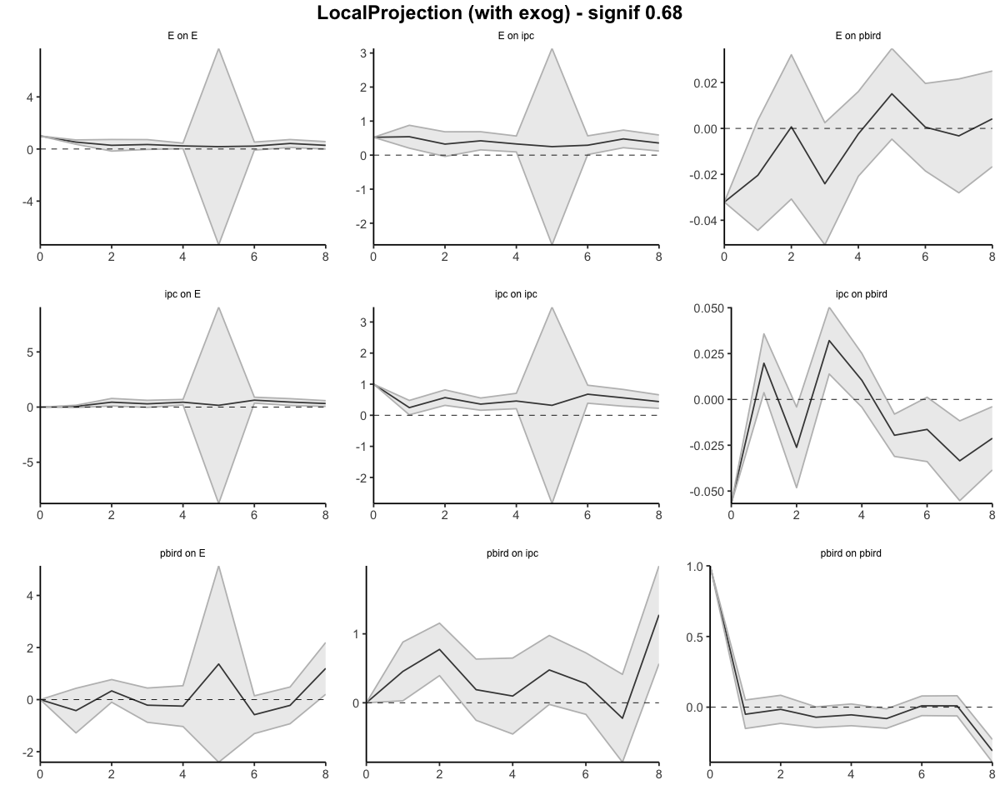

In [69]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.0000000
20,ipc,E,1,0.06271556,-0.04128120,0.1667123
21,ipc,E,2,0.50693112,0.06353414,0.9503281
22,ipc,E,3,0.79986011,0.03522703,1.5644932
23,ipc,E,4,1.24272216,0.22659066,2.2588537
24,ipc,E,5,1.40157456,-8.51764821,11.3207973
25,ipc,E,6,2.02820833,-8.15998030,12.2163970
26,ipc,E,7,2.48309838,-8.01525345,12.9814502
27,ipc,E,8,2.80621944,-7.95107761,13.5635165


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.000000,0.0000000
38,pbird,E,1,-0.42244387,-1.279410,0.4345225
39,pbird,E,2,-0.08730390,-1.378978,1.2043701
40,pbird,E,3,-0.30043612,-2.250354,1.6494818
41,pbird,E,4,-0.54986935,-3.283575,2.1838360
42,pbird,E,5,0.81693416,-5.687185,7.3210538
43,pbird,E,6,0.23800316,-6.991468,7.4674741
44,pbird,E,7,0.01651517,-7.918273,7.9513029
45,pbird,E,8,1.21557086,-7.713927,10.1450687


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5242966,0.5242966,0.5242966
2,E,ipc,1,1.0652639,0.7290149,1.4015129
3,E,ipc,2,1.3893430,0.6913377,2.0873483
4,E,ipc,3,1.8105427,0.8461767,2.7749087
5,E,ipc,4,2.1386546,0.9405397,3.3367695
6,E,ipc,5,2.3884372,-1.6947831,6.4716574
7,E,ipc,6,2.6800916,-1.6779656,7.0381488
8,E,ipc,7,3.1571769,-1.4599643,7.7743181
9,E,ipc,8,3.5127450,-1.3391805,8.3646705


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.00000000,0.0000000
47,pbird,ipc,1,0.4554518,0.02939128,0.8815123
48,pbird,ipc,2,1.2301677,0.42363685,2.0366986
49,pbird,ipc,3,1.4203758,0.16982179,2.6709297
50,pbird,ipc,4,1.5182470,-0.28356649,3.3200606
51,pbird,ipc,5,1.9946002,-0.30734719,4.2965476
52,pbird,ipc,6,2.2729398,-0.47525664,5.0211362
53,pbird,ipc,7,2.0481702,-1.33734475,5.4336852
54,pbird,ipc,8,3.3248897,-0.77082708,7.4206065


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.03208346,-0.03208346,-0.032083463
11,E,pbird,1,-0.05250210,-0.07650566,-0.028498537
12,E,pbird,2,-0.05183159,-0.10726168,0.003598489
13,E,pbird,3,-0.07593678,-0.15796725,0.006093685
14,E,pbird,4,-0.07831172,-0.17878470,0.022161265
15,E,pbird,5,-0.06322545,-0.18345284,0.057001945
16,E,pbird,6,-0.06268264,-0.20197556,0.076610278
17,E,pbird,7,-0.06592978,-0.23001873,0.098159170
18,E,pbird,8,-0.06174328,-0.24665644,0.123169884


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.05680139,-0.05680139,-0.05680139
29,ipc,pbird,1,-0.03706604,-0.05310297,-0.02102911
30,ipc,pbird,2,-0.06323569,-0.10127836,-0.02519303
31,ipc,pbird,3,-0.03113477,-0.08741802,0.02514849
32,ipc,pbird,4,-0.02069629,-0.09164871,0.05025613
33,ipc,pbird,5,-0.04025990,-0.12275023,0.04223042
34,ipc,pbird,6,-0.05662738,-0.15668046,0.04342570
35,ipc,pbird,7,-0.09011966,-0.21194575,0.03170642
36,ipc,pbird,8,-0.11132975,-0.25042878,0.02776928


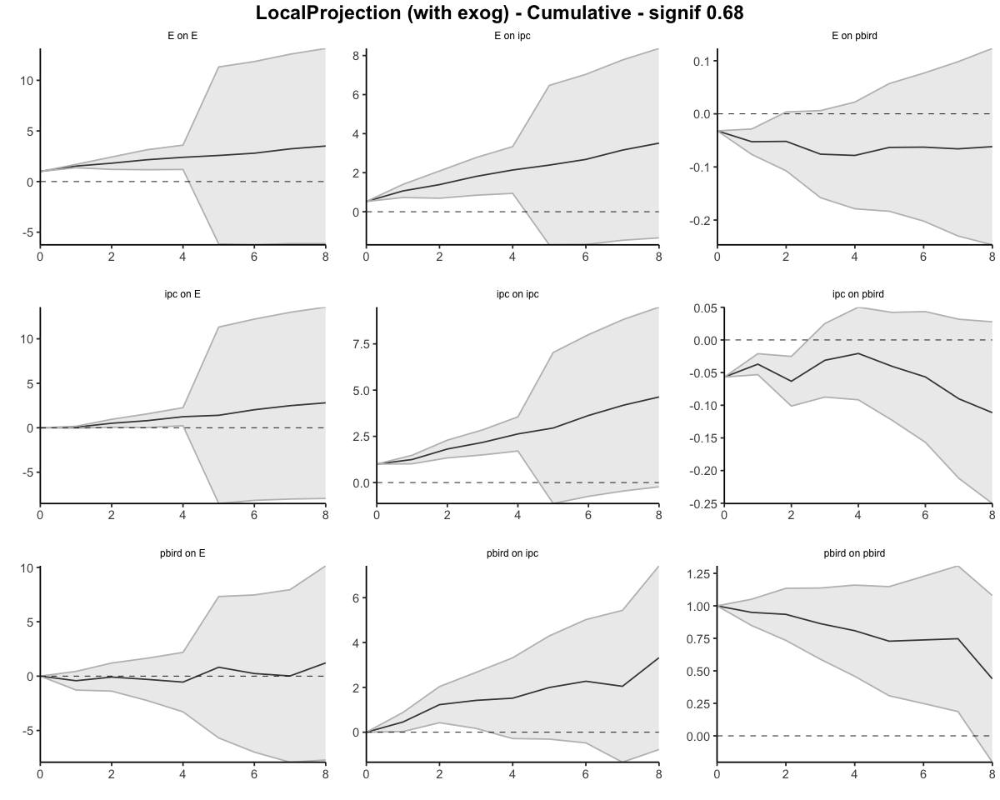

In [68]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 1, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 1 lag

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.5243         0.5243       1.0000
         1              1.0653         0.6963       1.5299
         2              1.3893         0.7656       1.8147
         3              1.8105         0.8385       2.1592
         4              2.1387         0.8924       2.3966
         5              2.3884         0.9260       2.5793
         6              2.6801         0.9562       2.8028
         7              3.1572         0.9780       3.2280
         8              3.5127         1.0006       3.5107
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.5243             0.5243
                  0.5410             0.1720
                  0.3241             0.0693
                  0.4212             0.0729
                  0.3281       

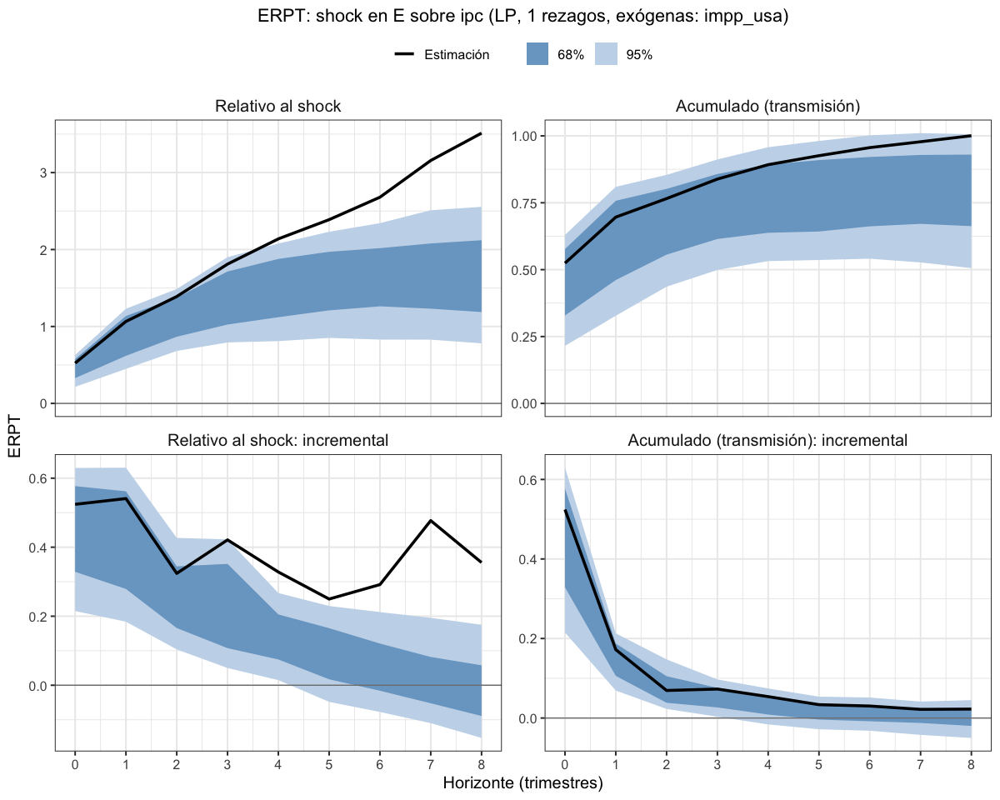

In [89]:
# impp_usa exógena, 1 rezago
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_90, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 1, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa90_exog_p1")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.00000000
20,ipc,E,1,-0.23699074,-0.44232644,-0.03165503
21,ipc,E,2,0.19967569,-0.15537020,0.55472157
22,ipc,E,3,0.19303477,0.06561029,0.32045925
23,ipc,E,4,0.48074912,0.26604499,0.69545325
24,ipc,E,5,-0.44105242,-1.05440576,0.17230093
25,ipc,E,6,0.17044993,-0.06544978,0.40634965
26,ipc,E,7,0.60431569,0.22671664,0.98191474
27,ipc,E,8,0.05165465,-0.16382270,0.26713200


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.00000000,0.0000000,0.0000000
38,pbird,E,1,-0.97082848,-1.6987705,-0.2428865
39,pbird,E,2,-0.02390445,-0.5849694,0.5371605
40,pbird,E,3,-0.23365013,-0.9626457,0.4953455
41,pbird,E,4,-0.16158758,-0.9593262,0.6361510
42,pbird,E,5,1.18028779,0.0796611,2.2809145
43,pbird,E,6,-0.55906589,-1.3494926,0.2313608
44,pbird,E,7,-0.16446384,-0.8984447,0.5695170
45,pbird,E,8,1.18984279,0.1799597,2.1997259


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4739453,0.47394532,0.4739453
2,E,ipc,1,0.4966707,0.14307504,0.8502664
3,E,ipc,2,0.2235155,-0.66833291,1.1153639
4,E,ipc,3,0.3530118,0.20681197,0.4992117
5,E,ipc,4,0.3148023,0.10155780,0.5280468
6,E,ipc,5,0.1093415,-0.12494235,0.3436254
7,E,ipc,6,0.1026280,-0.08418261,0.2894386
8,E,ipc,7,0.4894022,0.20836863,0.7704357
9,E,ipc,8,0.2358482,0.03223554,0.4394608


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,-0.11908810,-0.4934844,0.2553082
48,pbird,ipc,2,0.27718591,-0.4891793,1.0435512
49,pbird,ipc,3,0.04322337,-0.4723322,0.5587789
50,pbird,ipc,4,0.06415558,-0.4580768,0.5863880
51,pbird,ipc,5,0.36329347,-3.7259044,4.4524913
52,pbird,ipc,6,0.24939982,-0.2921257,0.7909254
53,pbird,ipc,7,-0.10550529,-0.6897900,0.4787794
54,pbird,ipc,8,1.30286780,0.5846259,2.0211097


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.030619486,-0.030619486,-0.030619486
11,E,pbird,1,-0.023060966,-0.051315702,0.005193771
12,E,pbird,2,0.008445844,-0.011917895,0.028809584
13,E,pbird,3,-0.024809600,-0.047822051,-0.001797148
14,E,pbird,4,-0.008701857,-0.027714431,0.010310716
15,E,pbird,5,0.022383490,-0.003223575,0.047990555
16,E,pbird,6,0.009903330,-0.007888767,0.027695427
17,E,pbird,7,-0.015038531,-0.040915972,0.010838909
18,E,pbird,8,0.006798966,-0.012737501,0.026335433


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.059815162,-0.059815162,-0.0598151616
29,ipc,pbird,1,0.026449635,0.001881602,0.0510176689
30,ipc,pbird,2,-0.010213949,-0.025051209,0.0046233120
31,ipc,pbird,3,0.027374245,0.012740185,0.0420083053
32,ipc,pbird,4,-0.006223779,-0.019168185,0.0067206274
33,ipc,pbird,5,0.003838434,-0.017391885,0.0250687533
34,ipc,pbird,6,0.016973420,-0.001135901,0.0350827405
35,ipc,pbird,7,-0.039942386,-0.066628840,-0.0132559321
36,ipc,pbird,8,-0.018108412,-0.035299999,-0.0009168236


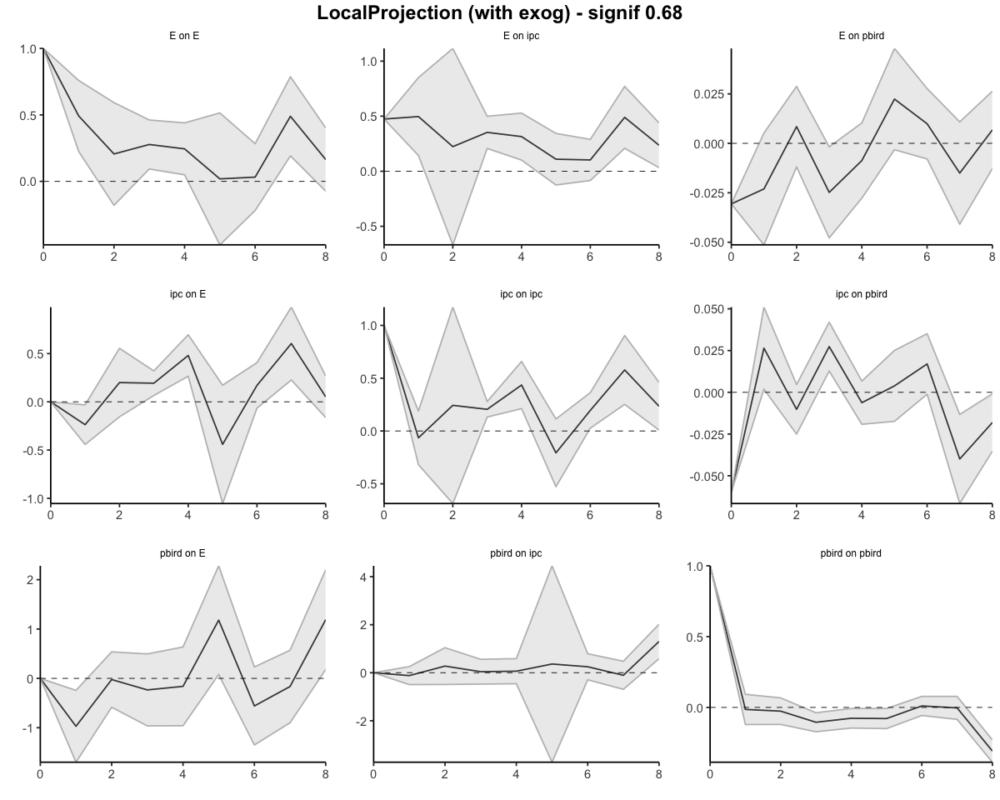

In [71]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.0000000,0.00000000
20,ipc,E,1,-0.23699074,-0.4423264,-0.03165503
21,ipc,E,2,-0.03731505,-0.5976966,0.52306654
22,ipc,E,3,0.15571972,-0.5320864,0.84352579
23,ipc,E,4,0.63646884,-0.2660414,1.53897904
24,ipc,E,5,0.19541642,-1.3204471,1.71127997
25,ipc,E,6,0.36586635,-1.3858969,2.11762961
26,ipc,E,7,0.97018204,-1.1591803,3.09954435
27,ipc,E,8,1.02183669,-1.3230030,3.36667635


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.0000000
38,pbird,E,1,-0.9708285,-1.698770,-0.2428865
39,pbird,E,2,-0.9947329,-2.283740,0.2942740
40,pbird,E,3,-1.2283831,-3.246386,0.7896195
41,pbird,E,4,-1.3899706,-4.205712,1.4257705
42,pbird,E,5,-0.2096828,-4.126051,3.7066850
43,pbird,E,6,-0.7687487,-5.475543,3.9380458
44,pbird,E,7,-0.9332126,-6.373988,4.5075627
45,pbird,E,8,0.2566302,-6.194028,6.7072886


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4739453,0.47394532,0.4739453
2,E,ipc,1,0.9706160,0.61702036,1.3242117
3,E,ipc,2,1.1941315,-0.05131255,2.4395756
4,E,ipc,3,1.5471434,0.15549941,2.9387874
5,E,ipc,4,1.8619457,0.25705721,3.4668341
6,E,ipc,5,1.9712872,0.13211487,3.8104595
7,E,ipc,6,2.0739152,0.04793226,4.0998981
8,E,ipc,7,2.5633173,0.25630089,4.8703338
9,E,ipc,8,2.7991655,0.28853642,5.3097946


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.0000000,0.0000000,0.0000000
47,pbird,ipc,1,-0.1190881,-0.4934844,0.2553082
48,pbird,ipc,2,0.1580978,-0.9826638,1.2988594
49,pbird,ipc,3,0.2013212,-1.4549959,1.8576383
50,pbird,ipc,4,0.2654768,-1.9130727,2.4440262
51,pbird,ipc,5,0.6287702,-5.6389771,6.8965176
52,pbird,ipc,6,0.8781700,-5.9311028,7.6874429
53,pbird,ipc,7,0.7726648,-6.6208928,8.1662223
54,pbird,ipc,8,2.0755326,-6.0362668,10.1873320


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.03061949,-0.03061949,-0.030619486
11,E,pbird,1,-0.05368045,-0.08193519,-0.025425715
12,E,pbird,2,-0.04523461,-0.09385308,0.003383869
13,E,pbird,3,-0.07004421,-0.14167513,0.001586721
14,E,pbird,4,-0.07874606,-0.16938957,0.011897437
15,E,pbird,5,-0.05636257,-0.17261314,0.059887992
16,E,pbird,6,-0.04645924,-0.18050191,0.087583419
17,E,pbird,7,-0.06149778,-0.22141788,0.098422328
18,E,pbird,8,-0.05469881,-0.23415538,0.124757761


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.059815162,-0.05981516,-0.059815162
29,ipc,pbird,1,-0.033365526,-0.05793356,-0.008797493
30,ipc,pbird,2,-0.043579475,-0.08298477,-0.004174181
31,ipc,pbird,3,-0.016205230,-0.07024458,0.037834125
32,ipc,pbird,4,-0.022429008,-0.08941277,0.044554752
33,ipc,pbird,5,-0.018590574,-0.10680465,0.069623505
34,ipc,pbird,6,-0.001617155,-0.10794056,0.104706246
35,ipc,pbird,7,-0.041559541,-0.17456940,0.091450314
36,ipc,pbird,8,-0.059667952,-0.20986939,0.090533490


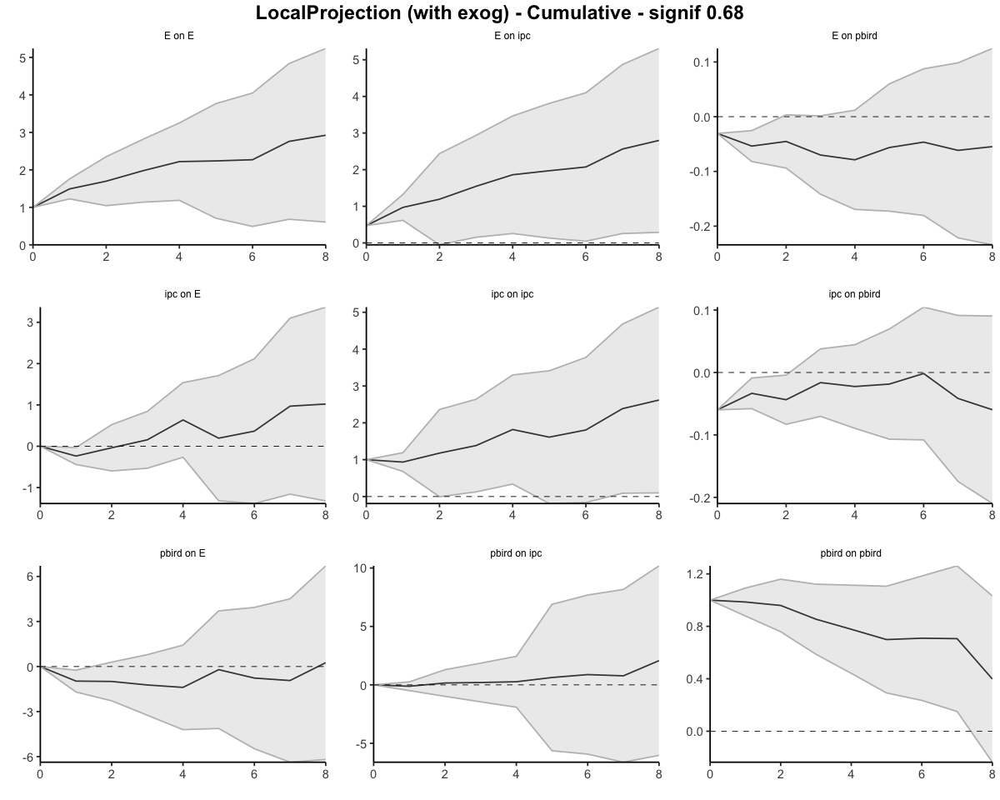

In [70]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 2 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4739         0.4739       1.0000
         1              0.9706         0.6506       1.4918
         2              1.1941         0.7033       1.6980
         3              1.5471         0.7832       1.9754
         4              1.8619         0.8387       2.2199
         5              1.9713         0.8806       2.2386
         6              2.0739         0.9134       2.2705
         7              2.5633         0.9288       2.7598
         8              2.7992         0.9574       2.9239
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4739             0.4739
                  0.4967             0.1767
                  0.2235             0.0526
                  0.3530             0.0800
                  0.3148       

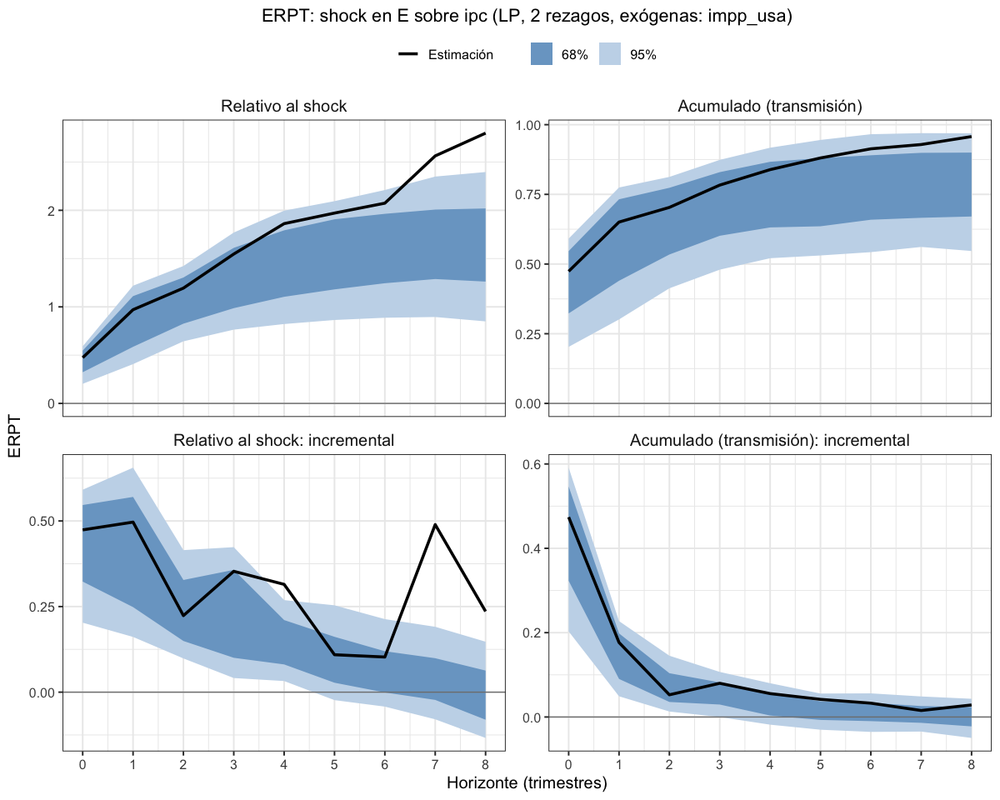

In [90]:
# impp_usa exógena, 2 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_90, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 2, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa90_exog_p2")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"E, ipc, pbird",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.0000000,0.0000000
20,ipc,E,1,-0.26213280,-0.4577054,-0.0665602
21,ipc,E,2,0.16487641,0.0289938,0.3007590
22,ipc,E,3,0.28038568,0.1629902,0.3977812
23,ipc,E,4,0.51352523,0.2719434,0.7551070
24,ipc,E,5,-0.42612381,-0.5891486,-0.2630990
25,ipc,E,6,0.19152805,-0.1004286,0.4834847
26,ipc,E,7,0.55833124,0.1532042,0.9634583
27,ipc,E,8,-0.04239454,-0.2927168,0.2079278


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.00000000,0.0000000
38,pbird,E,1,-1.0450988,-1.72520883,-0.3649887
39,pbird,E,2,-0.1242597,-0.65232794,0.4038086
40,pbird,E,3,-0.2685110,-0.95457760,0.4175557
41,pbird,E,4,-0.1608358,-0.96301902,0.6413475
42,pbird,E,5,1.0145888,0.28075495,1.7484227
43,pbird,E,6,-0.5010278,-1.27752226,0.2754666
44,pbird,E,7,-0.1589998,-0.91096871,0.5929692
45,pbird,E,8,1.0227882,0.07939337,1.9661831


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4621301,0.46213010,0.4621301
2,E,ipc,1,0.4728912,0.16291832,0.7828640
3,E,ipc,2,0.2207927,0.04605120,0.3955342
4,E,ipc,3,0.3808628,0.24714765,0.5145780
5,E,ipc,4,0.2950145,0.07709230,0.5129367
6,E,ipc,5,0.1227933,-0.01097706,0.2565637
7,E,ipc,6,0.1155976,-0.10485819,0.3360533
8,E,ipc,7,0.4759418,0.19666953,0.7552140
9,E,ipc,8,0.2106580,-0.00255320,0.4238691


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.0000000
47,pbird,ipc,1,-0.16531751,-0.5404050,0.2097700
48,pbird,ipc,2,0.23682627,-0.1822764,0.6559290
49,pbird,ipc,3,0.03386375,-0.4946503,0.5623778
50,pbird,ipc,4,0.05524510,-0.4779867,0.5884769
51,pbird,ipc,5,0.22935901,-0.5392732,0.9979912
52,pbird,ipc,6,0.24667447,-0.2385665,0.7319154
53,pbird,ipc,7,-0.13046781,-0.7092554,0.4483198
54,pbird,ipc,8,1.19810285,0.5053582,1.8908475


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.029736839,-0.029736839,-0.0297368387
11,E,pbird,1,-0.027152251,-0.050544990,-0.0037595117
12,E,pbird,2,0.004057235,-0.011108082,0.0192225526
13,E,pbird,3,-0.026033866,-0.052610377,0.0005426438
14,E,pbird,4,-0.007975464,-0.028523131,0.0125722030
15,E,pbird,5,0.021957960,-0.002135480,0.0460513997
16,E,pbird,6,0.009131427,-0.010005907,0.0282687613
17,E,pbird,7,-0.016313072,-0.039419844,0.0067936996
18,E,pbird,8,0.013263834,-0.006738828,0.0332664953


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.0596892124,-0.059689212,-0.059689212
29,ipc,pbird,1,0.0134865254,-0.006099491,0.033072542
30,ipc,pbird,2,-0.0131696622,-0.019893411,-0.006445913
31,ipc,pbird,3,0.0308672404,0.010319027,0.051415454
32,ipc,pbird,4,-0.0078636315,-0.022136461,0.006409198
33,ipc,pbird,5,-0.0003921883,-0.020697697,0.019913320
34,ipc,pbird,6,0.0131672228,-0.006240229,0.032574675
35,ipc,pbird,7,-0.0476879743,-0.072788844,-0.022587104
36,ipc,pbird,8,-0.0033176213,-0.024064561,0.017429318


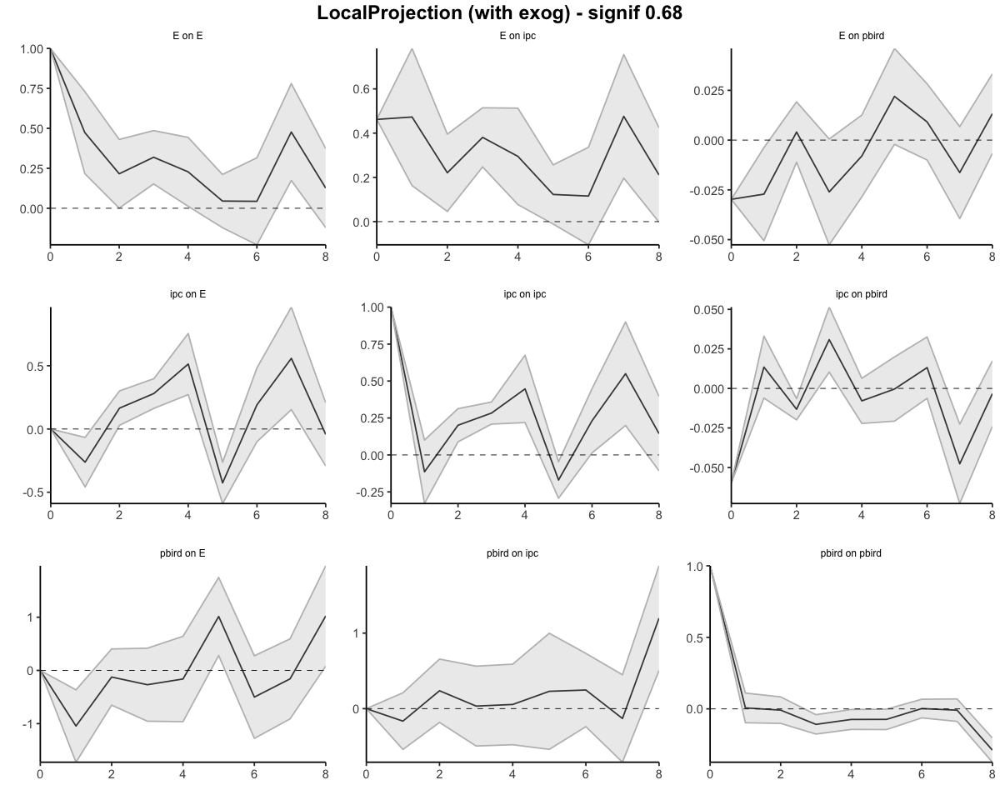

In [73]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,NA,NaN,NA,3,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,163,"E, ipc, pbird",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
19,ipc,E,0,0.00000000,0.00000000,0.0000000
20,ipc,E,1,-0.26213280,-0.45770539,-0.0665602
21,ipc,E,2,-0.09725638,-0.42871159,0.2341988
22,ipc,E,3,0.18312930,-0.26572141,0.6319800
23,ipc,E,4,0.69665453,0.00622201,1.3870870
24,ipc,E,5,0.27053072,-0.58292663,1.1239881
25,ipc,E,6,0.46205877,-0.68335526,1.6074728
26,ipc,E,7,1.02039001,-0.53015105,2.5709311
27,ipc,E,8,0.97799548,-0.82286789,2.7788588


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
37,pbird,E,0,0.0000000,0.000000,0.00000000
38,pbird,E,1,-1.0450988,-1.725209,-0.36498867
39,pbird,E,2,-1.1693584,-2.377537,0.03881997
40,pbird,E,3,-1.4378694,-3.332114,0.45637563
41,pbird,E,4,-1.5987051,-4.295133,1.09772312
42,pbird,E,5,-0.5841163,-4.014378,2.84614583
43,pbird,E,6,-1.0851441,-5.291901,3.12161241
44,pbird,E,7,-1.2441439,-6.202869,3.71458162
45,pbird,E,8,-0.2213556,-6.123476,5.68076475


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4621301,0.4621301,0.4621301
2,E,ipc,1,0.9350213,0.6250484,1.2449941
3,E,ipc,2,1.1558140,0.6710996,1.6405283
4,E,ipc,3,1.5366768,0.9182473,2.1551063
5,E,ipc,4,1.8316913,0.9953396,2.6680430
6,E,ipc,5,1.9544846,0.9843625,2.9246067
7,E,ipc,6,2.0700822,0.8795043,3.2606600
8,E,ipc,7,2.5460240,1.0761739,4.0158741
9,E,ipc,8,2.7566819,1.0736207,4.4397432


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
46,pbird,ipc,0,0.00000000,0.0000000,0.000000
47,pbird,ipc,1,-0.16531751,-0.5404050,0.209770
48,pbird,ipc,2,0.07150877,-0.7226814,0.865699
49,pbird,ipc,3,0.10537251,-1.2173317,1.428077
50,pbird,ipc,4,0.16061762,-1.6953183,2.016554
51,pbird,ipc,5,0.38997662,-2.2345915,3.014545
52,pbird,ipc,6,0.63665109,-2.4731580,3.746460
53,pbird,ipc,7,0.50618328,-3.1824134,4.194780
54,pbird,ipc,8,1.70428613,-2.6770552,6.085627


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
10,E,pbird,0,-0.02973684,-0.02973684,-0.029736839
11,E,pbird,1,-0.05688909,-0.08028183,-0.033496350
12,E,pbird,2,-0.05283185,-0.09138991,-0.014273798
13,E,pbird,3,-0.07886572,-0.14400029,-0.013731154
14,E,pbird,4,-0.08684118,-0.17252342,-0.001158951
15,E,pbird,5,-0.06488322,-0.17465890,0.044892449
16,E,pbird,6,-0.05575180,-0.18466481,0.073161210
17,E,pbird,7,-0.07206487,-0.22408465,0.079954910
18,E,pbird,8,-0.05880104,-0.23082348,0.113221405


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
28,ipc,pbird,0,-0.05968921,-0.05968921,-0.05968921
29,ipc,pbird,1,-0.04620269,-0.06578870,-0.02661667
30,ipc,pbird,2,-0.05937235,-0.08568211,-0.03306258
31,ipc,pbird,3,-0.02850511,-0.07536309,0.01835287
32,ipc,pbird,4,-0.03636874,-0.09749955,0.02476207
33,ipc,pbird,5,-0.03676093,-0.11819724,0.04467539
34,ipc,pbird,6,-0.02359371,-0.12443747,0.07725006
35,ipc,pbird,7,-0.07128168,-0.19722632,0.05466296
36,ipc,pbird,8,-0.07459930,-0.22129088,0.07209228


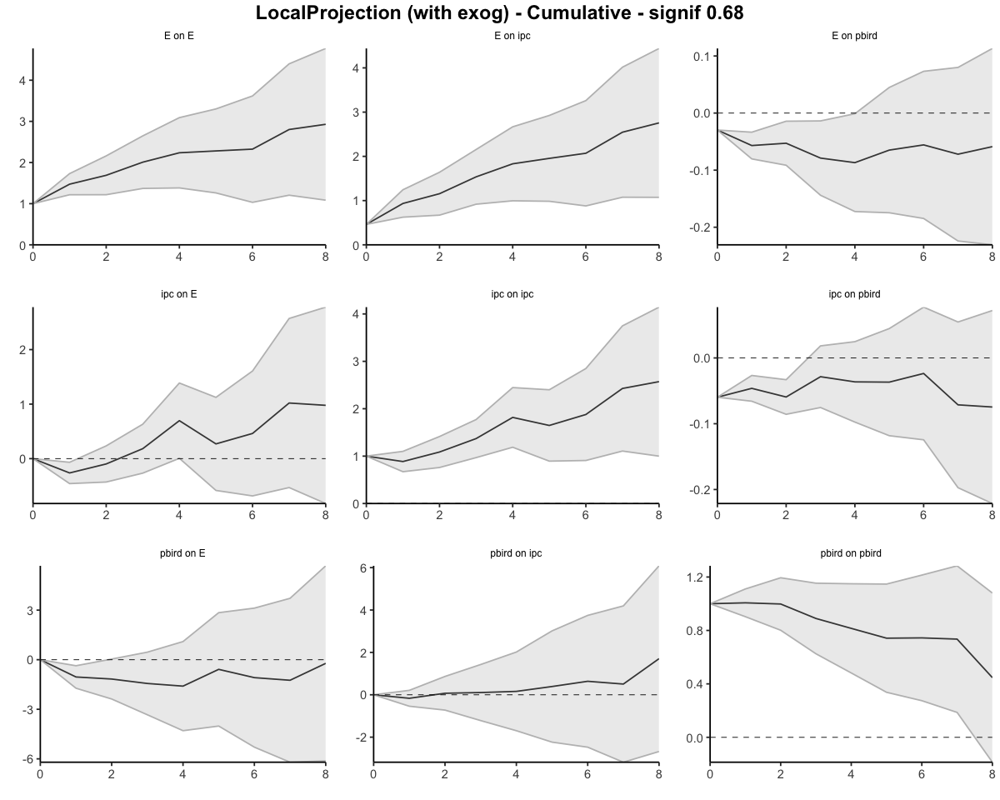

In [72]:
res <- run_lp_model(df_ERPT_Arg_1950_90, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 3, horizons=8, signif = 0.68, cumulative = TRUE)

#### impp_usa exógena y el resto endógenas 3 lags

Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, exógenas: impp_usa )
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4621         0.4621       1.0000
         1              0.9350         0.6345       1.4736
         2              1.1558         0.6842       1.6894
         3              1.5367         0.7651       2.0086
         4              1.8317         0.8189       2.2367
         5              1.9545         0.8566       2.2817
         6              2.0701         0.8903       2.3252
         7              2.5460         0.9086       2.8021
         8              2.7567         0.9413       2.9285
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4621             0.4621
                  0.4729             0.1724
                  0.2208             0.0496
                  0.3809             0.0809
                  0.2950       

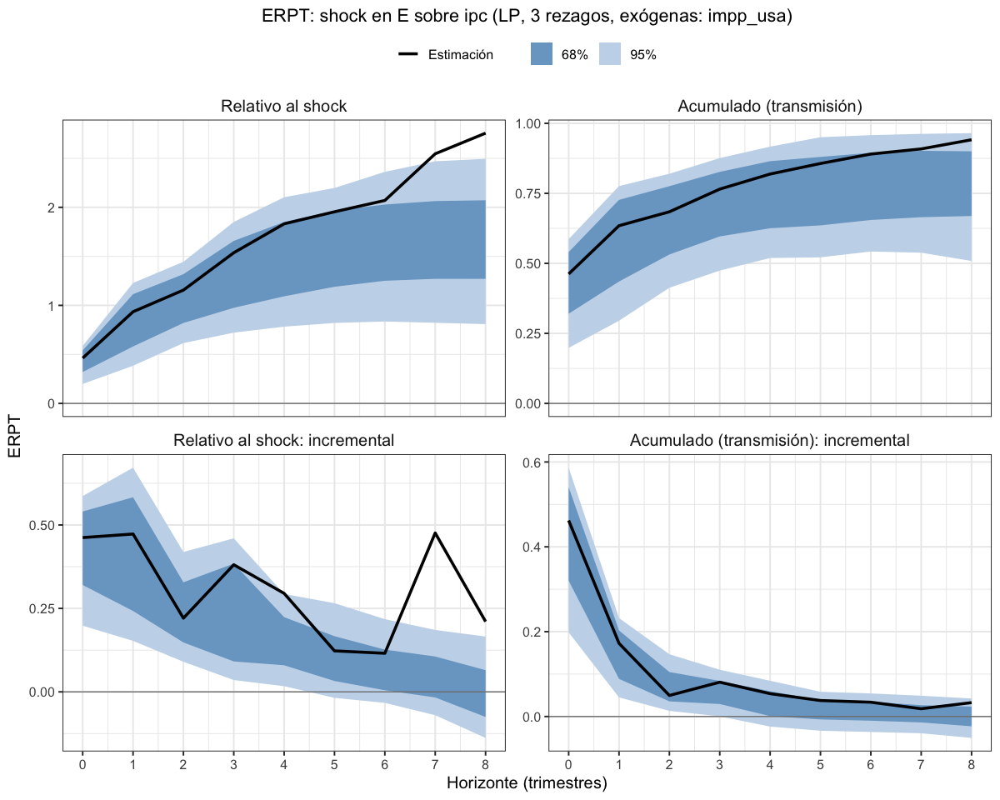

In [91]:
# impp_usa exógena, 3 rezagos
lp_erpt_x <- erpt_lp(df_ERPT_Arg_1950_90, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                     fixed_lags = 3, horizons = 8, reps = 500)
graficar_erpt_lp(lp_erpt_x, archivo = "erpt_lp_impp_usa90_exog_p3")